# DIMER Notebook: Comparing Image Matching Models

**Profile:** `TASK-INFERENCE`  
**Mode:** `WORKSHOP`  
**Notebook specification:** `2.5`  
**Status:** Candidate  
**Recommended runtime:** NVIDIA Tesla T4 or equivalent

This standalone notebook compares two live DIMER image-matching capabilities under **one shared geometric experiment**:

- **LightGlue + ALIKED** — sparse local-feature matching
- **XoFTR** — detector-free semi-dense matching

The central question is:

> Given exactly the same pair of images and the same known geometric transformation, how do **LightGlue + ALIKED and XoFTR, as configured by `vismatch 1.3.2`**, differ in correspondence accuracy, match density, geometric robustness, and compute cost?

### Scope of the comparison

This compares **two configured systems, not two matcher families**. Each family (sparse, detector-free) is represented by one model, and each model is compared as a whole pipeline: architecture, training data and purpose, and the backend's settings all differ at once. Both run at the `vismatch 1.3.2` backend default settings (printed in section 12), and neither was tuned for this RGB-to-RGB task. XoFTR was designed for cross-modal matching between visible and thermal-infrared images (its paper, arXiv 2404.09692, presents it as a visible–thermal matcher); LightGlue + ALIKED were trained on ordinary visible-light photographs. The experiment therefore supports statements of the form "this system beats the model-neutral baselines" or "this system beats the other named system under this protocol". It does not show that detector-free matchers in general are denser, less precise or less rotation-robust than sparse ones: another model of either family, or other settings, could order the results differently.

### Controlled comparison

Both models receive the same source photographs, deterministic image split, rendered image-pair bytes, reference homography, three difficulty tiers, geometric thresholds, RANSAC-DLT evaluator, and model-neutral baselines. Model-native preprocessing stays inside the matching backend.

### Standalone contract

The canonical path does **not** clone a repository, fetch DIMER source, call a DIMER worker/API, require credentials, or require an upload. It carries the exact 360-photo corpus manifest inline, verifies every built-in photograph by byte size + SHA-256, creates all reference geometry locally, and evaluates both matchers locally.

### Candidate execution backend

The comparative frontend is pinned to **`vismatch==1.3.2`**, which exposes both `aliked-lightglue` and `xoftr` through one common API. The notebook records the intended live-DIMER model identities and DIMER checkpoint digests alongside the actual backend. The runner intercepts the backend checkpoint acquisitions, fetches only the declared immutable assets and checks byte size + SHA-256 before loading. LightGlue/ALIKED use restricted `weights_only=True` loading of their pinned upstream files; XoFTR uses the pinned safetensors revision. **Real-model behavior and equivalence to the DIMER safetensors carrier remain qualification gates**, not assumptions.

All measured results are **tutorial/sample-sanity evidence**, not benchmark or production-fitness claims.

**AI Use Disclosure:** Generative AI assisted with this notebook’s code and instructional content under maintainer direction. The maintainer remains responsible for review, validation, and release decisions. AI-generated material may contain errors; validation claims are limited to documented runs and configurations. AI use does not imply independent verification, provider endorsement, or release approval.

## How to use this notebook

**Who it is for.** Learners who can run Python cells in Colab/Jupyter and are new to local features, image correspondence, or geometric matching.

**Prerequisites.** Basic Python and NumPy reading; no prior computer-vision training is assumed. Terms are explained where they first matter and collected in the Glossary at the end.

**Runtime.** Select a GPU runtime (Colab **Tesla T4** or equivalent) before **Run all**. Once it is selected nothing else needs your attention. The notebook downloads 360 photographs (37.4 MiB), three checkpoints (47.6 MB + 2.7 MB for LightGlue + ALIKED, 44.4 MB for XoFTR) and builds a separate, hash-locked CPython 3.12.12 environment with `torch 2.14.0`, `torchvision 0.29.0` and `vismatch 1.3.2` (Linux x86_64 only: Colab, Kaggle or a Linux Jupyter server; nothing is installed into the kernel, so no restart is needed); that PyTorch install is the largest download (an estimate: several GB with its CUDA libraries). Recorded, not re-run by this revision: the Colab CLI run of this notebook at commit `e2ee0f4` (notebook blob `4991047a0590`, fresh Colab Tesla T4, 2026-10-04; `docs/release-verification.md`) took 896.9 s (about 15 minutes) for all code cells, matching took about 0.168 s per pair for LightGlue + ALIKED and 0.294 s per pair for XoFTR, and peak GPU memory was 1,669 MiB and 2,968 MiB. Later revisions leave the matchers and their inputs unchanged, so expect similar figures; the section 18 table of your own run is the measurement for your runtime. The patch-neighbour baseline runs on the CPU and is the slowest notebook-side step. Without a GPU the matchers fall back to the CPU, the notebook prints a warning after section 12, and the run takes much longer.

### Learning objectives

By the end of this notebook you should be able to:

1. **Explain** what a correspondence is and how a known homography lets you score one exactly (sections 0, 6, 8).
2. **Compare** two configured systems, LightGlue + ALIKED (a sparse matcher) and XoFTR (a detector-free matcher), each at its `vismatch 1.3.2` default settings, with two model-neutral baselines on the same image pairs (sections 9, 12, 14), and say what a comparison of one model per family can and cannot show.
3. **Interpret** precision, match density, inliers and homography accuracy together, and explain why more matches is not automatically better (sections 8, 18).
4. **Diagnose** how each matcher degrades from easy to rotation-stress pairs and find pairs where the two disagree (sections 15–17).
5. **Predict and test** how a stricter correctness tolerance changes each matcher's precision (Try it yourself).
6. **Write** an evidence-based conclusion with its limits, and **apply** the same experiment to your own photographs (section 20, BYOD).

**How to run it.**
1. Select the documented runtime/accelerator.
2. Choose **Run all** for the canonical path; the defaults are the reference settings.
3. Read the explanation around each learning stage while the cells execute.
4. Cells marked **Infrastructure** handle setup, model acquisition, provenance, or orchestration. You may run those cells without understanding their implementation.

### Task at a glance

`image pair → model correspondences → geometric evaluation → match-quality and runtime comparison`

### Roadmap

1. Sections 0–7: see what a matcher returns, load and verify the 360 photographs, split them by photo, and render validation and test pairs with exact reference geometry.
2. Sections 8–9: learn the metrics, then score two model-neutral baselines (identity guess, patch neighbour).
3. Sections 10–13: build the isolated matcher environment, run both matchers on the validation pairs, and freeze the experiment.
4. Sections 14–18: run the frozen experiment once on the test pairs, then read accuracy, density, robustness by tier, pair-level disagreements and runtime.
5. Sections 19–24: matching without ground truth, BYOD, limitations, exercises and the report bundle.
6. After the default run: the optional **Try it yourself** activity, the self-check and your written conclusion.

### What successful execution looks like

The last code cell prints a completion table. Under `outputs/` you should then have `test/aggregate_metrics.csv` and `test/per_tier_metrics.csv` (baselines and both matchers), `test/per_pair_metrics.csv`, `test/difficulty_degradation.csv`, `test/disagreements.csv`, `test/runtime.csv`, the figures in `figures/`, `frozen/frozen_experiment.json` and `provenance/experiment_manifest.json`, plus the report ZIP `outputs_DIMER_Image_Matching_Workshop_Report.zip` next to the folder. Exact numbers can vary slightly between supported runtimes; interpret the pattern and the metric definitions in section 8 rather than treating one number as universal.


## 0. What image matching produces

Image matching returns geometric correspondences rather than labels:

\[
(x_0,y_0)\leftrightarrow(x_1,y_1)
\]

These can support registration, stitching, localization, structure from motion, pose estimation, and other geometric vision tasks.

This notebook uses synthetic projective warps because each pair then has an exact reference homography. A **homography** is a 3×3 matrix that maps every point of one image plane to the other (rotation, scale, shear and perspective together), so for each point in image 0 it says exactly where that point must appear in image 1.

Later the notebook also *estimates* a homography from a matcher's correspondences: **DLT** (Direct Linear Transform) fits a homography to four or more correspondences, and **RANSAC** repeatedly fits DLT to random sets of four matches and keeps the estimate that the most matches agree with, so a minority of wrong matches usually does not spoil it (with many wrong matches and a fixed sampling budget it can; section 8). The RANSAC-DLT estimate is an **evaluation procedure**, not a raw model output: the matchers return only correspondences.

## 1. Notebook controls

Leave every control at its default for the canonical **Run all**.

- `USE_BYOD` / `BYOD_PATH` (optional, section 20): use your own photographs instead of the built-in corpus. Accepted input: a folder or a `.zip` of **4–360 JPEG/PNG photographs**, every side **16–4096 pixels**, no two images with the same decoded pixels; a ZIP may hold at most 1000 members and 2 GiB expanded and may not contain absolute paths, `..`, backslashes, drive letters, duplicate names or symlinks. In Colab you can leave `BYOD_PATH` empty to get an upload dialog for one `.zip`. Nothing is trained, so every accepted photo is used: about 40% become validation pairs and 60% test pairs. If any file breaks a rule, one message lists every refused file and nothing is written under `outputs/`. Your photos stay inside this notebook runtime (details in section 20).
- `RUN_IDENTITY_BASELINE` / `RUN_PATCH_BASELINE`: keep both on for the reference comparison; turning one off only removes that baseline row.
- `RUN_TOLERANCE_ACTIVITY` / `ACTIVITY_STRICT_TOLERANCE_PX` (optional): the **Try it yourself** activity near the end. It is off by default, loads no model and writes no files; its instructions also show how to switch it on after a completed run.

In [ ]:
# @title Notebook controls
USE_BYOD = False          # @param {type:"boolean"}
BYOD_PATH = ""            # @param {type:"string"}
OUTPUT_DIR = "outputs"    # @param {type:"string"}

RUN_IDENTITY_BASELINE = True  # @param {type:"boolean"}
RUN_PATCH_BASELINE = True     # @param {type:"boolean"}
RUN_TOLERANCE_ACTIVITY = False  # @param {type:"boolean"}
ACTIVITY_STRICT_TOLERANCE_PX = 1.0  # @param {type:"number"}

WORKING_LONG_SIDE = 640
SPLIT_SEED = 42
RANSAC_SEED = 0
RANSAC_ITERATIONS = 500
RANSAC_INLIER_PX = 3.0
MODEL_KEYS = ["lightglue", "xoftr"]

from pathlib import Path
OUTPUT_ROOT = Path(OUTPUT_DIR)
WORK_ROOT = Path("work")
SHARED_WORK_ROOT = WORK_ROOT  # the matcher environment is shared by the default run and every BYOD run
if not 0 < float(ACTIVITY_STRICT_TOLERANCE_PX) < 3:
    raise ValueError(f"ACTIVITY_STRICT_TOLERANCE_PX must be greater than 0 and smaller than 3 px (the default tolerance); got {ACTIVITY_STRICT_TOLERANCE_PX}")
def output_dirs(root):
    return [root / "data", root / "validation", root / "frozen", root / "test",
            root / "test" / "matches" / "lightglue", root / "test" / "matches" / "xoftr",
            root / "figures", root / "future", root / "provenance"]
if USE_BYOD:
    import tempfile
    BYOD_PARENT=OUTPUT_ROOT/"byod"
    byod_work=WORK_ROOT/"byod"
    byod_work.mkdir(parents=True,exist_ok=True)
    WORK_ROOT=Path(tempfile.mkdtemp(prefix="run-",dir=byod_work))
    # The BYOD output folder OUTPUT_DIR/byod/run-* is created in section 4, only after every photograph has
    # been accepted, so a refused input leaves no empty run folder that could be read as a result.
    OUTPUT_ROOT=BYOD_PARENT/"pending-validation"
work_dirs=[WORK_ROOT / "photos", WORK_ROOT / "pairs" / "validation", WORK_ROOT / "pairs" / "test",
           WORK_ROOT / "envs", WORK_ROOT / "runners"]
for path in (work_dirs if USE_BYOD else output_dirs(OUTPUT_ROOT) + work_dirs):
    path.mkdir(parents=True, exist_ok=True)

print({
    "models": MODEL_KEYS,
    "working_long_side": WORKING_LONG_SIDE,
    "split_seed": SPLIT_SEED,
    "ransac": {"seed": RANSAC_SEED, "iterations": RANSAC_ITERATIONS, "inlier_px": RANSAC_INLIER_PX},
})

# JSON has no Infinity/NaN values: preserve undefined metrics as null, not zero.
import json, math

def strict_json_dumps(value,**kwargs):
    def clean(item):
        if isinstance(item,float) and not math.isfinite(item): return None
        if isinstance(item,dict): return {key:clean(val) for key,val in item.items()}
        if isinstance(item,(list,tuple)): return [clean(val) for val in item]
        return item
    return json.dumps(clean(value),allow_nan=False,**kwargs)


{'models': ['lightglue', 'xoftr'], 'working_long_side': 640, 'split_seed': 42, 'ransac': {'seed': 0, 'iterations': 500, 'inlier_px': 3.0}}


In [ ]:
# @title Verify the orchestration runtime
import importlib.metadata
import platform
import sys

# The notebook kernel only orchestrates and scores. Both matchers run in a separate
# Python 3.12 environment created in section 10, whatever Python the kernel has.
if sys.version_info[:2] < (3, 10):
    raise RuntimeError(
        f"The orchestration kernel needs Python 3.10 or newer; found {platform.python_version()}."
    )
for package in ("numpy", "pandas", "matplotlib", "Pillow"):
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError as exc:
        raise RuntimeError(f"Parent runtime is missing {package}") from exc
print({"python": platform.python_version(), "platform": platform.platform()})

numpy 2.1.3
pandas 2.2.3


matplotlib 3.10.0
Pillow 11.3.0
{'python': '3.13.15', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39'}


## 2. Model identities

### LightGlue + ALIKED

DIMER identity: `cvg/LightGlue`, release `v0.1_arxiv`; LightGlue code revision `eb42fee2d71449efb0aa5c10549752b5d75384d8`; ALIKED source commit `683d7c65197395c0b3f01ebe76e1084a27e73a65`.

DIMER converted assets:

- `aliked_lightglue.safetensors` — 47,564,948 bytes — SHA-256 `9c630a386c74c534428370ce46253e1d0968655db180f97074cb6ad797bd2bc6`
- `aliked-n16.safetensors` — 2,719,928 bytes — SHA-256 `3c8ca40c0c985cd4d641e96e4b408b14d067b5b3521ac17b36590447d49d115a`

### XoFTR

DIMER identity: `vismatch/xoftr` @ `d8ee7d89be3c9e5c157db3886db1c0f0e038b321`; upstream code revision `e0fbea431b30be9742effbf5577c90aa8eb938f9`; `xoftr_640.safetensors` — 44,419,304 bytes — SHA-256 `4d5ed62e8b41f862ecc5c660e31f1c450402966623d6a28e85acf7fbd794cc69`.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
MODEL_SPECS = {
    "lightglue": {
        "display_name": "LightGlue + ALIKED",
        "backend_name": "aliked-lightglue",
        "dimer_model_id": "cvg/LightGlue",
        "dimer_revision": "v0.1_arxiv",
        "code_revision": "eb42fee2d71449efb0aa5c10549752b5d75384d8",
        "license": "Apache-2.0 (LightGlue) / BSD-3-Clause (ALIKED)",
        "known_assets": {
            "aliked_lightglue.safetensors": [47564948, "9c630a386c74c534428370ce46253e1d0968655db180f97074cb6ad797bd2bc6"],
            "aliked-n16.safetensors": [2719928, "3c8ca40c0c985cd4d641e96e4b408b14d067b5b3521ac17b36590447d49d115a"],
            "aliked_lightglue.pth": [47632827, "d975e965b105311a6143194852297dff4f02aea5cc2e10cecfed966ca0e22503"],
            "aliked-n16.pth": [2738091, "5be8704840ed662d9d8c561bf7279c222092674e7eb05fd0feab94899e9d82f2"],
        },
    },
    "xoftr": {
        "display_name": "XoFTR",
        "backend_name": "xoftr",
        "dimer_model_id": "vismatch/xoftr",
        "dimer_revision": "d8ee7d89be3c9e5c157db3886db1c0f0e038b321",
        "code_revision": "e0fbea431b30be9742effbf5577c90aa8eb938f9",
        "license": "Apache-2.0",
        "known_assets": {
            "xoftr_640.safetensors": [44419304, "4d5ed62e8b41f862ecc5c660e31f1c450402966623d6a28e85acf7fbd794cc69"],
        },
    },
}
import pandas as pd
display(pd.DataFrame([
    {"model": s["display_name"], "backend": s["backend_name"],
     "DIMER identity": f"{s['dimer_model_id']}@{s['dimer_revision']}", "license": s["license"]}
    for s in MODEL_SPECS.values()
]))

,model,backend,DIMER identity,license
0,LightGlue + ALIKED,aliked-lightglue,cvg/LightGlue@v0.1_arxiv,Apache-2.0 (LightGlue) / BSD-3-Clause (ALIKED)
1,XoFTR,xoftr,vismatch/xoftr@d8ee7d89be3c9e5c157db3886db1c0f...,Apache-2.0


## 3. Decode the exact shared 360-photo corpus manifest

The built-in corpus contains six bird species × 60 photographs. Each served object is pinned by iNaturalist photo ID, byte size, and SHA-256. The compressed manifest below is embedded in this notebook rather than fetched from DIMER source code.

In [ ]:
# @title Decode embedded 360-photo manifest
import base64, gzip, hashlib, json
PHOTO_MANIFEST_B64 = (
    '...'
)
PHOTO_MANIFEST_SHA256 = "92debe6627946d2d6d22368c42e83c3fac4e0085b202c687945b99fbca3e7de7"
_manifest_bytes = gzip.decompress(base64.b64decode(PHOTO_MANIFEST_B64))
observed_manifest_sha = hashlib.sha256(_manifest_bytes).hexdigest()
if observed_manifest_sha != PHOTO_MANIFEST_SHA256:
    raise RuntimeError(f"Embedded corpus manifest digest {observed_manifest_sha} != expected {PHOTO_MANIFEST_SHA256}")
PHOTO_ROWS = json.loads(_manifest_bytes.decode("utf-8"))
if len(PHOTO_ROWS) != 360:
    raise RuntimeError(f"Expected 360 pinned photo rows, got {len(PHOTO_ROWS)}")
from collections import Counter
counts = Counter(row[1] for row in PHOTO_ROWS)
if len(counts) != 6 or set(counts.values()) != {60}:
    raise RuntimeError(f"Expected 6 species × 60 photos, got {counts}")
print({"manifest_sha256": PHOTO_MANIFEST_SHA256, "records": len(PHOTO_ROWS), "species": dict(counts)})

{'manifest_sha256': '92debe6627946d2d6d22368c42e83c3fac4e0085b202c687945b99fbca3e7de7', 'records': 360, 'species': {'song_sparrow': 60, 'chipping_sparrow': 60, 'white_throated_sparrow': 60, 'dark_eyed_junco': 60, 'house_finch': 60, 'american_goldfinch': 60}}


## 4. Acquire and verify photographs

Built-in images are fetched only from the pinned iNaturalist Open Data object path. A changed object is rejected before pair generation.

BYOD accepts a directory or ZIP of 4–360 JPEG/PNG photographs (16–4096 pixels per side, no duplicate images) and generates measurable synthetic pairs from them. ZIP traversal and symlink entries are refused. Every refusal names the rule and the file it applies to.

In [ ]:
# @title Acquire built-in photos or BYOD
import hashlib, os, random, re, shutil, urllib.request, zipfile, tempfile
from pathlib import PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from PIL import Image, ImageOps

CORPUS_BASE_URL = "https://inaturalist-open-data.s3.amazonaws.com/photos/"
PHOTO_CACHE = WORK_ROOT / "photos"
PHOTO_CACHE.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def validate_photo(path):
    with Image.open(path) as image:
        image.load(); image = ImageOps.exif_transpose(image).convert("RGB")
        if min(image.size) < 1 or max(image.size) > 4096:
            raise ValueError(f"{path.name}: unsupported source size {image.size}")
        return image.size

def fetch_pinned_photo(row):
    source_id, species, photo_id, observation_id, observer, nbytes, digest, ext = row
    path = PHOTO_CACHE / f"{photo_id}.{ext.lower()}"
    if path.is_file() and path.stat().st_size == nbytes and sha256_file(path) == digest:
        validate_photo(path)
        return {"source_id":source_id,"species":species,"photo_id":photo_id,"observation_id":observation_id,
                "observer":observer,"path":str(path),"bytes":nbytes,"sha256":digest,"ext":ext}
    url = f"{CORPUS_BASE_URL}{photo_id}/medium.{ext}"
    req = urllib.request.Request(url, headers={"User-Agent":"DIMER-image-matching-workshop/1.0"})
    with urllib.request.urlopen(req, timeout=90) as response:
        payload = response.read()
    if len(payload) != nbytes:
        raise ValueError(f"{source_id}: fetched {len(payload)} bytes; pinned {nbytes}")
    observed = hashlib.sha256(payload).hexdigest()
    if observed != digest:
        raise ValueError(f"{source_id}: fetched SHA-256 {observed} != pinned {digest}")
    path.write_bytes(payload); validate_photo(path)
    return {"source_id":source_id,"species":species,"photo_id":photo_id,"observation_id":observation_id,
            "observer":observer,"path":str(path),"bytes":nbytes,"sha256":digest,"ext":ext}

def safe_extract_zip(path, destination):
    destination=Path(destination).resolve()
    destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(path) as archive:
        infos=archive.infolist()
        if len(infos)>1000 or sum(i.file_size for i in infos)>2*1024**3:
            raise ValueError("BYOD ZIP exceeds member/expanded-size limit")
        names=set()
        for info in infos:
            rel=PurePosixPath(info.filename)
            if not info.filename or rel.is_absolute() or ".." in rel.parts or "\\" in info.filename or ":" in info.filename:
                raise ValueError("Unsafe ZIP path")
            name=str(rel).casefold()
            if name in names: raise ValueError("Duplicate ZIP member")
            names.add(name)
            if (info.external_attr>>16)&0o170000==0o120000:
                raise ValueError("Symlink ZIP member refused")
        root=Path(tempfile.mkdtemp(prefix="dataset-",dir=destination))
        archive.extractall(root)
    return root

class BYODRefused(ValueError):
    """A refused BYOD input. IPython shows only this message (no traceback) and Run all stops here."""
    def _render_traceback_(self):
        return ["BYOD input refused. Nothing was written under the outputs folder.", *str(self).splitlines()]

def load_byod_photos(path):
    source = Path(path)
    if source.is_file() and source.suffix.lower() == ".zip":
        if not zipfile.is_zipfile(source):
            raise BYODRefused(f"{source.name} is not a readable ZIP archive; supply a .zip of JPEG/PNG photographs or a folder")
        try: root = safe_extract_zip(source, WORK_ROOT / "photos" / "byod")
        except ValueError as exc: raise BYODRefused(f"{source.name}: {exc}. Correct the archive and run again from section 1.") from None
    elif source.is_dir(): root = source
    else: raise BYODRefused(f"BYOD_PATH must be a folder or a .zip of photographs; {str(path)!r} is neither")
    files = sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png"})
    if not 4<=len(files)<=360:
        raise BYODRefused(f"BYOD requires 4..360 JPEG/PNG photographs (.jpg, .jpeg, .png); found {len(files)} in {source.name or source}")
    # Check every file first and report every refusal at once (DAT20), rather than stopping at the first.
    records=[]; seen=set(); pixel_digests={}; problems=[]
    for i,p in enumerate(files):
        if root.resolve() not in p.resolve().parents: raise BYODRefused(f"{p.name}: the image escapes the BYOD folder (symlink or path trick); remove it")
        try: size=validate_photo(p)
        except Exception as exc:
            problems.append(f"{p.name}: not a readable JPEG/PNG photograph of at most 4096 pixels per side ({exc})"); continue
        if min(size)<16:
            problems.append(f"{p.name}: BYOD image sides must be at least 16 pixels; got {size[0]}x{size[1]}"); continue
        with Image.open(p) as original:
            image=ImageOps.exif_transpose(original).convert("RGB")
            pixel_digest=hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
        if pixel_digest in pixel_digests:
            problems.append(f"Duplicate decoded pixels: {p.name} shows the same image as {pixel_digests[pixel_digest]}; duplicates would leak across image splits. Remove one copy"); continue
        pixel_digests[pixel_digest]=p.name
        rid = re.sub(r"[^A-Za-z0-9_.:-]","_",p.stem)[:48] or f"image-{i:04d}"
        while rid in seen: rid=f"{rid}-{i}"
        seen.add(rid)
        records.append({"source_id":rid,"species":"byod","observer":"","photo_id":None,"observation_id":None,
                        "pixel_sha256":pixel_digest,"path":str(p.resolve()),"bytes":p.stat().st_size,"sha256":sha256_file(p),"ext":p.suffix.lstrip(".")})
    if problems:
        kept=len(files)-len(problems)
        raise BYODRefused("\n".join([f"{len(problems)} of {len(files)} photographs were refused:",*("  - "+line for line in problems),
            f"Fix or remove each listed file (at least 4 valid photographs must remain; {kept} would remain now), then run the notebook again from section 1 (Run all).",
            "Any tables further down are from an earlier run, not from these photographs."]))
    return records

if USE_BYOD:
    try:
        if BYOD_PATH: photo_records = load_byod_photos(BYOD_PATH)
        else:
            try: from google.colab import files
            except ImportError: raise BYODRefused("Set BYOD_PATH in section 1 to a folder or a .zip of photographs: the upload dialog exists only in Google Colab.") from None
            uploaded=files.upload()
            if len(uploaded)!=1: raise BYODRefused(f"Upload exactly one .zip (received {len(uploaded)} files); run again from section 1 and choose one file, or set BYOD_PATH.")
            name,payload=next(iter(uploaded.items()))
            if not name.lower().endswith(".zip"):
                raise BYODRefused(f"Uploaded file {name!r} is not a .zip; upload one ZIP of JPEG/PNG photographs, or set BYOD_PATH to a folder")
            temp=WORK_ROOT/"photos"/"uploaded-byod.zip"; temp.write_bytes(payload)
            photo_records=load_byod_photos(temp)
    except BYODRefused:
        shutil.rmtree(WORK_ROOT,ignore_errors=True)  # keep nothing from a refused input
        raise
    for path in work_dirs: path.mkdir(parents=True,exist_ok=True)
    BYOD_PARENT.mkdir(parents=True,exist_ok=True)
    OUTPUT_ROOT=Path(tempfile.mkdtemp(prefix=WORK_ROOT.name+"-",dir=BYOD_PARENT))
    OUTPUT_DIR=str(OUTPUT_ROOT)  # Bundle only this run, never another run or canonical results.
    for path in output_dirs(OUTPUT_ROOT): path.mkdir(parents=True,exist_ok=True)
    print("BYOD input accepted; this run writes to",OUTPUT_ROOT)
    dataset_source="BYOD"
else:
    fetched={}
    with ThreadPoolExecutor(max_workers=8) as executor:
        futures=[executor.submit(fetch_pinned_photo,row) for row in PHOTO_ROWS]
        for future in as_completed(futures):
            record=future.result(); fetched[record["source_id"]]=record
    photo_records=[fetched[row[0]] for row in PHOTO_ROWS]
    dataset_source="pinned iNaturalist CC0 matching corpus"
print({"source":dataset_source,"photos":len(photo_records),"MiB":round(sum(r["bytes"] for r in photo_records)/2**20,2)})

{'source': 'pinned iNaturalist CC0 matching corpus', 'photos': 360, 'MiB': 37.41}


## 5. Preserve an image-disjoint split

Built-in split: 216 development photographs, 48 validation photographs, and 96 test photographs, reproducing the existing DIMER matching corpus boundary. The canonical notebook does no parameter training, but keeps the development split reserved and does not generate its pairs unless a future adaptation extension uses it.

**BYOD split.** Nothing is trained on your photographs, so BYOD keeps no development split: every accepted photograph yields one pair, about 40% in validation and 60% in test (for example 13 photos → 5 validation and 8 test pairs). If the test split has fewer than one pair in some tier, section 14 prints a warning with the counts.

In [ ]:
# @title Deterministic photo split

def builtin_split(records, seed=42):
    rng=random.Random(seed); by={}
    for r in records: by.setdefault(r["species"],[]).append(dict(r))
    sizes={"train":36,"validation":8,"test":16}; out={k:[] for k in sizes}
    for species in sorted(by):
        pool=by[species]; rng.shuffle(pool); cursor=0
        for split,n in sizes.items(): out[split].extend(pool[cursor:cursor+n]); cursor+=n
    for split in out:
        rng.shuffle(out[split]); out[split]=[{**r,"id":f"{split}-{i:03d}","split":split} for i,r in enumerate(out[split])]
    return out

# Nothing is trained, so BYOD keeps no development split: about 40% validation and 60% test (MAT2-m4).
BYOD_MIN_TEST_PAIRS_PER_TIER = 1  # below this the run warns (section 14)

def byod_split(records, seed=42):
    rng=random.Random(seed); rows=[dict(r) for r in records]; rng.shuffle(rows); n=len(rows)
    n_val=max(1,round(0.4*n)); n_test=n-n_val
    if n_test<1: raise ValueError("BYOD needs at least two photographs: one validation and one test")
    pieces={"train":[],"validation":rows[:n_val],"test":rows[n_val:]}
    return {s:[{**r,"id":f"{s}-{i:03d}","split":s} for i,r in enumerate(items)] for s,items in pieces.items()}

photo_splits = byod_split(photo_records,SPLIT_SEED) if USE_BYOD else builtin_split(photo_records,SPLIT_SEED)
seen={}
for split,rows in photo_splits.items():
    for r in rows:
        digest=r["sha256"]
        if digest in seen and seen[digest]!=split: raise ValueError(f"source image appears in {seen[digest]} and {split}")
        seen[digest]=split
observer_splits={}
for split,rows in photo_splits.items():
    for r in rows:
        if r.get("observer"): observer_splits.setdefault(r["observer"],set()).add(split)
split_report={
    "counts":{k:len(v) for k,v in photo_splits.items()},
    "observer_overlap":{"observers":len(observer_splits),"in_more_than_one_split":sum(len(v)>1 for v in observer_splits.values())},
}
print(split_report)

{'counts': {'train': 216, 'validation': 48, 'test': 96}, 'observer_overlap': {'observers': 222, 'in_more_than_one_split': 53}}


## 6. Shared three-tier pair generator

Both individual DIMER tutorials previously used different hard tiers. This comparative carrier replaces them with one shared curve:

| Tier | Corner jitter | Rotation | Scale | Photometric severity |
|---|---:|---:|---:|---|
| easy | 6% | ±10° | 0.9–1.1 | light |
| moderate | 18% | ±35° | 0.6–1.4 | strong |
| rotation_stress | 18% | ±150° | 0.6–1.4 | strong |

Every pair is generated once and saved as PNG. Both matchers consume those exact files.

**What the tiers are, and are not.** Each photograph gets exactly one tier (tiers rotate through the photos of a split), so the tier rows compare **different photographs with independently sampled warps**, not the same photographs under increasing difficulty. Moving from easy to moderate changes the geometry and the photometric strength together, and rotation stress draws its angle uniformly in ±150°, so it also contains near-upright pairs. Read tier differences as descriptions of these sampled tier distributions, not as a controlled measurement of how one photograph degrades. The realised rotation, scale, photometric settings and overlap of every pair are recorded under `warp` in `data/pair_manifest.json`, and section 7 prints their range per tier.

In [ ]:
# @title Common homography/pair generator
import math, numpy as np
from PIL import ImageEnhance, ImageFilter
DIVISIBLE_BY=8
TIERS=("easy","moderate","rotation_stress")
TIER_PARAMS={
 "easy":{"jitter":.06,"rotation":10.,"scale":(.9,1.1),"brightness":(.85,1.15),"contrast":(.85,1.15),"gamma":(1.,1.),"blur":0.,"noise":4.},
 "moderate":{"jitter":.18,"rotation":35.,"scale":(.6,1.4),"brightness":(.6,1.4),"contrast":(.6,1.4),"gamma":(.7,1.4),"blur":1.2,"noise":10.},
 "rotation_stress":{"jitter":.18,"rotation":150.,"scale":(.6,1.4),"brightness":(.6,1.4),"contrast":(.6,1.4),"gamma":(.7,1.4),"blur":1.2,"noise":10.},
}

def normalise_points(points):
    points=np.asarray(points,float); mean=points.mean(0)
    scale=math.sqrt(2.)/max(float(np.sqrt(((points-mean)**2).sum(1)).mean()),1e-9)
    T=np.array([[scale,0,-scale*mean[0]],[0,scale,-scale*mean[1]],[0,0,1.]])
    hom=np.concatenate([points,np.ones((len(points),1))],1)@T.T
    return hom[:,:2],T

def degenerate_minimal(points,tol=1e-6):
    """True when any three of four (normalised) points are (nearly) collinear; duplicates are a special case."""
    for i,j,k in ((0,1,2),(0,1,3),(0,2,3),(1,2,3)):
        a=points[j]-points[i]; b=points[k]-points[i]
        if abs(a[0]*b[1]-a[1]*b[0])<tol: return True
    return False

def dlt_homography(k0,k1):
    k0=np.asarray(k0,float).reshape(-1,2); k1=np.asarray(k1,float).reshape(-1,2); n=len(k0)
    if n<4 or n!=len(k1) or not (np.isfinite(k0).all() and np.isfinite(k1).all()):return None
    p0,t0=normalise_points(k0); p1,t1=normalise_points(k1)
    if n==4 and (degenerate_minimal(p0) or degenerate_minimal(p1)):return None
    rows=[]
    for (x,y),(u,v) in zip(p0,p1):
        rows.append([-x,-y,-1,0,0,0,u*x,u*y,u]); rows.append([0,0,0,-x,-y,-1,v*x,v*y,v])
    a=np.asarray(rows)
    # Minimal 8x9 system: the full V is needed for its 9th (null) vector. Overdetermined: reduced SVD, so no
    # (2N)x(2N) U is allocated. Either way the system must have rank 8 (s[7] clearly above zero).
    try: _,s,vt=np.linalg.svd(a,full_matrices=(n==4))
    except np.linalg.LinAlgError:return None
    if not np.isfinite(s).all() or s[7]<=1e-10*s[0]:return None
    H=np.linalg.inv(t1)@vt[-1].reshape(3,3)@t0
    if not np.isfinite(H).all() or abs(H[2,2])<1e-12:return None
    return H/H[2,2]

def working_size(size,long_side=640):
    w,h=size; scale=long_side/max(w,h)
    return max(8,int(w*scale)//8*8),max(8,int(h*scale)//8*8)

def prepare_image(image,long_side=640):
    w,h=working_size(image.size,long_side); return image.convert("RGB").resize((w,h),Image.BICUBIC)

def sample_homography(size,rng,p,record=None):
    w,h=size; cx,cy=(w-1)/2,(h-1)/2
    angle=math.radians(rng.uniform(-p["rotation"],p["rotation"])); scale=rng.uniform(*p["scale"])
    if record is not None: record.update(rotation_deg=math.degrees(angle),scale=scale)
    ca,sa=math.cos(angle)*scale,math.sin(angle)*scale
    sim=np.array([[ca,-sa,cx-ca*cx+sa*cy],[sa,ca,cy-sa*cx-ca*cy],[0,0,1.]])
    corners=np.array([[0.,0.],[w-1.,0.],[w-1.,h-1.],[0.,h-1.]])
    jitter=p["jitter"]*min(w,h)
    moved=corners+np.array([[rng.uniform(-jitter,jitter),rng.uniform(-jitter,jitter)] for _ in range(4)])
    persp=dlt_homography(corners,moved); return sim if persp is None else persp@sim

# Pillow puts pixel centres at half-integer coordinates (pixel i spans [i, i+1)); the reference H, the evaluator and
# the matchers' keypoints use integer pixel centres. Rendering with C·H·C⁻¹ (C shifts by +0.5 px) makes the drawn
# warp exactly H in integer-centre coordinates; H itself is kept for scoring.
PIXEL_CENTRE_SHIFT=np.array([[1.,0.,.5],[0.,1.,.5],[0.,0.,1.]])

def pillow_homography(H):
    return PIXEL_CENTRE_SHIFT@np.asarray(H,float)@np.linalg.inv(PIXEL_CENTRE_SHIFT)

def perspective_coefficients(H):
    inv=np.linalg.inv(pillow_homography(H)); inv=inv/inv[2,2]; return [float(v) for v in inv.ravel()[:8]]

def warp_image(image,H):
    return image.transform(image.size,Image.PERSPECTIVE,perspective_coefficients(H),Image.BICUBIC)

def overlap_fraction(size,H):
    """Share of image-1 pixels that show image-0 content (the rest is fill introduced by the warp)."""
    mask=Image.new("L",size,255).transform(size,Image.PERSPECTIVE,perspective_coefficients(H),Image.NEAREST)
    return float((np.asarray(mask)>0).mean())

def photometric(image,rng,p,record=None):
    brightness=rng.uniform(*p["brightness"]); out=ImageEnhance.Brightness(image).enhance(brightness)
    contrast=rng.uniform(*p["contrast"]); out=ImageEnhance.Contrast(out).enhance(contrast)
    gamma=rng.uniform(*p["gamma"]); blur=0.
    if p["blur"]>0: blur=rng.uniform(0,p["blur"]); out=out.filter(ImageFilter.GaussianBlur(blur))
    if record is not None: record.update(brightness=brightness,contrast=contrast,gamma=gamma,blur_radius=blur,noise_sigma=float(p["noise"]))
    arr=np.asarray(out,float)/255.
    if gamma!=1.: arr=np.power(np.clip(arr,0,1),gamma)
    if p["noise"]>0:
        nrng=np.random.default_rng(rng.getrandbits(32)); arr=arr+nrng.normal(0,p["noise"]/255.,arr.shape)
    return Image.fromarray((np.clip(arr,0,1)*255).round().astype(np.uint8))

def make_pair(record,index,split,tier):
    offset={"train":0,"validation":1_000_000,"test":2_000_000}[split]
    seed=SPLIT_SEED*100_003+index+offset; rng=random.Random(seed)
    with Image.open(record["path"]) as src: src.load(); image0=prepare_image(ImageOps.exif_transpose(src))
    warp={}; H=sample_homography(image0.size,rng,TIER_PARAMS[tier],warp); image1=photometric(warp_image(image0,H),rng,TIER_PARAMS[tier],warp)
    warp["overlap_fraction"]=overlap_fraction(image0.size,H)
    return image0,image1,H,seed,warp

## 7. Materialize validation and test pairs

In [ ]:
# @title Generate pair files once
pair_rows=[]
for split in ("validation","test"):
    target=WORK_ROOT/"pairs"/split
    for index,record in enumerate(photo_splits[split]):
        tier=TIERS[index%3]; im0,im1,H,seed,warp=make_pair(record,index,split,tier); pair_id=record["id"]
        p0=target/f"{pair_id}_0.png"; p1=target/f"{pair_id}_1.png"; im0.save(p0); im1.save(p1)
        pair_rows.append({"pair_id":pair_id,"source_id":record["source_id"],"split":split,"tier":tier,"seed":seed,
                          "image0":str(p0.resolve()),"image1":str(p1.resolve()),"image0_sha256":sha256_file(p0),"image1_sha256":sha256_file(p1),
                          "width":im0.width,"height":im0.height,"homography":H.tolist(),"warp":warp})
(OUTPUT_ROOT/"data"/"pair_manifest.json").write_text(json.dumps(pair_rows,indent=2),encoding="utf-8")
photo_manifest_out={"source":dataset_source,"embedded_manifest_sha256":PHOTO_MANIFEST_SHA256 if not USE_BYOD else None,
                    "photo_count":len(photo_records),"split":split_report}
(OUTPUT_ROOT/"data"/"corpus_manifest.json").write_text(json.dumps(photo_manifest_out,indent=2),encoding="utf-8")
print(pd.DataFrame(pair_rows).groupby(["split","tier"]).size())
warp_table=pd.DataFrame([{"split":r["split"],"tier":r["tier"],"abs_rotation_deg":abs(r["warp"]["rotation_deg"]),"scale":r["warp"]["scale"],"overlap_fraction":r["warp"]["overlap_fraction"]} for r in pair_rows])
print("Realised warps per split and tier (each photo has one tier, so tiers hold different photos and independent draws):")
print(warp_table.groupby(["split","tier"]).agg(["min","median","max"]).round(2).to_string())

split       tier           
test        easy               32
            moderate           32
            rotation_stress    32
validation  easy               16
            moderate           16
            rotation_stress    16
dtype: int64
Realised warps per split and tier (each photo has one tier, so tiers hold different photos and independent draws):
                           abs_rotation_deg                scale              overlap_fraction             
                                        min median     max   min median   max              min median   max
split      tier                                                                                            
test       easy                        0.19   6.25    9.98  0.90   1.00  1.10             0.75   0.93  1.00
           moderate                    0.25  17.48   34.74  0.63   1.02  1.32             0.35   0.85  1.00
           rotation_stress             2.03  70.35  148.85  0.62   0.91  1.39             0.39   0.6

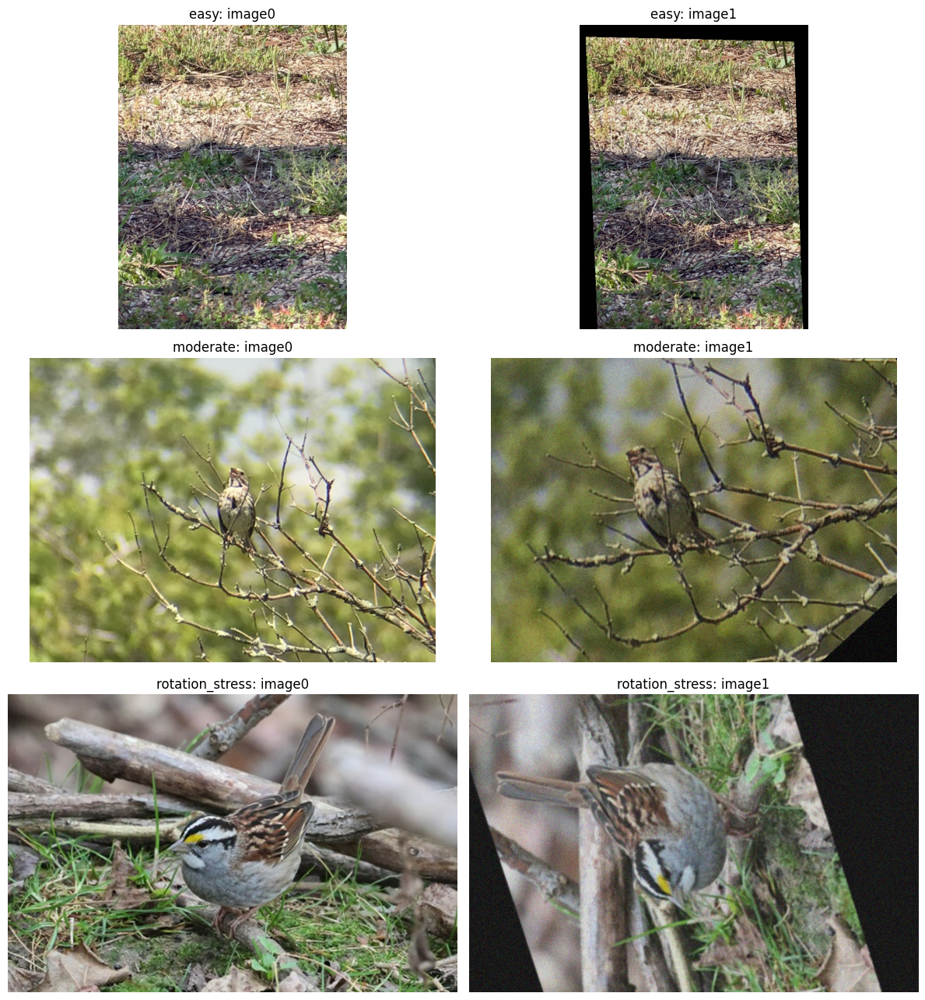

In [ ]:
# @title Visualize the exact three-tier pair bytes
import matplotlib.pyplot as plt
validation_pair_rows=[r for r in pair_rows if r["split"]=="validation"]
tiers_present=[t for t in TIERS if any(r["tier"]==t for r in validation_pair_rows)]
missing_tiers=[t for t in TIERS if t not in tiers_present]
if missing_tiers:
    print(f"No validation pair in tier(s) {missing_tiers}: tiers are assigned in turn (easy, moderate, rotation_stress) and this run has {len(validation_pair_rows)} validation pair(s). Use 7 or more photos to see every tier.")
fig,axes=plt.subplots(len(tiers_present),2,figsize=(12,13*len(tiers_present)/3),squeeze=False)
for row_i,tier in enumerate(tiers_present):
    row=next(r for r in validation_pair_rows if r["tier"]==tier)
    with Image.open(row["image0"]) as a, Image.open(row["image1"]) as b:
        axes[row_i,0].imshow(a); axes[row_i,1].imshow(b)
    axes[row_i,0].set_title(f"{tier}: image0"); axes[row_i,1].set_title(f"{tier}: image1")
    axes[row_i,0].axis("off"); axes[row_i,1].axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_ROOT/"figures"/"difficulty_tiers.png",dpi=150,bbox_inches="tight"); plt.show()

## 8. Common geometric evaluator and model-neutral baselines

Every table from here on uses the same columns. Each returned correspondence is checked against the exact reference homography: its **reprojection error** is the distance in pixels between where the matcher put the point in image 1 and where the reference says it must be.

| Column | What it measures | Why it matters |
|---|---|---|
| `n` | number of pairs scored | per-tier rows have a third of the pairs, so one pair moves a per-tier rate a lot |
| `precision_1px` / `precision_3px` / `precision_5px` | per pair, the fraction of returned matches whose reprojection error is below 1, 3 or 5 px, averaged over pairs (a pair with no matches counts as 0) | how trustworthy the returned matches are |
| `matches_per_pair` | mean number of returned correspondences | density: how much the matcher gives you |
| `inliers_per_pair` | mean number of matches within 3 px | usable density: correct matches, not just matches |
| `median_error_px` | median reprojection error over all within-3-px matches pooled; empty (null) when there are none | how precisely the correct matches are localised |
| `homography_acc_3px` / `homography_acc_5px` | fraction of pairs where RANSAC-DLT, fitted to the matcher's correspondences, gives a homography whose four image corners land on average within 3 / 5 px of the reference corners (the **mean corner error**) | whether the matches are good enough for the downstream geometric task, e.g. stitching or registration |
| `corner_error_px` (per pair) | that mean corner error; infinite (null in exports) when RANSAC finds no homography | per-pair geometric success |
| `seconds` (baselines) | wall time of the baseline on this runtime, including the notebook's geometric scoring of its matches | cost; not directly comparable with the matchers' `inference_seconds` (section 18), which cover image loading, matching and writing the match files but not scoring |

Read precision and density together: a matcher can be very precise with few matches, or dense with more errors.

Two limits of these columns. Match counts depend on how much of image 0 is still visible in image 1: the warp crops content and fills the rest, so the pair manifest and `test/per_pair_metrics.csv` carry each pair's `overlap_fraction` (share of image-1 pixels that show image-0 content). And `corner_error_px` uses the four image corners, which can lie outside the visible overlap, so homography accuracy also measures how well the fitted homography extrapolates beyond the matched area.

Homography accuracy also measures the **evaluator**, not only the matcher: RANSAC here draws a fixed budget of 500 random four-match samples with one seed. With 10% correct matches the chance that any of those samples is all-correct is only about 5%, so a matcher with many wrong matches can fail here even if it returns enough correct ones. The budget is a documented evaluation setting, applied identically to every method.

Two model-neutral baselines use the same evaluator:

1. identity guess;
2. grayscale patch nearest-neighbour by normalized cross-correlation.

> **Before you run it:** predict whether this simple reference will be easy or difficult for the learned model(s) to beat. After the result appears, record the baseline value before looking at the more complex model comparison.

In [ ]:
# @title Common geometry metrics
import math
THRESHOLDS=(1.,3.,5.); INLIER_PX=3.

def warp_points(points,H):
    pts=np.asarray(points,float).reshape(-1,2); hom=np.concatenate([pts,np.ones((len(pts),1))],1)@np.asarray(H,float).T
    with np.errstate(divide="ignore",invalid="ignore"): return hom[:,:2]/hom[:,2:3]

def reprojection_errors(k0,k1,H):
    k0=np.asarray(k0,float).reshape(-1,2); k1=np.asarray(k1,float).reshape(-1,2)
    if len(k0)!=len(k1): raise ValueError("correspondence arrays differ in length")
    if not len(k0): return np.zeros(0)
    err=np.linalg.norm(warp_points(k0,H)-k1,axis=1); return np.where(np.isfinite(err),err,np.inf)

def ransac_homography(k0,k1,threshold=3.,iterations=500,seed=0):
    k0=np.asarray(k0,float).reshape(-1,2); k1=np.asarray(k1,float).reshape(-1,2); n=len(k0)
    if n<4:return None,np.zeros(n,bool)
    rng=np.random.default_rng(seed); best=np.zeros(n,bool)
    for _ in range(iterations):
        sample=rng.choice(n,4,replace=False); H=dlt_homography(k0[sample],k1[sample])
        if H is None: continue
        mask=reprojection_errors(k0,k1,H)<threshold
        if mask.sum()>best.sum():
            best=mask
            if best.sum()==n:break
    if best.sum()<4:return None,best
    H=dlt_homography(k0[best],k1[best]); return (None,best) if H is None else (H,reprojection_errors(k0,k1,H)<threshold)

def corner_error(est,ref,size):
    w,h=size; corners=np.array([[0.,0.],[w-1.,0.],[w-1.,h-1.],[0.,h-1.]])
    return float(np.linalg.norm(warp_points(corners,est)-warp_points(corners,ref),axis=1).mean())

def pair_metrics(match,H,size):
    k0=np.asarray(match["kpts0"],float).reshape(-1,2); k1=np.asarray(match["kpts1"],float).reshape(-1,2); errors=reprojection_errors(k0,k1,H)
    out={"n_matches":int(len(errors))}
    for t in THRESHOLDS: out[f"precision_{int(t)}px"]=float((errors<t).mean()) if len(errors) else 0.
    inliers=errors[errors<INLIER_PX]; out["n_inliers"]=int(len(inliers)); out["inlier_errors"]=inliers.tolist()
    est,_=ransac_homography(k0,k1,RANSAC_INLIER_PX,RANSAC_ITERATIONS,RANSAC_SEED)
    out["corner_error_px"]=corner_error(est,H,size) if est is not None else math.inf
    return out

def aggregate_metrics(rows):
    if not rows:  # a tier with no pairs (small BYOD sets): report n = 0 and undefined (null) metrics
        return {"n":0,**{k:math.nan for k in ("matches_per_pair","inliers_per_pair","median_error_px","homography_acc_3px","homography_acc_5px")},**{f"precision_{int(t)}px":math.nan for t in THRESHOLDS}}
    pooled=[e for r in rows for e in r["inlier_errors"]]
    out={"n":len(rows),"matches_per_pair":float(np.mean([r["n_matches"] for r in rows])),"inliers_per_pair":float(np.mean([r["n_inliers"] for r in rows])),
         "median_error_px":float(np.median(pooled)) if pooled else math.inf,"homography_acc_3px":float(np.mean([r["corner_error_px"]<3 for r in rows])),
         "homography_acc_5px":float(np.mean([r["corner_error_px"]<5 for r in rows]))}
    for t in THRESHOLDS: out[f"precision_{int(t)}px"]=float(np.mean([r[f"precision_{int(t)}px"] for r in rows]))
    return out

def grid_points(size,step=32,margin=16):
    w,h=size; xs=np.arange(margin,w-margin,step,float); ys=np.arange(margin,h-margin,step,float); gx,gy=np.meshgrid(xs,ys); return np.stack([gx.ravel(),gy.ravel()],1)

def identity_baseline(image0,image1,step=32):
    pts=grid_points(image0.size,step); return {"kpts0":pts,"kpts1":pts.copy(),"confidence":np.ones(len(pts))}

def _gray(image): return np.asarray(image.convert("L"),float)
def _ncc(patch,window):
    p=patch.shape[0]; h,w=window.shape
    if h<p or w<p:return np.zeros((0,0))
    windows=np.lib.stride_tricks.sliding_window_view(window,(p,p)); tiles=windows.reshape(windows.shape[0],windows.shape[1],-1); tiles-=tiles.mean(2,keepdims=True)
    flat=(patch-patch.mean()).ravel(); denom=np.sqrt((tiles**2).sum(2)*(flat**2).sum())+1e-9; return (tiles@flat)/denom

def patch_neighbour_baseline(image0,image1,step=32,patch=15,search=48):
    g0,g1=_gray(image0),_gray(image1); half=patch//2; pts=grid_points(image0.size,step,max(16,half+1)); k0=[];k1=[];conf=[]
    for x,y in pts:
        xi,yi=int(round(x)),int(round(y)); tile=g0[yi-half:yi+half+1,xi-half:xi+half+1]
        y0,y1=max(0,yi-search-half),min(g1.shape[0],yi+search+half+1); x0,x1=max(0,xi-search-half),min(g1.shape[1],xi+search+half+1)
        scores=_ncc(tile,g1[y0:y1,x0:x1])
        if not scores.size:continue
        best=np.unravel_index(int(np.argmax(scores)),scores.shape); k0.append([x,y]); k1.append([x0+best[1]+half,y0+best[0]+half]); conf.append(float(scores[best]))
    return {"kpts0":np.asarray(k0,float).reshape(-1,2),"kpts1":np.asarray(k1,float).reshape(-1,2),"confidence":np.asarray(conf,float)}

## 9. Validation baselines

**Predict before running:** Predict whether identity matching or local patch search will retain more geometrically correct correspondences as tier difficulty increases.


In [ ]:
# @title Model-neutral validation baselines
import time

def evaluate_callable(rows,matcher_fn,method):
    per=[]; started=time.perf_counter()
    for row in rows:
        with Image.open(row["image0"]) as a, Image.open(row["image1"]) as b:
            a.load();b.load();match=matcher_fn(a.convert("RGB"),b.convert("RGB"))
        met=pair_metrics(match,np.asarray(row["homography"]),(row["width"],row["height"])); met.update({"pair_id":row["pair_id"],"tier":row["tier"],"method":method}); per.append(met)
    agg=aggregate_metrics(per); agg["seconds"]=time.perf_counter()-started; return per,agg

validation_baselines={};validation_baseline_rows=[]
if RUN_IDENTITY_BASELINE:
    rows,agg=evaluate_callable(validation_pair_rows,identity_baseline,"identity");validation_baselines["identity"]=agg;validation_baseline_rows+=rows
if RUN_PATCH_BASELINE:
    rows,agg=evaluate_callable(validation_pair_rows,patch_neighbour_baseline,"patch_neighbour");validation_baselines["patch_neighbour"]=agg;validation_baseline_rows+=rows
display(pd.DataFrame([{"method":k,**v} for k,v in validation_baselines.items()]))

,method,n,matches_per_pair,inliers_per_pair,median_error_px,homography_acc_3px,homography_acc_5px,precision_1px,precision_3px,precision_5px,seconds
0,identity,48,261.25,1.187500,2.085603,0.0000,0.0000,0.000649,0.005054,0.011973,1.068092
1,patch_neighbour,48,261.25,68.395833,0.505101,0.3125,0.3125,0.236885,0.266703,0.272682,149.689540


> **What to notice.** The identity guess keeps every grid point where it was, so it is right only where the warp barely moved the image; expect values near zero, highest on easy pairs. That is the floor. The patch neighbour searches only ±48 px around each grid point with a fixed upright 15×15 patch and always returns its best candidate, even for an ambiguous or textureless patch (it never rejects a match), so it should do clearly better on easy pairs than on rotated or strongly scaled ones, where many true correspondences lie outside its search window. Both baselines also appear per tier in sections 12 and 14. Beating them shows that a learned matcher adds something over a deliberately simple local search; it does not show superiority over conventional feature matching in general. Write down both `homography_acc_3px` values: a learned matcher has added something only if it beats them on the same pairs.

## 10. Build the isolated comparative matching environment

The model frontend runs in a separate CPython 3.12.12 environment, whatever Python the notebook kernel uses, pinned to `vismatch==1.3.2`, `torch==2.14.0`, and `torchvision==0.29.0`. The first cell carries a hash lock of every wheel in that environment (from `uv pip compile --generate-hashes`); the second downloads the `uv` 0.12.15 wheel, checks its size and SHA-256, and installs the lock with `--require-hashes --only-binary :all:`. Nothing is installed into the notebook kernel, so **Run all** needs no restart. This environment is built for **Linux x86_64** only (Google Colab, Kaggle or a Linux x86_64 Jupyter server).

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Carried hash lock of the matcher environment (infrastructure)
# Generated by tools/build_multimodel_image_matching_workshop.py from
# tools/multimodel-image-matching-workshop-requirements.lock (uv pip compile --generate-hashes,
# CPython 3.12 on x86_64-manylinux_2_28); do not edit by hand.
import hashlib
MATCH_ENV_LOCK = (
    '# Hash lock of the isolated matcher environment of tutorials/DIMER_MultiModel_Image_Matching_Workshop.ipynb.\n# Target: CPython 3.12.12 on Linux x86_64 (manylinux_2_28), wheels only, installed with\n#   uv pip install --require-hashes --only-binary :all: -r requirements.lock.txt\n# Direct pins (multimodel-image-matching-workshop-requirements.in) are the versions the notebook pinned for its\n# former unhashed install (section 10, PINS): vismatch 1.3.2, torch 2.14.0, torchvision 0.29.0.\n# No version changed and nothing was added; every transitive package is now resolved once, here, with its SHA-256.\n# Regenerate from tools/ with the uv command below, then run build_multimodel_image_matching_workshop.py.\n# This file was autogenerated by uv via the following command:\n'
    '#    uv pip compile multimodel-image-matching-workshop-requirements.in --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: --output-file multimodel-image-matching-workshop-requirements.lock\nabsl-py==2.5.0 \\\n    --hash=sha256:0c996f25c0490700fadabe6351630f6111534fa0ae252cc6d2014ea3b141135f \\\n    --hash=sha256:0f17b89f2a4eaaedc4f28c622998aa690564b3012a396a4ffad0821007fe03ba\n    # via tensorboard\naiohappyeyeballs==2.7.1 \\\n    --hash=sha256:065665c041c42a5938ed220bdcd7230f22527fbec085e1853d2402c8a3615d9d \\\n    --hash=sha256:9243213661e29250eb41368e5daa826fc017156c3b8a11440826b2e3ed376472\n    # via aiohttp\naiohttp==3.14.3 \\\n    --hash=sha256:03cd2bde3d7f085b64e549c985f4bb928cad7e8ecf5323bfca320db548d81b39 \\\n    --hash=sha256:041badb8f84396357c4d3ad26de6afd7a32b112f43d3c63045c0c8278cfd2043 \\\n    --hash=sha256:0a5ff2dfbb9ce645fa5b8ef3e02c6c0b9cc3f6030ff863d0c51fffc50cb5541b \\\n'
    '    --hash=sha256:0fdea2281997af69da84c77ffa6f5938a0285f21fb3887c249d67419ca865b3d \\\n    --hash=sha256:11fb37ef075669eee52ab1928fbf6e1741fada40409fa309ebde9607a962aebf \\\n    --hash=sha256:134ac5ddcf61c6fad984b9a5727d83492ada43d63471db20fb73042c13fca62f \\\n    --hash=sha256:152516815ef926786a0b6ae2b8f1fd2e0c71582dee0b435636865316fd4891b7 \\\n    --hash=sha256:1576145bdceeb92382d899751e12743a3a5b8e460a841e3e50543859e54864dc \\\n    --hash=sha256:16100ad3ab8d649fdfbee87602d9d2dcdca9df0b9eda8a1b5fdc0d41f96da559 \\\n    --hash=sha256:16ea7e24c309fb7c0bbd505d149abe4fe4dccfb8db911db7dbec0921bc889a6f \\\n    --hash=sha256:18c441d0a8fca6de8d1f546849b9f0ab20d435993e2c5b59562b2fae6be2f929 \\\n    --hash=sha256:18cb43369747b2ae007bd2655fb8e63a099c2ff1d207962943636dac989b3147 \\\n    --hash=sha256:1b59533861b70a2185c8f4f350f791f39d64358ef6944ce71c5240c9ec0982c9 \\\n    --hash=sha256:1c5281acc88b92396f88c7e1e2748f8466689df22b80170e4f51efa712fb47a8 \\\n'
    '    --hash=sha256:1c5ec8fb1bcc31a8466f74aaf26c345d5c386fa4bd08a3f0eb9c7a4a3fe8b5bf \\\n    --hash=sha256:1caa7b0d05f3e3a36f87788c59e970a7ee1cefcfcbb924a9f138c4a6551c9cb7 \\\n    --hash=sha256:21c016079415ed3fd676963e9793700a566d85dbbd6bfc564b9b2d209147dcc8 \\\n    --hash=sha256:2498f0fe69ead802f9675beca44a7c21c62fdaa4ec5145ea1c3ad6edbee29f85 \\\n    --hash=sha256:25bd2708db6bdf6a6630dd37bdcdfcb47c4434d22ac69c64665b802910140b30 \\\n    --hash=sha256:270d3dace9ca2f10f0da5d8ebe519b7a310fc6112ed916e32df5866df0888553 \\\n    --hash=sha256:2e1161602f45a54de2ce0905243a95f58cb42dcd378402f3697f5e0b21e9d2e7 \\\n    --hash=sha256:2e9878ae68e4a5f1c0abe4dd497dbc3d51946f5837b56759e2a02e78fa90ef86 \\\n    --hash=sha256:30402d03a7c0ff52bce290b57e564e9079fd9d0cb545c8aba73f86a103162d2e \\\n    --hash=sha256:33a2d7c28d33797a2e99923dffa63f83d908a19b6bf26cfe80fa790aa5e1a75a \\\n    --hash=sha256:362a3fd481769cac1a824514bcd86fda51c65e8fe6e051099e008fddde6db17c \\\n'
    '    --hash=sha256:38901a84da3ce22249f6e860bf8f90d141bcab7da090cc398f8bb58c0e44b7da \\\n    --hash=sha256:39aded8c7f3b935b54aab1d8d73c70ec0ee2d3ec3b943e0e86611bc150ba47f5 \\\n    --hash=sha256:3a26434dafe408229ff3403458ca58de24fb51936504decac49ce6755f77e59d \\\n    --hash=sha256:3ae5b3a59436d089b5395d910121a390feed4d00578eb95a0fd1a329fe963100 \\\n    --hash=sha256:3d4f72af88ac2474bb5bca640030320e3d38a0163a1d7533500e87be458eef71 \\\n    --hash=sha256:3f42e9b78301f11c8f861746175d8b9c1ccef713fcad9eab396e2f6db8ed4a22 \\\n    --hash=sha256:42a67efc36300d052fb4508a53e8b6901b9284b599ae63945c377569c5fcc1e1 \\\n    --hash=sha256:48d67b87db6279c044760787eb01f6413032c2e6f3ba1cafaa492b1c8e578479 \\\n    --hash=sha256:498c6c623134f8e09a3c4e60bcd607a0b4590dd7dbf08dd40851b27cbb520ccb \\\n    --hash=sha256:49f7325beb0f85ef4aef5f48f490269575f83e6e2acad00a1d80b807eb027062 \\\n    --hash=sha256:4e3ac92d90e92773b2362d506068e9a948192bd553e743c5b2429e28527c8661 \\\n'
    '    --hash=sha256:530125ee1163c4219af35dc3aa1206e541e7b31b6efc1a3f93b70a136f65d427 \\\n    --hash=sha256:5373dc80ad1aa2fb9ad95c83f24eef418bbda3a61375f128e5b0192e4f3f9b32 \\\n    --hash=sha256:53e5179d8abb5710f8e83ba207c41c8d1261fcffd4616500e15ca2b7a33be10a \\\n    --hash=sha256:53e7b4ce82b54a8bcc71b3b67a5cbd177ca1d7f592cbc92cd38b7349f73482db \\\n    --hash=sha256:543906c127fb1d929b95076db19b83fa2d46751006ff1e23b093aa5ac4d8db42 \\\n    --hash=sha256:54cfcdee2770dac994417cbb0ee1f3eb0e7cb6b30c79bf44f2c02ff79ec5124a \\\n    --hash=sha256:55bdcc472aafe2de4a253045cc128007a64f1e0264fb675791e132ea5edaa3bd \\\n    --hash=sha256:56f355e79f71aef2a85c80305cc915f894b170dba76de5fe84f6351939b83c06 \\\n    --hash=sha256:5895ef58c4620afe02fa16044f023dc4dafec08158f9d08874a46a7dbc0341b8 \\\n    --hash=sha256:5bcb6ff3fdab1258a192679ff1a05d44f59626430aa05cd1a9d2447423599228 \\\n    --hash=sha256:5f08ec777f35ee70720233b8b9811d3bb5d728137f30ac91b7457709c3261ac0 \\\n'
    '    --hash=sha256:614c61d478b83953e261d02bb2df750f17227cd33ef8002945bf5aebbde21919 \\\n    --hash=sha256:617105e2c3018ee38d0c8ce5ee3c84f621a6d8b9f723202aacaff28449ca91ee \\\n    --hash=sha256:6debfa7312ff9d4c124dc71d72e9a0a4b9e0879e48ba6fcb42bef5c3300289e2 \\\n    --hash=sha256:7041d52c3a7fa20c9e8c182b534704abb19502c8bdcbde7ab23bfda6f642394f \\\n    --hash=sha256:70c987b27534f9ae1a723f47ae921571d616da21d3208282bf4c52af5164ac43 \\\n    --hash=sha256:74ab5b6a9fb13e873e5a90946588baecaf488745e1db1a4a5c433f971f035098 \\\n    --hash=sha256:78253b573e6ffab5028924fc98bc281aae05445969982a10864bc360dea2016c \\\n    --hash=sha256:7a75aa63cbf9b21cfaf60dc2657e19df2c2867d91707d653fee171ffeedd1371 \\\n    --hash=sha256:8800c996b01c2772a783e3e46f3e1abd5823029adca0df54231960de9bfefa5b \\\n    --hash=sha256:89176250f686cb9853c0fb7ead90e639e915b84a6f43eedc2a4e7ec21f1037f0 \\\n    --hash=sha256:8a5fd34f7f7410d1730d5c2ba873cacb2eed3fede366feb268a70ba22581ed8f \\\n'
    '    --hash=sha256:8b3b60de05f3dcb6f6a00f818bb2ec781cee4de0645f59ccaf99b1d1823b6100 \\\n    --hash=sha256:8f2f1c4c032c7cedd7d8da6f54c97b70266c6570c3108d3fdffee7188bb70529 \\\n    --hash=sha256:9491196535a88924a60afd5b5f434b5b203b6cc616250878dbdb223a8f7844bc \\\n    --hash=sha256:9aa6e61fdf20105c4144e755bd586008ff450791d67b1c8146fdc15959c4d51c \\\n    --hash=sha256:9d9edccfe496b476db5f398d97b865e9a6752bcf8aec4eef8390ce20fb64bb41 \\\n    --hash=sha256:9fc7b5bfec6573f3ae844f457fdde5adeb713f8b8e4a81ad64fc207b49383716 \\\n    --hash=sha256:a0dc483c00da8b673abbb367eb6f8d8f4bcec30eb58529ea13cb42e7fd2dfa33 \\\n    --hash=sha256:a3a8296e7ab5c295f53f1041487cb088e1480775aafbf7fe545d93b770a0f96f \\\n    --hash=sha256:a3e22975f905b89a55a488c2a08f2fdb2186175349e917d48985cc468a3d4c6e \\\n    --hash=sha256:a4af35c443e0b1a1bd6a8af3f3485d7fda15c142751a00f3ff8090f0b93346fa \\\n    --hash=sha256:a94dbaae5ae27bd849c93570669bff91e0510f33a80805738e3de72a7be0447b \\\n'
    '    --hash=sha256:ac74facc01463f138b0da5580329cfcc82818dea5656e83ddcd11268fc12ff80 \\\n    --hash=sha256:ad4c8b7488d745d2ca4838ebd8ae5ba9b56341d30b1da43640e4ce87f9f49646 \\\n    --hash=sha256:b014a6ed7cf912e787149fdc529166d3ceabac23f26efeea3158c9aba2354e7e \\\n    --hash=sha256:b20032766aedf6261c7a566585a40867d092ac03a0d81592d5370ef9b054f99b \\\n    --hash=sha256:b2466434105a4e03113c36ec775cc2ebe6676b62eae326fa670bb607ef788c1c \\\n    --hash=sha256:b304db572b4368edd8dda8a2274f73156fe15558fca4a917cb8a09fc47af5963 \\\n    --hash=sha256:ba59d59aba08ac02fc03b0c8983ccd5ee39a199d0552ce9e6d2b4845b34d59ae \\\n    --hash=sha256:bd52f811e65f6fb634b1047159657c98f52b407f8efec907bcfc09da9a4c0a25 \\\n    --hash=sha256:bdd0e2834dce1a26c1bbe26464861e16bbe217042cbff619247c11594472518c \\\n    --hash=sha256:c23ec8ee9d5ab2f5421f9c7fffce208435607af27fd46d4a44e031954352838f \\\n    --hash=sha256:c39846c3aad97a8530c89d7a3869a8f8e9e3762c6ac0504481e5c80948f7e807 \\\n'
    '    --hash=sha256:c3c200cf9757edd785051dc699c7ecbec22110dbfcb3fefc7a9f9695eda8ea7a \\\n    --hash=sha256:c7d3a97c678d34fc5b59da671ee9cd630096ddc643e7b5a30d54a2a6f3574d3f \\\n    --hash=sha256:c8653fd547c93a61aadc612007790f5555cdd18946fa48cf45e26d8ea4ea473d \\\n    --hash=sha256:cc7cb243a68167172f48c1fd43cee91ec4b1d40cefd190edd43369d1a6bc9c82 \\\n    --hash=sha256:ccd4893707b3e2a13e39c90d43cf80edf2e4d0457935bcc103bf2346214c3f15 \\\n    --hash=sha256:cd817772b2fcf2b8c0905795318485f9ec16eae60b29feb7f4c77085311637f0 \\\n    --hash=sha256:cda5fd5c95ad7a125a2e8464acc78b98b94c475a3780d6aa0aa157c93f470f4d \\\n    --hash=sha256:cef89a58e628c4efcac3275c2d68083f82426dcdc89c1492a6f654f9f7ea6ab9 \\\n    --hash=sha256:d1558173930a5a8d3069cee5c92fc91c87c4dbcb099debbb3622053717145a19 \\\n    --hash=sha256:d6088ec9894113802bddb3c09e974929aed2c7b3a8c456219b8aab4481f1a239 \\\n    --hash=sha256:d6218d92e450824e9b4881f44e8c09f1853b490f9a64130801024a4793b1b3b0 \\\n'
    '    --hash=sha256:d77640cc618c1d99fc4f8589c0f24a730adfa54eb1e57ef7bf0c8dfb78da898c \\\n    --hash=sha256:d7d2deec16eeedf55f2c7cf75b521ea3856a5177e123844f8fd0f114ce252cb5 \\\n    --hash=sha256:db332af25642007330fca8be5c4d194caf2bea7a7fc84415aff3497af5dfee6b \\\n    --hash=sha256:dd54d0e8717de95939766febac482ac0474d8ac3b048115f9f2b1d23a16e7db4 \\\n    --hash=sha256:ddcac3c6b382e81f1dd0499199d4136b877beb4cb5ef770bbbfba56c4b8f55d2 \\\n    --hash=sha256:df82f3787c940c94986b34222d59c9e38843fba85139f36e85255a82ad5355a9 \\\n    --hash=sha256:dfa68deb2a443bdaa3ea5297b0699c1464f08aef3812b486d1348eee61b07dc0 \\\n    --hash=sha256:dff9461ec275f22135650d5ba4b4931a11f3958df7dfbb8db630000d4dee0883 \\\n    --hash=sha256:e1e74298bab6ee0d6e749ed4fd1901c7e604bdda32c03d787a2cc71c46d0433d \\\n    --hash=sha256:e2667f0bbe7eb6c74eae5e9691441ad186e5845ca3cff63230fc09c4e7514f5d \\\n    --hash=sha256:e3be98a7c30b8c25d573dafba7171d66dfb05ee6a9070fc46535464ff97700a6 \\\n'
    '    --hash=sha256:e568e14940c09955aa51f4e645b6daa18a581c5dcfcd73744dcc86a856e3ced3 \\\n    --hash=sha256:e72ee89e28d907a18f46959b4eb0bb06701cc7f8cf4366e00029e2ccfaaf5924 \\\n    --hash=sha256:e92eb8acc45eb6a9f4935071a77edf5b85cc6f8dfad5cd99e97653c26593cdde \\\n    --hash=sha256:ea05e1f97ceea523942d9b2a7d7c0359d781d683d6b043f5943a602b14da4787 \\\n    --hash=sha256:eac645b09bcfdf73df7536331f0678c1086ea250981118ddb5199e17ccef72bb \\\n    --hash=sha256:eb0495d778817619273c108784292be161a924b9f5ae5cbbc70a2caa6838250b \\\n    --hash=sha256:ebe8e504f058fe91223351cecd2d9d6946c9d241bb0250d898ffbdf584cc72b0 \\\n    --hash=sha256:ed099d105449c4f9e84f24af203cd131349d4761d8813fa7e02c32e7128cd910 \\\n    --hash=sha256:f0f177d1b195b9e06376cfd7d308d8a1b920909a609d03ac82a8c73bbb16d3b9 \\\n    --hash=sha256:f3d2669fe7dec7fc359ecdb5984b29b50d85d5d00f8c1cb61de4f4a24ee42627 \\\n    --hash=sha256:f4e05329faa0ea1a404b37de4f034fd2c2defcca06a68dc6745e4e56c88e8a48 \\\n'
    '    --hash=sha256:f53bcd52f585e1ac3e590d61434eb61f9a88c38df041b4ea126d97144344a77b \\\n    --hash=sha256:f55119f7bf25f49ed210f6096090715da24f2943c62102448915fde3c62877ce \\\n    --hash=sha256:f631fe87a6f30df5fbe6d79640b25e4cffb38c31c7fb6f10871517b84b0f8c1a \\\n    --hash=sha256:f8fb78a83c9e5f741ca3a68cfb455c1f5bb83b4e7249a3848b3cd78d0a8563b0 \\\n    --hash=sha256:fa9467a8113aa69d3d7c55a70ef0b7c636010a40993f3df9d9d0d73b3eb7ef24 \\\n    --hash=sha256:fd51ebf9d3a00c074df4ede271023f4d2dba289bcc740b88191872716014e3c5\n    # via fsspec\naiosignal==1.4.0 \\\n    --hash=sha256:053243f8b92b990551949e63930a839ff0cf0b0ebbe0597b0f3fb19e1a0fe82e \\\n    --hash=sha256:f47eecd9468083c2029cc99945502cb7708b082c232f9aca65da147157b251c7\n    # via aiohttp\nanyio==4.15.1 \\\n    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \\\n    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94\n    # via httpx2\nargon2-cffi==25.1.0 \\\n'
    '    --hash=sha256:694ae5cc8a42f4c4e2bf2ca0e64e51e23a040c6a517a85074683d3959e1346c1 \\\n    --hash=sha256:fdc8b074db390fccb6eb4a3604ae7231f219aa669a2652e0f20e16ba513d5741\n    # via minio\nargon2-cffi-bindings==26.1.0 \\\n    --hash=sha256:061a6919145bbf282ebf1f9c59d3135d4833c25313c8595c0d68cf7712ddfce2 \\\n    --hash=sha256:0cc40f7b4050bb93eb67de95d2d759322fc7ce4930b9d645581ecf4913ec651e \\\n    --hash=sha256:151dfaad9de753f4af2a7854e707e4784f2acc434340ade64239c5b104b2d605 \\\n    --hash=sha256:19423e5d7ac1cc354baab59eaabf18db2ec04ef6593b5abe5a34f323c4a8f87a \\\n    --hash=sha256:19b562b1de4b9052ef1214a2821c44b6e6f22945daa102c32ae4eff929d8b6d8 \\\n    --hash=sha256:1a0a29ed86960e44eaace7e081bdfab4f08b012fd96ec8edba71e2ad020939e4 \\\n    --hash=sha256:1af817e84578ef8b7295ad17de0f9896e4c8520dbf2233c7aa5aa3d487256fc4 \\\n    --hash=sha256:1b0bcac4d490a237e18cf91f57352920c29f77f2fa39efd0813fb81298bf17ba \\\n    --hash=sha256:1d98e33bd8bd67d7206c124e200bf2229c4cfa8c9c19f7b44a897f0fc71837eb \\\n'
    '    --hash=sha256:21ca0396fe5ec995dd54431c32698189666f9224810acfa752e50d2bd94d9df2 \\\n    --hash=sha256:224865cbbcb7a2bd1356741dff12b0134df726b6d44bb7b500df8e303cbd9e81 \\\n    --hash=sha256:242bb0cda2ae3650764fc194593d9ea45fc9e72729acd89778c7cfe184cec2a5 \\\n    --hash=sha256:27f1821903e2ceadcb88ec2b45ef190897b7682449c772f4d9b53e42c520cf29 \\\n    --hash=sha256:28524438cd3e723f25412f63d4fd516ff5bae9ae5aa56acbe2a1404398a0cf31 \\\n    --hash=sha256:2b741888c93147444fdfc851abd81cc207f37f7f7da42062a00deb3888e57da8 \\\n    --hash=sha256:2c36ff87b5dfaa477d0bd51e9d7f6abdae7c8955d2983c97419085d842154b3e \\\n    --hash=sha256:34b7d9c24a4165a2c61cc8ae11d44d48c9ce2830fb536cb7914e11fdd9962728 \\\n    --hash=sha256:49d525938467d52c923a890153c99087c9d5a937d1f6b585dbdba34ec82e397a \\\n    --hash=sha256:4f84cdd868978d7b7350a566c254042d44216d9e37f241f3a6d3b1dfebeede35 \\\n    --hash=sha256:62ff20cd130c956c7c9144d5fe35228f98b51c579b2439e988b27ef93e16c02a \\\n'
    '    --hash=sha256:63505c71542a44b68b1e38060450fb006404170da375feb31af153e7f9c6205d \\\n    --hash=sha256:6376d4b3aca039375ca8bf92f770da0ec424a1ce3a37077a8d3c557411aa56ca \\\n    --hash=sha256:6a4e68eed961a8de6928d1c17ff3dc2a547e0e923c17f8f1cd79fb7bc9502f98 \\\n    --hash=sha256:6ab674f668d5962a3a4136ae0812519b0f1586874263723a32181d60d64137e1 \\\n    --hash=sha256:7014ab7e6f5d8511af92544667a0346ea6dfc314ea9a7cad1dba9fdb5c9a6e33 \\\n    --hash=sha256:76ae29acace5d33355344612844d588e19deaaba4639d8bb01601e4b1418ef36 \\\n    --hash=sha256:78de2d65e0b9ea7ce9d1b1c3e87297b2d7305a02c266ee2a2d6910daddd7ee69 \\\n    --hash=sha256:9bacedc04b0402837586a17f0919e3dfdd95291f441f1f56bd80ec274c2840a1 \\\n    --hash=sha256:a86c069c91a747a2c4e5c51473590aeb48172fff9b2130d23729a42d98665ecb \\\n    --hash=sha256:ac82fc756a446b6ccd7139ce70efa9d8bbe541e7ad579a12dcb52764b7175c5f \\\n    --hash=sha256:af11ac37a7c53dc16cb7950a6190851b0870fe218b6c60c0bb7ac355234e3083 \\\n'
    '    --hash=sha256:b70225b5fd1e0d2ef4f7fd30d24658454535f0924dff0caca5dc08efbbbadfbb \\\n    --hash=sha256:c49e853a3bef9dd10329f31f702e7fa9b5c58229ff9c2ff6d069efaf09177c08 \\\n    --hash=sha256:ccaf0a46cbb380f1fd102a874e32aa629fd3cb0c0e94f4943fa1f6d5edc5dac6 \\\n    --hash=sha256:d157ddfab1e8b21f2f1dedda9c09645d98b5ed0b667b0626be600a345d426440 \\\n    --hash=sha256:d88e5f7e60f28ae0b0cc6b2f16c43e87cd642a196a86f85e0d8bb6fe016fc16d \\\n    --hash=sha256:db0fcd827ca61622a01b220aadfbece01939acf53888f2cb98cd93e9b1e2c97e \\\n    --hash=sha256:df612391feca41c44d20118f3b88d1b86419465cd1f5496859f715ca60ec2210 \\\n    --hash=sha256:f0c3103fcff20183e593459cfea6e012281c0e76ae3ed8b5565ad1b92eac3990 \\\n    --hash=sha256:f9c4420a7a864fe1b86ce35befc95b8e39fb852493b81cf798671ddc265de638 \\\n    --hash=sha256:ffff613aaa9ce6236766e2fc6dc560bb5abde7a2e2416e3db1f9ae395a2b4dd4\n    # via argon2-cffi\nattrs==26.1.0 \\\n    --hash=sha256:c647aa4a12dfbad9333ca4e71fe62ddc36f4e63b2d260a37a8b83d2f043ac309 \\\n'
    '    --hash=sha256:d03ceb89cb322a8fd706d4fb91940737b6642aa36998fe130a9bc96c985eff32\n    # via\n    #   aiohttp\n    #   rerun-sdk\nbeautifulsoup4==4.15.0 \\\n    --hash=sha256:288e3ca7d54b06f2ac191970bc275c1939cb46d450b255bf6718b04aa37ab4f7 \\\n    --hash=sha256:d6f88de62e1d4e38ecb1077eb9724cd0eff29d2a08ca16a401e9b9e93f117cf9\n    # via gdown\ncertifi==2026.7.22 \\\n    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \\\n    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55\n    # via\n    #   minio\n    #   requests\ncffi==2.1.1 \\\n    --hash=sha256:046bfc24911b37851ee1b51aab8bffe713d89c68c6a057b09484ce9fd5f69b4e \\\n    --hash=sha256:06c72bb76605a4b0cd0aad6930b69d4baf7dd5d806cfc409b824191099700e66 \\\n    --hash=sha256:0beceaabe56af686895136a2de78db54ecd8e4046b236b8fd6d6cb61389e9bf2 \\\n    --hash=sha256:154852545011f779917b11c78db2358d095da62a9a172b78ad0a583ee5adc0d0 \\\n'
    '    --hash=sha256:194cffa889098ced9976c3fc6340305e43f6303657d298da55366907c05c22d6 \\\n    --hash=sha256:19ee6127ee34de7d83ce3d371ebc5ed91addbdcc39f9ab15ce4eb35a4e534971 \\\n    --hash=sha256:1a18a57b58cfb21fc28d72e876acf10eaed67a1ed96226f92af4df681d571c4c \\\n    --hash=sha256:1aa5645c30469b09530c4ebca77ebf8f17618293c58f8549cb1a543a50236e7d \\\n    --hash=sha256:1dea0e4d7d4f11f619fe8c1d76caf49e24405b4b5743c0e3be16a500ecd930c9 \\\n    --hash=sha256:208f941bb9d18e768138677f0a6d2ce01f590df56043dda1df1535ac57c88517 \\\n    --hash=sha256:210019b6c7cf07f081b4c54635c8cf744377001350e29cc0f81c4377b4797735 \\\n    --hash=sha256:246fa40ce8645a614ff682e0b70f37134e460eaf93a775e0cbe3cca585a67a80 \\\n    --hash=sha256:25792eac27877609e7bb06d42ff88278a6624fff2ba9bbb523c09616b117e80f \\\n    --hash=sha256:27350daa11d4f10c540e6e89dada4c54feb7256ad03e9a4dc075ebad7ba360d1 \\\n    --hash=sha256:28907ab9bfb6aa13184cfc17c6b8e1023c5ab6fd7076d8c20a35e59fe04f8f29 \\\n'
    '    --hash=sha256:2ae64be792b8966f2c69538199728b290e34726562896df1e5dc8ffd8d8188e8 \\\n    --hash=sha256:31348097ff5bbe827ccc41795d4dd099d9f0625e7def00ee653c137a490c2a6c \\\n    --hash=sha256:3143d81e29e1e20a9ce10901ec369012947876596f75a222235965f2b7ae832e \\\n    --hash=sha256:3222ba5d678f80a030e6afbcc33dc1ae5cb45facabb61cee2c7016b8432fde48 \\\n    --hash=sha256:3311ed60d36f83378794e1009ac6258bafbf81f7888b4caa7b35a521e3f95813 \\\n    --hash=sha256:334644fbac4eff73d985a17a91226df55d0f394160c4cfb880e084c8f7161cac \\\n    --hash=sha256:34e261f78cb6ceaaa36f42f2613f4380d94d9c759a9c73c769ee6e0247364632 \\\n    --hash=sha256:363e05fa78e15116c3c32c210ee36884fd6b9afa6d440e47112c3bd511d64cb6 \\\n    --hash=sha256:398aff33cee2767e3e781d2554c54bd0dff386bb437581e0d8011fde1a942ec1 \\\n    --hash=sha256:3d22a20b1fb1632cc72c22f95f7b0d2961c3e1c235f245ba4c606c4771035659 \\\n    --hash=sha256:42a494cee34437f05546455144f2b5d9ac09b1face62bcfce597d2e521066688 \\\n'
    '    --hash=sha256:42e2f76b9455f5a9a844f770bf3e200ed3da0e15f5df3db9c31fe80b04b3d004 \\\n    --hash=sha256:42f6930c31dc7f50732c9ae793c2786c7b6b044195967bbdde40bb9be81c4cc0 \\\n    --hash=sha256:456a61fa52d579ebf9df2e9552ead5129855dbaff6c1e5a9b1bc408809bdc062 \\\n    --hash=sha256:471cee653ae88de62096552e6d24ccb4a5adb8c8c9f10b5054d0122c15bf2779 \\\n    --hash=sha256:49cbc70e6542d4ccccb936558d1064a8012541e78f821f955cff24e357776c94 \\\n    --hash=sha256:4a7c934f7360e8cd64fe9efadcbd10c7c6364f531e432b9a4bf5ccbc9e0e8b50 \\\n    --hash=sha256:4be96343e422f2dfcd12ab5c9f5aebe03f82f737c6bffeca6830b3875cb44aab \\\n    --hash=sha256:4f42141fc14250de6dde5ee7ea4432be017252d91f19c5ad043c084cea629cac \\\n    --hash=sha256:507a24c282e0f42f8ed737cf048572cbf580468da5555764a8331735e9c736b6 \\\n    --hash=sha256:51b31d1c98274844cfd7838ce00bfc27c7423a4dc00fc0772fc3331c2cc90676 \\\n    --hash=sha256:58acb8ab8e295e6c5ea12f888cbb13cf21511ef2a3303a23f4325c29d17fe5c1 \\\n'
    '    --hash=sha256:5a59cc1c4442bc3d5c703bf720b51138d0bfc173618807c9ee2490a7541dd3d9 \\\n    --hash=sha256:5bb4e7ea95dcd6a014a6fef62e62467d67d8e582326443f3d68e71d6320a9fcf \\\n    --hash=sha256:5c58fe613dc5e5336357eff555824a314d8e43282600435c8d1cb6a7a2fedd13 \\\n    --hash=sha256:5e7cecbaadb83884793e05828cee59b210b24583b9c7425d0ba6a754fe22eb4e \\\n    --hash=sha256:616f097f2fe415bc92a247f02e11f634e1f9e9a83d327e3c915c15089c87869e \\\n    --hash=sha256:63bbfd5ded17c4840ac07cd8f1c21ba9d9708141f840b324f422f41b207e3973 \\\n    --hash=sha256:64faea20f4e2613363a1a9b9c7dd73058f3ecd00133a511e72ad7c511658f527 \\\n    --hash=sha256:661c298b4821edebead0c91edd2b00374d67ad7c5a1f7a91d4442633b79d6a72 \\\n    --hash=sha256:68e62fe11f30d5ca8289242866f0a5291402d8529ca2178ab8afc5c9694ae890 \\\n    --hash=sha256:6a8dddef476fab96d066d578fc88526767b836ab5ab21754e1d5bf3879c31c7c \\\n    --hash=sha256:6e192623c49c94421616a5778fba35cf0d5a8d000650c1967ef4448ee5cdd990 \\\n'
    '    --hash=sha256:7225e4514edb64eb6740324353e0da0711954fd8d7da4576755b1c6e09b697cd \\\n    --hash=sha256:75f80557d1389eddbd0de2681f6a390a0c5338c31ddaa821381c203fc3fd50d9 \\\n    --hash=sha256:770de9db11e84213beec501cfcaa013b019820ca881e03344dea5844f7876d94 \\\n    --hash=sha256:7750c6449dff7864bb9bb27ddfb0267756189201a3afc911d82b3caacd70dfc3 \\\n    --hash=sha256:7bde5e4cc5c10140859842b9d383af292b22639a4dffb725314baf45968cef80 \\\n    --hash=sha256:7ce713ace7c0e4520535b42b77eaa742c16dab813978064913e5a3cf82973b41 \\\n    --hash=sha256:7da0c5eff80f0197f3b3d1232ec5a682a9325f4ae9016a78f5f5ca35f9ced1f5 \\\n    --hash=sha256:7dbb61fe3a7699468030f71bbe5f8a0e326a151daa91beb11a6fc1f980c55e1c \\\n    --hash=sha256:811bd1e21d32de12efca32393a0ab3f5133b54fce9bd44b8bd77ab07da14bf6a \\\n    --hash=sha256:8ef53b2de9bcb9197d31854256575d59dbac0cba72ac627bb291ef5eceb74be4 \\\n    --hash=sha256:937c0052c05a31ca1daf18de3158eed4dbfcb9cc107adbea227728d647be701e \\\n'
    '    --hash=sha256:9d2055050ea716bd38b7f7f1579c275386646b4894c155a3e2f3cd62ed41b7c6 \\\n    --hash=sha256:9f8d177621de5cb38ee3e731eda45d421db093ec0739f46a5594babda7987a98 \\\n    --hash=sha256:a2d7755bef5a12ed488f4ef1f1b69ee9191d7396083b755a5d2295f6edb4768b \\\n    --hash=sha256:a48d62ab9d6f4f98c983223a547af44be6ca3691074c31cecced6facd3ba2dc1 \\\n    --hash=sha256:a4f00aa42f75d6e4595e8866e748cc1705adc0cddfeb2ca86d0d03993d63ba03 \\\n    --hash=sha256:a6e721d4b0e45d5b65e87534470e67b18dcd092c83f68fba09f152b9cbc061af \\\n    --hash=sha256:a730a083190634c65cca36ba5f489531576ebd79bcd5c8e172130f6453127231 \\\n    --hash=sha256:a931079504ecc49efed7744c476a5c343a92fabf66dec2db95edb1b2fdc770e2 \\\n    --hash=sha256:aa9511c62d14da7aacc9b4bf51f3f697a621e83b2d6919008243c3aad168eea3 \\\n    --hash=sha256:ab36d55f9ed2d067327667c2fea18dda018eb628dd6347aa01dda6cf1f5d3836 \\\n    --hash=sha256:ad2c86c495b899d862ea0f4b42891b8713a3bd45dd4105c7fd51c2a72f39f3a5 \\\n'
    '    --hash=sha256:aeae0e330c9f6acd681f647d46cefd30c29f93e3392882e792e82080c9691399 \\\n    --hash=sha256:b0431303acaea1089ad4b3e9ce4e6518193def1118d4073ca848635ee4ea2e96 \\\n    --hash=sha256:b5bdfd1c873d4e093aabc0ca84c4ca6dbc4f752afb5c86f146d9742580c9da2e \\\n    --hash=sha256:baed1e86cc735622097354b9d1281406caf42ff42a886d29faa8e8d1630333be \\\n    --hash=sha256:c1453022f490d2459a11819d83ad1d586e9ff65a12ac3e705ffebd46d3685dcf \\\n    --hash=sha256:c26608d2222fb1e94487e4a387d85f13eb55d5ed725cb25a0c589ac4ee60e7bc \\\n    --hash=sha256:c7659f22557c5a0bc4855cd635f55edec690cc008a40768527762cb9fb263455 \\\n    --hash=sha256:c8c69575568085ba0b1b10c0249d779a214aea6f6522e949a0fc9fb0fcb449d0 \\\n    --hash=sha256:c8d2c9fd1f2d16f780d15127abb050d13d1a76c03a4bd87d7e4980e45e511e12 \\\n    --hash=sha256:ca82be1a1d406ecfe1d25dc16cb33488e5a16bf4438c9fb590484ea29d92478b \\\n    --hash=sha256:cc572dace3f60ef98d7b12ff411d20f5362feb31a0439eab0085bbfd349982d7 \\\n'
    '    --hash=sha256:d18e5ac0f2f03f4f518d3e23db0f0cad7faa1da8620e9c09461d443bbf6e6692 \\\n    --hash=sha256:d28630f5854ab07ab1fd4aba756de52326c82e6be15d414b12793f1975048b54 \\\n    --hash=sha256:d9c275eaacd24aa73f94ffd6de08fc3f932424d8b6c376f4bed7cde376fe7bc3 \\\n    --hash=sha256:da0e573f9f97159390c89d9f1a9e41908b66d408cc5b58d08cf3847d844c531b \\\n    --hash=sha256:dd31f52ea1086513bb9df30f8fcee9b8918323ae067a3d5b78bc826a000712be \\\n    --hash=sha256:dddad92b554513a31f272570678ba307fb9f618f05e3d4a5eacafff9eae03e1d \\\n    --hash=sha256:df423d40ee8654634421812bc3b196da3f9bd7d32929da813f8394c4348a5358 \\\n    --hash=sha256:df913725b79db7bcf03448f36b7bf8815363417d5b58deecf9305e3e30f0f21a \\\n    --hash=sha256:e0bcb7e0f677f543555d2adff3bf19c05f66cdb4796e5ff602442ab2fe3c4ef7 \\\n    --hash=sha256:e2d65b31f36619cda3999b78b2aa9632e76b78448e7a56fc4240824200e7c4fc \\\n    --hash=sha256:e6e8cff14d6fb0be70a09c0bdc58096f501952d04624ebf867e0e56da2df8960 \\\n'
    '    --hash=sha256:f16c709686a78c727bbbf059f92b0bf41c6fc60deec706d2dc19f529175a6125 \\\n    --hash=sha256:f24fb43132a4c6b4cb4eb029492919b2db645be6808d738f244fd146c03c32cb \\\n    --hash=sha256:f53e442b08449d42821fa4a4fba000095af9f62742a500f978a9f557ec44339a \\\n    --hash=sha256:f5cfbc5fe74540d335175b656c725d74d90e3730c626d92575eea35029d9afaa \\\n    --hash=sha256:f81b3b8f3d4e343550fa4baa0e479bba9f2d29ce9c2e9b51d1ce1718d7442fcf \\\n    --hash=sha256:f8ec5e643a9a937f64e1999eb9f75d072263751912dc5cd06d3c85f8f44be7c3 \\\n    --hash=sha256:fb92203a88b3d3053034db775110081c49d28be6551923805e039924093761e4 \\\n    --hash=sha256:fcd22650c908d7b7da162bbfaab594a1227a15d1643a98c68b122ac642fa2264\n    # via argon2-cffi-bindings\ncharset-normalizer==3.5.2 \\\n    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \\\n    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \\\n    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \\\n'
    '    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \\\n    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \\\n    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \\\n    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \\\n    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \\\n    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \\\n    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \\\n    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \\\n    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \\\n    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \\\n    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \\\n'
    '    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \\\n    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \\\n    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \\\n    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \\\n    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \\\n    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \\\n    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \\\n    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \\\n    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \\\n    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \\\n'
    '    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \\\n    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \\\n    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \\\n    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \\\n    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \\\n    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \\\n    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \\\n    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \\\n    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \\\n    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \\\n    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \\\n'
    '    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \\\n    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \\\n    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \\\n    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \\\n    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \\\n    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \\\n    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \\\n    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \\\n    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \\\n    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \\\n    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \\\n'
    '    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \\\n    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \\\n    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \\\n    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \\\n    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \\\n    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \\\n    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \\\n    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \\\n    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \\\n    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \\\n'
    '    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \\\n    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \\\n    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \\\n    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \\\n    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \\\n    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \\\n    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \\\n    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \\\n    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \\\n    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \\\n    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \\\n'
    '    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \\\n    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \\\n    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \\\n    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \\\n    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \\\n    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \\\n    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \\\n    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \\\n    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \\\n    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \\\n    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \\\n'
    '    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \\\n    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \\\n    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \\\n    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \\\n    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \\\n    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \\\n    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \\\n    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \\\n    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \\\n    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \\\n    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \\\n'
    '    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \\\n    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \\\n    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \\\n    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \\\n    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \\\n    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \\\n    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \\\n    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \\\n    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \\\n    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \\\n    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \\\n'
    '    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \\\n    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \\\n    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \\\n    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \\\n    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \\\n    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \\\n    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \\\n    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \\\n    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \\\n    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \\\n    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \\\n'
    '    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \\\n    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \\\n    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \\\n    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \\\n    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \\\n    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \\\n    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \\\n    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \\\n    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \\\n    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \\\n    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \\\n'
    '    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \\\n    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \\\n    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \\\n    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \\\n    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \\\n    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \\\n    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \\\n    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \\\n    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \\\n    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \\\n    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \\\n'
    '    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \\\n    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \\\n    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \\\n    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \\\n    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \\\n    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \\\n    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \\\n    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \\\n    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \\\n    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \\\n    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \\\n'
    '    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \\\n    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \\\n    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \\\n    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \\\n    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \\\n    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \\\n    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \\\n    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \\\n    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \\\n    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \\\n    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \\\n'
    '    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \\\n    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \\\n    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \\\n    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \\\n    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \\\n    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \\\n    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \\\n    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \\\n    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \\\n    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \\\n    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \\\n'
    '    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \\\n    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \\\n    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \\\n    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f\n    # via requests\nclick==8.5.0 \\\n    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \\\n    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34\n    # via huggingface-hub\ncloudpickle==3.1.2 \\\n    --hash=sha256:7fda9eb655c9c230dab534f1983763de5835249750e85fbcef43aaa30a9a2414 \\\n    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n    # via joblib\ncontourpy==1.4.0 \\\n    --hash=sha256:018227e134b73090b06f911e773a526c77c9af426be29065500ce096a5accd4c \\\n    --hash=sha256:072a702e2e178f4fcf96f04775d0c059e4c917925abf0d3208ebb6865df3c23d \\\n'
    '    --hash=sha256:0c7a4c2716a4e98342221954416a836cca77c996c14ddbf22b5f01d5d93ca09c \\\n    --hash=sha256:107ec46f7aa1664266d69b1181aadc953d58d39f7d8d648fa5b795d4a060b0de \\\n    --hash=sha256:181bea01bc742734ae672fa00c717d855dd35e1f029536406538c52e7b0cd73d \\\n    --hash=sha256:186ba929df36d61b6127da2e89cd1357e4cb79aca647381ab1a6feb0b152877b \\\n    --hash=sha256:196759a3e4db60e1546167e361090ebb6d199aa3aafc9e34ea17a5ac3b23e814 \\\n    --hash=sha256:20156f5a1ac4f8ce02656e39a61e82164a3d359796dc8026f75b062783d500e1 \\\n    --hash=sha256:20da2f86bfaed60dbba729fe738c8241b1dd22b6cf7e8cbbf30df290bd04ba28 \\\n    --hash=sha256:2deb580178ca19437a84bd77e4bc2cd91a8ccad212413a83c273900868b5978c \\\n    --hash=sha256:2e741a39dfc96babe1722561e81351aeec104526c57dbe91c167c1db606c2d55 \\\n    --hash=sha256:3863ef2e2b13fe93f8c0ebb08ee400cb07153b8b0e91c5acb26e4537f283634f \\\n    --hash=sha256:3e0a2392533e5e2abdf277c951047516acc8d2f3c42b2dd9dc34c907c9ebabf2 \\\n'
    '    --hash=sha256:404dbcd9233513dfd1323b66ea593fef90e899f658f6b8a9ed8e93bd0ca669db \\\n    --hash=sha256:417be048f7e122cefbe2a34c51a1f2b0410f8eb35796f794d45475ddb7872d9d \\\n    --hash=sha256:423bd5f4b3f11d54a8c597234e513382e3454bb106b8ec7ae32ba4ed63f8d99b \\\n    --hash=sha256:432e89f835cf01f8d2123a130a3126b17ee6e0348e4d62c0973872b30aa873bf \\\n    --hash=sha256:43c3ccbb32c6294b183dcc8e8c46dacf5ecef809497e3d48a5be298eef185ad0 \\\n    --hash=sha256:43d80072a32299bf945de0a6dd4e034ea0162e832261de2e07a274a5adbba9c9 \\\n    --hash=sha256:4bffcb2e8cc5c0e837631acab59dd04265fdac376550e7c3e310523877c68cb7 \\\n    --hash=sha256:510f7d93d94cf6ebf4e2cd0640bea16ab8affac7547230175b6745b596ce0599 \\\n    --hash=sha256:5450f091ac1be0be3ad3a2a3b3f23b5e443e78c670ced4fd347d626f92a28fd2 \\\n    --hash=sha256:5545ff38229c15d11d822fc6f7415b932da9f4975f53e305b7b96ebfb01f889c \\\n    --hash=sha256:5a4c89c7f38a0d7a94356d74e3391073c4325c4d47ad2fd065c3fe7dbae16c0c \\\n'
    '    --hash=sha256:61624f6722480aa7e168fd746164e7bfdf48f8ccb6542f1613741200dc37e2b1 \\\n    --hash=sha256:618137ec5778fb76d494c9ec854b104a377fddba0d128bef7136cce2c3bf0df8 \\\n    --hash=sha256:630d32f06cedf37b7f1dd2b6a12e4492826bd477a4c9c7b2e2fee6ce3a2cea76 \\\n    --hash=sha256:64039341e2d8804f1a13bda8c69083eab935167bbd7e856cf096241f17d5bd45 \\\n    --hash=sha256:6507a016976a75a15aee47809a34605de6244ccc056e6164bf9fb14b27eecad4 \\\n    --hash=sha256:6ced1670fafee703b8277ab1645072a226e74f167166eae146fb743916119b67 \\\n    --hash=sha256:6e697d94e69f499ff6bebb899cae97a58d5d14f0e1fe9568b43a0248d2f9af8c \\\n    --hash=sha256:6f963ea9f0d68d2b6a02d861e3c0aae09ae25ba21f243fcf281e9fed468b078d \\\n    --hash=sha256:738c44fa71735a617f36da58e32810512407d283d5d1bb5b1cecb00d7eeba7cf \\\n    --hash=sha256:758e7496cec3195fc28a28945eab3ceef348c47fb95c7afc2eca2f3901209c8c \\\n    --hash=sha256:78ed5c5f962b3e156109f0531b174a65ba80d13cc681a70227b12524c162e184 \\\n'
    '    --hash=sha256:79b06c60d5e569ce12c5da8f0c51217cdc484386e2349fa717c30fafb56d2871 \\\n    --hash=sha256:7f861af508fca2384eef392bc1d8377cfa349b2b854cb11b45d89c75780e2561 \\\n    --hash=sha256:80c7fc8e7ac217777ce7ba2db3cf8478652b5a4b335283111012ff9eaac9d842 \\\n    --hash=sha256:86d05cec773c9507a3950122e0e40ce77c23c75ceeb2fc189514e71893cbb34b \\\n    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591 \\\n    --hash=sha256:90feb8da006803a95ba573fddc9536357d0c3faddc3a4c9e22816ca49af52878 \\\n    --hash=sha256:912c6afaa106e2f74ba22b30416b77ef7eb94e3bdc5a4df51ab147845dba9b6d \\\n    --hash=sha256:96019f059bcb3774acc0104be3360a57b36d33eaaa2e1d7f77c800ca8e07618b \\\n    --hash=sha256:9c0e07c691f3b3321913ed9b8161c50ea5f77fadd006f52f5e755359b0dcbfc5 \\\n    --hash=sha256:a03b32c2e7eda8b17757c022162c13c86f5c3d6f937dddf9ba3c3ff7b513953b \\\n    --hash=sha256:a1c8a74744fa746eeaa12f0f9ed7f8b4add9d8f1b14d95e3b5e133675eac888f \\\n'
    '    --hash=sha256:a3e67bc1a6a4618a1dac7c3053a9ffece5ddfa2046b2670b342cf430bb0b87d1 \\\n    --hash=sha256:a58b5f130afec61a093d743cdda435cc4047748b6791627e34a68f41ec3a9b07 \\\n    --hash=sha256:a5e2bb871b90cd7a52bdee63bf80ef7acb46398d27efc66d7679240016efc5aa \\\n    --hash=sha256:abd0f7e51ecc52bf8c95713bd80b1c17c516a71fa391c54475308a4377903c2b \\\n    --hash=sha256:b7794ea07cab575633daad8d6e963b662053391022294d3aacc1d9ba9ef54114 \\\n    --hash=sha256:b9dc493e7924e5aa32d89d0b8e50986280f3d4b284968a792787bd7bcffd3cad \\\n    --hash=sha256:be85d160e7c795113c2a93254dde2fc7e86b375322570eee78b420969426973c \\\n    --hash=sha256:bee6ff96653e0807cd0f8eaef00174a031e3a2effa5c20f49a5a8d574b05af23 \\\n    --hash=sha256:c76f3a5318164db7d9401132fc1b5364b784c613c93fa506e3b5e6d1bf353ec8 \\\n    --hash=sha256:c8be3392b84cf43373a488874dc1ebf46f60784a70977f92586e18019d71c7ed \\\n    --hash=sha256:c927ec747633e68c9920bcaad48b0bcefe648812b822f18c34e2d0e2270a3d2a \\\n'
    '    --hash=sha256:cc87f2ffa84a49a77d76cb792f28a48ff3b05a222aa0b2bddbd839ba78e1d5ca \\\n    --hash=sha256:dd59df9e2fb0aff8bd7fd1adb9f349b7c835245a9d0f18c2f2deeb537190f2b1 \\\n    --hash=sha256:ddf5a2596d716fd3793434844caf31abc7a40b1e8718431420c89858268fb909 \\\n    --hash=sha256:de503609fdb71f597634ca64fb4bd2f13d27c97f140e912b1e8ed93544840df0 \\\n    --hash=sha256:e21d1d4a9db5b3a793649c7ab0ddb4697f2818929eec871a7b9c45fce7b2a1ea \\\n    --hash=sha256:e439ab450c93455feb0218532ded3e946ec7a9b5f459069f122cfa44b89229f6 \\\n    --hash=sha256:ea09dc704029930cbd097f75cb0cc1db9852adbcf1a151fac7e9559f7bcbfd19 \\\n    --hash=sha256:ef47fef9a912c77e3d84b014f701e5a9340f25703e9ed3bcebe37f91fb69dc49 \\\n    --hash=sha256:ef9440f6f8506246269a82734f5ff9e2e4c5e775b3996fc883cc491c5257eca6 \\\n    --hash=sha256:f1219a8898523cba821085f2da8a1b962cc696325763f09d7f93538ba43b2d70 \\\n    --hash=sha256:f863c6100bf926cf47d13f3cd75f9bb8ebd98aaab230eeb4468b91f98f39a6b3 \\\n'
    '    --hash=sha256:fa1b787362a3856e63dd2b89449f6c384d55ee1beb8f94f4bcc871b40f02462c \\\n    --hash=sha256:fc9feef8f1f001c5b87decadc67c4a5d1eebb62ca39c4763d1237ff62cf2b707\n    # via matplotlib\ncuda-bindings==13.4.3 \\\n    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \\\n    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \\\n    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \\\n    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \\\n    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \\\n    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \\\n    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \\\n    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \\\n    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \\\n'
    '    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \\\n    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \\\n    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \\\n    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \\\n    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \\\n    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \\\n    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \\\n    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \\\n    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \\\n    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \\\n    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \\\n'
    '    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \\\n    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \\\n    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368\n    # via torch\ncuda-pathfinder==1.8.3 \\\n    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f\n    # via cuda-bindings\ncuda-toolkit==13.0.3.0 \\\n    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f\n    # via torch\ncycler==0.12.1 \\\n    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30 \\\n    --hash=sha256:88bb128f02ba341da8ef447245a9e138fae777f6a23943da4540077d3601eb1c\n    # via matplotlib\ne2cnn==0.2.3 \\\n    --hash=sha256:121cbf2b4ec16bf60a36d165c8eb6651947d1144aaabd6ad5efd2b93722b41f2 \\\n    --hash=sha256:a4cb2a3bca8926c628abc41dc4921a05c8758f21c1e69b5d5e641699c12d4f7d\n    # via vismatch\neinops==0.8.2 \\\n'
    '    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193 \\\n    --hash=sha256:609da665570e5e265e27283aab09e7f279ade90c4f01bcfca111f3d3e13f2827\n    # via\n    #   uniception\n    #   vismatch\nfilelock==4.0.10 \\\n    --hash=sha256:00d6a81f976a6332551c2c10f39e12b4abb7e01c64d4c497b81a615bc9186f1f \\\n    --hash=sha256:698048d158dc3c9e18cc5e88b3efdd4bd0e77d76686b22adb4511cc4b2c2f0db\n    # via\n    #   gdown\n    #   huggingface-hub\n    #   torch\nflow-vis==0.1 \\\n    --hash=sha256:0cde94741777953f9de6deb125f34ea11f71ffe435892135a98bd480e22643a4 \\\n    --hash=sha256:73ad53717d0e35de5c501dbd987349092f3e0772c4ecf8b4f37ba0c7cae2e98b\n    # via vismatch\nfonttools==4.66.1 \\\n    --hash=sha256:058cd823b80bac59e64dfad9e3b6fcd677852f9a3804971bbf6b48cc611e785c \\\n    --hash=sha256:05aeb146451f37289f782c3c861f3d0f4b86c2dd2e4620b46683544c7406640e \\\n    --hash=sha256:05c0fff6b4a5d872ed89cab2c4f81060b86ace263903eb4e8d0edcac47a60dfa \\\n'
    '    --hash=sha256:08d8956e3ec990c75230d92f1630b215e8f3738c83a003421c22b31ebfd0ce15 \\\n    --hash=sha256:09ae73bd219e1245debd8376077a0fa6e03175e255c4f51bae5f6a271bfe384a \\\n    --hash=sha256:0dc6fd99cb8c30941036308b148da9432640442a6f26f36d71dad9be24cbd0e9 \\\n    --hash=sha256:1801fdad5600118327171e0e8aa79f7cc48831dd55ab36998c9de03bd5ffe6cd \\\n    --hash=sha256:261d8dc95845e751f975fe8d6075600593ee253470d46d1b84801688051b09f6 \\\n    --hash=sha256:2aeb745f2664eb811026997c95628071137a777ea2ad296deec9cb393f0b23cf \\\n    --hash=sha256:2c7340497cf53490293e0c2b61011e0191633022ede0a0a964a68157a98b0fb4 \\\n    --hash=sha256:2ce4c93160535761f22c80b2afbc96cabc09855363a5d1a5554265b8a4c85901 \\\n    --hash=sha256:2d320483928c7831f0139ecb361954a26b2e2a8995681200155835dd8cd4a7d5 \\\n    --hash=sha256:2d637468dac23aac0e223bd52e66f8faa3b0dfcef57435460fa2107e830226cd \\\n    --hash=sha256:3087a430722aba8de429c2539fd2a58a9cf05238cdfefd8626460001052ca878 \\\n'
    '    --hash=sha256:34378db9a398b59de18cc79d942f0a907c6fc6301945e065ec888202f607aa3f \\\n    --hash=sha256:36bb24d4b98faacaff04af1d5e0a4285feba6ed1da6728cd34b6b6deb6bbb934 \\\n    --hash=sha256:38ce8f5fbd5c17dd2153d47d7c8d4108f3deda3f2b4a79b60ddc470a58faded3 \\\n    --hash=sha256:43d1284c1964666ee833f2badd3017dc138f53d4889043ffca66c5ce4188f188 \\\n    --hash=sha256:53e5854ea8003efec34adc0863c18ce91da923018354d27366f7fee7db928d7a \\\n    --hash=sha256:56d41d650cb8fc6cfe1d85ed7c62a0a56cbeed07bc65ca795475b914d401312a \\\n    --hash=sha256:5de5d80fbc0e50ff794c244e8fb7afd3eadfe0fa232ba8b162b8c551df22fcb4 \\\n    --hash=sha256:60f5ea17aed4262630afa43f26997ceabd6417fa05dcedf54c665f5a29193e18 \\\n    --hash=sha256:64967c6ddb0d4c610dfd8cb1485981b2d27972ddfb7d4bbbd9e199d2a089c450 \\\n    --hash=sha256:668f092bc0de8902167df6a0d5c5aedc3b4f9e43cf88eea92e9b46a2bd3968f5 \\\n    --hash=sha256:66fad3b7874062c2a2692f0ae6dea56d24f01b778c7f191950ca3ff997e25a88 \\\n'
    '    --hash=sha256:6946fe7bfb28590a1fd4061a17609c9a843952deb65dcf30d1fe725070c3e7a4 \\\n    --hash=sha256:71c7ca1b5f46f5dd549f56b47d47c0b709217675c23d3a7bc6aa1a69b6d9bbae \\\n    --hash=sha256:72299346b96b9244dabcc051b24e4653da4edfda6105544cfb10ce856a1afaac \\\n    --hash=sha256:7234ae9e28db64273fbbfa72caebd0a97e3bdba6b05064114741b9539ef339d0 \\\n    --hash=sha256:7b8ff9e0edbcee2fbf7dff0c41b9041c1901c26acf64e23adb67495012df11de \\\n    --hash=sha256:7cf4f996f9b1cb549bff9ea4c50813988a26ec922c95cfa85c7e4f1270447e06 \\\n    --hash=sha256:7f49f2834f5d006fe0f3bb10fec73b261806c50941f0cfbc08294074ffc32210 \\\n    --hash=sha256:83572afe48733bad7a4a9c11721d3a726c2e976d82b063fc9bdd049d76955abd \\\n    --hash=sha256:8526b2b7ec4db6b81efb83438be52b1264eda9a4994d867163cfe8c65581ce8d \\\n    --hash=sha256:8aed2bbcd6216253ef1b015763593365ee8084f621dfa53bb957c19d5e05f7cd \\\n    --hash=sha256:90de3477394c73481d27d2b86091c1c736053ee13ff52c42f0e151948e8578c6 \\\n'
    '    --hash=sha256:9261ef507f2dd74203443a472b65b5a26429eb378f975016dec7dc7305b24898 \\\n    --hash=sha256:9ea6c93091cbf83161a544388746a0911550bd98cb911faca3591cf5ead166ac \\\n    --hash=sha256:b13c8c541ce0b794add3211b3641cc0e113d707f73e06235e6fe9731bd7c45a9 \\\n    --hash=sha256:b18803cbdef248e7ee1be59cb277fbbe1da1faaa6f726fa5d3557904e6a3d967 \\\n    --hash=sha256:b878c78b2af11b879bd4f26bb0d8bda2a4c64543fdd3f28efe2c80f97f043885 \\\n    --hash=sha256:b8b71db96d605784e2c5ebf0788a406018ea8fdd80338491f4c83613d5cd1fec \\\n    --hash=sha256:b913b8e9f7ca9bec44d1eb919f591c596c61041aa357c96be55ff93169859e91 \\\n    --hash=sha256:c258eba62260beb33c110b03a6912cefa3635239c4ab5615b7225fb6f7b85238 \\\n    --hash=sha256:c47299bca4b5acaaeb32100f77b944feea151de9ef1773365a410dc3d49b945b \\\n    --hash=sha256:c666fefdd5613a0e99aa4516e6ff4ef87aa86cf1c7ba12a73550f4770e46b750 \\\n    --hash=sha256:c724e56213494c6695335577822b2d1628d102e71614de8b7eb8e30886d6a314 \\\n'
    '    --hash=sha256:d3b5403e82d0c7659ff1d9f956e29a3a68d094f043e9f5bc0442796fc3a4fb58 \\\n    --hash=sha256:d4f76868aea9cc4ce47fdbeaa904c02ee7d85dd0ad095071ae77f0bda6e62cf5 \\\n    --hash=sha256:d84ac0bf776b68396185bd919dd29e633d94300660335efc40b55b294b886903 \\\n    --hash=sha256:d8f0a8f16c4f3a5a87ca971de2631792d8cb4d570951f2000acf712f157d40db \\\n    --hash=sha256:dbb7b950f8c02deaffb6968994691e8589d671b7ef8396bc9d5b5c0dfbb7292f \\\n    --hash=sha256:dfba62cc93199ba62c376f90f2a9147d92730d301e44f88e013e50ff5edf6193 \\\n    --hash=sha256:e1cde50b3ec84ca6fe63ca815de183dbecb88e8adf8ada82d8ea130ef12b2b43 \\\n    --hash=sha256:e7ea7a08547a453fa000db96ed5714a3dc7e2b4255b9243f897921f8c10c169a \\\n    --hash=sha256:eef76d5796e604f9d6753fa6d323c4eb9f4e0e43f1dcca553f3e6914f1667b64 \\\n    --hash=sha256:f08ab7f8461c37ecfdd29ad97fb0c0780b50501bd664bb0f46b6e83ed2b9d2a7 \\\n    --hash=sha256:fdf4afd75c643e60ef4a96fe64fc8a9def27d2a542112332371a9e5066885f9a\n    # via matplotlib\nfrozenlist==1.8.0 \\\n'
    '    --hash=sha256:0325024fe97f94c41c08872db482cf8ac4800d80e79222c6b0b7b162d5b13686 \\\n    --hash=sha256:032efa2674356903cd0261c4317a561a6850f3ac864a63fc1583147fb05a79b0 \\\n    --hash=sha256:03ae967b4e297f58f8c774c7eabcce57fe3c2434817d4385c50661845a058121 \\\n    --hash=sha256:06be8f67f39c8b1dc671f5d83aaefd3358ae5cdcf8314552c57e7ed3e6475bdd \\\n    --hash=sha256:073f8bf8becba60aa931eb3bc420b217bb7d5b8f4750e6f8b3be7f3da85d38b7 \\\n    --hash=sha256:07cdca25a91a4386d2e76ad992916a85038a9b97561bf7a3fd12d5d9ce31870c \\\n    --hash=sha256:09474e9831bc2b2199fad6da3c14c7b0fbdd377cce9d3d77131be28906cb7d84 \\\n    --hash=sha256:0c18a16eab41e82c295618a77502e17b195883241c563b00f0aa5106fc4eaa0d \\\n    --hash=sha256:0f96534f8bfebc1a394209427d0f8a63d343c9779cda6fc25e8e121b5fd8555b \\\n    --hash=sha256:102e6314ca4da683dca92e3b1355490fed5f313b768500084fbe6371fddfdb79 \\\n    --hash=sha256:11847b53d722050808926e785df837353bd4d75f1d494377e59b23594d834967 \\\n'
    '    --hash=sha256:119fb2a1bd47307e899c2fac7f28e85b9a543864df47aa7ec9d3c1b4545f096f \\\n    --hash=sha256:13d23a45c4cebade99340c4165bd90eeb4a56c6d8a9d8aa49568cac19a6d0dc4 \\\n    --hash=sha256:154e55ec0655291b5dd1b8731c637ecdb50975a2ae70c606d100750a540082f7 \\\n    --hash=sha256:168c0969a329b416119507ba30b9ea13688fafffac1b7822802537569a1cb0ef \\\n    --hash=sha256:17c883ab0ab67200b5f964d2b9ed6b00971917d5d8a92df149dc2c9779208ee9 \\\n    --hash=sha256:1a7607e17ad33361677adcd1443edf6f5da0ce5e5377b798fba20fae194825f3 \\\n    --hash=sha256:1a7fa382a4a223773ed64242dbe1c9c326ec09457e6b8428efb4118c685c3dfd \\\n    --hash=sha256:1aa77cb5697069af47472e39612976ed05343ff2e84a3dcf15437b232cbfd087 \\\n    --hash=sha256:1b9290cf81e95e93fdf90548ce9d3c1211cf574b8e3f4b3b7cb0537cf2227068 \\\n    --hash=sha256:20e63c9493d33ee48536600d1a5c95eefc870cd71e7ab037763d1fbb89cc51e7 \\\n    --hash=sha256:21900c48ae04d13d416f0e1e0c4d81f7931f73a9dfa0b7a8746fb2fe7dd970ed \\\n'
    '    --hash=sha256:229bf37d2e4acdaf808fd3f06e854a4a7a3661e871b10dc1f8f1896a3b05f18b \\\n    --hash=sha256:2552f44204b744fba866e573be4c1f9048d6a324dfe14475103fd51613eb1d1f \\\n    --hash=sha256:27c6e8077956cf73eadd514be8fb04d77fc946a7fe9f7fe167648b0b9085cc25 \\\n    --hash=sha256:28bd570e8e189d7f7b001966435f9dac6718324b5be2990ac496cf1ea9ddb7fe \\\n    --hash=sha256:294e487f9ec720bd8ffcebc99d575f7eff3568a08a253d1ee1a0378754b74143 \\\n    --hash=sha256:29548f9b5b5e3460ce7378144c3010363d8035cea44bc0bf02d57f5a685e084e \\\n    --hash=sha256:2c5dcbbc55383e5883246d11fd179782a9d07a986c40f49abe89ddf865913930 \\\n    --hash=sha256:2dc43a022e555de94c3b68a4ef0b11c4f747d12c024a520c7101709a2144fb37 \\\n    --hash=sha256:2f05983daecab868a31e1da44462873306d3cbfd76d1f0b5b69c473d21dbb128 \\\n    --hash=sha256:33139dc858c580ea50e7e60a1b0ea003efa1fd42e6ec7fdbad78fff65fad2fd2 \\\n    --hash=sha256:332db6b2563333c5671fecacd085141b5800cb866be16d5e3eb15a2086476675 \\\n'
    '    --hash=sha256:33f48f51a446114bc5d251fb2954ab0164d5be02ad3382abcbfe07e2531d650f \\\n    --hash=sha256:34187385b08f866104f0c0617404c8eb08165ab1272e884abc89c112e9c00746 \\\n    --hash=sha256:342c97bf697ac5480c0a7ec73cd700ecfa5a8a40ac923bd035484616efecc2df \\\n    --hash=sha256:3462dd9475af2025c31cc61be6652dfa25cbfb56cbbf52f4ccfe029f38decaf8 \\\n    --hash=sha256:39ecbc32f1390387d2aa4f5a995e465e9e2f79ba3adcac92d68e3e0afae6657c \\\n    --hash=sha256:3e0761f4d1a44f1d1a47996511752cf3dcec5bbdd9cc2b4fe595caf97754b7a0 \\\n    --hash=sha256:3ede829ed8d842f6cd48fc7081d7a41001a56f1f38603f9d49bf3020d59a31ad \\\n    --hash=sha256:3ef2d026f16a2b1866e1d86fc4e1291e1ed8a387b2c333809419a2f8b3a77b82 \\\n    --hash=sha256:405e8fe955c2280ce66428b3ca55e12b3c4e9c336fb2103a4937e891c69a4a29 \\\n    --hash=sha256:42145cd2748ca39f32801dad54aeea10039da6f86e303659db90db1c4b614c8c \\\n    --hash=sha256:4314debad13beb564b708b4a496020e5306c7333fa9a3ab90374169a20ffab30 \\\n'
    '    --hash=sha256:433403ae80709741ce34038da08511d4a77062aa924baf411ef73d1146e74faf \\\n    --hash=sha256:44389d135b3ff43ba8cc89ff7f51f5a0bb6b63d829c8300f79a2fe4fe61bcc62 \\\n    --hash=sha256:48e6d3f4ec5c7273dfe83ff27c91083c6c9065af655dc2684d2c200c94308bb5 \\\n    --hash=sha256:494a5952b1c597ba44e0e78113a7266e656b9794eec897b19ead706bd7074383 \\\n    --hash=sha256:4970ece02dbc8c3a92fcc5228e36a3e933a01a999f7094ff7c23fbd2beeaa67c \\\n    --hash=sha256:4e0c11f2cc6717e0a741f84a527c52616140741cd812a50422f83dc31749fb52 \\\n    --hash=sha256:50066c3997d0091c411a66e710f4e11752251e6d2d73d70d8d5d4c76442a199d \\\n    --hash=sha256:517279f58009d0b1f2e7c1b130b377a349405da3f7621ed6bfae50b10adf20c1 \\\n    --hash=sha256:54b2077180eb7f83dd52c40b2750d0a9f175e06a42e3213ce047219de902717a \\\n    --hash=sha256:5500ef82073f599ac84d888e3a8c1f77ac831183244bfd7f11eaa0289fb30714 \\\n    --hash=sha256:581ef5194c48035a7de2aefc72ac6539823bb71508189e5de01d60c9dcd5fa65 \\\n'
    '    --hash=sha256:59a6a5876ca59d1b63af8cd5e7ffffb024c3dc1e9cf9301b21a2e76286505c95 \\\n    --hash=sha256:5a3a935c3a4e89c733303a2d5a7c257ea44af3a56c8202df486b7f5de40f37e1 \\\n    --hash=sha256:5c1c8e78426e59b3f8005e9b19f6ff46e5845895adbde20ece9218319eca6506 \\\n    --hash=sha256:5d63a068f978fc69421fb0e6eb91a9603187527c86b7cd3f534a5b77a592b888 \\\n    --hash=sha256:667c3777ca571e5dbeb76f331562ff98b957431df140b54c85fd4d52eea8d8f6 \\\n    --hash=sha256:6da155091429aeba16851ecb10a9104a108bcd32f6c1642867eadaee401c1c41 \\\n    --hash=sha256:6dc4126390929823e2d2d9dc79ab4046ed74680360fc5f38b585c12c66cdf459 \\\n    --hash=sha256:7398c222d1d405e796970320036b1b563892b65809d9e5261487bb2c7f7b5c6a \\\n    --hash=sha256:74c51543498289c0c43656701be6b077f4b265868fa7f8a8859c197006efb608 \\\n    --hash=sha256:776f352e8329135506a1d6bf16ac3f87bc25b28e765949282dcc627af36123aa \\\n    --hash=sha256:778a11b15673f6f1df23d9586f83c4846c471a8af693a22e066508b77d201ec8 \\\n'
    '    --hash=sha256:78f7b9e5d6f2fdb88cdde9440dc147259b62b9d3b019924def9f6478be254ac1 \\\n    --hash=sha256:799345ab092bee59f01a915620b5d014698547afd011e691a208637312db9186 \\\n    --hash=sha256:7bf6cdf8e07c8151fba6fe85735441240ec7f619f935a5205953d58009aef8c6 \\\n    --hash=sha256:8009897cdef112072f93a0efdce29cd819e717fd2f649ee3016efd3cd885a7ed \\\n    --hash=sha256:80f85f0a7cc86e7a54c46d99c9e1318ff01f4687c172ede30fd52d19d1da1c8e \\\n    --hash=sha256:8585e3bb2cdea02fc88ffa245069c36555557ad3609e83be0ec71f54fd4abb52 \\\n    --hash=sha256:878be833caa6a3821caf85eb39c5ba92d28e85df26d57afb06b35b2efd937231 \\\n    --hash=sha256:8a76ea0f0b9dfa06f254ee06053d93a600865b3274358ca48a352ce4f0798450 \\\n    --hash=sha256:8b7b94a067d1c504ee0b16def57ad5738701e4ba10cec90529f13fa03c833496 \\\n    --hash=sha256:8d92f1a84bb12d9e56f818b3a746f3efba93c1b63c8387a73dde655e1e42282a \\\n    --hash=sha256:908bd3f6439f2fef9e85031b59fd4f1297af54415fb60e4254a95f75b3cab3f3 \\\n'
    '    --hash=sha256:92db2bf818d5cc8d9c1f1fc56b897662e24ea5adb36ad1f1d82875bd64e03c24 \\\n    --hash=sha256:940d4a017dbfed9daf46a3b086e1d2167e7012ee297fef9e1c545c4d022f5178 \\\n    --hash=sha256:957e7c38f250991e48a9a73e6423db1bb9dd14e722a10f6b8bb8e16a0f55f695 \\\n    --hash=sha256:96153e77a591c8adc2ee805756c61f59fef4cf4073a9275ee86fe8cba41241f7 \\\n    --hash=sha256:96f423a119f4777a4a056b66ce11527366a8bb92f54e541ade21f2374433f6d4 \\\n    --hash=sha256:97260ff46b207a82a7567b581ab4190bd4dfa09f4db8a8b49d1a958f6aa4940e \\\n    --hash=sha256:974b28cf63cc99dfb2188d8d222bc6843656188164848c4f679e63dae4b0708e \\\n    --hash=sha256:9ff15928d62a0b80bb875655c39bf517938c7d589554cbd2669be42d97c2cb61 \\\n    --hash=sha256:a6483e309ca809f1efd154b4d37dc6d9f61037d6c6a81c2dc7a15cb22c8c5dca \\\n    --hash=sha256:a88f062f072d1589b7b46e951698950e7da00442fc1cacbe17e19e025dc327ad \\\n    --hash=sha256:ac913f8403b36a2c8610bbfd25b8013488533e71e62b4b4adce9c86c8cea905b \\\n'
    '    --hash=sha256:adbeebaebae3526afc3c96fad434367cafbfd1b25d72369a9e5858453b1bb71a \\\n    --hash=sha256:b2a095d45c5d46e5e79ba1e5b9cb787f541a8dee0433836cea4b96a2c439dcd8 \\\n    --hash=sha256:b3210649ee28062ea6099cfda39e147fa1bc039583c8ee4481cb7811e2448c51 \\\n    --hash=sha256:b37f6d31b3dcea7deb5e9696e529a6aa4a898adc33db82da12e4c60a7c4d2011 \\\n    --hash=sha256:b4dec9482a65c54a5044486847b8a66bf10c9cb4926d42927ec4e8fd5db7fed8 \\\n    --hash=sha256:b4f3b365f31c6cd4af24545ca0a244a53688cad8834e32f56831c4923b50a103 \\\n    --hash=sha256:b6db2185db9be0a04fecf2f241c70b63b1a242e2805be291855078f2b404dd6b \\\n    --hash=sha256:b9be22a69a014bc47e78072d0ecae716f5eb56c15238acca0f43d6eb8e4a5bda \\\n    --hash=sha256:bac9c42ba2ac65ddc115d930c78d24ab8d4f465fd3fc473cdedfccadb9429806 \\\n    --hash=sha256:bf0a7e10b077bf5fb9380ad3ae8ce20ef919a6ad93b4552896419ac7e1d8e042 \\\n    --hash=sha256:c23c3ff005322a6e16f71bf8692fcf4d5a304aaafe1e262c98c6d4adc7be863e \\\n'
    '    --hash=sha256:c4c800524c9cd9bac5166cd6f55285957fcfc907db323e193f2afcd4d9abd69b \\\n    --hash=sha256:c7366fe1418a6133d5aa824ee53d406550110984de7637d65a178010f759c6ef \\\n    --hash=sha256:c8d1634419f39ea6f5c427ea2f90ca85126b54b50837f31497f3bf38266e853d \\\n    --hash=sha256:c9a63152fe95756b85f31186bddf42e4c02c6321207fd6601a1c89ebac4fe567 \\\n    --hash=sha256:cb89a7f2de3602cfed448095bab3f178399646ab7c61454315089787df07733a \\\n    --hash=sha256:cba69cb73723c3f329622e34bdbf5ce1f80c21c290ff04256cff1cd3c2036ed2 \\\n    --hash=sha256:cee686f1f4cadeb2136007ddedd0aaf928ab95216e7691c63e50a8ec066336d0 \\\n    --hash=sha256:cf253e0e1c3ceb4aaff6df637ce033ff6535fb8c70a764a8f46aafd3d6ab798e \\\n    --hash=sha256:d1eaff1d00c7751b7c6662e9c5ba6eb2c17a2306ba5e2a37f24ddf3cc953402b \\\n    --hash=sha256:d3bb933317c52d7ea5004a1c442eef86f426886fba134ef8cf4226ea6ee1821d \\\n    --hash=sha256:d4d3214a0f8394edfa3e303136d0575eece0745ff2b47bd2cb2e66dd92d4351a \\\n'
    '    --hash=sha256:d6a5df73acd3399d893dafc71663ad22534b5aa4f94e8a2fabfe856c3c1b6a52 \\\n    --hash=sha256:d8b7138e5cd0647e4523d6685b0eac5d4be9a184ae9634492f25c6eb38c12a47 \\\n    --hash=sha256:db1e72ede2d0d7ccb213f218df6a078a9c09a7de257c2fe8fcef16d5925230b1 \\\n    --hash=sha256:e25ac20a2ef37e91c1b39938b591457666a0fa835c7783c3a8f33ea42870db94 \\\n    --hash=sha256:e2de870d16a7a53901e41b64ffdf26f2fbb8917b3e6ebf398098d72c5b20bd7f \\\n    --hash=sha256:e4a3408834f65da56c83528fb52ce7911484f0d1eaf7b761fc66001db1646eff \\\n    --hash=sha256:eaa352d7047a31d87dafcacbabe89df0aa506abb5b1b85a2fb91bc3faa02d822 \\\n    --hash=sha256:eab8145831a0d56ec9c4139b6c3e594c7a83c2c8be25d5bcf2d86136a532287a \\\n    --hash=sha256:ec3cc8c5d4084591b4237c0a272cc4f50a5b03396a47d9caaf76f5d7b38a4f11 \\\n    --hash=sha256:edee74874ce20a373d62dc28b0b18b93f645633c2943fd90ee9d898550770581 \\\n    --hash=sha256:eefdba20de0d938cec6a89bd4d70f346a03108a19b9df4248d3cf0d88f1b0f51 \\\n'
    '    --hash=sha256:ef2b7b394f208233e471abc541cc6991f907ffd47dc72584acee3147899d6565 \\\n    --hash=sha256:f21f00a91358803399890ab167098c131ec2ddd5f8f5fd5fe9c9f2c6fcd91e40 \\\n    --hash=sha256:f4be2e3d8bc8aabd566f8d5b8ba7ecc09249d74ba3c9ed52e54dc23a293f0b92 \\\n    --hash=sha256:f57fb59d9f385710aa7060e89410aeb5058b99e62f4d16b08b91986b9a2140c2 \\\n    --hash=sha256:f6292f1de555ffcc675941d65fffffb0a5bcd992905015f85d0592201793e0e5 \\\n    --hash=sha256:f833670942247a14eafbb675458b4e61c82e002a148f49e68257b79296e865c4 \\\n    --hash=sha256:fa47e444b8ba08fffd1c18e8cdb9a75db1b6a27f17507522834ad13ed5922b93 \\\n    --hash=sha256:fb30f9626572a76dfe4293c7194a09fb1fe93ba94c7d4f720dfae3b646b45027 \\\n    --hash=sha256:fe3c58d2f5db5fbd18c2987cba06d51b0529f52bc3a6cdc33d3f4eab725104bd\n    # via\n    #   aiohttp\n    #   aiosignal\nfsspec==2026.9.0 \\\n    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \\\n    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n'
    '    # via\n    #   huggingface-hub\n    #   lightning\n    #   pytorch-lightning\n    #   torch\ngdown==6.4.1 \\\n    --hash=sha256:7464d2fdb31bae97caec80fe2b5bc8e88400d88a759fc56ac3721bcad2e529be \\\n    --hash=sha256:8c14467f32ddd8591b54ee1eae430d25134e04f0228326ba61e33fd8dee5ac61\n    # via vismatch\ngrpcio==1.84.0 \\\n    --hash=sha256:026d757df86c5b7a41de8200b9a2cda454aaa5004cb0c7e3374c66eb82f61499 \\\n    --hash=sha256:06619ba1515e5ee69fb2a514e95dd8be05ce74cb3928d5b34f87f87c86fe3c27 \\\n    --hash=sha256:08735e3d08d24ab3132cf87e2e5dea8746cabcc7d676c2b0b7362f195feef9d9 \\\n    --hash=sha256:0d532ade4486dad9b302ffa4d4683d67561051c26d17c4023322845e9fa10140 \\\n    --hash=sha256:158c1c11cfb61b4849c3caf4d52de6f5ecd376e14446feb4a90dc95a90d616f5 \\\n    --hash=sha256:15bb76489e337fc492685c9758e2fd4d4ab516b901ad830dc5a91987decf00be \\\n    --hash=sha256:19aaf172fc2edbefccce3f6e92c5150975dbe56c45744e9e87cf72ebdf85bfbe \\\n    --hash=sha256:209414080da8c20af94df1395b635da52dd57b5edc9e917e1deca0dc1c4bb55e \\\n'
    '    --hash=sha256:210e4c32f907045eb8158273e60c6ab69a3947697df6245dbda381f26c59485b \\\n    --hash=sha256:23e6e8e8a75cff88e0a793bfd3becea03a13e2763ae90c1ff573bc19ca5b429a \\\n    --hash=sha256:27b8b36200a9fbee6e120246f4a8a41657549107ef19fb2c819c4b2fd524f39a \\\n    --hash=sha256:28d2609691da93051e998495108bbddd2a9f7a561253bae94828d81290f30c15 \\\n    --hash=sha256:2c024da73b296f040b8360e60bd73a659b230093684a438da0e1260f34cc724e \\\n    --hash=sha256:393d8a78bff6731ecc5ad2151a821f8fbc1709b137ebb9c25a4ef399fbdcc914 \\\n    --hash=sha256:3d6a82c4fc6c85f2fb7572c86bdb86f84c97b6580e5f6599f711800bac48a5d8 \\\n    --hash=sha256:3de427b05f244ba2c2a9bdc67e7a6731c8340811524ecc4435466549f8af1d17 \\\n    --hash=sha256:406583b4e8fb2282ebd392e12b963e601c1f82e07125a8c2cb5b144e7e024796 \\\n    --hash=sha256:4119efa6519871719ad81f33bc95ab87857dcb1c5801f30a6e592f2c41164169 \\\n    --hash=sha256:42959bd50dd660ffc3f2a9bec15a6da4f9aaa0dda555d59ff2d2e80b908456a8 \\\n'
    '    --hash=sha256:455ed6083353b8e938f1d58c765eab2fbb165731e5b507be30fee344915a2a11 \\\n    --hash=sha256:465eef3d17e59ad22a556fc0138f7c7c799df426734344daec42c797d49fda99 \\\n    --hash=sha256:47ecf0d9b81d981f07b61bd89eced9d2582f5eaacc3aaa36ad27f81aef70a27f \\\n    --hash=sha256:49717e857899f4136d7657bf5aded61ac479110a075438290923a4d86af7cd02 \\\n    --hash=sha256:4aaeceeb7fa7d824c322d1ec3208c8495c88478a927295553235435fc49043ad \\\n    --hash=sha256:57dc36a5ab0e676f5f6e171de2917fd0aef73f32a9aaf23956bfe19997a30bd1 \\\n    --hash=sha256:5933a052946873d01a42119a05420d669bdca436aeba2d1851988ccb12b421c0 \\\n    --hash=sha256:5deda5b4bf62769eb98c119cca43d40e1231e34846b19db5cdea821d446a2253 \\\n    --hash=sha256:61386101ecaa096b694d0dd278caf99a56aeec78440cc17e918eef0b50f2d567 \\\n    --hash=sha256:659728f20fc7a0933ed7b1945435e31014b97ab8a5a7edcbaa70da4794aeb191 \\\n    --hash=sha256:70bb4ce8be0c5606bec259cbd7152374470396413b7863a658a08c849e6b29ff \\\n'
    '    --hash=sha256:71fd60e6e426d293d0a2f685115ad0a0845117602cf13605a4be7524fb5f7bba \\\n    --hash=sha256:756ea5c2da00fa65c930284892d2a9706828704ca3ba40b4c51c4834eb39fcfd \\\n    --hash=sha256:800b7e00d92553313c0463c200087930aa78678ec1d528193aeb50906f55989b \\\n    --hash=sha256:82da34ae4f639c73ac46e521e00c0a49bf86f717b9fb1f405f133e98731e38dc \\\n    --hash=sha256:8e1a45d174b6b8589f51dce1cea804aa6c1f72c9c80cba91ae2caabeb6d90540 \\\n    --hash=sha256:8e3f508d0e9e6236ba2f08d56e33355e434e785e813149a1b8477d3edf69779d \\\n    --hash=sha256:986e9751d416d7a6eaa2fecdac38da63153d63a4b340ba7d624889c490451500 \\\n    --hash=sha256:9b73836ba0e16fcbb57c31cf6cbc2907c8d8c790b83679df454b74bd15e0be04 \\\n    --hash=sha256:9bab4cf571653a8afffb83ce21aa27b51dfe629b526b7b6adec35491fe1fc2ea \\\n    --hash=sha256:a71d24f40b0cc6798feaa978c7411dc1135b7018e9fc0442db611c139bf58344 \\\n    --hash=sha256:a9383401d9f116f98cacd4eba6c505a6edb80ba65badfc8e8ed8ae64983bcc44 \\\n'
    '    --hash=sha256:b44f0a0fc7bc6677d38cc80bca1a32814ce6c8f200fb8b3c1a61c9d77eaefbf3 \\\n    --hash=sha256:b5c6f20d657ae09ae4e30d9d3a21edd13f1219d58cc6f999b9d1bb63be9c1baa \\\n    --hash=sha256:b61692f0069b3eee2fc8a3a1b7f6c044df9e03fede6ce69b3ca832e1c39f26c5 \\\n    --hash=sha256:b8c62888c3e49debf37ad9773e3c02f77b0c1e811f8fb0962f2b6c3bbab5b97a \\\n    --hash=sha256:bd8ea8eb3817b226057cc1c0e7ec4b378dcda52043b972b6ff12b1152178967d \\\n    --hash=sha256:c5559b492007dc09b4de9b95dab05f0b5e53547aad230cf07e46c7dd017a3be5 \\\n    --hash=sha256:d0fdd25faece8a1f95e8a3a8006e29701b5cf8dadb4a8132e68f3134637004a5 \\\n    --hash=sha256:e094dd21f077af8194923fc263cad872eaa1802bb0156fd7e5ae18e99cd86715 \\\n    --hash=sha256:e41c3993eee896c617dbd8a505085d28b6e84a0445ed9a1f40f95808473cf678 \\\n    --hash=sha256:e88d304f094f4937bc27ec6a435e218a084168f11ec630c8d5d39b431d08d81d \\\n    --hash=sha256:e90e3bdf7b5eac005fef631adae9cafde16f922def207b80a7c46b253c18ad20 \\\n'
    '    --hash=sha256:ed2c1493c44d0932f1e55fdb5d1ead658c68288ec5d51b8c4928422d98633ef9 \\\n    --hash=sha256:edb6f87fc60ff438557291501b3e16c7a77c3b01a52d782cf276dccc7c5dd89c \\\n    --hash=sha256:efb29f8633bf6630dc89de4fe0353ac3d7e4b70ef7b6e29fb40f00e68c127fa5 \\\n    --hash=sha256:f6c972474ce691aca74e58d17625450cef153dc4760364cadeb167983ea6d589 \\\n    --hash=sha256:f6d178ba6dc8e82976c184b65fddde172d054c17237993a3e083efe4f134d55b \\\n    --hash=sha256:f9a456bdbed52a01c9ab8423bdebab04a5363c78676edc55ab9b58bd13bdf9e1 \\\n    --hash=sha256:fbdbcd06986ede3ce584083b1dc2afe6808e8943e5cf50ad11183c03aceda25a \\\n    --hash=sha256:fc66cb50c93554b86db0b6625ab5c6e9051dbf8847c08d93c84918e02e413fb7 \\\n    --hash=sha256:fff5ef3fe1bba7d6147e5f19e01e5e122ac2c076486887ddcb8d42e663400fbe\n    # via tensorboard\nh11==0.16.0 \\\n    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \\\n    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86\n    # via httpcore2\n'
    'h5py==3.16.0 \\\n    --hash=sha256:099f2525c9dcf28de366970a5fb34879aab20491589fa89ce2863a84218bb524 \\\n    --hash=sha256:0f456f556e4e2cebeebd9d66adf8dc321770a42593494a0b6f0af54a7567b242 \\\n    --hash=sha256:15922e485844f77c0b9d275396d435db3baa58292a9c2176a386e072e0cf2491 \\\n    --hash=sha256:1677ad48b703f44efc9ea0c3ab284527f81bc4f318386aaaebc5fede6bbae56f \\\n    --hash=sha256:171038f23bccddfc23f344cadabdfc9917ff554db6a0d417180d2747fe4c75a7 \\\n    --hash=sha256:17d1f1630f92ad74494a9a7392ab25982ce2b469fc62da6074c0ce48366a2999 \\\n    --hash=sha256:1897a771a7f40d05c262fc8f37376ec37873218544b70216872876c627640f63 \\\n    --hash=sha256:18f2bbcd545e6991412253b98727374c356d67caa920e68dc79eab36bf5fedad \\\n    --hash=sha256:2b2c02b0a160faed5fb33f1ba8a264a37ee240b22e049ecc827345d0d9043074 \\\n    --hash=sha256:314b6054fe0b1051c2b0cb2df5cbdab15622fb05e80f202e3b6a5eee0d6fe365 \\\n    --hash=sha256:346df559a0f7dcb31cf8e44805319e2ab24b8957c45e7708ce503b2ec79ba725 \\\n'
    '    --hash=sha256:370a845f432c2c9619db8eed334d1e610c6015796122b0e57aa46312c22617d9 \\\n    --hash=sha256:39c2838fb1e8d97bcf1755e60ad1f3dd76a7b2a475928dc321672752678b96db \\\n    --hash=sha256:3e6cb3387c756de6a9492d601553dffea3fe11b5f22b443aac708c69f3f55e16 \\\n    --hash=sha256:3fae9197390c325e62e0a1aa977f2f62d994aa87aab182abbea85479b791197c \\\n    --hash=sha256:42108e93326c50c2810025aade9eac9d6827524cdccc7d4b75a546e5ab308edb \\\n    --hash=sha256:42b012933a83e1a558c673176676a10ce2fd3759976a0fedee1e672d1e04fc9d \\\n    --hash=sha256:43259303989ac8adacc9986695b31e35dba6fd1e297ff9c6a04b7da5542139cc \\\n    --hash=sha256:4c6ab014ab704b4feaa719ae783b86522ed0bf1f82184704ed3c9e4e3228796e \\\n    --hash=sha256:656f00e4d903199a1d58df06b711cf3ca632b874b4207b7dbec86185b5c8c7d4 \\\n    --hash=sha256:698dd69291272642ffda44a0ecd6cd3bda5faf9621452d255f57ce91487b9794 \\\n    --hash=sha256:719439d14b83f74eeb080e9650a6c7aa6d0d9ea0ca7f804347b05fac6fbf18af \\\n'
    '    --hash=sha256:7c4dd4cf5f0a4e36083f73172f6cfc25a5710789269547f132a20975bfe2434c \\\n    --hash=sha256:7e420b539fb6023a259a1b14d4c9f6df8cf50d7268f48e161169987a57b737ff \\\n    --hash=sha256:8389e13a1fd745ad2856873e8187fd10268b2d9677877bb667b41aebd771d8b7 \\\n    --hash=sha256:85b9c49dd58dc44cf70af944784e2c2038b6f799665d0dcbbc812a26e0faa859 \\\n    --hash=sha256:86385ea895508220b8a7e45efa428aeafaa586bd737c7af9ee04661d8d84a10d \\\n    --hash=sha256:8975273c2c5921c25700193b408e28d6bdd0111c37468b2d4e25dcec4cd1d84d \\\n    --hash=sha256:8c1eff849cdd53cbc73c214c30ebdb6f1bb8b64790b4b4fc36acdb5e43570210 \\\n    --hash=sha256:9300ad32dea9dfc5171f94d5f6948e159ed93e4701280b0f508773b3f582f402 \\\n    --hash=sha256:96b422019a1c8975c2d5dadcf61d4ba6f01c31f92bbde6e4649607885fe502d6 \\\n    --hash=sha256:9c9d307c0ef862d1cd5714f72ecfafe0a5d7529c44845afa8de9f46e5ba8bd65 \\\n    --hash=sha256:a0dbaad796840ccaa67a4c144a0d0c8080073c34c76d5a6941d6818678ef2738 \\\n'
    '    --hash=sha256:a6fbc5367d4046801f9b7db9191b31895f22f1c6df1f9987d667854cac493538 \\\n    --hash=sha256:bdef06507725b455fccba9c16529121a5e1fbf56aa375f7d9713d9e8ff42454d \\\n    --hash=sha256:c3f0a0e136f2e95dd0b67146abb6668af4f1a69c81ef8651a2d316e8e01de447 \\\n    --hash=sha256:c5313566f4643121a78503a473f0fb1e6dcc541d5115c44f05e037609c565c4d \\\n    --hash=sha256:df02dd29bd247f98674634dfe41f89fd7c16ba3d7de8695ec958f58404a4e618 \\\n    --hash=sha256:dfc21898ff025f1e8e67e194965a95a8d4754f452f83454538f98f8a3fcb207e \\\n    --hash=sha256:e06f864bedb2c8e7c1358e6c73af48519e317457c444d6f3d332bb4e8fa6d7d9 \\\n    --hash=sha256:e2c04d129f180019e216ee5f9c40b78a418634091c8782e1f723a6ca3658b965 \\\n    --hash=sha256:e4360f15875a532bc7b98196c7592ed4fc92672a57c0a621355961cafb17a6dd \\\n    --hash=sha256:ec86d4fffd87a0f4cb3d5796ceb5a50123a2a6d99b43e616e5504e66a953eca3 \\\n    --hash=sha256:fa48993a0b799737ba7fd21e2350fa0a60701e58180fae9f2de834bc39a147ab \\\n'
    '    --hash=sha256:faca8fb4e4319c09d83337adc80b2ca7d5c5a343c2d6f1b6388f32cfecca13c1 \\\n    --hash=sha256:fb1720028d99040792bb2fb31facb8da44a6f29df7697e0b84f0d79aff2e9bd3 \\\n    --hash=sha256:ff24039e2573297787c3063df64b60aab0591980ac898329a08b0320e0cf2527 \\\n    --hash=sha256:ffbab2fedd6581f6aa31cf1639ca2cb86e02779de525667892ebf4cc9fd26434\n    # via vismatch\nhf-xet==1.6.0 \\\n    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \\\n    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \\\n    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \\\n    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \\\n    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \\\n    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \\\n    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \\\n'
    '    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \\\n    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \\\n    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \\\n    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \\\n    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \\\n    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \\\n    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \\\n    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \\\n    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \\\n    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b\n    # via huggingface-hub\nhttpcore2==2.13.1 \\\n    --hash=sha256:e0aa977abe17e69a3b820a24542a6fa88702676d83880b8d194dcd18408e5103 \\\n'
    '    --hash=sha256:e1e05d4f25f7d7d496bfb96748f6f4b67657b03da069b3a68c36069f3db73d0a\n    # via httpx2\nhttpx2==2.13.1 \\\n    --hash=sha256:6dff50fabc270ee5fd25d845d0b078ed20564579744d6d962850975996d2f9a4 \\\n    --hash=sha256:e48744a19e3af5ee48313d0ce5fe941d5422fae5705ea922a4aabf94d7800dfa\n    # via huggingface-hub\nhuggingface-hub==2.1.1 \\\n    --hash=sha256:c56285bb7047ff1fe510f23be0705934fb3fd43afda75543341e6574a7e79630 \\\n    --hash=sha256:d76fa1d8e6a59e01f012b1d88da604c099c7a0f2e26b1cc7d708f0a4283bd2a2\n    # via\n    #   timm\n    #   vismatch\nidna==3.20 \\\n    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \\\n    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n    # via\n    #   anyio\n    #   httpx2\n    #   requests\n    #   yarl\nimageio==2.38.0 \\\n    --hash=sha256:474ea3a39e36e0e8e02d81d7f10412aaecec7a2825e5fbc4f44cbcd7bb7cebfc \\\n    --hash=sha256:fe1d406862f6bc2930e8ec662d7bc40d4370cb76e3390dcd33819560d2708531\n    # via\n'
    '    #   scikit-image\n    #   vismatch\njaxtyping==0.3.11 \\\n    --hash=sha256:8a4bedc4e3f963fa82df41bd13c7ebc2bad925601eb48614c65798f21329d4e3 \\\n    --hash=sha256:b09c14acf6686feb9e0df5b0d8c6e7c5b6f8d36bf059ee54cd522a186c2ef050\n    # via uniception\njinja2==3.1.6 \\\n    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \\\n    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n    # via torch\njoblib==1.6.0 \\\n    --hash=sha256:2ccc96785b12046c08fd6d55839c12857831b54a3c1673ffadd2f04bfc4eda03 \\\n    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba\n    # via scikit-learn\nkiwisolver==1.5.1 \\\n    --hash=sha256:007a5553dfc4f4e8d184f588a0200e2cd4b63a59cc8796df3c39909e679dc7a0 \\\n    --hash=sha256:0324cd2567259b7a095f6cf18a52b0ffc6f3de9e69528ff1bc0e7a37bd43ff1a \\\n    --hash=sha256:0627b9bceb9c3cdcf12b8a18655eedfed2692b038df27423383c120d0b7dc2d6 \\\n'
    '    --hash=sha256:06a6917674de9e0fe3f66f5430787f59a9f2ddb64af9b714eaec547e29ef5c19 \\\n    --hash=sha256:072bdb15a3c19a5b5dbc8f8fb1f4e1884bf4f3507eeb4cc6334401274d37a5c0 \\\n    --hash=sha256:0a4faea5c6db201c6a21391d2ac926ea97acf7dacdbc3c417189e1adb1a00837 \\\n    --hash=sha256:0ba9527afc80ae3d7814ed98b6572d02bf85eaf48065678342c5f0c6dab7a8c7 \\\n    --hash=sha256:0d8924877ce22e17326a99a418c3c82037da078df3c6a260b13eca677444e6e7 \\\n    --hash=sha256:0ebdef3eae5336568147c39a55be6a2036ffde53faa9ca2d978989ae7c2da12c \\\n    --hash=sha256:1209042a623ddfda5497e4066c7b77651dde8e1d3a9dd97599dc7e97f3b9b78c \\\n    --hash=sha256:16895f553ee6620a827d2da56b871f835fb70b9216cca5d188e885caf6e3bd23 \\\n    --hash=sha256:17851e5dad4484be0cbccbde3b15331deae036de9aebd45eed964487802b172f \\\n    --hash=sha256:1798e83840c3f627246104c4d8a9639c60fa068adf9ce92b61791781fa8a68c1 \\\n    --hash=sha256:18170a77ddfecf40ec60d0928268dc95880c881864e015a8f34094ed18b9b9ad \\\n'
    '    --hash=sha256:186884a58486651e3c217b6acea0a53eaa9498fdd472057c46f2f0fb5c25aad5 \\\n    --hash=sha256:18a0cfb124546a4c2e6087c5f3029c7f44b37c85b142e0ced71f73a7599ac208 \\\n    --hash=sha256:1983f0974a750a6f6556f368ba11105d1d8369c735b944747c9f12ae5aea7aae \\\n    --hash=sha256:1a7587dc335f2c0f5bd577fd0540bd16c66006bdb60f759a1059f025e6c4f071 \\\n    --hash=sha256:1acc7e5b7ef05e9da8bb70cd6c7c4513090213d2e1ad9720f599f0bf6c52aec5 \\\n    --hash=sha256:1d852545c4d0e35a72728d072cbaa59e2fa7dd84bdf01e068d670dd0ceb58eb6 \\\n    --hash=sha256:1ed0f5e49d0ceff8b72190824d9e59c062fbbc02c231b853112c78474b3f5ec2 \\\n    --hash=sha256:1fff05e239575b1481b6ed1a782f6fad616efbf1f0b1f44e6e85c4dfe426e483 \\\n    --hash=sha256:21e46b23a2da695c364124817bc01d970effd5483147f8d66a6a7167e3f6b851 \\\n    --hash=sha256:22d5e5aaad6be121f2515765e3b1c444352cb8eb4c86510801db8f2e50757316 \\\n    --hash=sha256:2551cf9917af48ee7c4b29cc82320489508cf96fd26a51f6fc124de661cd44c7 \\\n'
    '    --hash=sha256:255605693a483db7bd5c79f60437f7bf658f7f520d61aa42722e32257c941951 \\\n    --hash=sha256:26e8268480be5061d509e29669d59103c067a26377a56491630ece11762e3858 \\\n    --hash=sha256:27add358abe374ebaa3b8763ef380bc99051b5a4b18d94878366a9e4f59efef0 \\\n    --hash=sha256:2ae70bc59790d2af72a3f76f24b272403e135070340281108b447cb77ea70819 \\\n    --hash=sha256:2e10ae1bba1899188b33557c10d73affcc12033edd18adddb57d209039976a4c \\\n    --hash=sha256:3221f78211074f561c44ca42eac0619828171bec15a2c4cf6f7747d07df76e8e \\\n    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38 \\\n    --hash=sha256:34ec467940442c9943016fb2d4c81d1ba84351eeca2f1a78f8bc87f1ba0d414c \\\n    --hash=sha256:37f801b5d7cc0e5a548921308e059fd2b057bb42972b591cfa3049f95423c4ed \\\n    --hash=sha256:38f6e0deb4d0a4615efe0c4efc5990b06ae450ab50a0b321c0b078b6d238c083 \\\n    --hash=sha256:3c24cd69455e1b00ddf770c13b6e2c33e07d6dc3f2d34add0bf9277c5c6bbd46 \\\n'
    '    --hash=sha256:3cc210010fd2f438a3ed430b45f1b501fd13a8618bf984dc2c5ce5b69b78752e \\\n    --hash=sha256:3fa5855898f6d3d01b72ccd48a2d65cbdee301251603fefe34e2025bddba219c \\\n    --hash=sha256:416ba7ff9f233b7036689bb5a3783537e838ad483f63558d2a800f75afe738b1 \\\n    --hash=sha256:431dc224a1a92a5c8f582d96e505196a3b5997a7271076678da2dfde67b77e9a \\\n    --hash=sha256:43844c1a7ad6d723d5b5b4c4fc7f5bd399c40e288120d16257c7c9e8765c6e85 \\\n    --hash=sha256:44b8faef94f1857e77fa0238f3390ff1ac51d2ea20a487e2e452a59fd2b5f5ca \\\n    --hash=sha256:470d420f98d368d6f010633a20659b544c5fdfa5329e6b70219f2ef08fd4a7ef \\\n    --hash=sha256:482676e5bd48d70ac99d9fc78863469845421e01184fa83f1f9366dc49f7e974 \\\n    --hash=sha256:4d4ca09bf13cff792b1884f64b98ee6c2467930d632233be25c56b442d99f10e \\\n    --hash=sha256:5025e36fb4fb275cef0a4e30dbb11cb4ae61d1c83deb90189cb5d7e4cafd6b55 \\\n    --hash=sha256:509735237ae0d849e8a843551d423d2500d2e0a9ac1611a145658b29c0fb9f85 \\\n'
    '    --hash=sha256:534f02c1abb31ed6dbd3515545285c330b2f12d00fdb1fdb71658b9ca5a13a6a \\\n    --hash=sha256:5978c3340f16a35c30f8ab2fa7bcf559973c55f1a5ef6970e1f621acf3c4db13 \\\n    --hash=sha256:5b973887ff782cfd6b67c9904ad8ca542e0bc5e4961503408b423b5a688b4d38 \\\n    --hash=sha256:5c490db2168a508088f59140dd392556a54b8bd1048fc6383c8baff13c359673 \\\n    --hash=sha256:5d142e352eb13facc7dd047489aebdff6ba78576c239f1ea04931979caaf0567 \\\n    --hash=sha256:5daa1f19e097050b9c4d9a78fcc9263cb96c9dfae08037ddc1b7c4ad1889f2a2 \\\n    --hash=sha256:61e9a64c7635095a6bfe483e2ff055d437c59bd45f3617a228b37277f0185d62 \\\n    --hash=sha256:63fb7294b768f444eb4b068965f2662f28c2fd4161e23bd60fcf3ff27b74c046 \\\n    --hash=sha256:685929988b208a911f1285e2f8ed54210b0d681a3dc0f03e00d599d291986e7e \\\n    --hash=sha256:6a797a1cefc8b9c93170db580337e1fe3d011ad18b1299943231279406342048 \\\n    --hash=sha256:6b92f60017dda7d877fdc546438b5e28f31c523264f49cf5a48c1d0ce1a0dfbc \\\n'
    '    --hash=sha256:70ed9a45c7484d2b30cdacf60d220f494a1763b9fec1ad03285c6553fa0889f2 \\\n    --hash=sha256:719a35fa1156db3640555f95ebb94f60a444e64d1c69626b0edef5df78eba225 \\\n    --hash=sha256:74ad5c3dad54a4641b4c28cd15ded70899d04459c6c7aeacafea716be97cce6d \\\n    --hash=sha256:74ea337e0ec3f6f342a36a4f1b5cd94dd9affddcd28ba9aae2905af932ee8c6b \\\n    --hash=sha256:75d9b1cf8258462dbdc1eeda718c96ea7f079324c09067f6daabfcf37712b7fe \\\n    --hash=sha256:77a4c8187a5948d7f8795adb765a3c7b553d07d86d88e43038fc32fc1fb9a3f3 \\\n    --hash=sha256:7824b5e8bdbf0bccb4ccd37bbb115849a1dc45437fb4de8351385ed07c437ee0 \\\n    --hash=sha256:7d38b0c279c3032e8c9cc013b405c6df8e1668dbf15465779aa7f15f61201812 \\\n    --hash=sha256:7e9c01d3dd7ceba4d1d436cc021d40d592466e40b9bc7f5d83dc4e98a5c9cd8c \\\n    --hash=sha256:7fd82debf43c6acd0a94359d232f6bb516ee13f269a7993736a9ac9f988bb5d9 \\\n    --hash=sha256:824c3d763a05ea9e9003610145186b0e9848c7584a5575c79bac5a8e7cd80bad \\\n'
    '    --hash=sha256:828f75af2b0080c8a972e75f649ab46af008e92c6104a57a759157200b835b75 \\\n    --hash=sha256:83f78128fa28705fa85d01c59771c72fe81c11bd0e6155edbb9f818983a7d761 \\\n    --hash=sha256:876bbfd276473d3daffe30e8c975df4ed9429967b41a6cb362dbb5155b6f13ad \\\n    --hash=sha256:886fc26012f0e8b5f69d1cfe6d711f6b11f194621539bf8e6bb1c25c5dc82724 \\\n    --hash=sha256:8a34616dc2521cc8dc1d7d081734da63539f021ac0450ce950908340c6e7aa2f \\\n    --hash=sha256:8a708a47ade1fe19e8371d5da076bac0dd4b0a5a7985ad6c637f7f7e361b6baa \\\n    --hash=sha256:8af9b142ad719ae3a911ebf616bc4b78b32bbab84d6a40d3ad2f129670509957 \\\n    --hash=sha256:8bf4df63592c2a66b4f8edc5df2544998c288aa02f96ce0acd880cd1de8c8127 \\\n    --hash=sha256:8de6f2a4ce7e7bd27d23dd94abf0ccafe0e0e5cc9c764b0577191f2c25f08f26 \\\n    --hash=sha256:8f8fddb8e323bd6eee4e54e69a39243beab22689070f4c66b472c4cc88bb89d8 \\\n    --hash=sha256:8fca690b00c4c48f6c2a547b0160ed511357093a4e4c9b47e0fadf3128066d89 \\\n'
    '    --hash=sha256:9506e892bcc3b409831d363c6f53e5985e1c8d1f6f6b0256d00358684ff85378 \\\n    --hash=sha256:958254518717542d02d0688d0d20cbf771da5e415e6f49543f92481c850a4540 \\\n    --hash=sha256:95a02752aa032eef4aed01cda6d9b687c669bd0396bf4519eef8bba22a286720 \\\n    --hash=sha256:96c30002424670b5e1e46495c2b8cbffef39cf77c1d79e76462029d50339785b \\\n    --hash=sha256:98b208a7cc42c803445ef551d6753cc42a5ea13e9cab1ee66cd8b9cb70195330 \\\n    --hash=sha256:9b3092d8992a1d69b7a59c3e39f35e1b9be327a17f68a7c35fc17329e337d6f2 \\\n    --hash=sha256:9e51c119992ea8820706871c30a4642ec76de20ae82f9b50b9a45517d8e9f810 \\\n    --hash=sha256:a5716a33bfabb2c6ce27b6cf03253467b3804f83e215f4d202685cf93c6c9874 \\\n    --hash=sha256:a5a00665d1a0e26763a7338d7e911d4598fbc1d50dd0d6b7919b7dc6c5d6569f \\\n    --hash=sha256:a5ca5aebae78a0bc13c1943af4af615d4966c5b650b05d5aa83b50e427196fee \\\n    --hash=sha256:a7b85b2cc6ea45e5f7e8c9a30bc9fabd47cda09106cbb4b967335c3e6c43b69d \\\n'
    '    --hash=sha256:a83ee7107df13abe42a54a6654670eef9bb39425cf2e27f65e0007465e1286ab \\\n    --hash=sha256:aa7d00b1700966d2917e54d278aba86897890ca9276dd8b76cf6446b6c181b92 \\\n    --hash=sha256:ab620eb663952455271ac37f9aaad86b73c969c02f11f53cea405b38e96a4300 \\\n    --hash=sha256:ad8b9671348d7c8716715652ae11f85ed0eb99e265a2df2ca490577d69860b2c \\\n    --hash=sha256:aefe930d113798330e9462f7874542977869c0613cba3262e2de3a8d5dee8f3a \\\n    --hash=sha256:b03af77d77e50edba2030fd5f7c352ff209314b09030a3cba7c14edf9a09a444 \\\n    --hash=sha256:b390aec180a7c054919c04898835e1c77bced23ea8383eb2c570213bf25d1a86 \\\n    --hash=sha256:b3d78f7bb2b9d9a30345be1474b9aaa8685430b54afb51ba3639b5c6c11e9ed6 \\\n    --hash=sha256:b5664603a253efd3a75716d793d1d3a6a82723b61dc6db767b2460bbbeec4c0f \\\n    --hash=sha256:b69602970994a2ed8bbfa78c2f0394a7435226c6040489702d9f0a0ad0c07052 \\\n    --hash=sha256:b6ae6a0328f0bc035741820fdeecdcd67bf4694eee03972e843663107122f450 \\\n'
    '    --hash=sha256:bad20d4c69c851c982a1e3606f4c293edfd5a87885786c50082412240c4b1ffd \\\n    --hash=sha256:bb7c99f0673c03017a3ee01e54a5c2617a05468b11eabe513b0080e063ed95b1 \\\n    --hash=sha256:bebb89489b279b2f5661bbbb2abcc87bcd4a46607bb4a5c966f04f1db6b8df9a \\\n    --hash=sha256:bfd1de989b3330420e29de39352f5c049905c9e3ee67233a50d550e3d652c148 \\\n    --hash=sha256:c2306e8bb53601979fcb3fa09cc65e031876d9ae01eff2fcbcd7a84ef94d5bc1 \\\n    --hash=sha256:c3a4e41e3096bf1f0f1b76e2ffd6d828d6547f574f702d59bdbef7acfa59db9c \\\n    --hash=sha256:c6834b92dd2428e2dd85ef3d85f723d3c12f20aaf43a2ddd4f944ca25d833408 \\\n    --hash=sha256:c90d3022d8a94778939cda8638c6c8da8fa757b8958dad7ec868ce29c87681b8 \\\n    --hash=sha256:ca307d6c259e5c98d3cb9ade55342b47a6839762caf2536f3d7b46ee660cc82e \\\n    --hash=sha256:ca7f6fe0f37ca978a1e5eb7a3a68e6413f417e78e838324947ffd420202b198b \\\n    --hash=sha256:cb6fae641357ed2f6e533c0d3c6504a4a5703621a50c89459e46051d56b61140 \\\n'
    '    --hash=sha256:cdaeeb6c350106df6bf9d873395973e5f066a9713200b72cd64f55d0a3eafab6 \\\n    --hash=sha256:cea20da04494e662b83c872683bf4ff2345206043d036315ed0e924b652e7294 \\\n    --hash=sha256:cea90547bfd93807e0013a004dc76552be44fad3bc1cc2b38610a9e889ed098f \\\n    --hash=sha256:d09037ca068d784ebc4aec290ef952ca27ac15dd9c0b5801a88c6e1096b83e6b \\\n    --hash=sha256:d27c2123977cb9269c30a49ba45f03a4323017ef693e19db4ec9dbe1299a3002 \\\n    --hash=sha256:d50de98e8d807dc31822fff96f50293163a62418eb65487a21b42713d72ed0b7 \\\n    --hash=sha256:d66a64dd5dec136040ec2ae94aa026a912ee60fdd45bc28d3db30037fd809e88 \\\n    --hash=sha256:d79308fa689fac89cbcfbd4dbfc80b5f95c54c5a7fd4d194be221f9d33d026e6 \\\n    --hash=sha256:da3275833be0edbaf4830fae08bae3dc7219f40ce0c37eaa6c25825957e06612 \\\n    --hash=sha256:dc1a26b8e53395a01c2c611e58602fa47461f136fba7cd5542e6db6d64be1839 \\\n    --hash=sha256:dc23390afe9f4ef9ac3bcc72a03a56eebbde03f4c571a32cb38f859cff9a6524 \\\n'
    '    --hash=sha256:e05c2f7925f1d88778e53cb44f14e0223204a3bdd09a41664750363acfb1f2ef \\\n    --hash=sha256:e12dfea7f5fc2a34a9080efbf79c4c44eb380ec5b9c6fea09407e08f0d1e941d \\\n    --hash=sha256:e4e4523d6f336708d732516e6cfca7796cf3d96c9474eb5aecf6165f2f1fefc3 \\\n    --hash=sha256:e4e49f7e1a4e7191bdf9dc67a974db714501b1fc52c24324103d06a86abd5c08 \\\n    --hash=sha256:e68e151428b5384f766cd25739bf77c7e4a3dc93b5ded7a12118d9fbfdf78ab6 \\\n    --hash=sha256:e8e4d953faaded9ec7ede36824e9814082d22d4c7b1eafbfa079ecba8cd0d076 \\\n    --hash=sha256:ee9df1f0d77b9c6e94f4ac0fec533fbddd5ea3a327807f18d7b069ae019ded80 \\\n    --hash=sha256:f0a887b6565bbfe80efde2b7f6e8890d7d9bbdb11bdb17028a3690c32fe0621f \\\n    --hash=sha256:f0f4a42db92d6ec7677ab9d12830a2a8ec145a9c6d15db2b593466bc875c78d7 \\\n    --hash=sha256:f1303ef2eec81262a4b708c3e858afe58d7c75ad91c1c05266eda7673369859a \\\n    --hash=sha256:f1d56ec54d257d05e0b50f5780d967540cd07beeaf9e5f645b26d50cce79f4d8 \\\n'
    '    --hash=sha256:f4167e87b397f273dc2356fcf1eaf50a6bac51e6105f45103ef7129c8efb0255 \\\n    --hash=sha256:f76fc85bd054c806960f917ec0f329e24e436f1712267d90588e4c39890caa63 \\\n    --hash=sha256:f942903fde7363d1d879057ec5de01310efda2597161784d752fa9953a01a71a \\\n    --hash=sha256:f9b1c4900736e489a812c529100de4b8fb617d4db075e931e213c57424b83d9b \\\n    --hash=sha256:fc271a6f0a2126958f4090e5507b9da5848927dae331f8f763bd4aa642b3d2cd \\\n    --hash=sha256:febcce10f2bcdbb80b4ea919238a6a4ac13dbc4c7cadbe8d5d75c3682f8b5404\n    # via matplotlib\nkornia==0.8.2 \\\n    --hash=sha256:32dfe77c9c74a87a2de49395aa3c2c376a1b63c27611a298b394d02d13905819 \\\n    --hash=sha256:5411b2ce0dd909d1608016308cd68faeef90f88c47f47e8ecd40553fd4d8b937\n    # via\n    #   kornia-moons\n    #   vismatch\nkornia-moons==0.3.0 \\\n    --hash=sha256:a187d797f1b3bea760b573aa5582d6226253e503bf62185e2afc086d6e0b9746 \\\n    --hash=sha256:f607ac16debb03e62750b3efdb2398e70d8225dbe5431f358c07b0ff718eb3c0\n    # via vismatch\nkornia-rs==0.2.0 \\\n'
    '    --hash=sha256:00facfd3a9f1a1beb09355cfec0c5d2103cf678405394a829dda2cf8f846fbc4 \\\n    --hash=sha256:0c226a5dd07f0c4618713104867a2b0356ca15e131ad347462294b30965a4d49 \\\n    --hash=sha256:0e17d8c61836e67c9b5d3ca3227a68c06e52c72e737637795177bb0ca4c33031 \\\n    --hash=sha256:0e390f20c940c239fb96ac4ad170a2dbcf7c8e6cb5be74b5c0c01de5c813463d \\\n    --hash=sha256:0f851abc425eab7745b75ed890f8215af1105adbaf709713027898e19e20bf32 \\\n    --hash=sha256:11ecbb2171a9344c86b2c00e584402cb5e23e32f2b858d5c540493193682b93e \\\n    --hash=sha256:137e65aa359183c3a4794a20f44f3bce61cdb65c49ab04f282bb090aa8de1176 \\\n    --hash=sha256:17ff32b28f440f86b4e33a41629c4c186d48fe36c293816fae9389de5eed6f6c \\\n    --hash=sha256:1a222a68555d1b974f0a96694ed2d3965d0e084860da1ba2d7fcffc541bd9b36 \\\n    --hash=sha256:1efa260d5aa243fd4e3b689e26dbea9bd7da6c4a22e8bff948e505d41e1d4a4f \\\n    --hash=sha256:291abe5874d8b746cee439d93b94be6a95313b9301c4bd0a51de25124f17b5a4 \\\n'
    '    --hash=sha256:2f3e8478f9c7a913974cf5096c9f2f89083165f5ba914cf9db71ba272ea30cb8 \\\n    --hash=sha256:3ae952e8a6d7f63f3de263447f38cfb9bcf42a8fa3d57877180ce02d8be45422 \\\n    --hash=sha256:45ef703c7b7d55392f08aa94a803abf16f9503405be462f4b7d8ba7217351bec \\\n    --hash=sha256:46df82415a84acab6ece01c7794cbfc36bb9a73af084fb95f9f8339933eee784 \\\n    --hash=sha256:49b65eb09ebd3d4138dab967ff6ba9f34e97242ec5b84b3ebe5b866258a216a1 \\\n    --hash=sha256:4bbbdf91d3428a9e67e79edf4ac1841c86a0f5f33f7e805910924219c9a89c0c \\\n    --hash=sha256:504f383d0da23056f0ef8f2a10022ca573e8dfb1f9a887a7dce7b20dc873df06 \\\n    --hash=sha256:568dcbe7f4a352d73ed628383a085e772cd7576f6740eed0b75b15a815b19b73 \\\n    --hash=sha256:5861641c607cbe406a0066757e09e4fc05ab757f7505fa115229488c67bd9f94 \\\n    --hash=sha256:5d5c7b8ca6ef465adb2a0f96166acc0dcae333f7adf559d914755d76163dbaf6 \\\n    --hash=sha256:5d93fea9f284fe1349edd99c3f36804200e8d039296330b205cdf1c7670b1984 \\\n'
    '    --hash=sha256:617c04eebe311ddd9ffa5c4fc17ba3acf8a9a1228c38b2346e54fd7753c9f358 \\\n    --hash=sha256:712a76c0e163c86f646188c4aa3ded6079894a4a570ee8847627a500e1353a7e \\\n    --hash=sha256:7ea1a91d30abf6b057b75be8816f635f82eec60c23e1e766ba044f242f5a91de \\\n    --hash=sha256:82833277685b31e9ae1a2e9ecd00a28646463a05c0ea8b72e3ddb329699f8d16 \\\n    --hash=sha256:98d0f6a17d114304755dd922d0fbf5e917db59a2602dbc1aad63c1ae051ce7b1 \\\n    --hash=sha256:9b10498e5661f222c334f659f8db4606ec5d6eb0343710ebda67b9e49914566a \\\n    --hash=sha256:9b8c54cbef4e38dc01595192fb3c76dcd35448884301a71d7a9d51042223f824 \\\n    --hash=sha256:a180fff70120c4558355e52eec7ea40e00a556f0d6bb760e0f511c937847cdf9 \\\n    --hash=sha256:a5ccc43e7b54a845c4250dee107b62d221b4a76f6812a8041196784f4add342a \\\n    --hash=sha256:b0cf5ba74439c4bacc2136cb6811dbd0fec6d951ae04df4936ca91af95c4f588 \\\n    --hash=sha256:b1f1483adfa5fb415ecb0318a42e26e91b7e269bcaae983a7587ebfb89a65e8e \\\n'
    '    --hash=sha256:b32aaae48c6893e50dd4dbcc10b5e4a77c6df39971d202e035b0f52aed3b1b94 \\\n    --hash=sha256:b8778c29eeedfc0a265751b7afd05577be53eb1ad0b3ff8bb509c02753b15f5e \\\n    --hash=sha256:bb287f5d40fda830fdcd86daaacb2c4a84e8e595fd8179ad9ac0ff99f0f17aae \\\n    --hash=sha256:c3999f92248b0d04efdcd38130c8782a912c2286d2929c93765db1483661861d \\\n    --hash=sha256:c9f2b6a358253ad36d6daeee752d09dcd6cf53a098bb09be442e97b3bbbbc132 \\\n    --hash=sha256:d77c5e5d789b2bfc3c51b0cd66bf4854705636a1d30fe84b95eb424b5b7eb941 \\\n    --hash=sha256:e00a4cfc81dbf8244705905340fc4160c6a3c64c570e9cf594892386c8dc9f86 \\\n    --hash=sha256:e25656994be2b574d9f42e5728113a0e85f68e0390a97a1defeaa7fe2cc265ce \\\n    --hash=sha256:e310bbd431a8d6df14800a3afb9fa593d475970339b472311d26ad2e5fb40d26 \\\n    --hash=sha256:e7bc5a25f3cdedc1496d3a709efa9f088287e63a628d10ff683be8bc5e99e683 \\\n    --hash=sha256:ebbf3563956f6e5e14b5afc90d1bb045119aa6b8ca2e272fde1e6e214405598d \\\n'
    '    --hash=sha256:ef04e0c95dec1f4367ced2197c6884848d4c0fec18fbc4e03426520f50c08843 \\\n    --hash=sha256:f43953e0dc687e71de118e5ededb2739c83a261a67791e65de268bb6ca2a1d52 \\\n    --hash=sha256:f85141d602f4e27cb07e2adaa03827a6533a45ea70956e6688073544018887bb \\\n    --hash=sha256:f8b71a0c0bc54ba7fc76f184d66a8f600c19754495313d245e8b28e847ef902e \\\n    --hash=sha256:fa77412c0167bf75e06b7f6bbd764618f99d6be2e2391f6d41ca116e4d382b09\n    # via kornia\nlazy-loader==0.6 \\\n    --hash=sha256:2f4b7824d6401958639008a0cae20c776b61dff619accd6890693e2de8260167 \\\n    --hash=sha256:77253be3391b06124a0e16105bd663b6c54470af1a9ca8e1cf026f38d58ed056\n    # via scikit-image\nlightning==2.6.6 \\\n    --hash=sha256:1c6329e241f8a85f29fedead89c1ee138b36caa08de60c260c6a7eaee81c8295 \\\n    --hash=sha256:2bcbd6ee840071cd076c7dc9953d7ac1040df92f1c5fa76583aae644f037ab85\n    # via vismatch\nlightning-utilities==0.15.3 \\\n    --hash=sha256:6c55f1bee70084a1cbeaa41ada96e4b3a0fea5909e844dd335bd80f5a73c5f91 \\\n'
    '    --hash=sha256:792ae0204c79f6859721ac7f386c237a33b0ed06ba775009cb894e010a842033\n    # via\n    #   lightning\n    #   pytorch-lightning\n    #   torchmetrics\nloguru==0.7.3 \\\n    --hash=sha256:19480589e77d47b8d85b2c827ad95d49bf31b0dcde16593892eb51dd18706eb6 \\\n    --hash=sha256:31a33c10c8e1e10422bfd431aeb5d351c7cf7fa671e3c4df004162264b28220c\n    # via vismatch\nmarkdown==3.11 \\\n    --hash=sha256:180224db6aed87ba9ce1f2781ebcd5826253de8ff637112090e24b84502bbf9f \\\n    --hash=sha256:cd6c89e7eb308c8b332ed673215a52d208a43f8bacc030b1419376129408719e\n    # via tensorboard\nmarkupsafe==3.0.4 \\\n    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \\\n    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \\\n    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \\\n    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \\\n'
    '    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \\\n    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \\\n    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \\\n    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \\\n    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \\\n    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \\\n    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \\\n    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \\\n    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \\\n    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \\\n    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \\\n'
    '    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \\\n    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \\\n    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \\\n    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \\\n    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \\\n    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \\\n    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \\\n    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \\\n    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \\\n    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \\\n    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \\\n'
    '    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \\\n    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \\\n    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \\\n    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \\\n    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \\\n    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \\\n    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \\\n    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \\\n    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \\\n    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \\\n    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \\\n'
    '    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \\\n    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \\\n    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \\\n    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \\\n    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \\\n    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \\\n    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \\\n    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \\\n    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \\\n    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \\\n    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \\\n'
    '    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \\\n    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \\\n    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \\\n    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \\\n    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \\\n    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \\\n    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \\\n    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \\\n    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \\\n    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \\\n    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \\\n'
    '    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \\\n    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \\\n    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \\\n    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \\\n    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \\\n    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \\\n    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \\\n    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \\\n    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \\\n    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \\\n    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \\\n'
    '    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \\\n    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \\\n    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \\\n    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \\\n    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \\\n    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \\\n    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \\\n    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \\\n    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \\\n    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \\\n    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \\\n'
    '    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \\\n    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \\\n    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \\\n    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \\\n    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \\\n    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \\\n    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \\\n    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \\\n    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \\\n    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \\\n    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \\\n'
    '    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \\\n    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \\\n    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \\\n    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \\\n    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \\\n    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \\\n    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \\\n    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \\\n    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \\\n    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \\\n    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \\\n'
    '    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \\\n    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \\\n    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \\\n    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \\\n    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \\\n    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \\\n    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \\\n    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \\\n    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \\\n    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \\\n    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \\\n'
    '    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \\\n    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \\\n    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \\\n    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \\\n    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \\\n    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \\\n    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \\\n    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \\\n    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \\\n    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \\\n    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \\\n'
    '    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \\\n    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \\\n    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \\\n    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \\\n    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \\\n    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \\\n    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \\\n    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \\\n    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \\\n    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \\\n    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \\\n'
    '    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \\\n    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \\\n    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \\\n    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \\\n    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \\\n    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \\\n    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \\\n    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \\\n    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \\\n    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \\\n    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \\\n'
    '    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \\\n    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \\\n    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \\\n    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3\n    # via\n    #   jinja2\n    #   werkzeug\nmatplotlib==3.11.2 \\\n    --hash=sha256:01dc8eaaab5a9fce9ff615eca82345728f289e4715b186ee10c6d85272fc26bb \\\n    --hash=sha256:02329432ae5c6af87cf208ee575b701d698bdf0b1a3bb28cc6d53c36e967e575 \\\n    --hash=sha256:07d9b9fa60cd4c393692f50d0bb03123242ddf61c99bb0e95e75feb354e7c1a8 \\\n    --hash=sha256:116cdb0eb0eb5644fc98eb2975d4b4dd4ad35e5c8e6b851c22e6976f371f7ab5 \\\n    --hash=sha256:1944895967f87c84c9b4bad29a707b31f5b36df4a3a2339ea1f8ea3ce5105539 \\\n    --hash=sha256:1a3040b209f3968b4e84161df7b174f07a9fad33b0f2d7e48ea3bbd3075e2863 \\\n    --hash=sha256:1b9a7ad579856284135e401ecc918c5f8a017ee30539298862a109f51b971710 \\\n'
    '    --hash=sha256:254d4ddb2fa8df3b4c689c0c306063aee10521df82cfb438185e499c75fe37c1 \\\n    --hash=sha256:2a8285cea8ef4d92aa041d1c33788bcae82248503300f93f1ca2136b9049452f \\\n    --hash=sha256:30ec15d7eefee71de16b7c689b42ba49715a4644650b76a6c7c70d79daf24e91 \\\n    --hash=sha256:399fef672f7046ef7d6a57572b2a6f9845f3f5afcff04e7b2df7a363a9f42190 \\\n    --hash=sha256:3aa4b8516fd26659e4363abbf317c703d9116496c5db2e9d0609a2866dd39dd2 \\\n    --hash=sha256:3da3bc0cbf7245e7db72cc6d29d12c5abef72cb73059c73b945f14e3545f3eb2 \\\n    --hash=sha256:3e8576f7c47e02fd4f21f44171302d2d1d58d4471d46da3d71fe8899d19539d9 \\\n    --hash=sha256:57b9ea60a835937c2012861923cbb91f47db8565775d326d1c42fc926aa10351 \\\n    --hash=sha256:5e1e923a3fc3326b99ec0a6ff1ab1338ac6c6cc62ad9d8a9c944197c7f8c6221 \\\n    --hash=sha256:643ff850d8e0f5b8319337f87ed3cb59506afb3df3cc48de777d85871233be7b \\\n    --hash=sha256:75b6d88402770e181b5d06a67dda4129c31da7d05004d63a21c310ec78d1b83c \\\n'
    '    --hash=sha256:79a258f58253dfa025af80a9e9bb228d75fced007f0e93ae7423fefbde81a74d \\\n    --hash=sha256:7d43ff8cebb50840648cb6429b2228621dbd709010f3117b3740abb20abf21c0 \\\n    --hash=sha256:7e5a90f8a707ebb6004a713b1cff091a40cc5df4c7c1cb165e5a505ebc11c292 \\\n    --hash=sha256:7ef7a53b66780e5d942923724f08577fbc5be1f7322da0f0f3f9dcaa45dd803d \\\n    --hash=sha256:854df8d7dfe9fdffcbaa6f39e44a6c24b409cb4d7561fbc09213b157d833f6a6 \\\n    --hash=sha256:894a9cbbecbe30ae6787d464df2e8fc7a8d475cfc68f87c3029f7c11152899b3 \\\n    --hash=sha256:8c8255de28f986d935a64c9ca71c0ec2d2f41d355691f5ea684725dc91413f71 \\\n    --hash=sha256:930efb28f59fda124e39265d177bab302625297bb147d2910de725a2fc2aef54 \\\n    --hash=sha256:a24d5fd36e4f0e742c3851dcd20810e56a95633a342e4bf6cb591c678e8fe61f \\\n    --hash=sha256:a6939df7567114b6bac7f4c5e06c84a67f197c1b2f2e4b234d4eecb3bfec9482 \\\n    --hash=sha256:a8756cc73d9af9a7fe0deb54ea2e75ef73b01d9e575877e72acad5458e660943 \\\n'
    '    --hash=sha256:af2661f6ac6bbd1d081996f54fdd9385715c625ace8cec0869055c0cfbf38981 \\\n    --hash=sha256:bbf1062991d826ed27e2144f3afa4461afbb8ff56e8f703043e191a8163b1ee9 \\\n    --hash=sha256:bc067c462a86f0e57bf52fc6e058d90171a5420007dac00c46e90153050c69a7 \\\n    --hash=sha256:bf3fe71fbfb8ec0e310e0bc8537c3405a01f38f25f9394ed2135e6202fed542b \\\n    --hash=sha256:c0b83f044ce10a98027b105b3931548719a6e8c7ef986b4362651e0b5367c8dc \\\n    --hash=sha256:c27e577ece613ea12a0790e00b4eb80d901c59a3e16cad474f31d8b1529690b9 \\\n    --hash=sha256:c5c1c68ee401fc98271263410f0e5ce88285abacf7627132914e8adf3d70ff43 \\\n    --hash=sha256:c9721f81275499da1feeb36a2cf8192ea086283b3bd16b7dc4c9d7aedb7396d6 \\\n    --hash=sha256:cc82dde2a0d3e3ad472edce04897ad7146b8d8bfd1df8a32992eebb81af18fdc \\\n    --hash=sha256:cec596316640f2b394b8f0daa0ea61a8eae82d017b620b9f202befb972a59ea4 \\\n    --hash=sha256:cf41ecd1b0c0b6f7177ed965a54c2afbe888715c7cf6054dc12d53bc1494002c \\\n'
    '    --hash=sha256:d3304eb5a59442a8867f6920d484591c0fa09ffc29e9260be2feec3351e25869 \\\n    --hash=sha256:d480038c83691532ed52ff3147db51fa902fc78cb2d8349993a1cdb684435bff \\\n    --hash=sha256:df4f7784aca81a94f254c0a2767d592ee25f407e488f5fa7203e51093fb6ca27 \\\n    --hash=sha256:e43b188f0a5b75447bcc197728258166aa64365770ed1caa36595a5e1ca4bbba \\\n    --hash=sha256:e60cf3047a51edecdc4535a9196bbd6a732936b8e9f8184aabf4d16165884aaf \\\n    --hash=sha256:eac4b07d4e3743b172451e122ea964f72f152879d4f9adcf3f3d33e518f12ead \\\n    --hash=sha256:eb3712dc9b464793de0a4e42a7313d50293c751f94bddaf7332a1bc71bccdda9 \\\n    --hash=sha256:ecea603dd2fbf8242fd31a305a8b12a4ece2de28096870c65fdd0d1e35b8d9a6 \\\n    --hash=sha256:ef31985c4dedb5f1424e1aec6849a47dd37689cb7fa3c20b1b82187f26806261 \\\n    --hash=sha256:ef752769cd962f39ea0b6ffc82d1ea43a0012c5a6157c7a075212fa509cfcff2 \\\n    --hash=sha256:f25446b2981717dca9786bac841cb3fd7efb568e3e3c755dd980481c5cb9228d \\\n'
    '    --hash=sha256:f2ac30cf5eb5dff1b584627ae0b0e1186551a4f69ae3c75073911da497a29170 \\\n    --hash=sha256:fea03cf56568cc1cba08b470be6a0559e71c3a5b688d54b7179bb35ba23d0821\n    # via\n    #   kornia-moons\n    #   uniception\n    #   vismatch\nminio==7.2.20 \\\n    --hash=sha256:95898b7a023fbbfde375985aa77e2cd6a0762268db79cf886f002a9ea8e68598 \\\n    --hash=sha256:eb33dd2fb80e04c3726a76b13241c6be3c4c46f8d81e1d58e757786f6501897e\n    # via uniception\nmpmath==1.3.0 \\\n    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \\\n    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n    # via sympy\nmultidict==6.9.1 \\\n    --hash=sha256:006c4478de0a1876f4834e14255776286f09b9846b505fe63f67f9d173a9487c \\\n    --hash=sha256:024123f0ab402ab33828e24eb80fa8f25167d0d3783ba5f287e39ed741e6abf9 \\\n    --hash=sha256:02f6d0c4b70f783305e73f9944d8efe6be1022550f0974ba0ae9d8893c0350fa \\\n    --hash=sha256:02fe09dc197b8ae7e355371e51e5dce2f39060cd5a8badf94904527e23a3f188 \\\n'
    '    --hash=sha256:03731f6fc036180700c9dc2308205a48e5ca6f3ff03087739ab746f294022201 \\\n    --hash=sha256:03d47df72f084f757c1cb771188d5f4e3a805e4abc4d67e32509272343ae9382 \\\n    --hash=sha256:03fac50ddfd8302175b77863a015eccfae76767cda5506eef86df559ba861e1f \\\n    --hash=sha256:042fb0196047e786936a730bd302de83143950da45f2c16078da8f35e1cf7919 \\\n    --hash=sha256:083735b7f395894e43adb278d5dae901448883a835ff8f1977e285fefdb10418 \\\n    --hash=sha256:095d900c242e00fbe5f321ee072e7278b4153e78c5ce9c1efde167d62c1e4771 \\\n    --hash=sha256:0a5769559e3312dd96731fbe15b4abb6033368ac1cad5a98dadd21946a4c7d6c \\\n    --hash=sha256:0b2fb8c349d1103863750b5d8cb5ace766917f4b35f3d883c8f778853eaa9f76 \\\n    --hash=sha256:0dd655518f136febd96c05131a76a863e32fc2a1d7acd4e3c959e3ceb77d8345 \\\n    --hash=sha256:0f06e60fa190aa7abd0914c2a766736fdc8e9f34878c4346338534b73d1b20e2 \\\n    --hash=sha256:0f2ce963299d42fa3f22a90adc0fdf174792ffef5ff4c7ffb68260548fb05580 \\\n'
    '    --hash=sha256:0f3bd290711c6e9486173a6ee7cd4e7f00c3971c7908c1ec1b6e5437c5e4c6f9 \\\n    --hash=sha256:10083a8a0f4e1b26b599889e90b9802504ce5d3f7722f925bbb7ca47dd22a7c1 \\\n    --hash=sha256:13849a1d4f54c3809ae721e9e83ab28f5ea602f33660cb84eb6ef261eac706c1 \\\n    --hash=sha256:14c56f73e78faa1f68bbb826197cd5871994e70e841b8590829c35912ece5c64 \\\n    --hash=sha256:15db6a102cbaf1949cf028ecf080aac76d20bcd29ad4e092574db6c6b7af78a5 \\\n    --hash=sha256:19e31815d41cefc365489e591d105d2baceb2f65aa75d29471fbdbda8651e006 \\\n    --hash=sha256:1a53de2772cfb74559df2eb4456ec4eeb908435ec55a84b69370d9d745d62aa8 \\\n    --hash=sha256:1a8adfcaf96f587ab138476eaddef95f29b8a2a8a9afbfea8d2fd62180995d02 \\\n    --hash=sha256:1a938761c77e0e6edb0c93d02f4e988d44a69e5195e5a3b893e5553311347132 \\\n    --hash=sha256:1c9f3c25df6c9d3bbae4f6fd3f514b1c5c740a2110f56ccf36069c85417e289c \\\n    --hash=sha256:1ca5ebe6d454f1e5496cf052386a559f1080bf2de75bf327ebca0a6003b79f19 \\\n'
    '    --hash=sha256:1d804e4caf5d5da37d6dac1325da5629ebef1e27a294c2b568b295814aa36c7b \\\n    --hash=sha256:1fee9a16d88a1c4865610de31ef5c666671020d7a81d1f510eaf3c97d00ebeba \\\n    --hash=sha256:23136f5a564654eb61061ec6d5620a4c1ea32c8f552b65e9982a12b72bff601b \\\n    --hash=sha256:2784090c30a586d5b45197bd9c32f87fb927216cde302f6cfd76d76577e90f08 \\\n    --hash=sha256:29138fef49828542e859828107e42e50d0e587c513b7eb4b2d92bade2b0860fe \\\n    --hash=sha256:2c1aeb92eea59d824f004341b26d5e4b47a8a441cf9726769b9a90abf9d0e08f \\\n    --hash=sha256:2c5d675da8f1cb5650271c8ad5e95c0a3e5a183c105e72d953b12877b1c8d0fd \\\n    --hash=sha256:3100d169ceb7bc8f05f89a6db11d1b21f119975fc26f29dc45a472e3569f0879 \\\n    --hash=sha256:31199204b3ced121ff5407a2c342326a5d27e3870abbf94bd80dbd2451b7bc8f \\\n    --hash=sha256:32217133dddc58c927805cf6c0731d8144584176b768042ee886d51e71860bc9 \\\n    --hash=sha256:33fa55b990f81c2927e01399ace0d18926c69d69baa8cdaa819424132fb97987 \\\n'
    '    --hash=sha256:35ba0263bae5dd3ad5aad767cc9afc01a8598c7dae30f1b3b2de98b1b32c28bd \\\n    --hash=sha256:35fc236507fb1b3138f0af5ecd5f94ed752d4d6d826248eae425f86204013eea \\\n    --hash=sha256:361f7206cf341ba94fb015688f5c8b480f8e63bd58a4c14a48aeca7851a241cc \\\n    --hash=sha256:369b5aa01b241cd3fea6890bdbb11a1425d87bf1515831500d518f4223e9d72c \\\n    --hash=sha256:37245ca4105386194dd1d292a6f2aae09bfe1bd7ac6f9ec25093e3cf8e9b143b \\\n    --hash=sha256:372c063f37480f62c1ae32dc3a1a0a5942b180c883f99789075a8a8ec3c4e709 \\\n    --hash=sha256:37a9ebe00c698279213d56e6c64e1962ab1e092918270649b397cac3dc196ca4 \\\n    --hash=sha256:38c9986f9ce50c459b10de216a05f4bd7ed5ac63887d56e500a52bb464b861ce \\\n    --hash=sha256:3adf06c66041aa21eeb8a71e82379b74773298c8e6d3d839b151aae441a99b94 \\\n    --hash=sha256:3c95601ed98fad3f6e2f8fe809c3b526b0fab31ef525e00a155e227f3d17f58a \\\n    --hash=sha256:40aec5299e1ed71fbb988389059da381c3c1a60e0c649acceb2a35d9b128848e \\\n'
    '    --hash=sha256:43124fe172ada86d03ac3c8dc8179091341f6724d5e5d5b160e1587e4cd3761b \\\n    --hash=sha256:4736d350371337825cac1793c9f7c40701c32a03912548c2a7608e51679cbb96 \\\n    --hash=sha256:475d04d5192eba487a3e2f935976340baa24529046e9c1c9c7a3b7bf80445ae1 \\\n    --hash=sha256:4a409ccc42aefec904038695d5d7fd6d8f3af2721b7b6401d55135ec7d6d298e \\\n    --hash=sha256:4d718fa1b5f0d0dd75e86fbbc5b0c93ea3a5d65216c85c61cd5d7cdddfe08455 \\\n    --hash=sha256:501ed8b02a5990c67a91c732843609d43a6be1f7576fcdfc867331239f37fbd3 \\\n    --hash=sha256:539c2cd5fed0947c135cd7eabaaac55f48300dfa1de0f3ca4edb5efa6606f471 \\\n    --hash=sha256:557a4e1708df428ebe6c3081c83a273d275dad2446ce0d81fc648ac71afdb18d \\\n    --hash=sha256:56d834b74c993a7d7cb2b8ab33a0d55c3e0d4a3d2f2da2808a4ad3d79189711b \\\n    --hash=sha256:5800368526647146978389dfaa46da3356291e9f0fff9a4ef12e8c2bef964a0d \\\n    --hash=sha256:59c123d0e948d760a5f930f316cfefa07e8d632ab84327c0693ee6a88171154f \\\n'
    '    --hash=sha256:5b30ddf7234e611ca877575b62840e6af5977f92f1f9d532eedbb05a44ff8004 \\\n    --hash=sha256:5ecace251ccfa705bf3d7d35c5032cf750f5c629809740405697bce5c118c4a4 \\\n    --hash=sha256:5f89dad732280e7a10b74d40b91364f88e13c3f2c08c2ef83a8cd42f7a61af2e \\\n    --hash=sha256:637f4ae36264bd7b8d9a60193acddc1d735ad52e8ed53a19931ea6d921fea8e5 \\\n    --hash=sha256:63ada7ee2e9345695f9e9bc4c65d72222253f07b1ac94fd0e37555cc6f3c7f60 \\\n    --hash=sha256:6441cc837aea58be7d9baef1b2383eb8311ab9303f500f99ac90b584cd78bb14 \\\n    --hash=sha256:658f90f49cf5af2441cad0a2b801c3ef520471989a1ec55bcb25b255b2ca8d2f \\\n    --hash=sha256:66987aa68b0f7c2a1cc5f388ca962b8ed92b10f79de38d6d0d8c716154f519d9 \\\n    --hash=sha256:696477ad71385c4795e3b8e4cf10b0d2c28c2a1ca6a955e031cb1e62993e9ee3 \\\n    --hash=sha256:6b7e54fd883671d1a8810704851c044b7173287c552b9f5c3d9e0eb9f00ae194 \\\n    --hash=sha256:6bc94fe17c3c56e5418f79515b786b101845f70609b0d19d0c1ba13448e5633a \\\n'
    '    --hash=sha256:6e6b7e3a1520c39a2772f414cd9ddf5995f77e4e823dfa1522af383addd465a3 \\\n    --hash=sha256:6ed30be8918e18c8bed0a2e8b70639ecf02feb61ed00ca2e41cfcb2a50fa3f42 \\\n    --hash=sha256:73533644e1f69ea1164d56cc6505f564c6c44072b646b66d67df2d31fed0348c \\\n    --hash=sha256:73bcafa21a78d0776b3ee7cd2a63c66f968eb7db8e8d594e32d7329950f6e828 \\\n    --hash=sha256:7814bbee202acd3bd240204c17d8b87a4c48c81064fd8674dbe527d94d5a4290 \\\n    --hash=sha256:783ba7d845d79ce976afd9c1e91a4e5714671defa198ee789e8b23316083a485 \\\n    --hash=sha256:79da2491348b30810728050b4a8ec0416f85884125c2fd44655b3d01150d9c3e \\\n    --hash=sha256:7a0c98f6a636adf0d7edd60c61589eaf52d149239af754d0bfeb0effedba53a8 \\\n    --hash=sha256:7ab379f95caee071a37cbd8be86d4c65accc651d391f9f97748fef006f38769c \\\n    --hash=sha256:7bf6478188f4e47bf5686e8a33da4ae28bf43b1b2528d9ee144d28492bfac60b \\\n    --hash=sha256:7c6eecfab7ce4cd9487ff8ba936fe38cdfd68c04faf3d5c710363c6a8e695659 \\\n'
    '    --hash=sha256:7c708566da8014b120a64b1eb6d200c6c0c8cb36296383723cdb6fc82038270b \\\n    --hash=sha256:7c8d5882ba25ac0282258be435d8a05aa0cbcacfce15799154a338f847f159b9 \\\n    --hash=sha256:7fc59e9ba821b220944ccfe0f89c9dc4745f6d097569992356eb03869f21e953 \\\n    --hash=sha256:7fd79c521f6290c69125fa2b85fa65d9e657e6a8ffaf722dc881b926bef4aa5c \\\n    --hash=sha256:803f8b575a71b1b299d677c28db0653459c79b5308874efec813f17b7457c7f1 \\\n    --hash=sha256:8050e75af7e4c6e2d5260b84eeedb618f3e452e66473432e085b5d1b81429299 \\\n    --hash=sha256:81cdc537e0a42e3c0170752fcadbe450246d5c3b4b7231d6eb9672456605ac94 \\\n    --hash=sha256:827c92145b3b976b39430129c89d213b250dacbe5fce678e9a03940e6e848983 \\\n    --hash=sha256:854fd2f1bc6e8a56b89910b5cd7261a8b40f13ebb31572da985ce59c7da0886d \\\n    --hash=sha256:877ca17fdcfdf5c397493a71e5ff97a87bb181417fe717fdadc77c08c09301ac \\\n    --hash=sha256:87cc632c88ee5dc80e12681047839304d98ee5c9a708d686505767001c9b8b9a \\\n'
    '    --hash=sha256:8879510a76940670517ea1cb589978da44b86e286ec3e50d664ef330817afce7 \\\n    --hash=sha256:8885e3808aedbd6725b921fb67dacaae0678933561ddd47c2b01315198c70e2e \\\n    --hash=sha256:8b193bf7a443c97d81c47052f60c486071a4bdef4a573fa2514f920089414d45 \\\n    --hash=sha256:8ed78ccad4c7b421804f5d524b7740946a7ef75d89dc0dac52e9d7c24c472410 \\\n    --hash=sha256:8f2973bbd2bebd9d2e0cd6394c1292a1a19ccd56bdcbe1e174059f1a39be5b40 \\\n    --hash=sha256:910d4260512660484c0dc1588a316fbb35a40c081c36fc51d1225351af17cfe4 \\\n    --hash=sha256:95052e8777a86bae87c0bd0b5ab22d809e3d1d02bf69e3e66ddda5ba75a05805 \\\n    --hash=sha256:95f273bea318a194f656527ee2ed19494327bc500b8e87d9358e3222579aa28d \\\n    --hash=sha256:963a8d8f97057082679523d0fd4c53a38f86bc58cabe4556faef682ae53fa2fa \\\n    --hash=sha256:976fd7689d69ec78d67d31d38d396d8adb562f7e8368279f76aed4aa451fa06d \\\n    --hash=sha256:989261c5f1735a165f2e4e87cf6d5f17ab734fa18f9ad0383d5adfcdaefce701 \\\n'
    '    --hash=sha256:9ae9614c317c50836689ce2dfde07c05fe0b16378562e2221746c3913ede3c80 \\\n    --hash=sha256:9b0124b9c17e9890f0819b2e7a5f65ec9a2f5aabd6c8e7ad090c1675cf70dee6 \\\n    --hash=sha256:9c4880d017555d70dea367dd49271830842d48e3891c2da97da7ce8c4abcee40 \\\n    --hash=sha256:9c62e71e6289d78c0108d8aeb495f8bd3cad4bc1632fedddc9297ddf287ecc20 \\\n    --hash=sha256:9d0a21cf76153de8f2d96a877991d6bc59b9ab5180b949e50db73cc193b4a694 \\\n    --hash=sha256:9e14d17773b1b3c758ff153659a1824608a0cb562c45f484b5ed8a433428444a \\\n    --hash=sha256:a16a1dc8529f9e734a41c3b856f3eae7ebacdc061dde3f8a844e0c7889c97203 \\\n    --hash=sha256:a2212a0c842c723d919ea4a22a9296cb6b244b386e4e6ea92adfc7fbf3095519 \\\n    --hash=sha256:a313bad717dde740959d50850c315b75fd4eb0c5e6b4dc8535db0f1c369be125 \\\n    --hash=sha256:a32b78c1e52ebd8e247bb68300b90b233300d8816faa008ed0713bc539fb6af0 \\\n    --hash=sha256:a3ffe881246d28a862f1985824f484cb7361f44d6b99c4c620436ef56462f38d \\\n'
    '    --hash=sha256:a49ff5cdb33654cb7d6a3c377aa2a83ddefaa1db31eb10bcf3c180aa84f9af8a \\\n    --hash=sha256:a8b75dd3d3638d9a19f23e84af4ffab3b8940422c0df2da2a77005ef5aa3d7ea \\\n    --hash=sha256:ab64ace1a68682d191d9bedd9d4c939406ad86b1d9f628180410644249ad46c2 \\\n    --hash=sha256:abc7c2e4b47bfe6a9aea434d3fdebb9597ee636e914e92ba352f2068b9142f4c \\\n    --hash=sha256:ac348379cf4de5538a0a213be1532d289aa801ec5d267c5909446b9ea2f8e2c3 \\\n    --hash=sha256:ac51cd64bae51c462ea58ad2492c9b8209667a4ef60c45c4a304518b67598d5d \\\n    --hash=sha256:acddcac38adc8342ba48aba98896faa7928854bebb62542362138655b5367ee3 \\\n    --hash=sha256:ad4528cdce058b684f75fad1faf4a6a6c992fe2f08376370ca66e4ce5916a84a \\\n    --hash=sha256:aec65b53a07f580606593f877eefbb29a45939bfc0d3fe6e6d9f42b41b749f68 \\\n    --hash=sha256:aef74e9beabbd6c4aafc091dabff86d046ccf013ce1e4396c0fbb01b4cad9de8 \\\n    --hash=sha256:af1b5a92315048c3e36bbebfa7d4760a9c3e910bc4166f11b20d77d20d6bcfca \\\n'
    '    --hash=sha256:b22ff30006a2f28f8bff878fb93413cbe3a4d1fd517c28081d848c90e9cfd2c8 \\\n    --hash=sha256:b2483da477932ad1983d1d33c18bc3771c6fb00cfbaaed70a875fd547ef8e840 \\\n    --hash=sha256:b2f0adc22a4eb31e545221d93fc73a0f6a8cc2379d0f4309f71d1d17ba938b82 \\\n    --hash=sha256:b4c9e5d05b126b267ac048a89a0e2d9b48b1b648add62d4872906304a8590610 \\\n    --hash=sha256:b4da208a63434d21a3df64d29758e650fc4aa8cb05848554b76949c296539cca \\\n    --hash=sha256:b5f8771aaaed7f80e84a4e471d2f29ab6721e4595075e54d03ae1ed951b2000a \\\n    --hash=sha256:b65121091567847a8cb520d364ab22ba90e00d3cc55fa9eb34bb439f0684bcd1 \\\n    --hash=sha256:b66ccc5c2cdd26e74fa5d4c29ffae424cc6148bf93ce574821783fb3b6d452c5 \\\n    --hash=sha256:b69651732c64afb691e50cdc3387cae305e0eeff8804fe3e3ce203876494932a \\\n    --hash=sha256:b828cf64d62dc09ac183f03c1aeedd164ade96a2ce4934109452edf29de1dd13 \\\n    --hash=sha256:b8a65621b98984a62e59403009591b8a5a7736273aefe1cab64cfb85b365cc07 \\\n'
    '    --hash=sha256:bb0d664505f4b112f384cffeee82e91e3f6448d8e574989479db4439b68cba05 \\\n    --hash=sha256:bb58ba73a3f96f9a3e46b1fab69929d7edbbddb3133ee74b5c3c54074a53c4f1 \\\n    --hash=sha256:bc94a68ea5e18f8e85dc6b522bcb53093f692c8eb62b4837ac047da73956cbe4 \\\n    --hash=sha256:bd82c4977196681a499bb6ca9e462afbc5c91c1c15b6a991dfbd72733fea4dd2 \\\n    --hash=sha256:c0c88085affd35c33e124e36930c5ad96aff9294ce195eaa0fd9cec962b64a82 \\\n    --hash=sha256:c148e8b596000dd3e4bfe206e70f3e666be18d72032e0012555f2373c52e35d6 \\\n    --hash=sha256:c57541034d12b215ab0a2bfa371d1a8a198da18176d0426c27105b9161a6862d \\\n    --hash=sha256:c9648ed33dc8179e4ec04bbc73bd7f0038e1e81217a69467f61f02a78bf07e88 \\\n    --hash=sha256:ca65cced0d67a9039e93bcd98a369920e499bf98296844ff56ead01c9085321f \\\n    --hash=sha256:cf22b43f35b7dbb9f71e8ee2041b5c00029cdfc28ede3a2f31cf8906f9a6c126 \\\n    --hash=sha256:d35a4f1c63f07fbb8c8f9946dea98b21eddf6c57421585f71d91864be3ba2a24 \\\n'
    '    --hash=sha256:d3b6e6840421c83ccb60398e333b44f910b0907bb409597685ab2eedd1e22eab \\\n    --hash=sha256:d73fed4e37158ff00cd271871170b79e40138db51e625fd352fa17c6acb34f67 \\\n    --hash=sha256:d7bf9e43282d69561618e8a0ea33368d532ebef42f15c096f427090521dd74f3 \\\n    --hash=sha256:d9d6544790ba50438a9c1a903c3c4afb1ec8a7832db5518549275b40ef0dd4b1 \\\n    --hash=sha256:db4d697b18b6ef5528b1f36bfa25072cd2a421869f5963bc0e92c8a34b9e2800 \\\n    --hash=sha256:dd9a137a4a9becda3094f3831cd026380f75f6855e051eefe4c73ade524f1cc3 \\\n    --hash=sha256:de7738b8c0bb74c4cc16bbd7fb49fc2bcf6430dba11b3432cd52768ae40933e8 \\\n    --hash=sha256:e3b1aa25f01238886a6baed9e13b9a9240ed344346c79ae280ae65e8603b21d5 \\\n    --hash=sha256:e58952f04772f59f11c6e007471449809a30165188669bca8fdb19dde40a8f24 \\\n    --hash=sha256:e5ccad4b7bac125722f48d6f862bed3b514d8526deea06316bb72f152cd30a7c \\\n    --hash=sha256:e7386aa18d98d6b8af44b92173654ec469237fda35f8e8523e43b581a86f476a \\\n'
    '    --hash=sha256:e81ae656b9935ac4528a71f96bb7a14d949778ed1897c573d3e7ebb9187f8841 \\\n    --hash=sha256:e8f1e362c9352b50ed120f001046fdbb80810c9d56580f4c3fc13bbe30823387 \\\n    --hash=sha256:e96ca64383efa107262ee3949f047af5ee4f1845ba09463466c04d35a83bd3ec \\\n    --hash=sha256:ea999ae6e80e66ad5eea287860951b033d0104ca34d6d87c7b5125ebe0e12721 \\\n    --hash=sha256:ecc89dbd4155b2f8a47f4bbd89242a35ed15e8e0ec581cab5ac65fa38407329d \\\n    --hash=sha256:ef01d29fca550ab871fd99154f82c6472aacf8e7def272dfb07b460123850390 \\\n    --hash=sha256:f04551dce5a7db8c9659f2e4245494c182d0663b83661803e08d46bfcae5eda1 \\\n    --hash=sha256:f0700527dd5bfa8b7204b08330542f4f388899d3c14d885d8a368992e0eb562d \\\n    --hash=sha256:f2524ec55b3e65cbe235a8b3c36e2af3b635be02ed05e20c94e70c5c943c009e \\\n    --hash=sha256:f5844e7befc707367807586f550fa97e23dcfef0728f02b98c7bc498a961a5df \\\n    --hash=sha256:f9dad513626a33670f17cddc6078e30e311f444c957e8dbfc5b2b4603c8b4edb \\\n'
    '    --hash=sha256:fc0dcb22fa9aeabfe3fa4e0430099acff985ec5d77a851382f76cc6146e780e5 \\\n    --hash=sha256:fd882aa29bf402b62bf1fd7c19fd5df4b6528cf468a908864b39368572b662a9\n    # via\n    #   aiohttp\n    #   yarl\nnarwhals==2.26.0 \\\n    --hash=sha256:29326d74f107c347fd1009bd58e38d9f7c7c5b51e6de97bc93dbc325d9038b54 \\\n    --hash=sha256:6b9cadca82f375c7e4cf584fdc86ca25da54827307a9c58f94547ee6104b82dd\n    # via scikit-learn\nnetworkx==3.7 \\\n    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \\\n    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a\n    # via\n    #   scikit-image\n    #   torch\nnumpy==2.5.3 \\\n    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \\\n    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \\\n    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \\\n'
    '    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \\\n    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \\\n    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \\\n    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \\\n    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \\\n    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \\\n    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \\\n    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \\\n    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \\\n    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \\\n    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \\\n'
    '    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \\\n    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \\\n    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \\\n    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \\\n    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \\\n    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \\\n    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \\\n    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \\\n    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \\\n    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \\\n    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \\\n'
    '    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \\\n    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \\\n    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \\\n    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \\\n    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \\\n    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \\\n    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \\\n    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \\\n    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \\\n    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \\\n    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \\\n'
    '    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \\\n    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \\\n    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \\\n    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \\\n    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \\\n    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \\\n    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \\\n    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \\\n    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \\\n    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \\\n    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \\\n'
    '    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \\\n    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \\\n    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \\\n    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \\\n    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \\\n    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \\\n    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \\\n    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \\\n    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \\\n    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \\\n    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \\\n'
    '    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \\\n    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \\\n    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \\\n    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \\\n    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \\\n    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \\\n    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \\\n    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab\n    # via\n    #   contourpy\n    #   e2cnn\n    #   flow-vis\n    #   h5py\n    #   imageio\n    #   matplotlib\n    #   opencv-python\n    #   poselib\n    #   rerun-sdk\n    #   roma\n    #   scikit-image\n    #   scikit-learn\n    #   scipy\n    #   tensorboard\n    #   tifffile\n    #   torchmetrics\n    #   torchvision\n'
    '    #   transforms3d\n    #   trimesh\n    #   uniception\nnvidia-cublas==13.1.1.3 \\\n    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \\\n    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \\\n    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5\n    # via\n    #   cuda-toolkit\n    #   nvidia-cudnn-cu13\n    #   nvidia-cusolver\nnvidia-cuda-cupti==13.0.85 \\\n    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \\\n    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \\\n    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151\n    # via cuda-toolkit\nnvidia-cuda-nvrtc==13.0.88 \\\n    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \\\n    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \\\n'
    '    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b\n    # via\n    #   cuda-toolkit\n    #   nvidia-cublas\nnvidia-cuda-runtime==13.0.96 \\\n    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \\\n    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \\\n    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492\n    # via cuda-toolkit\nnvidia-cudnn-cu13==9.24.0.43 \\\n    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \\\n    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \\\n    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f\n    # via torch\nnvidia-cufft==12.0.0.61 \\\n    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \\\n    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \\\n'
    '    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n    # via cuda-toolkit\nnvidia-cufile==1.15.1.6 \\\n    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \\\n    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1\n    # via cuda-toolkit\nnvidia-curand==10.4.0.35 \\\n    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \\\n    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \\\n    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f\n    # via cuda-toolkit\nnvidia-cusolver==12.0.4.66 \\\n    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \\\n    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \\\n    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65\n    # via cuda-toolkit\nnvidia-cusparse==12.6.3.3 \\\n'
    '    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \\\n    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \\\n    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79\n    # via\n    #   cuda-toolkit\n    #   nvidia-cusolver\nnvidia-cusparselt-cu13==0.8.1 \\\n    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \\\n    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \\\n    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215\n    # via torch\nnvidia-nccl-cu13==2.30.7 \\\n    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \\\n    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50\n    # via torch\nnvidia-nvjitlink==13.4.92 \\\n    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \\\n'
    '    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \\\n    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \\\n    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323\n    # via\n    #   cuda-toolkit\n    #   nvidia-cufft\n    #   nvidia-cusolver\n    #   nvidia-cusparse\nnvidia-nvshmem-cu13==3.4.5 \\\n    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \\\n    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9\n    # via torch\nnvidia-nvtx==13.0.85 \\\n    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \\\n    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \\\n    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519\n    # via cuda-toolkit\nomegaconf==2.4.0rc1 \\\n    --hash=sha256:4efcff950adbf60e2aa15cf4ac102f6256751d528b42e0045465fc17e1837be8 \\\n'
    '    --hash=sha256:a42547eccccdaa2c6aa392dfe1240ad604264f0caf9b72e913f4f081ced8910e\n    # via vismatch\nopencv-python==5.0.0.93 \\\n    --hash=sha256:08d5d91d967b58d6db86073b2ad3eaef88ca4ebdfd45c9059bf59f5ded0c7ad2 \\\n    --hash=sha256:198a75138241810206a17c829dbcc40a7cb1841cda538ca86cbbfc6c7d95f898 \\\n    --hash=sha256:4b4b1a34c79bf8d3738e3cfe9a9e67b51a79663f6b692cbdad8c31f570da4157 \\\n    --hash=sha256:66aac3e5b5faa48d4025816592f3af19e4bfc2c68dec067bae2dbb4ca10aa9e2 \\\n    --hash=sha256:6bbc32f59e1b1a7db7b39c81f63d00625f041d333037fd8702f6da52cc39108b \\\n    --hash=sha256:c8de2dec111122a02e8beb28e16c31904992dfd6186560b142a92c71403c1039 \\\n    --hash=sha256:e2b4272e736836f66c2d176e43ab8101f3a00d45654916399f52e150c58981ac \\\n    --hash=sha256:f8b6d0a212253dd26ad338c812f1f23ca118fdf05a9c8c6b9444f161aa8c5881 \\\n    --hash=sha256:f90ba04b8f73bc5c3814037699739f0156f597338a98f05956c684e7c3ca10d2\n    # via\n    #   kornia-moons\n    #   vismatch\npackaging==26.3 \\\n'
    '    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \\\n    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n    # via\n    #   huggingface-hub\n    #   kornia\n    #   lazy-loader\n    #   lightning\n    #   lightning-utilities\n    #   matplotlib\n    #   pytorch-lightning\n    #   scikit-image\n    #   tensorboard\n    #   torchmetrics\n    #   vismatch\npillow==12.3.0 \\\n    --hash=sha256:00808c5e14ef63ac5161091d242999076604ff74b883423a11e5d7bbb38bf756 \\\n    --hash=sha256:04f01d28a6aaff387bf842a13be313df23ba0597a44f1a976c9feb3c6ff4711a \\\n    --hash=sha256:06ff022112bc9cbf83b60f8e028d94ad87b60621706487e65f673de61610ab59 \\\n    --hash=sha256:0740a512dc522224c77d9aa5a8d70d8b7d73fb91f2c21125d8d025d3b8990e45 \\\n    --hash=sha256:0847a763afefb695bc912d7c131e7e0632d4edc1d8698f58ddabec8e46b8b6d3 \\\n    --hash=sha256:0dd2064cbc55aaec028ef5fbb60fa47bb6c3e7918e07ff17935284b227a9d2df \\\n'
    '    --hash=sha256:0feb2e9d6ad6c9e3c06effe9d00f3f1e618a6643273576b016f591e9315a7139 \\\n    --hash=sha256:10e41f0fbf1eec8cfd234b8fe17a4caac7c9d0db4c204d3c173a8f9f6ef3232b \\\n    --hash=sha256:1182d52bc2d5e5d7d0949503aa7e36d12f42205dc287e4883f407b1988820d39 \\\n    --hash=sha256:164b31cd1a0490ab6efae01aa5df49da7061be0af1b30e035b6e9a1bfe34ee6e \\\n    --hash=sha256:1657923d2d45afb66526e5b933e5b3052e6bdea196c90d3abb2424e18c77dae8 \\\n    --hash=sha256:186941b6aef820ad110fb01fb06eb925374dc3a21b17e37ec9a53b250c6fe2d1 \\\n    --hash=sha256:1cca606cd25738df4ed873d5ad46bbdb3d83b5cbca291f6b4ff13a4df6b0bbe8 \\\n    --hash=sha256:21900ce7ba264168cd50defae43cd75d25c833ad4ad6e73ffc5596d12e25ac89 \\\n    --hash=sha256:236ff70b9312fb68943c703aa842ca6a758abfa45ac187a5e7c1452e96ef72b5 \\\n    --hash=sha256:23aceaa007d6172b02c277f0cd359c79492bbb14f7072b4ede9fbcaf20648130 \\\n    --hash=sha256:23d27a3e0307ec2244cc51e7287b919aa68d097504ebe19df4e76a98a3eea5bd \\\n'
    '    --hash=sha256:24870b09b224f7ae3c39ed07d10e819d06f8720bc551847b1d623832b5b0e28d \\\n    --hash=sha256:251bf95b67017e27b13d82f5b326234ca62d70f9cf4c2b9032de2358a3b12c7b \\\n    --hash=sha256:25b9b82bb22e6e2b3cd07b39c68b7b862001226cb3dff7130d1cb914121b39ed \\\n    --hash=sha256:28ce87c5ab450a9dd970b52e5aca5fe63ed432d18a2eaddd1979a00a1ba24ace \\\n    --hash=sha256:300557495eb45ebb8aec96c2da9c4be642fbf7cd937278b4013ba894ea8eb0eb \\\n    --hash=sha256:30f2aa603c41533cc25c05acd0da21636e84a315768feb631c937177db558931 \\\n    --hash=sha256:331b624368d4f1d069149002f25f44bc61c8919ce8ddb3c45bdad8f6e2d89510 \\\n    --hash=sha256:37d6d0a00072fd2948eb22bce7e1475f34569d90c87c59f7a2ec59541b77f7a6 \\\n    --hash=sha256:37dc8f7bbb66efe481bb60defacef820c950c24713fb44962ed6aa2a50966de1 \\\n    --hash=sha256:3b8182a766685eaa002637e28b4ec8d6b18819a0c71f579bf0dbaa5830297cce \\\n    --hash=sha256:3edce1d53195db527e0191f84b71d02022de0540bf43a16ed734ed7537b07385 \\\n'
    '    --hash=sha256:446c34dcc4324b084a53b705127dc15717b22c5e140ae0a3c38349d4efec071e \\\n    --hash=sha256:4998562bf62a445225f22e07c896bb04b35b1b1f2eb6d760584c9c51d7a5f78c \\\n    --hash=sha256:4b0a7fe987b14c31ebda6083f74f22b561fd3739bc0ac51e019622e3d72668c7 \\\n    --hash=sha256:4e8c2a84d977f50b9daed6eeaf3baef67d00d5d74d932288f02cb94518ee3ace \\\n    --hash=sha256:4f883547d4b7f0495ebe7056b0cc2aea76094e7a4abc8e933540f3271df27d9c \\\n    --hash=sha256:514435a37670e3e5e08f3945b68718b6ed329bb84367777e16f9f4dfe1e61a0f \\\n    --hash=sha256:53aa02d20d10c3d814d536aa4e5ac9b84ca0ff5a88377963b085ad6822f93e64 \\\n    --hash=sha256:5594fc43d548a7ed94949d139aa1341b270f1863f11cfd37f5a6c8b778a6b67f \\\n    --hash=sha256:571b9fcb07b97ef3a492028fb3d2dc0993ca23a06138b0315286566d29ef718a \\\n    --hash=sha256:57b3d78c95ba9059768b10e28b813002261d3f3dfc55cc48b0c988f625175827 \\\n    --hash=sha256:5afb51d599ea772b8365ae807ae557f18bccfe46ab261fd1c2a9ed700fc6eb17 \\\n'
    '    --hash=sha256:6b02afb9b97f65fbca5f31db6a2a3ba21aa93030225f150fa3f249717e938fb4 \\\n    --hash=sha256:6c0016e7b354317c4e9e525b937ac8596c38d2d232b419529b9cd7a1cd46e39a \\\n    --hash=sha256:71d6097b330eea8fd15097780c8e89cb1a8ce7838669f48c5bacd6f663dd4701 \\\n    --hash=sha256:756c768d0c9c2955feb7a56c37ea24aea2e369f8d36a88da270b6a9f19e62b5e \\\n    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91 \\\n    --hash=sha256:7a743ff716f746fc19a9557f60dab1600d4613255f8a7aeb3cdde4db7eb15a66 \\\n    --hash=sha256:85f998ea1848bc6757289e739cfbdda3a04adfd58b02fc018ce54d754a5ce468 \\\n    --hash=sha256:8728f216dcdb6e6d555cf971cb34076139ad74b31fc2c14da4fafc741c5f6217 \\\n    --hash=sha256:877c3f311ff35410f690861c4409e7ccbf0cd2f878e50628a28e5a0bb689e658 \\\n    --hash=sha256:8cd2f7bdda092d99c9fc2fb7391354f306d01443d22785d0cbfafa2e2c8bb418 \\\n    --hash=sha256:8e95e1385e4998ae9694eeaa4730ba5457ff61185b3a55e2e7bea0880aef452a \\\n'
    '    --hash=sha256:962864dc93511324d51ddbb5b9f8731bf71675b93ca612a07441896f4688fb8c \\\n    --hash=sha256:9cf95fe4d0f84c82d282745d9bb08ad9f926efa00be4697e767b814ce40d4330 \\\n    --hash=sha256:9e881fca225083806662a5c43d627d215f258ff43c890f831966c7d7ba9c7402 \\\n    --hash=sha256:a2b55dd6b2a4c4b7d87ffa56bdb33fdc5fdb9a462173861a7bc097f17d91cb09 \\\n    --hash=sha256:a45650e8ce7fafffd731db8550230db6b0d306d181a90b67d3e6bca2f1990930 \\\n    --hash=sha256:a876864214e136f0eb367788dbd7df045f4806801518e2cfe9e13229cfe06d8f \\\n    --hash=sha256:ae26d61dfa7a47befdc7572b521024e8745f3d809bd95ca9505a7bba9ef849ec \\\n    --hash=sha256:af8d94b0db561cf68b88a267c5c44b49e134f525d0dc2cb7ed413a66bc23559a \\\n    --hash=sha256:b343699e8308bdc51978310e1c959c584e7869cc8c40780058c87da7781a1e94 \\\n    --hash=sha256:b3c777e849237620b022f7f297dd67705f9f5cf1685f09f02e46f93e92725468 \\\n    --hash=sha256:b629de27fda84b42cde7edef0d85f13b958b47f6e9bbcbba9b673c562a89bd8b \\\n'
    '    --hash=sha256:ba09209fbe443b4acccebe845d8a138b89a8f4fbaeedd44953490b5315d5e965 \\\n    --hash=sha256:ba54cfebe86920a559a7c4d6b9050791c20513650a1952ebe3368c7dc70306f8 \\\n    --hash=sha256:bcb46e2f9feff8d06323983bd83ed00c201fdcab3d74973e7072a889b3979fcd \\\n    --hash=sha256:bcc33feacfaefce60c12fd500a277533bdc02b10a19f7f6d348763d8140bbba7 \\\n    --hash=sha256:bf16ba1b4d0b6b7c8e534936632270cf70eb00dbe09005bc345b2677b726855c \\\n    --hash=sha256:cf1845d02ad822a369a49f2bb9345b1614744267682e7a03527dc3bf6eea1777 \\\n    --hash=sha256:d69141514cc30b774ceea5e3ed3a6635c8d8a96edf664689b890f4089111fb35 \\\n    --hash=sha256:d9c7f76c0673154f044e9d78c8655fb4213f6ca31a836df48b40fe5d187717b9 \\\n    --hash=sha256:dbce0b29841537a2fa4a214c2bbf14de3587c9680caa9b4e217568472490b28f \\\n    --hash=sha256:dc624f6bc473dacdf7ef7eb8678d0d08edf15cd94fad6ae5c7d6cc67a4e4902f \\\n    --hash=sha256:e158cb00350dc278f3b91551101aa7d12415a66ebf2c91d8d5ac14e56ddd3ad0 \\\n'
    '    --hash=sha256:e491916b378fba47242221bb9ead245211b70d504f495d105d17b14a24b4907c \\\n    --hash=sha256:e795b7eb908249c4e43c7c99fac7c2c75dab0c43566e37db472a355f63693d71 \\\n    --hash=sha256:e7e480451b9fa137494bccd3a7d69adbe8ac65a87d97be61e11f1b1050a5bac3 \\\n    --hash=sha256:e91206ee562682b51b98ef4b26a6ef48fd84e15fd4c4bc5ec768eb641d206838 \\\n    --hash=sha256:e9871b1ffbfa9656b60aeee92ed5136a5742696006fa322b29ea3d8da0ecc9cf \\\n    --hash=sha256:e9aeb04d6aef139de265b29683e119b638208f88cf73cdd1658aa07221165321 \\\n    --hash=sha256:ebaea975e03d3141d9d3a507df75c9b3ec90fa9d2ffd07567b3a978d9d790b26 \\\n    --hash=sha256:f0606c8bf2cdefea14a43530f7657cbbb7ecf1c4222512492ef4a4434a9501ec \\\n    --hash=sha256:f13c32a3abd6079a66d9526e18dad9b6d280384d49d7c54040cd57b6424041d9 \\\n    --hash=sha256:f7401aebd7f581d7f83a439d87d474999317ee099218e5ad25d125290990ba65 \\\n    --hash=sha256:fa4ecea169a355be7a3ade2c783e2ed12f0e40d2c5621cda8b3297faf7fbb9f5 \\\n'
    '    --hash=sha256:fbd139c8447d25dd750ab79ee274cc5e1fe80fc56340ab10b18a195e1b6eca3e \\\n    --hash=sha256:fdafc9cce40277e0f7a0feabce0ee50dd2fa1800f3b38015e51296b5e814048d \\\n    --hash=sha256:fe3cca2e4e8a592be0f269a1ca4835c25199d9f3ce815c8491048f785b0a0198 \\\n    --hash=sha256:ffd0c5368496f41b0944be820fcb7a838aa6e623d250b01acf2643939c3f99d7\n    # via\n    #   imageio\n    #   matplotlib\n    #   rerun-sdk\n    #   scikit-image\n    #   tensorboard\n    #   torchvision\n    #   uniception\nposelib==2.0.5 \\\n    --hash=sha256:2c8d8d6247244f22c3f3a12cd36b27c267bc3e2db9649bef44eabe46ae7bbc42 \\\n    --hash=sha256:2dc82664e9a21b737c7039548eb17c32feb36ecf6645c9357c0266d62a3ec2bd \\\n    --hash=sha256:3dcead9ebd17f64d992b842cc09479300605862e2c25de023776b59ef43df353 \\\n    --hash=sha256:40e8c628946b93454c0f71ad378a902f0574e0ebb9c4f89873c0a8e4cf949933 \\\n    --hash=sha256:43a2275d8a336e1d6c41557d2c59366b0f8d1716ff14468602143f9af8bb2d59 \\\n'
    '    --hash=sha256:5035f1053cb4ae70aec4b57b56552e17eef9e96dc9ac3940ad83f0875e12f33c \\\n    --hash=sha256:61dea4fbac1bbca01e00efa5351c8cb7a232c11e1f617075e7932c510261973e \\\n    --hash=sha256:6783a666d07002ad2e01a5ee57fb93cdf849d2b3f4288fec7f6743f30cd65357 \\\n    --hash=sha256:6b5bf4c4262d1cd0da3971a8b80d47484fc07b2e828828d7ea0db0c63f4c65cb \\\n    --hash=sha256:763e7e47001297b97c1c5e0fead04c515e5a074f5705206e4a235d3e33f10048 \\\n    --hash=sha256:77310b5cc784118ad254c42b904327056e8765fc72846247de76c3b3794866cc \\\n    --hash=sha256:81ce3c16c2b63376f2a769d93592f5ade9314bc1f320205fbe86bc492cf72782 \\\n    --hash=sha256:922f35aafe8a36746229310042238f8e33238708521d8b01fb43b2b5195c8c6d \\\n    --hash=sha256:a1c27e2ca4a0e5e084d8d889fc8dfc7b0142f0233c08df9f3c551ae084cff41c \\\n    --hash=sha256:a1ef6f16d26ad772729e660de4401fe2a952c3a2b28cfe27c05374e732bfc27b \\\n    --hash=sha256:ae4de845b295886b80f14781a24be185ae064659558b63e94cf65256f8ee8063 \\\n'
    '    --hash=sha256:b4ef783e19a61d0510a6c0c79c08279cbcd301ef6150327c8f3e10dd730ae32a \\\n    --hash=sha256:b76a760cd61d3639c55e32fd800175da53f9e225dabfa10cfeec65bc7d2642c4 \\\n    --hash=sha256:bbd5255fa11fde8b9245fe48d5ded4dedb6e99b871952b5a495e0ebc1a9eadc4 \\\n    --hash=sha256:d9afe032abb14c68b16e9e6870238e398516da1dee5ab1a31397ffa49aa538f0 \\\n    --hash=sha256:e2db979ac77db14c89e3f07f4bd6fb5ac61dbacfc3634a8ae462964a4ac7f1f7 \\\n    --hash=sha256:e3f45eda8c94833fcc110271856cc94d49f082761288ba2fc06de746cea87d40 \\\n    --hash=sha256:e88361d6ccf887286ef4a5f923f0861f31bc4f424d1a3c59757117af775d5ce7 \\\n    --hash=sha256:ef85ff9a117f1facb73640fe82d7febc418b41d091ac662ae8932a6db05e42c9\n    # via vismatch\npropcache==0.5.4 \\\n    --hash=sha256:004e685b315646c410771836e72a44f143bbe624f29653a42687815069a303d5 \\\n    --hash=sha256:02c0a34f16889cf800f10f0247a564d8ce6eeab6ffcd7c87198f769067eb8432 \\\n    --hash=sha256:03969626faf0783a592dfa17e28eac06018bd0b44dafae6943d53b92421a7f72 \\\n'
    '    --hash=sha256:03b229037d25b801e7af53fd52b9fc49d9439b036fca1e087e02780631adfa97 \\\n    --hash=sha256:0951315a6b3142ee2167404d707743f0157c110091342b1aa0accac5cf0e4acf \\\n    --hash=sha256:0a095db8e15a6020db149ecbed6461939fe74f6acaa3ae8b702a1fe8c38cd983 \\\n    --hash=sha256:0c889f6fa84957bc7e8b4eab71fd16a0455068d5045e3aa40c733071d2b2fd77 \\\n    --hash=sha256:0d21d0d2c82bbfeb1677a9711f38df968f9837576102bb4add1bd449d28d88f1 \\\n    --hash=sha256:10ef33a68a61ce317e095fd2e202a592ea92392b90944a78c993f0d9a73ab06c \\\n    --hash=sha256:12682126712ddc19b70ff819debbd279e58adf1f0c8f8f8138c18ade2044b284 \\\n    --hash=sha256:135036c5cfc93864affb0f9af9a27e5d7a71cb7bd745e7b6dbfc2d56cc30e827 \\\n    --hash=sha256:13e52b6e0bde97dee98ab66552dbff2931649c96f1ac432eac299fe689ec373b \\\n    --hash=sha256:141fdbd73748db0cf7636035030aaac383d2efde8f34e7bc24594cc776d225b8 \\\n    --hash=sha256:146f48a9e4812611a7581003b1a39de56c34967046310c4171a68ef908c9a745 \\\n'
    '    --hash=sha256:174507f82d3594622acb1dd2dafecf2d899d6d506335494e7107767bf05f3aae \\\n    --hash=sha256:1783582065a1f07f9d9ee1e992e13f15d7dc8fb1eb3a7476d43eb3f2e69d26bb \\\n    --hash=sha256:17a7400cec0256f0a71ae71f9da398f9894c956ff6668a1c9d317b3367316320 \\\n    --hash=sha256:1b2f3bec4261a94019575481c726c29850f72e27907773c75b1de421e20e9f9d \\\n    --hash=sha256:1d759d05634f1b038fb625a66662a8c85e5a8fec912da381b5149ddac107482b \\\n    --hash=sha256:1df8d8561b21465c5dd56110a01caf897e026d065b4b84e98a488209094272ec \\\n    --hash=sha256:213bb68d9ced5cf2bf717b1071bf2b09b4b04c426256f9fe6d054c60318424c4 \\\n    --hash=sha256:23278f808cd81d5ada7184a76606b925fb3389c60e1077b2cd7da7b1fcf0553c \\\n    --hash=sha256:251c63dd46a0659bb875cb254dc4c1e79ee91a847c737cd62373295afc2235dc \\\n    --hash=sha256:279655a16973f1ee2bd2fe79973137681642fd9ae0d89215bba263726eb0dc3a \\\n    --hash=sha256:2814ecd8e818f487bee4b0f921bc4d1c176cc5fc71ac0f072d0fa67eda4ac14b \\\n'
    '    --hash=sha256:286867fb156488c251a3721766e380ac4495e4fd6b51aaa1403d89ce7f4359d9 \\\n    --hash=sha256:2dba2f02d2d5c09ef8a0e6c1a42aeaa451f4be9898cb00b04fe98717da2eb23b \\\n    --hash=sha256:30cc1cebaf9aef49db06357a50398323ae04d70460c0491837d026ab7d6452ea \\\n    --hash=sha256:31eb43ba2edc704ab2ec27815315dd8a19def0fb16215be4cfe8d32fe78ffd51 \\\n    --hash=sha256:350b272b2279f4135a64fc0c304a5d08e28a137c9573442c606152446638a831 \\\n    --hash=sha256:36c0d9db44b523ef93d03341b1c42d69ff01d673c053d1b1c6c3a363bcaa39ba \\\n    --hash=sha256:3af0c8642b2da4815d86e631232ac8286e17644fad907c19508aa8e7cb4ba8ad \\\n    --hash=sha256:3cd3a7edb6b95b9b33998135ebfa18d709da82290fb8f27c858970b5a12c8b56 \\\n    --hash=sha256:3d605bb239b796e82a81c6709548b2bd460ab73b4590cb0c83de8a2dd9694d0f \\\n    --hash=sha256:3e413d7a4a9b4866b7a761d6060d434b64d23cd35122eda3b026a0bbe8196b25 \\\n    --hash=sha256:3eb2e820e8e2101407da93f17c57cbb7d225461955fc60105daaba14cd421ee2 \\\n'
    '    --hash=sha256:3fa15757fea1dfcd5b7745cad9f4638929605531bd4018ab2adff7955f1a403d \\\n    --hash=sha256:3fc24f209c1b7f7f688b66b98293954f5504279760999b58920ee12dd8471c1d \\\n    --hash=sha256:4054acf80d40456a0537f2913b349718649d8d6458a14ab7f48d0ce28c30869d \\\n    --hash=sha256:40e94adb1e7d39ff28a8bd8d8b8fbd1df6b9f40976dbe379134f1ce058e532dd \\\n    --hash=sha256:420162a77f94eb1cf5ef7893f500016dabd548e73de956785a1dd899cc73006a \\\n    --hash=sha256:425f8cc86ab5018b4b8d4a23bc8e74d964bd3d757c3702e301aa79be76c53f6c \\\n    --hash=sha256:44149f46500a0a41b95b4d99c2e586a77319539730607b9892974a092788b111 \\\n    --hash=sha256:445ee3bfb46e85838387fb3c536a73cc0b994dc192b004e40e170adc54aa2a7e \\\n    --hash=sha256:45488d1a5f9ab5bd90aaa1ca20f50fe1922b8ffad71a2009d2adf41355897aac \\\n    --hash=sha256:45bebbe252550fec975ba3b62bc6f931643cfd3b5464ef47619cf3fef154e01c \\\n    --hash=sha256:45bf2e730ab8905d0527fe05a86500f406e64305c34cc81ebe64b4617cab9760 \\\n'
    '    --hash=sha256:48cb48c5346a97de792254af77715aa2529c2a1ebc5f586aa0aae44a02f1fe57 \\\n    --hash=sha256:4a1f4f5ffa55dce6307631f3cb2948e117e665966ea512e0d502b16c24f567e7 \\\n    --hash=sha256:4cfe0a92ae30151869e67a4b5f5e105e4e03ad30b3f38e5211b5bf77d0881993 \\\n    --hash=sha256:4d86476a935c88963d9b8e1a9a0d38188790e9622169bfbafa173046846709d3 \\\n    --hash=sha256:4e985382be6d15da8d0c2710a6fa7b9070fc9ecdeefb7f580e88373984ec8be3 \\\n    --hash=sha256:4f2d880ff60f45898f4acfa152aac8d04e3ee627d90ff4003491bf92239d5757 \\\n    --hash=sha256:4fbc1a15dc8cd1689508758d626b372b1f09d28d9577667feaf9e6bfcd8efcbc \\\n    --hash=sha256:50e337653721d20ead710da33bf44487fbe8a0db8782714b60306481e9f95b51 \\\n    --hash=sha256:53eaa697c4d0422ff4cb714d00231b43352064d97b944033b30c1d57cc506ec0 \\\n    --hash=sha256:56fc3f7599528db40b1efa0889a620116e2704144495273d66066e8164e45838 \\\n    --hash=sha256:58134228927cee6c047d626c08e60a81be604a20578a12ce752cc5c9a84d4826 \\\n'
    '    --hash=sha256:594eb4c6ec35e7179b058481f4e9f02521b56de16fa577c4b85c76fb1bf8a9f8 \\\n    --hash=sha256:5cacf3c9efd09df409dc33654dd077e1c245ba8fb747b0f0236ef41b7c49b589 \\\n    --hash=sha256:60a64cbccaa11b7760ce705a14ada17ba459e7ca9f23ba587eb013821032d7ef \\\n    --hash=sha256:62530ca89187827e4a4fe733f971abe81a7542eeea48ff61995f19b64d7199c8 \\\n    --hash=sha256:62c60aec739ed00124573cce1178138fd690c7676352d67a37328c1cf51d7468 \\\n    --hash=sha256:69fc35c0779522da366c563e5faf203ffc1f8ff0021d5b1337fa4efa5be73177 \\\n    --hash=sha256:6af4693716bfb03f1752ef1b30faa593db2c01d5272e9b8564a1549452a979ab \\\n    --hash=sha256:6c7599df2b57ebeea8de011b5f2f7b85de95e76037d43d34b95e328430275487 \\\n    --hash=sha256:6e9368e87a3efc285e559131092c5db643eb8e56de4ee42064d5baec22ef2bb5 \\\n    --hash=sha256:6f0093ac3e9daada202c2082439d414a625c57184727a46e112a3fb2a81cb788 \\\n    --hash=sha256:7177c43eddf10a0893c4fec52ebb408fdcd7f7d63962caace9180d8f81b14ece \\\n'
    '    --hash=sha256:720cf832eb2d0b0dfee129cb3335a26f6ce3cc45ee1187e8f0731758caa16792 \\\n    --hash=sha256:770e8209d018175fc0063936fa9583b6d27e88c5ad31543f3383d66080efdd62 \\\n    --hash=sha256:7a8d5ff04eb1f85698a78d20c62a14676e7b960dcafde09a388d60ad377d355d \\\n    --hash=sha256:7b9100a93b372418d8688f3f2a3e5b45c64d70ca4d6176e121aca1e3bfc1e32f \\\n    --hash=sha256:7cc528e760a8af06f2b13e9b9f362cd90c7c718ea61228a96dbd31ba16ed7f47 \\\n    --hash=sha256:7ffafcbfc7b549ab940047e505c831eabac5e67de53e1bc174adbc5285c55944 \\\n    --hash=sha256:87a3caecf8095e48dc72f84bfa42e23a848cf410cc9cc13031fba4869b706a21 \\\n    --hash=sha256:886b59c4d28ca97dd23b025fdfc50a0356be934efbbbca89ad26230067f86fe5 \\\n    --hash=sha256:8876b39961e33d912afe3c1bee18ee564fdad0206f873cc15d522756b7f50737 \\\n    --hash=sha256:897d1ddf6716e8f47200f7aad9a0efa6cc7586df66c6defa572f9eab379c078e \\\n    --hash=sha256:8a1fc236528c457cd739c88abe823da851b7ab645d72792f88658114cc340c12 \\\n'
    '    --hash=sha256:8a235f73d6e020855dc29dff012d920c02ee0feab8d73a24185a7569f4be1161 \\\n    --hash=sha256:8f911c395cef73c510bac566da9507bb6a43e7763d0c79138dc60ee53f11207e \\\n    --hash=sha256:96f7c5c15656040ddcbc51e56dc59b58aa25999d743c126abd425b9766ab43e9 \\\n    --hash=sha256:978f28401afbc76cdc3df9e1717b4229a06b626a1dcc75db4e1f2beb3884c3e9 \\\n    --hash=sha256:98914de2c4d7f0f9f4a8c6ea4bf05841f4175796941e3ef7d47eb718f22311fb \\\n    --hash=sha256:9a2a8a50a93dee0268a860a07fa3b4bd968f8ce4dbd794957da772f395368526 \\\n    --hash=sha256:9cbfff4423eef4cc6cafc021469641a2b835f610b2647a6c5281903e21b8670d \\\n    --hash=sha256:9e9ab13760aa8b6d0881ae7cb04fd891d8d490cd2554ea8e79bb278399169bcc \\\n    --hash=sha256:9f3551b8a35c1df3e7ea4d2d86edee15f0dde1bddd434a71744048683544d0ef \\\n    --hash=sha256:9f86f7259efe2c951f43e57d471c9b41daa5bfc7db9f67189059cf1ae6d77fd9 \\\n    --hash=sha256:9fb0a5be8d9aa213150e8d8148a42aca4984b285bcad1e69587dc4298edd929b \\\n'
    '    --hash=sha256:a219f0ac59817a9114dd2aa57c13180f993e819ba658c7ddab4b66ed1ee0d370 \\\n    --hash=sha256:a419ee85e654927baabda3929c03c0cc1112bf472ff0dfd6142f4e3a81ca4162 \\\n    --hash=sha256:a4d7a54719b67338a305dca2ce6aafe366817df94ddfd4b5514374356f5ca546 \\\n    --hash=sha256:a5793c7698a53f56f4a1889a4737c7eeb1b7ad0842fa6b1abca22913ff79c8c1 \\\n    --hash=sha256:a5e8ef588c109725dc713ba69aadcac00a1ef90c2ce9c0a8c7075128f569f47f \\\n    --hash=sha256:a74bfa37147cc08fb29df10bd9c16f40fa7f860cd3a6d2fff853323a94f6e17f \\\n    --hash=sha256:ada748108a43d29b7c328ba7db3755327cd94f028bcc1a7ee3f0addcfacd9c38 \\\n    --hash=sha256:ae58f361bd5dae942717c65d3413b478c70aea9c462599e7b9adad3731db3894 \\\n    --hash=sha256:b28f41fa3b8c6900457f858ec5b03998f3a6d535fbc1bb2edec5961ea05ec429 \\\n    --hash=sha256:b3083bfe87f95c756e610bd8025f26cbd1cd4aaa03a422f2d65efb7a97cd53d8 \\\n    --hash=sha256:b61805357d966680acf68b3b6d49772631ed9df44ebece10ff1460e117a7da8a \\\n'
    '    --hash=sha256:b77c313314524ca9c38fbd70f73515d04597ac58c40c939bc0e71eeb4abff680 \\\n    --hash=sha256:bee7d3aed13d56f54e681df38c3a23031bc9e3863f687d9d598825c9146acd7d \\\n    --hash=sha256:c02c0e570c5c7e077b0181a9f3cdb7d4c3617d1cda6b5c95bd5d34022923d82c \\\n    --hash=sha256:c174bfd1c48a1b51a3078e95586dde718374bac79719ab3541ec9e74aec40574 \\\n    --hash=sha256:c2ba30a89035b57b73e00475de948521602f543d79ce01db10b04b36c4c76fc8 \\\n    --hash=sha256:c3e98c55bde2bcf7db3c70d1aed7ae9aa8aebbf19a250c66645cde44cdb8b867 \\\n    --hash=sha256:c3ef2818d63bc86071e9d2989ae75a1bc32b8f7059cfd9f5abbbee70c32e2ed6 \\\n    --hash=sha256:c83acbce9f2b5e3f5f5eda9e53d2001fed22fcdfef81274a9e02d8fd53b70a30 \\\n    --hash=sha256:c9281e922c072158c91974d4589f1dbe0fee6d467f284c28e463f9f5a4d933f4 \\\n    --hash=sha256:cc07876cfb079b6f6f36d21ce75784ad6c2c6b563eeac0ed26c2fa2669b85df9 \\\n    --hash=sha256:ccf4f7a79e26bb7efb06ecd50c177833b71df05cbc748701372325e6bcc17f6f \\\n'
    '    --hash=sha256:cdee8205a44d0be91bbac4c41b95d86641b72dfc7aef1279400e4fda3f26a937 \\\n    --hash=sha256:ceb3e879afac028f93d272c957814695dc5569e4904262dbee92f6c41bd5e4a3 \\\n    --hash=sha256:d1f5a500bfcbb2c0ab85e98a0dcd70f5899d34efe365a0187700369a79603031 \\\n    --hash=sha256:d42a9a856a4a6e2f6c10f1318c07e7daa498d6593abe745c71dae4521a26ca39 \\\n    --hash=sha256:d83b12902eb8bce151259c86c03ba746600b2d994543de46e370cecf96c452f2 \\\n    --hash=sha256:d8e017eeb7482bed34cdb0d61cf2bcfc88d104bbab296a17cd16a6af8aabc70e \\\n    --hash=sha256:db3ae52ccc150dbc84704e9d642743897f3e1c54742ff34cacb661e52e3818a9 \\\n    --hash=sha256:dbab5f5ff6897c81f355d079010cdae85b02e5a0b518b5251523b8ad8ae9ac3c \\\n    --hash=sha256:dc4242ca653c9b30ab51c5f8193323e7bc0928f897ee9103201e59a43abcb72e \\\n    --hash=sha256:dcbf346a318a5e30063f547630b02bb787ce2f45b6368d5da143660b6a3835d8 \\\n    --hash=sha256:dd2ac8f5b643454c2cc6b6118b13da16e88f4a6434fc3ba61aca384029f04f36 \\\n'
    '    --hash=sha256:e1d52a05dc417279f7e5c7618c5dfbbc29923aaf9bc0a5c1802ddcebf54c61a0 \\\n    --hash=sha256:e6720ba44ad7e72174314d0e1fb0172494cff5c73a3a8a2159c3d2402ff15565 \\\n    --hash=sha256:e738ab81179510ce79b2eac9a6ecf47feffd9e76d1c72e403005dddb6e36c06c \\\n    --hash=sha256:e904d4d01f36bd6e197590be1533c44e06058771e0746dd073a8ebb3ef880858 \\\n    --hash=sha256:e9f165403b81fea7e89c932d89046a1e3d9a3a60e8d7ef2f249dccdcb0982bf5 \\\n    --hash=sha256:ec6a85f424afa8d23e0d9a094e5dbb6eda01da91c92b9183cd433768247ffc97 \\\n    --hash=sha256:ee19113bce2f3acd46432050688b70f61acd6857d75abb9ec96341b7e9ced123 \\\n    --hash=sha256:ef3b928d9c984322b5c44e6964d8dbc653da87d2d8ee1647fa6da43072e650a9 \\\n    --hash=sha256:f273dcf7149a50527c4fd1f55cfe9eac0f60753f5af544b4c9352578e20c0874 \\\n    --hash=sha256:f5470694918830da62fac9e69133b53d23b736d7070e587b27a4a2be37e08e68 \\\n    --hash=sha256:f574e460d1c8a08384a016fdb09ccf3543433263ed6b2f97104f979e64ea57c2 \\\n'
    '    --hash=sha256:f85915e00dcb1cd9f2f890ead064ed40a27df06f0db65be427b29482ae357572 \\\n    --hash=sha256:fc2461ecc45f17893f8207e73b46ea8ba93e33630e51cf4af3fbc21d47462b1a \\\n    --hash=sha256:ff6b113f50bc066a698db5d944d2c6dc7507168dd3341e255a8892fd0715a558\n    # via\n    #   aiohttp\n    #   yarl\nprotobuf==7.36.2 \\\n    --hash=sha256:497d0463ff3316681da6c0b9e8d06cb465d61abce00b613ab42226175644d1bb \\\n    --hash=sha256:89f23aa53c24553a2416fd4fd1ec06f74fa42b14b546d8883128813f775bbfd2 \\\n    --hash=sha256:912c1221170e16c08d1f086762f563dd61ff83c18b5fa6652952dfaded66f728 \\\n    --hash=sha256:a300819d441e078a5608c0d3c709796bb548136058fda017ae51d425b44fd353 \\\n    --hash=sha256:bdb3a345d48db958e6ce1f18e508beb0cc981d64f24088427549c866cd039f1e \\\n    --hash=sha256:cbc70b17ee27e28894c7fee8bb04be1abead49e936bc70eb60052531eee2079e \\\n    --hash=sha256:e11e1f0180583a2af89db6a2ecd9e8dc40aa6d2988ca175bfd0e6d12ea72d74e \\\n    --hash=sha256:f4fee11ec330d238b34a05c9b675f693c20415d1c5bd7d5320cc2f8a798eb9cf\n'
    '    # via tensorboard\npsutil==7.2.2 \\\n    --hash=sha256:0746f5f8d406af344fd547f1c8daa5f5c33dbc293bb8d6a16d80b4bb88f59372 \\\n    --hash=sha256:076a2d2f923fd4821644f5ba89f059523da90dc9014e85f8e45a5774ca5bc6f9 \\\n    --hash=sha256:11fe5a4f613759764e79c65cf11ebdf26e33d6dd34336f8a337aa2996d71c841 \\\n    --hash=sha256:1a571f2330c966c62aeda00dd24620425d4b0cc86881c89861fbc04549e5dc63 \\\n    --hash=sha256:1a7b04c10f32cc88ab39cbf606e117fd74721c831c98a27dc04578deb0c16979 \\\n    --hash=sha256:1fa4ecf83bcdf6e6c8f4449aff98eefb5d0604bf88cb883d7da3d8d2d909546a \\\n    --hash=sha256:2edccc433cbfa046b980b0df0171cd25bcaeb3a68fe9022db0979e7aa74a826b \\\n    --hash=sha256:7b6d09433a10592ce39b13d7be5a54fbac1d1228ed29abc880fb23df7cb694c9 \\\n    --hash=sha256:8c233660f575a5a89e6d4cb65d9f938126312bca76d8fe087b947b3a1aaac9ee \\\n    --hash=sha256:917e891983ca3c1887b4ef36447b1e0873e70c933afc831c6b6da078ba474312 \\\n    --hash=sha256:ab486563df44c17f5173621c7b198955bd6b613fb87c71c161f827d3fb149a9b \\\n'
    '    --hash=sha256:ae0aefdd8796a7737eccea863f80f81e468a1e4cf14d926bd9b6f5f2d5f90ca9 \\\n    --hash=sha256:b0726cecd84f9474419d67252add4ac0cd9811b04d61123054b9fb6f57df6e9e \\\n    --hash=sha256:b58fabe35e80b264a4e3bb23e6b96f9e45a3df7fb7eed419ac0e5947c61e47cc \\\n    --hash=sha256:c7663d4e37f13e884d13994247449e9f8f574bc4655d509c3b95e9ec9e2b9dc1 \\\n    --hash=sha256:e452c464a02e7dc7822a05d25db4cde564444a67e58539a00f929c51eddda0cf \\\n    --hash=sha256:e78c8603dcd9a04c7364f1a3e670cea95d51ee865e4efb3556a3a63adef958ea \\\n    --hash=sha256:eb7e81434c8d223ec4a219b5fc1c47d0417b12be7ea866e24fb5ad6e84b3d988 \\\n    --hash=sha256:ed0cace939114f62738d808fdcecd4c869222507e266e574799e9c0faa17d486 \\\n    --hash=sha256:eed63d3b4d62449571547b60578c5b2c4bcccc5387148db46e0c2313dad0ee00 \\\n    --hash=sha256:fd04ef36b4a6d599bbdb225dd1d3f51e00105f6d48a28f006da7f9822f2606d8\n    # via rerun-sdk\npy3-wget==1.0.13 \\\n    --hash=sha256:036e19e6dd5a766ca15c5400a6d2150227dd2a0090852e99ac58cb27977bd833 \\\n'
    '    --hash=sha256:9393efef98d5ec3a5c8e1518b415f70c299f820d54121cf56955006f09a5db83\n    # via vismatch\npyarrow==25.0.1 \\\n    --hash=sha256:0b1edbb2f385a6a65e9711b62ba86ac54a7816a3f8d17bb3e8a5929d65fb2485 \\\n    --hash=sha256:0b726ad7e7b669be982b0c71c07fe4b037d654354130da79a7902a669e93a66b \\\n    --hash=sha256:0befcf816e45a1af33ac775a9970b749e4868a230c7372f0ae5e932bee27039f \\\n    --hash=sha256:0fe7c8b6c03969b49c8c66182e4a18e3819ab92d07cfab5d8370c531b9369ef0 \\\n    --hash=sha256:119297a6dc197e45d9c6d4415f7814a67ffa36c180d26f68c154c58067ae782d \\\n    --hash=sha256:169d3429d5be7c752125890620f75a60776d38b0035eddae939651640822332e \\\n    --hash=sha256:25f8720bf6387d5dc2ebd2622112de630760419e4b66134405dd24110d15f37e \\\n    --hash=sha256:31e49a7888fcdf3a835da33ae777f6bb9a866334e5a789282fc26dcf426f7f15 \\\n    --hash=sha256:35935cd5de130aa5cf4dea052a63e6bf2e17006c35c3a468194242b9b2bf5956 \\\n    --hash=sha256:38a9a4b4b9613380e200641891495a56c3d5a98a092db4a870af9975e220471d \\\n'
    '    --hash=sha256:3f89685964f46e4216103c75483aac0c0692a5f72212d7ca835adba5ede56ce3 \\\n    --hash=sha256:4288f27577352d608ca08553b0865e4a9b3aa14820c5d95b53337218d609835b \\\n    --hash=sha256:4340f0ba6c1d2e13f21658de1d7c662ca2545018568d0030a1e9afca159d87e3 \\\n    --hash=sha256:44a9120ce5bd81936b8ab9a88076e3fd47c2c6838e0e43630fed83626aca81d9 \\\n    --hash=sha256:4facd65742a024a4a366328a1d2292062d72d6e023c1b7dda8d4c37544933a25 \\\n    --hash=sha256:51093dd9e10325fbdb3c10a2ae7c4806e5c822d94e74ae4938b26524a3323fee \\\n    --hash=sha256:514ddb60285631af068875550c90eddc181db3e8e63a032b1559be189e82f056 \\\n    --hash=sha256:5389cdf79447ed1515c9e31620e6e1e2302249564d603f2ad727d4f6d313e4c3 \\\n    --hash=sha256:59a2de54c0cbd954da861eee4d1d330f8e909c45b53455baef696380f2c55033 \\\n    --hash=sha256:60e89d8f13861a1f7f8d950fa54aebb8023b30734d0ac51ffa80beabe2df4bba \\\n    --hash=sha256:6109c94d8b9f3b17a041daca16cacb2f651ad8f1ef70a4232c2c0f37a23da2a8 \\\n'
    '    --hash=sha256:62cd0d785b8aa6675ee355f9fc02252a340f4441257c42674937826fd7594325 \\\n    --hash=sha256:6943e2fe7954d29d84de45d29d34c8dc36ce96570e67d89aa9976e650a4a9138 \\\n    --hash=sha256:6a1fdfc6659b6b19022f2e50627fb5cf7156a66c46bf4299379955cbe742382a \\\n    --hash=sha256:880523be3d29efcf83d3998835d206118ccf35e3871dbd2fb60408cf6b007a80 \\\n    --hash=sha256:8858d7bfc22e3f51529aeaa4077225029724623e4595dc9eff8c793935c34140 \\\n    --hash=sha256:9150a83248bfed9813ea3c3af74c3856c1984d444aa28e58bf7733b9750ddf6a \\\n    --hash=sha256:9171748cdf796972d85a4b60157c279913e242992e350c90c7450182a9838b2a \\\n    --hash=sha256:a4d6d5e9a3d1879a97c08ded0c797579b7965eafd0f0c26c30b45ccc06db939b \\\n    --hash=sha256:a4dd8bf99a8fac133efc0ed6a92f5fddbe2adba0d0f6dd720e39ba9855cea85c \\\n    --hash=sha256:aa0559502e1cd6254d6814614085dd9c5a3dd0419362978a936a3f68a9e5c3df \\\n    --hash=sha256:b7a296aac7a71fa0886c08e155ddb6c636a50013f801f6178daafa0f9e726188 \\\n'
    '    --hash=sha256:bddd0c4f7630c2a3ddf6347c1bdaa79d97bcf6bd445f9e60c816b7d77c85a5ae \\\n    --hash=sha256:bf0b672390cdcb640d7288f96b826d71ff4e9abb254a86c89890baf51a29cee6 \\\n    --hash=sha256:c7c534ec03c358a76ea3e505e74c1b6aef290af90c444dfd092dbfe23e755b85 \\\n    --hash=sha256:cab40b1edfef0262e0e5251aa2c58d75630f24d06dd7794480243acc001a1d7d \\\n    --hash=sha256:cc4aa407fde9fc660be3939e49ea31f50f3e9fec17c0ec63159f7711edd3efc9 \\\n    --hash=sha256:d51592cb7561e87877c506113e7adbf1342ab579e6c21f0ef44b8ba41cb74c80 \\\n    --hash=sha256:dda9470024204d7bbf2042b47c6e8a0e47a3eeb8e34405882dfaea6577e0c153 \\\n    --hash=sha256:df961f2e7ae9cf496459259d798652c70625f6c080650d6952f8c04053c58ee9 \\\n    --hash=sha256:eb6203482ff3746a5632303a7279ae0b5a304c46985b49ed1378cb350ea6728d \\\n    --hash=sha256:f3831aaa25c67a99f99dc8b05873cb9d64560390372e2aa197ce9dd4a3f06a44 \\\n    --hash=sha256:f729cfdbd36fd99d543b67a914d2de044c84ebe45be8b34902b299b608c15c8f\n    # via rerun-sdk\npycparser==3.0 \\\n'
    '    --hash=sha256:600f49d217304a5902ac3c37e1281c9fe94e4d0489de643a9504c5cdfdfc6b29 \\\n    --hash=sha256:b727414169a36b7d524c1c3e31839a521725078d7b2ff038656844266160a992\n    # via cffi\npycryptodome==3.23.0 \\\n    --hash=sha256:0011f7f00cdb74879142011f95133274741778abba114ceca229adbf8e62c3e4 \\\n    --hash=sha256:11eeeb6917903876f134b56ba11abe95c0b0fd5e3330def218083c7d98bbcb3c \\\n    --hash=sha256:14e15c081e912c4b0d75632acd8382dfce45b258667aa3c67caf7a4d4c13f630 \\\n    --hash=sha256:156df9667ad9f2ad26255926524e1c136d6664b741547deb0a86a9acf5ea631f \\\n    --hash=sha256:187058ab80b3281b1de11c2e6842a357a1f71b42cb1e15bce373f3d238135c27 \\\n    --hash=sha256:257bb3572c63ad8ba40b89f6fc9d63a2a628e9f9708d31ee26560925ebe0210a \\\n    --hash=sha256:350ebc1eba1da729b35ab7627a833a1a355ee4e852d8ba0447fafe7b14504d56 \\\n    --hash=sha256:447700a657182d60338bab09fdb27518f8856aecd80ae4c6bdddb67ff5da44ef \\\n    --hash=sha256:45c69ad715ca1a94f778215a11e66b7ff989d792a4d63b68dc586a1da1392ff5 \\\n'
    '    --hash=sha256:4764e64b269fc83b00f682c47443c2e6e85b18273712b98aa43bcb77f8570477 \\\n    --hash=sha256:507dbead45474b62b2bbe318eb1c4c8ee641077532067fec9c1aa82c31f84886 \\\n    --hash=sha256:53ecbafc2b55353edcebd64bf5da94a2a2cdf5090a6915bcca6eca6cc452585a \\\n    --hash=sha256:573a0b3017e06f2cffd27d92ef22e46aa3be87a2d317a5abf7cc0e84e321bd75 \\\n    --hash=sha256:63dad881b99ca653302b2c7191998dd677226222a3f2ea79999aa51ce695f720 \\\n    --hash=sha256:64093fc334c1eccfd3933c134c4457c34eaca235eeae49d69449dc4728079339 \\\n    --hash=sha256:6501790c5b62a29fcb227bd6b62012181d886a767ce9ed03b303d1f22eb5c625 \\\n    --hash=sha256:67bd81fcbe34f43ad9422ee8fd4843c8e7198dd88dd3d40e6de42ee65fbe1490 \\\n    --hash=sha256:6fe8258e2039eceb74dfec66b3672552b6b7d2c235b2dfecc05d16b8921649a8 \\\n    --hash=sha256:763d1d74f56f031788e5d307029caef067febf890cd1f8bf61183ae142f1a77b \\\n    --hash=sha256:7ac1080a8da569bde76c0a104589c4f414b8ba296c0b3738cf39a466a9fb1818 \\\n'
    '    --hash=sha256:865d83c906b0fc6a59b510deceee656b6bc1c4fa0d82176e2b77e97a420a996a \\\n    --hash=sha256:89d4d56153efc4d81defe8b65fd0821ef8b2d5ddf8ed19df31ba2f00872b8002 \\\n    --hash=sha256:90460fc9e088ce095f9ee8356722d4f10f86e5be06e2354230a9880b9c549aae \\\n    --hash=sha256:93837e379a3e5fd2bb00302a47aee9fdf7940d83595be3915752c74033d17ca7 \\\n    --hash=sha256:954af0e2bd7cea83ce72243b14e4fb518b18f0c1649b576d114973e2073b273d \\\n    --hash=sha256:9a53a4fe5cb075075d515797d6ce2f56772ea7e6a1e5e4b96cf78a14bac3d265 \\\n    --hash=sha256:9a77627a330ab23ca43b48b130e202582e91cc69619947840ea4d2d1be21eb39 \\\n    --hash=sha256:a176b79c49af27d7f6c12e4b178b0824626f40a7b9fed08f712291b6d54bf566 \\\n    --hash=sha256:a7fc76bf273353dc7e5207d172b83f569540fc9a28d63171061c42e361d22353 \\\n    --hash=sha256:aa0698f65e5b570426fc31b8162ed4603b0c2841cbb9088e2b01641e3065915b \\\n    --hash=sha256:b34e8e11d97889df57166eda1e1ddd7676da5fcd4d71a0062a760e75060514b4 \\\n'
    '    --hash=sha256:c75b52aacc6c0c260f204cbdd834f76edc9fb0d8e0da9fbf8352ef58202564e2 \\\n    --hash=sha256:c8987bd3307a39bc03df5c8e0e3d8be0c4c3518b7f044b0f4c15d1aa78f52575 \\\n    --hash=sha256:ce64e84a962b63a47a592690bdc16a7eaf709d2c2697ababf24a0def566899a6 \\\n    --hash=sha256:cfb5cd445280c5b0a4e6187a7ce8de5a07b5f3f897f235caa11f1f435f182843 \\\n    --hash=sha256:d8e95564beb8782abfd9e431c974e14563a794a4944c29d6d3b7b5ea042110b4 \\\n    --hash=sha256:d97618c9c6684a97ef7637ba43bdf6663a2e2e77efe0f863cce97a76af396446 \\\n    --hash=sha256:ddb95b49df036ddd264a0ad246d1be5b672000f12d6961ea2c267083a5e19379 \\\n    --hash=sha256:dea827b4d55ee390dc89b2afe5927d4308a8b538ae91d9c6f7a5090f397af1aa \\\n    --hash=sha256:e3f2d0aaf8080bda0587d58fc9fe4766e012441e2eed4269a77de6aea981c8be \\\n    --hash=sha256:eb8f24adb74984aa0e5d07a2368ad95276cf38051fe2dc6605cbcf482e04f2a7\n    # via minio\npyparsing==3.3.3 \\\n    --hash=sha256:928ae7e20211f3b6f3915a72f06a0cfd29ab9d24279dd6346b6b1a7146397d36 \\\n'
    '    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4\n    # via matplotlib\npysocks==1.7.1 \\\n    --hash=sha256:08e69f092cc6dbe92a0fdd16eeb9b9ffbc13cadfe5ca4c7bd92ffb078b293299 \\\n    --hash=sha256:2725bd0a9925919b9b51739eea5f9e2bae91e83288108a9ad338b2e3a4435ee5 \\\n    --hash=sha256:3f8804571ebe159c380ac6de37643bb4685970655d3bba243530d6558b799aa0\n    # via requests\npython-dateutil==2.9.0.post0 \\\n    --hash=sha256:37dd54208da7e1cd875388217d5e00ebd4179249f90fb72437e91a35459a0ad3 \\\n    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n    # via matplotlib\npytorch-lightning==2.6.6 \\\n    --hash=sha256:52c52b20522dd3d3feb3bb3aae2dbe3f291e8e836d4111a74cfd72e9df018834 \\\n    --hash=sha256:71f95c7b22f25c4f91cc659e1734bcdc6c69c8b66543f2ed2d78dbe29ce2f167\n    # via lightning\npyyaml==6.0.3 \\\n    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \\\n'
    '    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \\\n    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \\\n    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \\\n    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \\\n    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \\\n    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \\\n    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \\\n    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \\\n    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \\\n    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \\\n    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \\\n'
    '    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \\\n    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \\\n    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \\\n    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \\\n    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \\\n    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \\\n    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \\\n    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \\\n    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \\\n    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \\\n    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \\\n'
    '    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \\\n    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \\\n    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \\\n    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \\\n    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \\\n    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \\\n    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \\\n    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \\\n    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \\\n    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \\\n    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \\\n'
    '    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \\\n    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \\\n    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \\\n    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \\\n    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \\\n    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \\\n    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \\\n    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \\\n    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \\\n    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \\\n    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \\\n'
    '    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \\\n    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \\\n    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \\\n    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \\\n    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \\\n    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \\\n    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \\\n    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \\\n    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \\\n    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \\\n    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \\\n'
    '    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \\\n    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \\\n    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \\\n    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \\\n    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \\\n    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \\\n    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \\\n    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \\\n    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \\\n    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \\\n    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \\\n'
    '    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \\\n    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \\\n    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \\\n    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \\\n    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \\\n    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0\n    # via\n    #   huggingface-hub\n    #   lightning\n    #   omegaconf\n    #   pytorch-lightning\n    #   timm\n    #   yacs\nrequests==2.34.2 \\\n    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \\\n    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed\n    # via gdown\nrerun-sdk==0.38.1 \\\n    --hash=sha256:5f6b16374b1af1ecdb7232ed5c7f02f77e908c7c378ce83321479d2610286c0c \\\n'
    '    --hash=sha256:64735766cfbcbd43c8fc7858d8d489fc46db2e56389c9af5f7a449c765039785 \\\n    --hash=sha256:c88889be8405ea433a459f32518db5dd5705851c66db31c36fa20ab792ee19e6 \\\n    --hash=sha256:e35e33fd9d6ee69189676b17d3749757a61759e5aca1979532fd2ee3b0fc87c2\n    # via uniception\nroma==1.6.1 \\\n    --hash=sha256:79c3a07ab94c0e784e8de2ecc878645a5cf0aff312f7b1e281ca1be7c5f0b7e8 \\\n    --hash=sha256:869e534ffd1f5184dd3d03802e546eda6de704ec50c0b19b685f0bea6f2f9904\n    # via vismatch\nsafetensors==0.8.0 \\\n    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \\\n    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \\\n    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \\\n    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \\\n    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \\\n'
    '    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \\\n    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \\\n    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \\\n    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \\\n    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \\\n    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \\\n    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \\\n    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \\\n    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \\\n    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \\\n    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \\\n'
    '    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n    # via\n    #   timm\n    #   vismatch\nscikit-image==0.26.0 \\\n    --hash=sha256:0608aa4a9ec39e0843de10d60edb2785a30c1c47819b67866dd223ebd149acaf \\\n    --hash=sha256:0660b83968c15293fd9135e8d860053ee19500d52bf55ca4fb09de595a1af650 \\\n    --hash=sha256:09bad6a5d5949c7896c8347424c4cca899f1d11668030e5548813ab9c2865dcb \\\n    --hash=sha256:0baa0108d2d027f34d748e84e592b78acc23e965a5de0e4bb03cf371de5c0581 \\\n    --hash=sha256:163e9afb5b879562b9aeda0dd45208a35316f26cc7a3aed54fd601604e5cf46f \\\n    --hash=sha256:20ef4a155e2e78b8ab973998e04d8a361d49d719e65412405f4dadd9155a61d9 \\\n    --hash=sha256:21a818ee6ca2f2131b9e04d8eb7637b5c18773ebe7b399ad23dcc5afaa226d2d \\\n    --hash=sha256:27d58bc8b2acd351f972c6508c1b557cfed80299826080a4d803dd29c51b707e \\\n    --hash=sha256:2c1e7bd342f43e7a97e571b3f03ba4c1293ea1a35c3f13f41efdc8a81c1dc8f2 \\\n    --hash=sha256:3268f13310e6857508bd87202620df996199a016a1d281b309441d227c822394 \\\n'
    '    --hash=sha256:3409e89d66eff5734cd2b672d1c48d2759360057e714e1d92a11df82c87cba37 \\\n    --hash=sha256:3f5bf622d7c0435884e1e141ebbe4b2804e16b2dd23ae4c6183e2ea99233be70 \\\n    --hash=sha256:4c717490cec9e276afb0438dd165b7c3072d6c416709cc0f9f5a4c1070d23a44 \\\n    --hash=sha256:4d57e39ef67a95d26860c8caf9b14b8fb130f83b34c6656a77f191fa6d1d04d8 \\\n    --hash=sha256:52c496f75a7e45844d951557f13c08c81487c6a1da2e3c9c8a39fcde958e02cc \\\n    --hash=sha256:6381edf972b32e4f54085449afde64365a57316637496c1325a736987083e2ab \\\n    --hash=sha256:63af3d3a26125f796f01052052f86806da5b5e54c6abef152edb752683075a9c \\\n    --hash=sha256:6caec76e16c970c528d15d1c757363334d5cb3069f9cea93d2bead31820511f3 \\\n    --hash=sha256:724f79fd9b6cb6f4a37864fe09f81f9f5d5b9646b6868109e1b100d1a7019e59 \\\n    --hash=sha256:74aa5518ccea28121f57a95374581d3b979839adc25bb03f289b1bc9b99c58af \\\n    --hash=sha256:7af7aa331c6846bd03fa28b164c18d0c3fd419dbb888fb05e958ac4257a78fdd \\\n'
    '    --hash=sha256:7df650e79031634ac90b11e64a9eedaf5a5e06fcd09bcd03a34be01745744466 \\\n    --hash=sha256:915bb3ba66455cf8adac00dc8fdf18a4cd29656aec7ddd38cb4dda90289a6f21 \\\n    --hash=sha256:92242351bccf391fc5df2d1529d15470019496d2498d615beb68da85fe7fdf37 \\\n    --hash=sha256:9490360c8d3f9a7e85c8de87daf7c0c66507960cf4947bb9610d1751928721c7 \\\n    --hash=sha256:98329aab3bc87db352b9887f64ce8cdb8e75f7c2daa19927f2e121b797b678d5 \\\n    --hash=sha256:9ea6207d9e9d21c3f464efe733121c0504e494dbdc7728649ff3e23c3c5a4953 \\\n    --hash=sha256:9eefb4adad066da408a7601c4c24b07af3b472d90e08c3e7483d4e9e829d8c49 \\\n    --hash=sha256:a07200fe09b9d99fcdab959859fe0f7db8df6333d6204344425d476850ce3604 \\\n    --hash=sha256:a2d211bc355f59725efdcae699b93b30348a19416cc9e017f7b2fb599faf7219 \\\n    --hash=sha256:a2e852eccf41d2d322b8e60144e124802873a92b8d43a6f96331aa42888491c7 \\\n    --hash=sha256:abed017474593cd3056ae0fe948d07d0747b27a085e92df5474f4955dd65aec0 \\\n'
    '    --hash=sha256:ac529eb9dbd5954f9aaa2e3fe9a3fd9661bfe24e134c688587d811a0233127f1 \\\n    --hash=sha256:aeb14db1ed09ad4bee4ceb9e635547a8d5f3549be67fc6c768c7f923e027e6cd \\\n    --hash=sha256:b1ede33a0fb3731457eaf53af6361e73dd510f449dac437ab54573b26788baf0 \\\n    --hash=sha256:b36ab5e778bf50af5ff386c3ac508027dc3aaeccf2161bdf96bde6848f44d21b \\\n    --hash=sha256:b702c3bb115e1dcf4abf5297429b5c90f2189655888cbed14921f3d26f81d3a4 \\\n    --hash=sha256:b8d14d3181c21c11170477a42542c1addc7072a90b986675a71266ad17abc37f \\\n    --hash=sha256:c6624a76c6085218248154cc7e1500e6b488edcd9499004dd0d35040607d7505 \\\n    --hash=sha256:c9087cf7d0e7f33ab5c46d2068d86d785e70b05400a891f73a13400f1e1faf6a \\\n    --hash=sha256:cde0bbd57e6795eba83cb10f71a677f7239271121dc950bc060482834a668ad1 \\\n    --hash=sha256:ce00600cd70d4562ed59f80523e18cdcc1fae0e10676498a01f73c255774aefd \\\n    --hash=sha256:cefd85033e66d4ea35b525bb0937d7f42d4cdcfed2d1888e1570d5ce450d3932 \\\n'
    '    --hash=sha256:d454b93a6fa770ac5ae2d33570f8e7a321bb80d29511ce4b6b78058ebe176e8c \\\n    --hash=sha256:d5c244656de905e195a904e36dbc18585e06ecf67d90f0482cbde63d7f9ad59d \\\n    --hash=sha256:ede4d6d255cc5da9faeb2f9ba7fedbc990abbc652db429f40a16b22e770bb578 \\\n    --hash=sha256:f5f970ab04efad85c24714321fcc91613fcb64ef2a892a13167df2f3e59199fa \\\n    --hash=sha256:f775f0e420faac9c2aa6757135f4eb468fb7b70e0b67fa77a5e79be3c30ee331 \\\n    --hash=sha256:fac96a1f9b06cd771cbbb3cd96c5332f36d4efd839b1d8b053f79e5887acde62\n    # via vismatch\nscikit-learn==1.9.1 \\\n    --hash=sha256:09f4d73049cd63575157f6b1060e06a8c83a4bd3488dbfaeedf35ccba7aad712 \\\n    --hash=sha256:0c0f8b5d09b44101cea2767f300680bada1ea27f976fe4b48b83950a4f55a49a \\\n    --hash=sha256:2070f271e5375dc42c6bb93b461ab1c0aa5841d4009267e0cfd95a39dca94a43 \\\n    --hash=sha256:220fa18152852a5ce29c49e1eaba9d44ec44631cd2e5cf65f5a40eafa5ab3412 \\\n    --hash=sha256:2c2b312fd8c02951a364fa120ea08c1cec10d863466bf1701b013152d7537835 \\\n'
    '    --hash=sha256:326c188f92084bf58664229f4578eeab6176313b37cd5dfc85abd92b94130c58 \\\n    --hash=sha256:38cd925e893e5539be704d5edc64dbe081aacdab6b89d8c2977c1f6a7a453ce5 \\\n    --hash=sha256:4298fcc01b3d8fa9768d36894e99cce0747b3b2dd73bfd80779e393769d0afab \\\n    --hash=sha256:48fefd8eb42bd4eec3e2d348149368ccd6d71987e20c30706a56a24eb86a6e73 \\\n    --hash=sha256:4b59abb30618121cc46b45972d6bf53a7128b4df4cd346c6ca6f4d5f9031e49c \\\n    --hash=sha256:52a0703bbc07ad27f560fa63fa68e4c54dd735bfbbf65b4dd3c225dc7547b6df \\\n    --hash=sha256:52cfdb1fed3a34362dbc0bd96f2e761a66fd5724d6901629f5a558f1f3bd9849 \\\n    --hash=sha256:55e79d6e9b0923f1a978179822bd43d7f5543f45e970a00fe861f43486380aba \\\n    --hash=sha256:5990f9c69e431bfaddcde1a6d7c5355243e026bc9b9e560c13893b90dab53fb4 \\\n    --hash=sha256:613f0a783ca05aa844a4e1ac42d48425058f2c52be73f40f8cd98b7cd111acd6 \\\n    --hash=sha256:61cd968ab831a76d0ecbaf0347ab2270268716da28f94fd022497e3d6f205f13 \\\n'
    '    --hash=sha256:629cada3e33e2b9bf376cdc7614a47a4140b8aedc1d836579e359736fbd82977 \\\n    --hash=sha256:66f852f7325b5070bc28329005aca76055a2def78faac039548ae889aeaa45a6 \\\n    --hash=sha256:6754b7cabfc3df0b1f7b38f7a344f559bbae9d82f0ac5e3d48cccbd19fdcefdf \\\n    --hash=sha256:748bcb0a4cc04aec470652c9e5ec68450948e867387e7dfade647107ade68d25 \\\n    --hash=sha256:7b5cad1624de8b75e5b9ccb7b0ce1ff1d01306340a3efc56d5529c5ba92392eb \\\n    --hash=sha256:800dd22dd87fe97dcea484c24e85dd93cf1734d86bd74e668ad18f7967f4d1b5 \\\n    --hash=sha256:8218cb8938d3031e0d23842838425490c229ecf3e99f666776e09d12ed902352 \\\n    --hash=sha256:8893bc6331f60f18d4ac75e12ed356e2dcf6a564bf767918b5b7ca54c8c8be49 \\\n    --hash=sha256:8c14ce41d561f7749f990b41d6703fe02c4669fbc485e598e069e0a1967b488e \\\n    --hash=sha256:8ca869d0080a5723cde2d5a8b54a2da1ff7e68735a9e9adb3da1243183a0fa01 \\\n    --hash=sha256:8dec64f31a6e0ec826aca6c1b39a51e16d946e400d4c0904316f3ca72ccfb825 \\\n'
    '    --hash=sha256:90de6573f733a9fb79476ff1371af52a397d41c8b35f9146e20923db010d67b6 \\\n    --hash=sha256:993d332ff80e62efae9e39603b7e872297c418d780f01a01855269a3489c950f \\\n    --hash=sha256:ae6571a4828c6f5019bcd2b4125e5b18c0af3dbc9c99726c891f45f41335ec8e \\\n    --hash=sha256:b01e5b01735d38474127ca3f49319b592506225a87793b27559816b5c75cea39 \\\n    --hash=sha256:b3da53831534214322d9cb240fa6f390b36cf69eba727a6d4bd3238677630d70 \\\n    --hash=sha256:b48b2b5b41d9c5fbafef5f37b042f61110df3318ad2a45baf57287ea5b9ba5a2 \\\n    --hash=sha256:b5492cf2df5226691c32611de8734bcf42148c6547ae53c7f4e6b847793addc0 \\\n    --hash=sha256:ca9051447455dae341d4d591eece7deb2d8e3d1020298fc87a81fc51e4da8f53 \\\n    --hash=sha256:caae15634feceafa2612566b109a3082d3293167fac388eedaf77bff66b51983 \\\n    --hash=sha256:d137ce8a6142029fb5c35bd82f470c40cd9e760e5e2f7694b362c497c4ab3fa2 \\\n    --hash=sha256:d5945a2908be62350e2978344e62b56c1552c2ca4f844ebf6277c94944d647dd \\\n'
    '    --hash=sha256:d5d117952769b563067656784e03c75a2d8235a7a05cf7fffa78a311e75aac08 \\\n    --hash=sha256:e1b468241f4a7a9a7a0d6479ad3cc47681cc151a4046c530f2777c3d68f08942 \\\n    --hash=sha256:e4c20a6c017d820faa7ac8c783e3d0c6a9a2e297bf9f55332ca17cdf7fd4d04d \\\n    --hash=sha256:e5d7b18a5b9dca241a74695f3275fa4c895a9dadc72b3d8df5fa9d1083c9b83e \\\n    --hash=sha256:ffbcbbbb44202fbe9bc64bced25a145759adb9ef010b3d37a8064958ac13df2a\n    # via\n    #   uniception\n    #   vismatch\nscipy==1.18.1 \\\n    --hash=sha256:011413b7426b75012840e35649e00fe0a2c3bae89fed433876e3a99251572efc \\\n    --hash=sha256:0ac49ea97594532dd44b7136094d35f5440fa06e6d9c6384a74c01764df388c5 \\\n    --hash=sha256:0e82073ecc7acc6436fac4b31674109c7e1d3e596789767eda01258a8c9e8123 \\\n    --hash=sha256:0fcb3c93519f27bb4f0c4b0f7802cdcaca7fcf93267b75edda2e9f4e8a55cbd7 \\\n    --hash=sha256:10ac20c69d880f77f375db44c22e3e6a644f9fefa291d4cd2fb9790a89fc99fd \\\n    --hash=sha256:11c423f1049c5755ad4409af52a9ada1cff96fe9b50795d4af3619f292901239 \\\n'
    '    --hash=sha256:179ce34a8d0fe273d8883ba59e17e052247d08973dfcb743ca52bb1cce2d60b0 \\\n    --hash=sha256:1bca3b943fc2567ea49cd02c99abde49da4d5178ec46f624bd8255cda8755beb \\\n    --hash=sha256:1d73131e358976663dd969e1fb4ed1404b815cd977eaaedc3b3a133ba2d81c35 \\\n    --hash=sha256:2a0b02f9fc46f8520330c23d45e6560db7e3a0d927232139427637f98943e11d \\\n    --hash=sha256:2d3ab0e8c69a17dd3559eab8cbb88f258e285c94d572c2719033f90f83290c89 \\\n    --hash=sha256:30f464bee641fa8e282577c7dce027308403213c6ca8270bba73285c91024bc5 \\\n    --hash=sha256:33a834464fdabc0f26a45508df31b3cc5d028e04dbf6c5ed398541418e0a12fe \\\n    --hash=sha256:3ab3523da44749156e1f68b464dc56af11ae4cbc5c739a49d05f32b982eca9f3 \\\n    --hash=sha256:3c085faa2cfa879c5141df483f836f4d691045a078224a670fa570fa01612d89 \\\n    --hash=sha256:457fd7a2a8edeb044ab6ffbc0aa03ff6cd18491356e5e0c834d76ce621b916d1 \\\n    --hash=sha256:49023963c193dacee096301452f223ee24d86ec5807f8df93c0f7221d119e305 \\\n'
    '    --hash=sha256:52c4b7422442aba924d03ad4019852b08a92e64ea187b933135687bfe2747307 \\\n    --hash=sha256:559ed65f60c1af5a03f3912605a1b5114f522c7c32fb23c3376ae8f03219fe28 \\\n    --hash=sha256:5632e3ae3d09197c446310cd5187de63e28448ce22f0f67b2b93d97503c0c230 \\\n    --hash=sha256:5e4d44984abc0020154ea81b247adeddcc3ac5527b975ff798bd1ba0adc513c2 \\\n    --hash=sha256:75b00eb8fb802090aa903f4ea1c7f5a584779f967361e68b7e98e531cc2d7174 \\\n    --hash=sha256:78a0d7c918e74a232394117160e7e3db503377572a45bcef8826e4ab8a35feba \\\n    --hash=sha256:78c0665edead396b1abb4897c41a5c1d9bf090c8a637a4c20a61678e0a264e66 \\\n    --hash=sha256:7bbf207c4453ce1ad2e00b17313852b33310b83090c2311bdaf97f93c0380d12 \\\n    --hash=sha256:7f4b8bc363b6d65ee2152bec57568e3c52639bb34c46057b09857a307ed5e21d \\\n    --hash=sha256:82f201b4c878551d48558337aab270d3c6cca5507b8737c8d8a608d234cccde0 \\\n    --hash=sha256:83de5453a7799afc9048b4616bd085cef126e36412f0ea2f6370c36a2a3a51e7 \\\n'
    '    --hash=sha256:88f0e784020649f88ea48c9f5ddfa403bf9205820667c0914740b392035afb82 \\\n    --hash=sha256:8bcf3c1ba5d6456e2effd30fcbd3459b044d683fcdac79a2e6830f0bdf7de487 \\\n    --hash=sha256:911de823097db8b63f034299d12662db93344e6ffa0b881cbb57748974b70168 \\\n    --hash=sha256:92c14f5bdbfb6216315ce33e78080474082de8b3830122ba97809bfbe65f75c0 \\\n    --hash=sha256:95298364e251be3e60249facbeeca03631d3bb7584f85879516ec55ac717b81f \\\n    --hash=sha256:9554bcc6d715ee87a633a3cc8e7703c6628b100dd29cb8a2efc4c0533c7ff729 \\\n    --hash=sha256:9f2897bf7737392ad0d5213ea7b6add72a4edf5679b3153106aeb88b6507b3b9 \\\n    --hash=sha256:a1d33a7836f7ddc1993427966a0823468ec41bcbdb1a9f9942d1d7e57f803ba3 \\\n    --hash=sha256:ac0333bdf38309aa3dcbe7e3fa7ea29e7a2c37c6ea306a757b700ded8e4596ad \\\n    --hash=sha256:bff0b729edd992766136b34e39cc76bc2fad905aa58897ee72a9cd000a6d8443 \\\n    --hash=sha256:c24acac1e18912761c4700239bbc1fd32f615af690f1584d49b35859be51324d \\\n'
    '    --hash=sha256:c35d74ce0e193ff740c2f2be2ac913ddc232fe6c1ff40b26cfecb9c670c63314 \\\n    --hash=sha256:c825cef2f49e46753726a7181a8e199804a912b29519ada542c6ebc654951899 \\\n    --hash=sha256:c9d18a33309122074ea483dd92dd444189166b8b2ec429fe9ed5ac73c7a0aa23 \\\n    --hash=sha256:cbf38d043c1aa4ab306e1ada6ab6eddacc3322a20b7af1b30bc93254b366fe09 \\\n    --hash=sha256:cd479fc04dd9401e3b4f49e76518768ef99c4f517a98c284eb091fd725719adf \\\n    --hash=sha256:ceb30a00ce7c92d459819443d29ca486d882b83fb6738bdcbb2a1cce94ac5daa \\\n    --hash=sha256:cfbf154f2ba187f2ed6cce2639efff7d105f1140573642c0161615b6d91d6a87 \\\n    --hash=sha256:d2924a03db38dc2e848bca2fe9f077dafb891480b91a00a0963a8cf86dfc31c1 \\\n    --hash=sha256:d416b16cccfd70fbf62400e84d0bb2f4e6af519a45557f1692c749b37f14b315 \\\n    --hash=sha256:d65d448389b8436493abcf629cc94ad0cf32aecaf06e1acca1de53cc795f2f12 \\\n    --hash=sha256:d84a09d0dad90ba6525d8ac1c2334b33e64bf3ccfe9e841f02feb867a22681e4 \\\n'
    '    --hash=sha256:ddef79fb382df40104a19bb7151b3b23e57c1778fcf857c71ceecd9bd264513f \\\n    --hash=sha256:e3b417bf8c2c7c16e8f58ad91db17783ec911ac16e7b50eb6eab6e809b4f5b07 \\\n    --hash=sha256:e402cf31eb68f453dbb2d36fc6d722b33f24a55d68b2ae1d92fa6305ca71c298 \\\n    --hash=sha256:e6fb6a55cc0ba97b59a1f288fb86dc6fce8bdfc0fffcbfd015e3a954bf2a2d93 \\\n    --hash=sha256:e708533e8b2ae2497d65346538a7dcc92814410b25b81432eac66de0f2af8265 \\\n    --hash=sha256:ea324d9dd34c38bfb9bec8ca4d1b407db97dbb74029f566b8e322b1b6fe56fe6 \\\n    --hash=sha256:eb0dfcf4e28a99c12c999744a2ff67c9b06200e20401c7c88186e33552a46331 \\\n    --hash=sha256:eda632a7981f69730d6281f451db9c1c370993a2c0d7ddb43e2a809a2862b83a \\\n    --hash=sha256:f29633129f9fa7e88a3f0fca835de2d030bfc9643f7799e1a0c46cee24d38fc7 \\\n    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218 \\\n    --hash=sha256:fdaf5ea890a6183d0565f51a61799d67081bd5b1cf03c5f4b3fd3732108625c9\n    # via\n    #   e2cnn\n    #   scikit-image\n    #   scikit-learn\n'
    '    #   vismatch\nsetuptools==84.0.0 \\\n    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \\\n    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73\n    # via\n    #   tensorboard\n    #   torch\n    #   vismatch\nsix==1.17.0 \\\n    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274 \\\n    --hash=sha256:ff70335d468e7eb6ec65b95b99d3a2836546063f63acc5171de367e834932a81\n    # via python-dateutil\nsoupsieve==2.10 \\\n    --hash=sha256:49e9380d7d2905463583bafe285e818c7366a9ed7b3aee221c1ac79c905d8bc0 \\\n    --hash=sha256:8596eb8967d744174820280fa62b4542a2e955bfaccca73ed8a13c6eb8e9b502\n    # via beautifulsoup4\nsympy==1.14.0 \\\n    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \\\n    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n    # via\n    #   e2cnn\n    #   torch\ntensorboard==2.21.0 \\\n'
    '    --hash=sha256:7279316dcb6bd5bc391d623dea841531299cde1887310e8133bc34a996d32255\n    # via vismatch\ntensorboard-data-server==0.7.2 \\\n    --hash=sha256:7e0610d205889588983836ec05dc098e80f97b7e7bbff7e994ebb78f578d0ddb \\\n    --hash=sha256:9fe5d24221b29625dbc7328b0436ca7fc1c23de4acf4d272f1180856e32f9f60 \\\n    --hash=sha256:ef687163c24185ae9754ed5650eb5bc4d84ff257aabdc33f0cc6f74d8ba54530\n    # via tensorboard\nthreadpoolctl==3.7.0 \\\n    --hash=sha256:61348cfb77d53b9242e0017029244b559b810c142ced65b4e21eeca1843959a7 \\\n    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be\n    # via scikit-learn\ntifffile==2026.9.20 \\\n    --hash=sha256:30e145a7042ce7143ae50a50fe8b7221b0070aae22adab8f9e79a264be6b5cdc \\\n    --hash=sha256:9b913167b8f66a57f2e7c0454486c4c4607196d494797461226166bd0755c0e6\n    # via scikit-image\ntimm==1.0.30 \\\n    --hash=sha256:1444a3af7e17fdba5440ac2bcf6e4b728da96dd62289ed9e1bcba31a545f5935 \\\n'
    '    --hash=sha256:c8e27adf6801a2fdfb570dbbdd171f2f084756eefc673df8cfaab06bd14864f3\n    # via vismatch\ntorch==2.14.0 \\\n    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \\\n    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \\\n    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \\\n    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \\\n    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \\\n    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \\\n    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \\\n    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \\\n    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \\\n    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \\\n'
    '    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \\\n    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \\\n    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \\\n    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \\\n    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \\\n    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \\\n    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \\\n    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \\\n    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \\\n    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \\\n    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \\\n'
    '    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \\\n    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \\\n    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963\n    # via\n    #   -r multimodel-image-matching-workshop-requirements.in\n    #   e2cnn\n    #   kornia\n    #   kornia-moons\n    #   lightning\n    #   pytorch-lightning\n    #   roma\n    #   timm\n    #   torchmetrics\n    #   torchvision\n    #   uniception\n    #   vismatch\ntorchaudio==2.11.0 \\\n    --hash=sha256:00e9f71ab9c656f0abdb40c515bd65d4658ab0ad380dee27a2efd7d51dabd3d6 \\\n    --hash=sha256:13cff988697ccbad539987599f9dc672f40c417bed67570b365e4e5002bbd096 \\\n    --hash=sha256:1424638adb8bb40087bc7b6eb103e8e4fe398210f09076f33b7b5e61501b5d66 \\\n    --hash=sha256:1a07ec72fd6f26a588c39b5f029e0130d16bb40bc4221635580bf8fb18fcbc80 \\\n    --hash=sha256:1be3767064364ae82705bdf2b15c1e8b41fea82c4cd04d47428a8684b634b6ed \\\n'
    '    --hash=sha256:1c1101c1243ef0e4063ec63298977e2d3655c15cf88d9eb0a1bd4fe2db9f47ea \\\n    --hash=sha256:478110f981e5d40a8d82221732c57a56c85a1d5895fb8fe646e86ee15eded3bd \\\n    --hash=sha256:492dd64645e9d0bb843e94f1d9a4d1e31426262ffc594fafecc1697df9df5eb9 \\\n    --hash=sha256:5847fe2022b17c6580aeb39c8797a443411cc09edfd9183cd50ac1a3b8ccf97c \\\n    --hash=sha256:6503c0bdb29daf2e6281bb70ea2dfe2c3553b782b619eb5d73bdadd8a3f7cecf \\\n    --hash=sha256:67f6edac29ed004652c11db5c19d9debb5d835695930574f564efc8bdd061bba \\\n    --hash=sha256:6ebb59c694909eccb5d61b7cc199d297692012c43286e36d92983aa7bad7586d \\\n    --hash=sha256:73dab4841f94d888bc7c2aed7b5547c643edc974306919fe1adfb65d57cccf4b \\\n    --hash=sha256:79fb3cb99169fd41bd9719647261402a164da0d105a4d81f42a3260844ec5e79 \\\n    --hash=sha256:7e2da1df4f6fe885c46db350a0dc90a0dff4b54541dff8846faa904d255e2bfe \\\n    --hash=sha256:88fb5e29f670a33d9bac6aabb1d2734460cf6e461bde5cdc352826035851b16d \\\n'
    '    --hash=sha256:986f4df5ed17b003dc52489468601720090e65f964f8bebccf90eb45bba75744 \\\n    --hash=sha256:9fe3083c62e035646483a14e180d33561bdc2eed436c9ab1259c137fb7120b4a \\\n    --hash=sha256:a1cf1acc883bee9cb906a933572fed6a8a933f86ef34e9ea7d803f72317e8c1b \\\n    --hash=sha256:b034d7672f1c415434f48ef17807f2cce47f29e8795338c751d4e596c9fbe8b5 \\\n    --hash=sha256:bb59ba4452bbbe95d75ad3ef18df9824955625f36698ce9a5998a4a9f3c1ba1d \\\n    --hash=sha256:bc653defca1c16154398517a1adc98d0fb7f1dd08e58ced217558d213c2c6e29 \\\n    --hash=sha256:bda09ea630ae7207384fb0f28c35e4f8c0d82dd6eba020b6b335ad0caa9fed49 \\\n    --hash=sha256:be7ad472acb16d16e98c005f0219b0db06a47dfe8f7b4d177062e1638f871e3b \\\n    --hash=sha256:cc09cd1f6015b8549e7fe255fb1be5346b57e7fee06541d3f3dbb012d8c4715f \\\n    --hash=sha256:da2725e250866da42a12934c9a6552f65a18b7187fd7a6221387f0e605fb3b96 \\\n    --hash=sha256:e3f9696a9ef1d49acc452159b052370c636406d072e9d8f10895fda87b591ea9 \\\n'
    '    --hash=sha256:ed404c4399ad7f172c86a47c1b25293d322d1d58e26b10b0456a86cf67d37d84\n    # via uniception\ntorchmetrics==1.9.0 \\\n    --hash=sha256:a488609948600df52d3db4fcdab02e62aab2a85ef34da67037dc3e65b8512faa \\\n    --hash=sha256:bfdcbff3dd1d96b3374bb2496eb39f23c4b28b8a845b6a18c313688e0d2d9ca1\n    # via\n    #   lightning\n    #   pytorch-lightning\ntorchvision==0.29.0 \\\n    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \\\n    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \\\n    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \\\n    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \\\n    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \\\n    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \\\n    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \\\n'
    '    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \\\n    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \\\n    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \\\n    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \\\n    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \\\n    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \\\n    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \\\n    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \\\n    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \\\n    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \\\n    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \\\n'
    '    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \\\n    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \\\n    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \\\n    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \\\n    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \\\n    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e\n    # via\n    #   -r multimodel-image-matching-workshop-requirements.in\n    #   timm\n    #   uniception\n    #   vismatch\ntqdm==4.70.1 \\\n    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \\\n    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4\n    # via\n    #   gdown\n    #   huggingface-hub\n    #   lightning\n    #   py3-wget\n    #   pytorch-lightning\n    #   vismatch\ntransforms3d==0.4.2 \\\n'
    '    --hash=sha256:1c70399d9e9473ecc23311fd947f727f7c69ed0b063244828c383aa1aefa5941 \\\n    --hash=sha256:e8b5df30eaedbee556e81c6938e55aab5365894e47d0a17615d7db7fd2393680\n    # via vismatch\ntrimesh==5.1.1 \\\n    --hash=sha256:56070be44cd97ac87544c9bd3da4b7a298c6f728e83183aeb1f3524d673d5fac \\\n    --hash=sha256:c5be85a3e31e9ff749f9b0aecc204e37a2cf7cca4e92cd066bb5f3d3c1127765\n    # via vismatch\ntriton==3.8.0 \\\n    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \\\n    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \\\n    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \\\n    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \\\n    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \\\n    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \\\n'
    '    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \\\n    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \\\n    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \\\n    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \\\n    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \\\n    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3\n    # via torch\ntruststore==0.10.4 \\\n    --hash=sha256:9d91bd436463ad5e4ee4aba766628dd6cd7010cf3e2461756b3303710eebc301 \\\n    --hash=sha256:adaeaecf1cbb5f4de3b1959b42d41f6fab57b2b1666adb59e89cb0b53361d981\n    # via\n    #   httpcore2\n    #   httpx2\ntyping-extensions==4.16.0 \\\n    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \\\n    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5\n    # via\n    #   aiohttp\n    #   aiosignal\n'
    '    #   anyio\n    #   beautifulsoup4\n    #   grpcio\n    #   httpx2\n    #   huggingface-hub\n    #   lightning\n    #   lightning-utilities\n    #   minio\n    #   pytorch-lightning\n    #   rerun-sdk\n    #   torch\nuniception==0.1.1 \\\n    --hash=sha256:0a5b2eb78f88a015c7dfa82af0e8b668269ec1ea49ecc88e0dd0361da22dcdd2 \\\n    --hash=sha256:16b204bc74203f1901c40b8c44b0fa2a022b6e4089428742148e279b120c63c9\n    # via vismatch\nurllib3==2.8.0 \\\n    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \\\n    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63\n    # via\n    #   gdown\n    #   minio\n    #   requests\nvismatch==1.3.2 \\\n    --hash=sha256:3215b5d4f09a3c9d9dba2d6b56eb5a65bf3ca240792003c8254628cba7e5c17f \\\n    --hash=sha256:f8b77ab1c3bbe9efd137540192b75599047fc664202afc67f4b0fcf78460904f\n    # via -r multimodel-image-matching-workshop-requirements.in\nwadler-lindig==0.1.7 \\\n'
    '    --hash=sha256:81d14d3fe77d441acf3ebd7f4aefac20c74128bf460e84b512806dccf7b2cd55 \\\n    --hash=sha256:e3ec83835570fd0a9509f969162aeb9c65618f998b1f42918cfc8d45122fe953\n    # via jaxtyping\nwerkzeug==3.1.9 \\\n    --hash=sha256:55ca7c70a75689be937aa27f8ff4b018f06ff4838fc73045560bf0f5a1291060 \\\n    --hash=sha256:6392e50c78460ba618e5b21f08a71f59c99ce99cdc6cf6e3dd7e6ccca8754fab\n    # via tensorboard\nyacs==0.1.8 \\\n    --hash=sha256:99f893e30497a4b66842821bac316386f7bd5c4f47ad35c9073ef089aa33af32 \\\n    --hash=sha256:d43d1854c1ffc4634c5b349d1c1120f86f05c3a294c9d141134f282961ab5d94 \\\n    --hash=sha256:efc4c732942b3103bea904ee89af98bcd27d01f0ac12d8d4d369f1e7a2914384\n    # via vismatch\nyarl==1.25.1 \\\n    --hash=sha256:0136d640dfa9b0523853e411430a99f8a91eca85774c6420285a33b755bc6de3 \\\n    --hash=sha256:03dd38de09bc213e9a8b29761eec33ee1d5318dac0e49d8af36e4d27830e23a7 \\\n    --hash=sha256:0a191bfdb30a79b98e5d175d75285f9fcb78bf0e46ba5efda042e1c72071a0de \\\n'
    '    --hash=sha256:0a66db89ea473abeac4b70523cafd94db3772380e565f9d28af7a179b7af71fa \\\n    --hash=sha256:0ae12ff2b805fa02c4dab838005caef735e39986322698c48588d3beacb65c62 \\\n    --hash=sha256:0f12afda4eea8c8994a76d4df1875c765194f5fbe8a9d197929ea303caee29ec \\\n    --hash=sha256:10b2fd95332f0d716d5eee3c9fb2ce8eada19082de7fee83d32e37992fd75c26 \\\n    --hash=sha256:126a2533570c554719ca40a1288fdee1700b6bc82e7131aa69fa85252d92e651 \\\n    --hash=sha256:12b6bc4906e11f5e1a1cdcb12296e7afbd366c783cc8073403cd2fb74334e453 \\\n    --hash=sha256:142c06c4d6a35ee3ec5da08499805e879cb3ca7c1fbfbecb0140fe72403818d6 \\\n    --hash=sha256:14b79a30a93a3ce2e8832603fd0ab780ada281b0ba5110b519a634f2d7d7d1fc \\\n    --hash=sha256:17c9877a89fb6e2bca6f9087eb24cd7fb434653946ef5075e470d23d49b52287 \\\n    --hash=sha256:192a866877a49993949ef1975864ad8728bea28ee810f6abe1a0729c2b500426 \\\n    --hash=sha256:1ab7618921a93767387a4b83776f751588f5b5ae9bb5bc96620e2e2e00bca868 \\\n'
    '    --hash=sha256:1e80dcf1446e1b080b1932b0d103c464a04112f5bc31f0f983ad418172063cde \\\n    --hash=sha256:1f51020b2eb8a003c84925638ec63c21a750a4bddd3a22ec8eac6a742dadf1b9 \\\n    --hash=sha256:1fb2a01ba8cd9c5d2c5dc1ec35e0fc951d04b4f037541d4ac090c993ce58b3d7 \\\n    --hash=sha256:2239a02249d9326655419e0168a28ca9008938eaab31dc29fc875c217927a6c0 \\\n    --hash=sha256:23bf5b403c879a54964e0feac7285688e04bb220074878d737d331522da0a5bf \\\n    --hash=sha256:24ce942011a61953e7d313438038f4d32ff21387b775f58a957f7a07dd55ef95 \\\n    --hash=sha256:25868beca8b6765f8f7d0e11fe6dd7c66dd4b0793b9500286d20cc92352126a5 \\\n    --hash=sha256:287e99ff5aa4dc1c7630bfc683ded6f106d756c99dec432a2d7f197a784f51c6 \\\n    --hash=sha256:29273edf1530e397bd07cb784db1fbe0d2590b77569f2e24679a9c0a2d763b94 \\\n    --hash=sha256:2b49375d22299b0a834c2bca72f39aaecc270d96fb24c30424899676f487b22a \\\n    --hash=sha256:30eec96e8a91bd588ce897c9543f6d5d8d34b28fbcba28a4dedf20ebeae9fe57 \\\n'
    '    --hash=sha256:319e070a01db9920fb63761843f96a104c8e2b9427266731810dc1e22595b17c \\\n    --hash=sha256:35dcbea443fafb3eece757ad4e514560ddeb6c34cfae1582c620d7b293d7feee \\\n    --hash=sha256:3f4d48a6112712973e676bd792121fee470e432d749177162d9949d5c9460a1b \\\n    --hash=sha256:3feb99222553a8cbedfa52c2f59dd84c3f50d5b582c728d522caf8d72769a54b \\\n    --hash=sha256:419f392a1da624877975709e3864dfe833af6cc7671b39318086d456e288380c \\\n    --hash=sha256:42a66563d8cc056ee32e6191e05097a7b2b3bc302e0bc3133daf8710eb18bd26 \\\n    --hash=sha256:48796ea00a303961507dc6c8437c4b325a6fc3f95f7c36c71b91ea9a8150963c \\\n    --hash=sha256:4bd6340d20ae2c7ca719b87b426e808e90743b676d05d4c26c4fb5ca71f41184 \\\n    --hash=sha256:4ca89e4e21854ed27ec753297dde84b16c9f8e53b14a4866fb44457d643c19f8 \\\n    --hash=sha256:4d781294bb815ecb5ea57ff6bbf8038e0a31a95fdf3e1788f66e0dc100d64b58 \\\n    --hash=sha256:4f1c91f5a5980a937ff8e238e98e6897e1ad74a4b1e2c0d68c73b5ffbb3f5c0b \\\n'
    '    --hash=sha256:564fdc7085d2245ab84f88882fdb1d6ac0723124bff6ded35bfb1c00f812630d \\\n    --hash=sha256:59ba3a6e1aa8cfe5adf4bd270fd965db21955401b7ca6f1696010c55ed4daec2 \\\n    --hash=sha256:5df89f769cc8ff94c3d7e7603386fba309d25ce5240132d26c15baa8d0e96c4c \\\n    --hash=sha256:632da579b2d879f6bad20f2cfa35ded1efe2f4f77f8abb26a6234a5b236acd2f \\\n    --hash=sha256:65b5b2066651b7432d389e9799d979c703bcc6ef44266bb8153ef54e91e4aab3 \\\n    --hash=sha256:664ec6a520b74a1df2810666eb67695fcb77fa663e6ea0a25aaf2e529cb24dfa \\\n    --hash=sha256:681c758b0490f9e96b78e5fa8e8dc6e648e9185bb6eaebe73183c33ea0c445f3 \\\n    --hash=sha256:683e362b8ba453080f7489c66f4ea794e751c35b72e7eab3575ef784c2fbc7fb \\\n    --hash=sha256:68782fdb4027b8d1eee25ec35e9a6db05e863b899eb0310b3a33b6c3fef55707 \\\n    --hash=sha256:6efaf45df6a849cef613a03a94c845647456662f85438c886bb67a9c027c8c2c \\\n    --hash=sha256:71f42c5b9a948c113bbdebfa544598321431d064ff959d32e99b1feb61d68345 \\\n'
    '    --hash=sha256:72849d892954be4d09e569b8b831ac39ce58417fedc767d4308a0fe542018a40 \\\n    --hash=sha256:72c34ac7ad4314c19362d5ce27626dcc8429bd30bbf8c179f4234078851f9492 \\\n    --hash=sha256:734f6e5400352ac4254456003d462866c684703570929cff7a7bde015d0cb371 \\\n    --hash=sha256:75baa6cf9b6d1c52f3e111a130e202fd8cf0a5b3a066c3f73d615e885092e4ec \\\n    --hash=sha256:77716e245c90f058466a05e6a465bb8600f767a8f4b18b4d40f3aff958e5f73c \\\n    --hash=sha256:77e5099b99b37f3cf79c246998ca9f7313a78054cd1809ec46bc1afad47e1c4c \\\n    --hash=sha256:783dd1467083f4d3f7722ad6a313f24c173e7571372738fcb7a6e6d1ba48df25 \\\n    --hash=sha256:7a5c3115595995779ee21f2567035793911c3802a43c74f3fbb0314929ec67ac \\\n    --hash=sha256:7c88edaec8c349ad4c5ad4c486a3defcc4b80ceb2f074436ffa0a87caf5e76a6 \\\n    --hash=sha256:7cb414a73e21a7ab58254926073f2930cb22f5b4314ea4260a687e2b3fd4dce3 \\\n    --hash=sha256:7d42e7e3ca399555578b4d617e3a6ecf13371b3743a115995fa010c7bf341459 \\\n'
    '    --hash=sha256:7d575b54cb3863ef9bc290ea4b009999d55dc237326131e4853cf33e888fee03 \\\n    --hash=sha256:7e4de3ac4adbad3d0bc7c6f4360a7dbff5de2f15e3b723be3198074e17fd9c40 \\\n    --hash=sha256:7efc9f082dfed77c316edffa9deb52888e1bc6789171887cc1f68e06d65465c8 \\\n    --hash=sha256:80a063f8297fc796296f00f100be520f209b23dc98f93ce8eba6ee7122598209 \\\n    --hash=sha256:80e47012e730da131c9f059c80936783f9659aae22dc31c03c0595590d11ed54 \\\n    --hash=sha256:83d4a37e4b95da4d8bda930d6d35b75b4cdadbacbb4980cae290ea3100b5d51d \\\n    --hash=sha256:83e9f4a25085bd4b7214701a0794ff1f50fc633ffb8bdfebf07abdd81c2db126 \\\n    --hash=sha256:85a18376073f8a39aa07be34f9fc77e2869aa72c55c441efdd2cf79a0407504d \\\n    --hash=sha256:87796fedc3ba97ec14fab55acb48584276e6c1e4c1e89c422bda62c838e754a9 \\\n    --hash=sha256:882569ff613758cac762a457a5d72d6e211b28d4bcfea89d1d71ea942b02eac0 \\\n    --hash=sha256:8ce4d6ccafb33d39bd78444612d14938ead674c25702ded2ee9c54a47735d225 \\\n'
    '    --hash=sha256:8e7d98cdbb6d71e726f7d525952867096053d1f290dd4e3c50d7d313a136f414 \\\n    --hash=sha256:8ee202350cf57abf0e9502a41601841019c25d3db7ff52d980aaf31446254059 \\\n    --hash=sha256:8fb0eb4955adf0579001581f2f71a126e8781ba61bcd120f127b0401163c6c2d \\\n    --hash=sha256:90c30ed53546da833c700115c0064c22120d1b1560f474699fd31f22dd668233 \\\n    --hash=sha256:9489e6abf47ba37f332075a91444c7cfedb03e6ce99fbb2f116bfe1ce810da3b \\\n    --hash=sha256:94d7aa6debf92a1dd14cb5280b083a764169a13cfb23a452111160274ed989f4 \\\n    --hash=sha256:98d370568f393215d605304cdb77b3d5539bd192c75b623c7304c42c8d6d8273 \\\n    --hash=sha256:9b1bdaae98bc016825dd3c9d8ee1832f829b3341f9cc6ebd1a1b0a7fef7367cc \\\n    --hash=sha256:9d693bf4bf534e9ba3ae2780cfd577f5135629f7b5ac653490859d0b77864865 \\\n    --hash=sha256:9d6ed3d17bccce4c05343e1ca8da13bc5c02c812a4e7282ddd05e8769322d3fc \\\n    --hash=sha256:9e23c82b63cd7652fc24d33ed6cc17099d607aa3b4fc4ddc75e95062f3d82df4 \\\n'
    '    --hash=sha256:a1daf47cd95a7c3a63456336bc5aaa8c86dd3a47d07ed3d0e76132ae4666a5a1 \\\n    --hash=sha256:a1e32763e641a1566507d90a8d3b19bfc3cc04a9d4e5ae3e32189874ed4b58a3 \\\n    --hash=sha256:a2059a2d891bd156bc5184e7ab7a56e78a84dfcfdeac8c501b552533ad1c36ee \\\n    --hash=sha256:a2ed0ba415ccdf08f14bf544cb78346d0f76086707ffee24921a2c84dbf1305a \\\n    --hash=sha256:a3faadac7d812ddac258feb57b9846b60c1b437c4f4b9ad42595c6f6fe4390df \\\n    --hash=sha256:a5877f2255aab518ebe528289037699201d5dc5f045f2396cb30aa02db22f57f \\\n    --hash=sha256:a78b50b4f7918a3de71105d5c0b93bbc57bb8339a4d03a9dfd449f9068e76f3d \\\n    --hash=sha256:a8c2b841478068440d8b733005d13a5ef535b9928cbc05f17182d410f32ba449 \\\n    --hash=sha256:a9ca696eb02e5c02a8afd872ada510eba9b7fe6e68b9572c2e9a9b1941e31e2e \\\n    --hash=sha256:aa4ed3dd308548f9e707d9caaf005d2d7f8c1e7868f858dfeb47fe76e16b391d \\\n    --hash=sha256:ab2054c5531af2a9ba7b69b8ec91e4f884420e83a8c5e579b013084cb57e5e5d \\\n'
    '    --hash=sha256:abb1384477f5901d436b5d2e5465954de46ea6098f59163d243660b5c4461d35 \\\n    --hash=sha256:acae6b45d1ace09b6ba3876da43b88366ef368f73b988c7f57e14231753d4420 \\\n    --hash=sha256:acfa7e22aa6c6e7a5996a41d275bfa01efa7ea56ab890590280e9063e2cf5c1b \\\n    --hash=sha256:af4ea5b37403ef4e30f3927eaed540db942bde01d8d3ff083527c0704d1c9c68 \\\n    --hash=sha256:b10dd0557ba422715b5206b3743192135a6022acca8baec51aa127d0a75db8fe \\\n    --hash=sha256:b13b88747769537f3d32e89e3a735da10c0a9e35d7322928c701b5f93d3afffd \\\n    --hash=sha256:b51c159a9794633f5e0db7ecec7b2b6e3734eca1f5d17dc989ff3552a43ff78b \\\n    --hash=sha256:b5402a340723fa7da00b5cff987ddab61276be6d11251ea71ae02bcac54890d8 \\\n    --hash=sha256:b7abffdf37af1cec6a2ad69b827aa84320db5894791bc8ed932dc93fb274b7e9 \\\n    --hash=sha256:b8075fe90bc08e40b8b8a1874fab42ee4c7b56af05c5886e9cc841397f916908 \\\n    --hash=sha256:bc3ac7bf569f6b64dad04dd7808c7872dae8a97df657856eac05e9b7e3614a85 \\\n'
    '    --hash=sha256:bd0912757081f89b107d6c00b2ff8a194401b0b87eadcf4481de2b865a8fd44f \\\n    --hash=sha256:bdc8d8b8c22e9e43ac68316b5e6cf083dec537f4ec213cb4aa967b583bc3fa64 \\\n    --hash=sha256:be80550d9bfe83d9b62398a37081a90434e6df2d978ec345c3d2820de6beddab \\\n    --hash=sha256:c6f117789d22dce188e5754e8bc65b7e6ebf8cb73963b9fa761f672a5883769d \\\n    --hash=sha256:ca32926d7d77bcc8838425c4c95e040a3ace1cb7dfdae599013458dcda2607ca \\\n    --hash=sha256:cce0727fd5ac04d372fa9bbfde9febc2bcf209aadfcf0468e45dec72719895d1 \\\n    --hash=sha256:d0f1489233a254bb3643d2f05de7d59019254d81daeca6b9162fe9edef57e0c7 \\\n    --hash=sha256:d1c557dfd5e3db046053a0bdc72261ade790ebe8e2c7a41b36b0ca1f14cb95f3 \\\n    --hash=sha256:d21f0fa80a02d05299207eeaafef345d812ace96d5306e4ef265e1d419a615fa \\\n    --hash=sha256:d45673badd08456d0340e9364eddafe1c53a9d2896424294de4d7dd71ad3ee57 \\\n    --hash=sha256:d5add7b4ca7afeea91d52e4d4e4db3b1fe9885b71f07054560d8c4296b7441a2 \\\n'
    '    --hash=sha256:d5f90e44653c4e0f78501ed9bb7d3fce835a8d62b7c6ed0cb16557534087e743 \\\n    --hash=sha256:d7306dee25b8a0e737363f347362b875094b4dc4e367311470656ae420fdbf8e \\\n    --hash=sha256:dbcef5a9119ef653653132cccaf999b30a0af6f33bb0a4ba80bec30056868487 \\\n    --hash=sha256:def538065f9e4d4cf1ae164bd59aba00dfa84f03923e0de4c3788f252d6bcd17 \\\n    --hash=sha256:df23df54b5114a17c2d0ef192433e2e5a9f0c5178c32375e90b7cfc965f349d0 \\\n    --hash=sha256:dfbf531053a0935f2e871bcd4753f90313688772ff8c017f5ea402e315a78c1f \\\n    --hash=sha256:e029648f9c951db30e98a7d7ec90835db88ec4b32820efe2a9bdc2287e032eb6 \\\n    --hash=sha256:e07595c7d6f4db270ceede356a1bd1c07a34f1c26f958d1ed0cd7b48e0d2bba3 \\\n    --hash=sha256:e12c538e00e7c1b286a07061046b90e8124e6a9793efae2c70db6a4aad07faad \\\n    --hash=sha256:e546fe1d4a93ebc2910f0d768baff19faa09843ab3f2036a67ed6e69fae4419d \\\n    --hash=sha256:e5637ca8d0bd7fb72648a6c7934af4baaccb697657f7438c9d264fc2abb8b0b1 \\\n'
    '    --hash=sha256:e636b64d24fd9c38053c5e389a1174c66361fa49dcfd220f4dd35b4abde7cb89 \\\n    --hash=sha256:e7011b8fb8c4054bf0c12e5edc6cd83778b0028e99ce59b18586ed036f92cfdc \\\n    --hash=sha256:e80f557716fd765439577131e526b8942ffc2c07bdbc5e39fa62f660ba1e963f \\\n    --hash=sha256:e92b6bcc741b86d67606c40d3cb9c7cc8e6c737f81e31f4a94efc204456c92e3 \\\n    --hash=sha256:eb96ed1ae6c7d072d60840c0434aef07a2df611812810807fbc54263a6053e9a \\\n    --hash=sha256:eda19ea5ee88742f47a2340816e6f2d40b53bed3ab5b69794769f36af9f35bb4 \\\n    --hash=sha256:ef74070ac553c59eb4f04258722066d6c6135b7baa03b2e9f2da65c096e96d98 \\\n    --hash=sha256:efb01a106f971cb3752856bca2318bbdf7f01bd8823779c461586cbe5ffd5258 \\\n    --hash=sha256:f074e8d4aa0a5798920ddb6de3d08b228c614ff3724c3e8bd7577f4bafea867b \\\n    --hash=sha256:f38a70074041d3b7e138e452799f5174198bae5bd5ab2000917badf403908c5f \\\n    --hash=sha256:f41753a76f4f63927d03a0d8ba8f5ce0f2083bec29a8cfaccc55371b1564b96b \\\n'
    '    --hash=sha256:f53dcd26694f148f738edc052b5a69234833e739f10f4c3287bdfd8ec0f7b326 \\\n    --hash=sha256:f61964f235a43738bfac50da46fc4254943a7eea3051aeb0b6fc7c992c29fadc \\\n    --hash=sha256:fe01645169a2112aa1d4ebc3e4c5f029c5c8f97adfc32e5d37c993b39a994d75\n    # via aiohttp\n'
)
MATCH_ENV_LOCK_SHA256 = 'c559bbd7cc614391dcc6676d90929c011db38b55f7691b2e1975e3cb9d27b3a4'
if hashlib.sha256(MATCH_ENV_LOCK.encode('utf-8')).hexdigest() != MATCH_ENV_LOCK_SHA256:
    raise RuntimeError('Carried lock integrity failure')
print('Hash lock verified:', sum(1 for line in MATCH_ENV_LOCK.splitlines() if line[:1].isalnum()), 'pinned wheels, SHA-256', MATCH_ENV_LOCK_SHA256)

Hash lock verified: 121 pinned wheels, SHA-256 c559bbd7cc614391dcc6676d90929c011db38b55f7691b2e1975e3cb9d27b3a4


In [ ]:
# @title Create isolated vismatch environment (pinned uv, CPython 3.12.12, hash-locked wheels)
import hashlib, io, os, platform, shutil, subprocess, sys, time, urllib.error, urllib.request, zipfile
if platform.system()!="Linux" or platform.machine()!="x86_64":
    raise RuntimeError("The matcher environment is built for Linux x86_64: use Google Colab, Kaggle or a Linux x86_64 Jupyter server (Windows and macOS kernels are not supported).")
MODEL_ENV_PYTHON="3.12.12"; UV_VERSION="0.12.15"; UV_BYTES=20081404
UV_URL="https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl"
UV_SHA256="aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60"
# Direct pins. The carried lock (previous cell) fixes every wheel of the environment by version and SHA-256.
PINS=["vismatch==1.3.2","torch==2.14.0","torchvision==0.29.0"]

# The kernel's own settings must not leak into the matcher processes: hosted kernels export an
# inline plotting backend and a PYTHONPATH that exist only in the kernel.
CHILD_ENV=dict(os.environ)
for name in ("PYTHONPATH","PYTHONHOME","PYTHONSTARTUP"): CHILD_ENV.pop(name,None)
CHILD_ENV["MPLBACKEND"]="Agg"

def run_checked(cmd,label):
    """Run one step in a child process; on failure, show the tail of its output."""
    completed=subprocess.run([str(part) for part in cmd],check=False,text=True,capture_output=True,env=CHILD_ENV)
    if completed.returncode!=0:
        raise RuntimeError(
            f"{label} failed with exit code {completed.returncode}.\n"
            f"--- stderr (tail) ---\n{completed.stderr[-4000:]}\n"
            f"--- stdout (tail) ---\n{completed.stdout[-2000:]}"
        )
    return completed

def fetch_uv(target):
    """Download the pinned uv wheel, check its size and SHA-256, and extract only the uv binary."""
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL,timeout=90) as response: wheel=response.read(UV_BYTES+1)
            break
        except (urllib.error.URLError,TimeoutError,ConnectionError):
            if attempt==2: raise
            time.sleep(2**attempt)
    if len(wheel)!=UV_BYTES or hashlib.sha256(wheel).hexdigest()!=UV_SHA256:
        raise RuntimeError("The uv wheel does not match its pinned size and SHA-256; refusing to run it.")
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member=next(n for n in archive.namelist() if n.endswith(".data/scripts/uv"))
        target.write_bytes(archive.read(member))
    target.chmod(0o700)
    return target

# The environment lives under the shared work root, so BYOD runs reuse it (no second multi-GB install).
ENV_ROOT=SHARED_WORK_ROOT/"envs"/"vismatch"; ENV_PYTHON=ENV_ROOT/"bin"/"python"
LOCK_PATH=SHARED_WORK_ROOT/"envs"/"vismatch-requirements.lock.txt"
LOCK_PATH.parent.mkdir(parents=True,exist_ok=True)  # a BYOD-first run has not created the shared envs folder yet
LOCK_PATH.write_text(MATCH_ENV_LOCK,encoding="utf-8",newline="\n")
if hashlib.sha256(LOCK_PATH.read_bytes()).hexdigest()!=MATCH_ENV_LOCK_SHA256:
    raise RuntimeError("Carried lock integrity failure: rerun the previous cell.")
signature=hashlib.sha256("\n".join([f"python=={MODEL_ENV_PYTHON}",f"uv=={UV_VERSION}",MATCH_ENV_LOCK_SHA256]).encode()).hexdigest(); marker=ENV_ROOT/".dimer_ready"
if not (ENV_PYTHON.is_file() and marker.is_file() and marker.read_text().strip()==signature):
    if ENV_ROOT.exists(): shutil.rmtree(ENV_ROOT)
    UV=fetch_uv(SHARED_WORK_ROOT/"envs"/"uv")
    print(f"Creating the isolated CPython {MODEL_ENV_PYTHON} environment with uv {UV_VERSION}...",flush=True)
    run_checked([UV,"venv","--managed-python","--python",MODEL_ENV_PYTHON,ENV_ROOT],"create the vismatch environment")
    print("Installing the hash-locked wheels (several minutes; the CUDA wheels are large)...",flush=True)
    run_checked([UV,"pip","install","--python",ENV_PYTHON,"--require-hashes","--only-binary",":all:","--index-url","https://pypi.org/simple","-r",LOCK_PATH],"install the hash-locked vismatch environment")
    marker.write_text(signature,encoding="utf-8")
probe=run_checked([ENV_PYTHON,"-c","import platform,importlib.metadata as m;print(platform.python_version(),*(m.version(p) for p in ('torch','torchvision','vismatch')))"],"inspect the vismatch environment")
ENV_VERSIONS=dict(zip(("python","torch","torchvision","vismatch"),probe.stdout.split()))
print({"python":str(ENV_PYTHON),"pins":PINS,"lock_sha256":MATCH_ENV_LOCK_SHA256,"versions":ENV_VERSIONS})

Creating the isolated CPython 3.12.12 environment with uv 0.12.15...


Installing the hash-locked wheels (several minutes; the CUDA wheels are large)...


{'python': 'work/envs/vismatch/bin/python', 'pins': ['vismatch==1.3.2', 'torch==2.14.0', 'torchvision==0.29.0'], 'lock_sha256': 'c559bbd7cc614391dcc6676d90929c011db38b55f7691b2e1975e3cb9d27b3a4', 'versions': {'python': '3.12.12', 'torch': '2.14.0', 'torchvision': '0.29.0', 'vismatch': '1.3.2'}}


## 11. Standalone model runner

The runner writes one NPZ per pair with only `kpts0`, `kpts1`, and `confidence`. It also records the effective backend settings that shape the returned matches (keypoint cap and thresholds), which section 12 prints. All scoring remains in the common notebook evaluator. It also searches the runtime package/cache for filenames known to the current DIMER profiles and records any direct digest parity it can establish. An unlocated file is reported as `not-located`, never as verified.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Write common matcher runner
MATCH_RUNNER = (
    '\n'
    'import argparse, hashlib, json, platform, site, time\n'
    'from pathlib import Path\n'
    'import numpy as np\n'
    'KNOWN={\n'
    ' "lightglue":{"backend":"aliked-lightglue","assets":{"aliked_lightglue.pth":[47632827,"d975e965b105311a6143194852297dff4f02aea5cc2e10cecfed966ca0e22503"],"aliked-n16.pth":[2738091,"5be8704840ed662d9d8c561bf7279c222092674e7eb05fd0feab94899e9d82f2"],"aliked_lightglue.safetensors":[47564948,"9c630a386c74c534428370ce46253e1d0968655db180f97074cb6ad797bd2bc6"],"aliked-n16.safetensors":[2719928,"3c8ca40c0c985cd4d641e96e4b408b14d067b5b3521ac17b36590447d49d115a"]}},\n'
    ' "xoftr":{"backend":"xoftr","assets":{"xoftr_640.safetensors":[44419304,"4d5ed62e8b41f862ecc5c660e31f1c450402966623d6a28e85acf7fbd794cc69"]}},\n'
    '}\n'
    'def sha(path):\n'
    ' h=hashlib.sha256();\n'
    ' with open(path,"rb") as f:\n'
    '  for chunk in iter(lambda:f.read(1<<20),b""):h.update(chunk)\n'
    ' return h.hexdigest()\n'
    'def find_assets(expected):\n'
    ' roots=[Path.home()/".cache"]\n'
    ' try: roots.extend(Path(x) for x in site.getsitepackages())\n'
    ' except Exception: pass\n'
    ' out={}\n'
    ' for name,(size,digest) in expected.items():\n'
    '  found=[]\n'
    '  for root in roots:\n'
    '   if not root.exists():continue\n'
    '   try:\n'
    '    for path in root.rglob(name):\n'
    '     if path.is_file():found.append(path)\n'
    '   except Exception:continue\n'
    '  if not found:out[name]={"status":"not-located"}\n'
    '  else:\n'
    '   rows=[]\n'
    '   for path in found[:8]:\n'
    '    actual_size=path.stat().st_size; actual_sha=sha(path); rows.append({"path":str(path),"bytes":actual_size,"sha256":actual_sha,"matches_dimer_pin":actual_size==size and actual_sha==digest})\n'
    '   out[name]={"status":"located","candidates":rows}\n'
    ' return out\n'
    'def normalize_match_result(result):\n'
    ' k0=np.asarray(result.get("matched_kpts0",[]),dtype=np.float32)\n'
    ' k1=np.asarray(result.get("matched_kpts1",[]),dtype=np.float32)\n'
    ' if not k0.size:k0=k0.reshape(0,2)\n'
    ' if not k1.size:k1=k1.reshape(0,2)\n'
    ' if k0.ndim!=2 or k1.ndim!=2 or k0.shape[1]!=2 or k1.shape[1]!=2 or len(k0)!=len(k1):\n'
    '  raise ValueError("Matcher must return equal Nx2 correspondence arrays")\n'
    ' conf=result.get("matched_confidences")\n'
    ' conf=np.ones(len(k0),np.float32) if conf is None else np.asarray(conf,np.float32).reshape(-1)\n'
    ' if len(conf)!=len(k0):raise ValueError("Matcher confidence count differs from correspondences")\n'
    ' if not all(np.isfinite(x).all() for x in (k0,k1,conf)):\n'
    '  raise ValueError("Matcher returned nonfinite coordinates or confidence")\n'
    ' return k0,k1,conf\n'
    '\n'
    'from contextlib import contextmanager\n'
    'import importlib\n'
    'import os\n'
    'import tempfile\n'
    'import urllib.request\n'
    '\n'
    'ASSET_URLS={\n'
    " 'aliked_lightglue.pth':'https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/aliked_lightglue.pth',\n"
    " 'aliked-n16.pth':'https://raw.githubusercontent.com/Shiaoming/ALIKED/683d7c65197395c0b3f01ebe76e1084a27e73a65/models/aliked-n16.pth',\n"
    " 'xoftr_640.safetensors':'https://huggingface.co/vismatch/xoftr/resolve/d8ee7d89be3c9e5c157db3886db1c0f0e038b321/xoftr_640.safetensors',\n"
    '}\n'
    'URL_REQUESTS={\n'
    " 'https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/aliked_lightglue.pth':'aliked_lightglue.pth',\n"
    " 'https://github.com/Shiaoming/ALIKED/raw/main/models/aliked-n16.pth':'aliked-n16.pth',\n"
    '}\n'
    '\n'
    'def verify_asset(path,name):\n'
    " expected=KNOWN['xoftr' if name.startswith('xoftr') else 'lightglue']['assets'][name]\n"
    ' if Path(path).stat().st_size!=expected[0] or sha(path)!=expected[1]:\n'
    "  raise ValueError(f'Checkpoint integrity failure before deserialization: {name}')\n"
    ' return Path(path)\n'
    '\n'
    'def stage_asset(name,root):\n'
    ' path=Path(root)/name;path.parent.mkdir(parents=True,exist_ok=True)\n'
    ' if path.exists():return verify_asset(path,name)\n'
    " request=urllib.request.Request(ASSET_URLS[name],headers={'User-Agent':'DIMER-image-matching/1.0'})\n"
    " fd,temp=tempfile.mkstemp(prefix='asset-',dir=path.parent)\n"
    ' try:\n'
    "  with os.fdopen(fd,'wb') as output,urllib.request.urlopen(request,timeout=120) as response:\n"
    '   while chunk:=response.read(1<<20):output.write(chunk)\n'
    '  verify_asset(temp,name)\n'
    '  os.replace(temp,path)\n'
    ' finally:\n'
    '  if os.path.exists(temp):os.unlink(temp)\n'
    ' return path\n'
    '\n'
    '@contextmanager\n'
    'def verified_checkpoint_loaders(key,torch_module,root):\n'
    ' """Restrict the exact acquisition calls used by vismatch1.3.2, then restore them."""\n'
    ' original_hub=torch_module.hub.load_state_dict_from_url\n'
    ' module=None;original_snapshot=None;original_safe=None\n'
    ' loaded=[]\n'
    ' def restricted_hub(url,*args,**kwargs):\n'
    "  if key!='lightglue' or url not in URL_REQUESTS:raise ValueError(f'Unapproved checkpoint URL: {url}')\n"
    '  name=URL_REQUESTS[url];path=stage_asset(name,root)\n'
    '  # Recheck at the actual deserialization boundary even when a cache exists.\n'
    '  verify_asset(path,name)\n'
    "  state=torch_module.load(str(path),map_location='cpu',weights_only=True)\n"
    "  loaded.append({'name':name,'sha256':sha(path),'loading':'torch.load(weights_only=True)'})\n"
    '  return state\n'
    ' try:\n'
    '  torch_module.hub.load_state_dict_from_url=restricted_hub\n'
    "  if key=='xoftr':\n"
    "   module=importlib.import_module('vismatch.im_models.xoftr')\n"
    '   original_snapshot=module.snapshot_download;original_safe=module.load_file\n'
    "   path=stage_asset('xoftr_640.safetensors',root)\n"
    '   def restricted_snapshot(repo_id,*args,**kwargs):\n'
    "    if repo_id!='vismatch/xoftr' or args or kwargs:raise ValueError('Unapproved XoFTR snapshot request')\n"
    "    verify_asset(path,'xoftr_640.safetensors')\n"
    '    return str(path.parent)\n'
    '   def restricted_safe(filename,*args,**kwargs):\n'
    "    if Path(filename).resolve()!=path.resolve():raise ValueError('Unapproved XoFTR checkpoint path')\n"
    "    verify_asset(path,'xoftr_640.safetensors')\n"
    '    state=original_safe(str(path),*args,**kwargs)\n'
    "    loaded.append({'name':path.name,'sha256':sha(path),'loading':'safetensors'})\n"
    '    return state\n'
    '   module.snapshot_download=restricted_snapshot;module.load_file=restricted_safe\n'
    '  yield loaded\n'
    "  required={'aliked-n16.pth','aliked_lightglue.pth'} if key=='lightglue' else {'xoftr_640.safetensors'}\n"
    "  if {row['name'] for row in loaded}!=required:raise RuntimeError('Backend did not consume every verified checkpoint')\n"
    ' finally:\n'
    '  torch_module.hub.load_state_dict_from_url=original_hub\n'
    '  if module is not None:\n'
    '   module.snapshot_download=original_snapshot;module.load_file=original_safe\n'
    '\n'
    'def backend_settings(key,matcher):\n'
    ' """Effective vismatch settings that shape the returned matches, read from the constructed backend."""\n'
    ' try:\n'
    '  if key=="lightglue":\n'
    '   ext=matcher.extractor.conf;glue=matcher.matcher.conf\n'
    '   out={"status":"read from the constructed backend","extractor":"ALIKED "+str(ext.model_name),"extractor_preprocess":str(getattr(matcher.extractor,"preprocess_conf",None)),"max_num_keypoints":ext.max_num_keypoints,"detection_threshold":ext.detection_threshold,"nms_radius":ext.nms_radius,"lightglue_filter_threshold":glue.filter_threshold,"depth_confidence":glue.depth_confidence,"width_confidence":glue.width_confidence}\n'
    '  else:\n'
    '   cfg=matcher.matcher.config\n'
    '   out={"status":"read from the constructed backend","pretrained_size":matcher.pretrained_size,"coarse_threshold":cfg["match_coarse"]["thr"],"coarse_border_rm":cfg["match_coarse"]["border_rm"],"fine_threshold":cfg["fine"]["thr"],"denser":cfg["fine"]["denser"]}\n'
    ' except Exception as exc:\n'
    '  out={"status":"unavailable","error":f"{type(exc).__name__}: {exc}"}\n'
    ' out["image_input"]="640-px PNG via load_image(resize=None)";out["scored_output"]="matched_kpts0/1 before the backend RANSAC"\n'
    ' return {k:(v if v is None or isinstance(v,(bool,int,float,str)) else str(v)) for k,v in out.items()}\n'
    '\n'
    'def main():\n'
    ' ap=argparse.ArgumentParser();ap.add_argument("--model",choices=["lightglue","xoftr"],required=True);ap.add_argument("--pairs",required=True);ap.add_argument("--out-dir",required=True);ap.add_argument("--metadata",required=True);args=ap.parse_args()\n'
    ' pairs=json.loads(Path(args.pairs).read_text());out_dir=Path(args.out_dir);out_dir.mkdir(parents=True,exist_ok=True)\n'
    ' import torch,vismatch\n'
    ' from vismatch import get_matcher\n'
    ' device="cuda" if torch.cuda.is_available() else "cpu"\n'
    ' if torch.cuda.is_available():torch.cuda.reset_peak_memory_stats()\n'
    ' started=time.perf_counter()\n'
    ' with verified_checkpoint_loaders(args.model,torch,Path.home()/".cache"/"dimer-matching-verified") as verified_assets:\n'
    '  matcher=get_matcher(KNOWN[args.model]["backend"],device=device)\n'
    ' load_seconds=time.perf_counter()-started\n'
    ' started=time.perf_counter();counts=[]\n'
    ' for row in pairs:\n'
    '  img0=matcher.load_image(row["image0"],resize=None);img1=matcher.load_image(row["image1"],resize=None);result=matcher(img0,img1)\n'
    '  k0,k1,conf=normalize_match_result(result)\n'
    '  np.savez_compressed(out_dir/f"{row[\'pair_id\']}.npz",kpts0=k0,kpts1=k1,confidence=conf);counts.append(len(k0))\n'
    ' inference_seconds=time.perf_counter()-started;peak=int(torch.cuda.max_memory_allocated()) if torch.cuda.is_available() else None\n'
    ' meta={"model":args.model,"backend_name":KNOWN[args.model]["backend"],"execution_backend":"vismatch","vismatch_version":getattr(vismatch,"__version__","unknown"),"python":platform.python_version(),"torch":torch.__version__,"device":device,"pairs":len(pairs),"load_seconds":load_seconds,"inference_seconds":inference_seconds,"seconds_per_pair":inference_seconds/max(len(pairs),1),"matches_per_pair_raw":float(np.mean(counts)) if counts else 0.,"peak_cuda_bytes":peak,"accelerator":torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu","backend_settings":backend_settings(args.model,matcher),"verified_assets_consumed":verified_assets,"dimer_asset_parity_observations":find_assets(KNOWN[args.model]["assets"])}\n'
    ' Path(args.metadata).write_text(json.dumps(meta,indent=2),encoding="utf-8")\n'
    'if __name__=="__main__":main()\n'
)
runner_path=WORK_ROOT/"runners"/"run_matcher.py";runner_path.write_text(MATCH_RUNNER,encoding="utf-8");compile(MATCH_RUNNER,str(runner_path),"exec")
print("runner_sha256:",hashlib.sha256(MATCH_RUNNER.encode()).hexdigest())

runner_sha256: 2c0753f5cbf269f11fc935923325e14736218baed6a86c9cf2cc686cd42809cc


## 12. Frozen-model validation

The first table after the run lists each backend's effective settings (keypoint cap, detection and match thresholds). They are the `vismatch 1.3.2` defaults, not settings tuned for this task, and they are part of what is being compared.

**Predict before running:** Predict which model will yield more matches and whether that also means higher precision. Compare both with the validation baselines.


In [ ]:
# @title Run both models on validation
validation_pair_manifest=OUTPUT_ROOT/"data"/"validation_pairs.json";validation_pair_manifest.write_text(json.dumps(validation_pair_rows,indent=2),encoding="utf-8")
validation_runtime={}
for key in MODEL_KEYS:
    out_dir=OUTPUT_ROOT/"validation"/"matches"/key;out_dir.mkdir(parents=True,exist_ok=True);meta=OUTPUT_ROOT/"validation"/f"{key}_runtime.json"
    run_checked([ENV_PYTHON,runner_path,"--model",key,"--pairs",validation_pair_manifest,"--out-dir",out_dir,"--metadata",meta],f"{key} validation matching")
    validation_runtime[key]=json.loads(meta.read_text())
backend_settings={k:validation_runtime[k].get("backend_settings",{}) for k in MODEL_KEYS}
print("Backend settings as read by the runner from the constructed backends (vismatch 1.3.2 defaults, not tuned for this task):")
for k in MODEL_KEYS: print(f"  {MODEL_SPECS[k]['display_name']}: "+", ".join(f"{name}={value}" for name,value in backend_settings[k].items()))
unread=[MODEL_SPECS[k]["display_name"] for k in MODEL_KEYS if backend_settings[k].get("status")!="read from the constructed backend"]
if unread: print(f"WARNING: the backend settings of {unread} could not be read, so this run does NOT record the configuration being compared. The results are still computed, but treat the configuration as unknown.")
display(pd.DataFrame([{"model":MODEL_SPECS[k]["display_name"],"device":validation_runtime[k]["device"],"seconds_per_pair":validation_runtime[k]["seconds_per_pair"],"raw_matches_per_pair":validation_runtime[k]["matches_per_pair_raw"]} for k in MODEL_KEYS]))
if any(validation_runtime[k]["device"]!="cuda" for k in MODEL_KEYS):
    print("Warning: No CUDA GPU was used by the matchers, so they ran on the CPU. The results stay valid but the run is much slower; for the documented runtime select a T4 GPU and start a fresh session.")

Backend settings as read by the runner from the constructed backends (vismatch 1.3.2 defaults, not tuned for this task):
  LightGlue + ALIKED: status=read from the constructed backend, extractor=ALIKED aliked-n16, extractor_preprocess={'resize': 1024}, max_num_keypoints=2048, detection_threshold=0.2, nms_radius=2, lightglue_filter_threshold=0.1, depth_confidence=-1, width_confidence=-1, image_input=640-px PNG via load_image(resize=None), scored_output=matched_kpts0/1 before the backend RANSAC
  XoFTR: status=read from the constructed backend, pretrained_size=640, coarse_threshold=0.3, coarse_border_rm=2, fine_threshold=0.1, denser=False, image_input=640-px PNG via load_image(resize=None), scored_output=matched_kpts0/1 before the backend RANSAC


,model,device,seconds_per_pair,raw_matches_per_pair
0,LightGlue + ALIKED,cuda,0.175080,693.270833
1,XoFTR,cuda,0.282045,2127.875000


In [ ]:
# @title Common validation scoring
def load_model_match(root,pair_id):
    data=np.load(Path(root)/f"{pair_id}.npz",allow_pickle=False);return {"kpts0":data["kpts0"],"kpts1":data["kpts1"],"confidence":data["confidence"]}
def evaluate_saved_matches(rows,key,split):
    root=OUTPUT_ROOT/split/"matches"/key;per=[]
    for row in rows:
        met=pair_metrics(load_model_match(root,row["pair_id"]),np.asarray(row["homography"]),(row["width"],row["height"]));met.update({"pair_id":row["pair_id"],"tier":row["tier"],"method":key});per.append(met)
    return per,aggregate_metrics(per),{tier:aggregate_metrics([r for r in per if r["tier"]==tier]) for tier in TIERS}
validation_models={};validation_model_rows=[];validation_tiers={}
for key in MODEL_KEYS:
    rows,overall,by_tier=evaluate_saved_matches(validation_pair_rows,key,"validation");validation_models[key]=overall;validation_model_rows+=rows;validation_tiers[key]=by_tier
validation_compare={**validation_baselines,**validation_models}
display(pd.DataFrame([{"method":m,**v} for m,v in validation_compare.items()]))
tier_rows=[]
for method,tiers in validation_tiers.items():
    for tier,values in tiers.items():tier_rows.append({"method":method,"tier":tier,**values})
for method in validation_baselines:
    for tier in TIERS:tier_rows.append({"method":method,"tier":tier,**aggregate_metrics([r for r in validation_baseline_rows if r["method"]==method and r["tier"]==tier])})
print("Overall validation table above; the same metrics per difficulty tier:")
display(pd.DataFrame(tier_rows))

,method,n,matches_per_pair,inliers_per_pair,median_error_px,homography_acc_3px,homography_acc_5px,precision_1px,precision_3px,precision_5px,seconds
0,identity,48,261.250000,1.187500,2.085603,0.000000,0.000000,0.000649,0.005054,0.011973,1.068092
1,patch_neighbour,48,261.250000,68.395833,0.505101,0.312500,0.312500,0.236885,0.266703,0.272682,149.689540
2,lightglue,48,693.270833,670.583333,0.346418,0.708333,0.729167,0.527323,0.759270,0.796748,NaN
3,xoftr,48,2127.875000,1980.562500,0.432157,0.708333,0.729167,0.503449,0.657257,0.680278,NaN


Overall validation table above; the same metrics per difficulty tier:


,method,tier,n,matches_per_pair,inliers_per_pair,median_error_px,homography_acc_3px,homography_acc_5px,precision_1px,precision_3px,precision_5px
0,lightglue,easy,16,1063.8750,1059.9375,0.182830,0.9375,0.9375,0.940581,0.984167,0.993056
1,lightglue,moderate,16,796.1250,777.6875,0.826481,1.0000,1.0000,0.562786,0.975573,0.998828
2,lightglue,rotation_stress,16,219.8125,174.1250,1.267732,0.1875,0.2500,0.078602,0.318069,0.398359
3,xoftr,easy,16,4003.3125,3955.4375,0.334228,0.9375,1.0000,0.896479,0.974913,0.982010
4,xoftr,moderate,16,2071.2500,1817.5625,0.745966,0.9375,0.9375,0.511495,0.802024,0.841175
5,xoftr,rotation_stress,16,309.0625,168.6875,0.827250,0.2500,0.2500,0.102374,0.194834,0.217648
6,identity,easy,16,262.4375,3.3125,2.085603,0.0000,0.0000,0.001774,0.014326,0.033672
7,identity,moderate,16,264.8125,0.1875,2.693971,0.0000,0.0000,0.000173,0.000643,0.001802
8,identity,rotation_stress,16,256.5000,0.0625,1.216872,0.0000,0.0000,0.000000,0.000193,0.000447
9,patch_neighbour,easy,16,262.4375,193.0000,0.493495,0.9375,0.9375,0.686101,0.751962,0.758707


> **What to notice.** Check your prediction from section 12 against the first table: which matcher returned more matches (`matches_per_pair`), and did it also have the higher `precision_3px`? Then use the per-tier table to see whether the ordering holds on every tier or only on easy pairs. On the built-in corpus there are only 16 validation pairs per tier, so one pair changes a per-tier homography accuracy by 0.0625 (in general 1/n, with n in the `n` column); treat small gaps as noise.

## 13. Freeze before the held-out test

The frozen record fixes corpus identity, split, pair-generation tiers/seeds, model identities, execution backend, known DIMER checkpoint digests, geometric thresholds, RANSAC settings, baselines, and validation observations.

> **What to notice.** Nothing was tuned on the validation pairs, but freezing still matters: the record is an auditable snapshot of every setting that decides the test result: thresholds, the RANSAC budget and seed, which baselines run and their parameters, the backend settings, the runner and environment digests, and the validation and test pair digests. Section 14 re-checks the live settings and the test image files against it and refuses to run if anything differs. It cannot prove that nobody looked at test results before freezing; it records what was fixed so that anyone can check it.

In [ ]:
# @title Freeze experiment
def pairs_digest(rows):
    payload=[[r["pair_id"],r["source_id"],r["tier"],r["seed"],r["image0_sha256"],r["image1_sha256"],r["homography"]] for r in rows]
    return hashlib.sha256(strict_json_dumps(payload,separators=(",",":")).encode()).hexdigest()
import inspect
def baseline_params():
    return {name:{k:v.default for k,v in inspect.signature(fn).parameters.items() if v.default is not inspect.Parameter.empty}
            for name,fn in (("identity",identity_baseline),("patch_neighbour",patch_neighbour_baseline))}
def live_config():
    """Every setting that decides the test result; section 14 refuses to run if any of them differs from the freeze."""
    return json.loads(strict_json_dumps({
        "evaluation":{"precision_thresholds_px":list(THRESHOLDS),"inlier_threshold_px":INLIER_PX,"ransac_threshold_px":RANSAC_INLIER_PX,"ransac_iterations":RANSAC_ITERATIONS,"ransac_seed":RANSAC_SEED},
        "baselines":{"identity":bool(RUN_IDENTITY_BASELINE),"patch_neighbour":bool(RUN_PATCH_BASELINE),"params":baseline_params()},
        "models":list(MODEL_KEYS),"backend_settings":backend_settings,"runner_sha256":hashlib.sha256(MATCH_RUNNER.encode()).hexdigest(),"lock_sha256":MATCH_ENV_LOCK_SHA256,
        "pairs":{"tiers":TIER_PARAMS,"working_long_side":WORKING_LONG_SIDE,"split_seed":SPLIT_SEED,"validation_digest":pairs_digest(validation_pair_rows),
                 "test_digest":pairs_digest([r for r in pair_rows if r["split"]=="test"])}},default=str))
frozen={"notebook_spec":"2.5","live_config":live_config(),"profile":"TASK-INFERENCE","mode":"WORKSHOP","corpus":photo_manifest_out,
        "pair_generator":{"version":"dimer-comparative-homography-v1","working_long_side":WORKING_LONG_SIDE,"tiers":TIER_PARAMS,"split_seed":SPLIT_SEED,"validation_pair_digest":pairs_digest(validation_pair_rows)},
        "models":MODEL_SPECS,"execution_backend":{"package":"vismatch==1.3.2","runner_sha256":hashlib.sha256(MATCH_RUNNER.encode()).hexdigest(),"exact_dimer_weight_parity":"qualification-required","backend_settings":backend_settings},
        "evaluation":{"precision_thresholds_px":list(THRESHOLDS),"inlier_threshold_px":INLIER_PX,"ransac_threshold_px":RANSAC_INLIER_PX,"ransac_iterations":RANSAC_ITERATIONS,"ransac_seed":RANSAC_SEED},
        "validation":{"baselines":validation_baselines,"models":validation_models,"by_tier":validation_tiers,"runtime":validation_runtime}}
freeze_path=OUTPUT_ROOT/"frozen"/"frozen_experiment.json";freeze_path.write_text(strict_json_dumps(frozen,indent=2,default=str),encoding="utf-8");print("Frozen:",freeze_path)

Frozen: outputs/frozen/frozen_experiment.json


## 14. Held-out test

**Predict before running:** The experiment is frozen. Predict whether validation trends persist on the held-out photographs; do not revise the recipe after seeing test results.


In [ ]:
# @title Verify freeze and open final test pairs
frozen_loaded=json.loads((OUTPUT_ROOT/"frozen"/"frozen_experiment.json").read_text());assert frozen_loaded["pair_generator"]["validation_pair_digest"]==pairs_digest(validation_pair_rows);assert frozen_loaded["execution_backend"]["package"]=="vismatch==1.3.2"
drift=[key for key,value in live_config().items() if frozen_loaded.get("live_config",{}).get(key)!=value]
if drift: raise RuntimeError(f"The live settings differ from the frozen record in {drift}. Re-run from section 13 (freeze) instead of changing settings after validation.")
test_pair_rows=[r for r in pair_rows if r["split"]=="test"]
changed_files=[r["pair_id"] for r in test_pair_rows if sha256_file(r["image0"])!=r["image0_sha256"] or sha256_file(r["image1"])!=r["image1_sha256"]]
if changed_files: raise RuntimeError(f"Test pair image files changed after generation: {changed_files[:5]}. Re-run from section 7.")
print("Frozen configuration re-checked:",", ".join(live_config()),"| test image files re-hashed:",len(test_pair_rows))
test_pair_manifest=OUTPUT_ROOT/"data"/"test_pairs.json";test_pair_manifest.write_text(json.dumps(test_pair_rows,indent=2),encoding="utf-8")
print(pd.DataFrame(test_pair_rows).groupby("tier").size())
test_per_tier={t:sum(r["tier"]==t for r in test_pair_rows) for t in TIERS}
if USE_BYOD and min(test_per_tier.values())<BYOD_MIN_TEST_PAIRS_PER_TIER:
    print(f"Tier-coverage warning: only {len(test_pair_rows)} test pair(s) in this BYOD run ({test_per_tier}); a tier with fewer than {BYOD_MIN_TEST_PAIRS_PER_TIER} test pair has no result. Use 7 or more photographs to cover every tier.")
few={t:n for t,n in test_per_tier.items() if 0<n<10}
if few:
    print(f"Low test-pair note: {few} test pairs per tier, so one pair moves a per-tier rate by "+", ".join(f"{t} {1/n:.2f}" for t,n in few.items())+". Differences smaller than that are not meaningful; treat these tiers as a demonstration, not a comparison worth reporting.")

Frozen configuration re-checked: evaluation, baselines, models, backend_settings, runner_sha256, lock_sha256, pairs | test image files re-hashed: 96
tier
easy               32
moderate           32
rotation_stress    32
dtype: int64


In [ ]:
# @title Test baselines and model inference
test_baselines={};test_baseline_rows=[]
if RUN_IDENTITY_BASELINE:
    rows,agg=evaluate_callable(test_pair_rows,identity_baseline,"identity");test_baselines["identity"]=agg;test_baseline_rows+=rows
if RUN_PATCH_BASELINE:
    rows,agg=evaluate_callable(test_pair_rows,patch_neighbour_baseline,"patch_neighbour");test_baselines["patch_neighbour"]=agg;test_baseline_rows+=rows

test_runtime={}
for key in MODEL_KEYS:
    out_dir=OUTPUT_ROOT/"test"/"matches"/key;meta=OUTPUT_ROOT/"test"/f"{key}_runtime.json"
    run_checked([ENV_PYTHON,runner_path,"--model",key,"--pairs",test_pair_manifest,"--out-dir",out_dir,"--metadata",meta],f"{key} test matching")
    test_runtime[key]=json.loads(meta.read_text())

In [ ]:
# @title Common test evaluation
test_models={};test_model_rows=[];test_tiers={}
for key in MODEL_KEYS:
    rows,overall,by_tier=evaluate_saved_matches(test_pair_rows,key,"test");test_models[key]=overall;test_model_rows+=rows;test_tiers[key]=by_tier
test_compare={**test_baselines,**test_models}
aggregate_table=pd.DataFrame([{"method":m,**v} for m,v in test_compare.items()])
test_baseline_tiers={m:{t:aggregate_metrics([r for r in test_baseline_rows if r["method"]==m and r["tier"]==t]) for t in TIERS} for m in test_baselines}
tier_table=pd.DataFrame([{"method":m,"tier":tier,**values} for m,tiers in {**test_tiers,**test_baseline_tiers}.items() for tier,values in tiers.items()])
print("Test pairs per tier:",{t:sum(r["tier"]==t for r in test_pair_rows) for t in TIERS})
display(aggregate_table);display(tier_table)
def finite_csv(frame,path):
    """CSV export with the undefined-metric policy: non-finite values are written as empty (null), never as inf."""
    frame.replace([np.inf,-np.inf],np.nan).to_csv(path,index=False)
finite_csv(aggregate_table,OUTPUT_ROOT/"test"/"aggregate_metrics.csv");finite_csv(tier_table,OUTPUT_ROOT/"test"/"per_tier_metrics.csv")
mismatch=[k for k in MODEL_KEYS if test_runtime[k].get("backend_settings")!=backend_settings[k]]
if mismatch: raise RuntimeError(f"Backend settings differ between the validation and test runs for {mismatch}; the test does not use the frozen configuration.")
overlap_by_pair={r["pair_id"]:r["warp"]["overlap_fraction"] for r in test_pair_rows}
per_pair_df=pd.DataFrame([{**{k:v for k,v in row.items() if k!="inlier_errors"},"median_pair_inlier_error":float(np.median(row["inlier_errors"])) if row["inlier_errors"] else math.inf,
                           "homography_status":"estimated" if math.isfinite(row["corner_error_px"]) else "no-estimate","overlap_fraction":overlap_by_pair.get(row["pair_id"])} for row in test_baseline_rows+test_model_rows])
finite_csv(per_pair_df,OUTPUT_ROOT/"test"/"per_pair_metrics.csv")

Test pairs per tier: {'easy': 32, 'moderate': 32, 'rotation_stress': 32}


,method,n,matches_per_pair,inliers_per_pair,median_error_px,homography_acc_3px,homography_acc_5px,precision_1px,precision_3px,precision_5px,seconds
0,identity,96,267.18750,0.989583,2.264219,0.000000,0.000000,0.000307,0.003615,0.009461,2.168386
1,patch_neighbour,96,267.18750,63.822917,0.593328,0.333333,0.354167,0.190538,0.241820,0.250851,226.198034
2,lightglue,96,726.65625,702.656250,0.398824,0.770833,0.822917,0.576772,0.810057,0.843193,NaN
3,xoftr,96,2225.15625,2088.625000,0.473437,0.718750,0.750000,0.524305,0.666065,0.690692,NaN


,method,tier,n,matches_per_pair,inliers_per_pair,median_error_px,homography_acc_3px,homography_acc_5px,precision_1px,precision_3px,precision_5px
0,lightglue,easy,32,1163.37500,1163.09375,0.254907,1.00000,1.00000,0.962352,0.999446,0.999948
1,lightglue,moderate,32,695.84375,683.31250,0.733097,0.93750,0.96875,0.615008,0.977431,0.998088
2,lightglue,rotation_stress,32,320.75000,261.56250,1.260754,0.37500,0.50000,0.152956,0.453292,0.531542
3,xoftr,easy,32,3974.09375,3922.90625,0.386100,1.00000,1.00000,0.904626,0.985178,0.991729
4,xoftr,moderate,32,2238.75000,2008.87500,0.681384,0.87500,0.93750,0.532733,0.779027,0.817351
5,xoftr,rotation_stress,32,462.62500,334.09375,0.758787,0.28125,0.31250,0.135556,0.233990,0.262997
6,identity,easy,32,263.03125,2.53125,2.295314,0.00000,0.00000,0.000537,0.009155,0.025176
7,identity,moderate,32,268.96875,0.43750,1.998225,0.00000,0.00000,0.000382,0.001690,0.002748
8,identity,rotation_stress,32,269.56250,0.00000,inf,0.00000,0.00000,0.000000,0.000000,0.000459
9,patch_neighbour,easy,32,263.03125,166.71875,0.562835,0.93750,1.00000,0.527032,0.636295,0.649537


> **What to notice.** These are the headline numbers, on test pairs held out from this workshop's validation (96 on the built-in corpus, 32 per tier; the line above the tables prints the counts for your run). Held out does not mean unseen by the pretrained models, which were trained on large public image collections, and photographs from the same iNaturalist observer or scene can fall in different splits (section 5 reports observer overlap), so the test pairs are not guaranteed to be independent scenes. Compare each matcher with the baselines first, then with each other, and then with what you predicted from validation. One test pair changes a per-tier homography accuracy by 1/n of that tier (about 0.031 at 32 pairs). The tables are saved as `test/aggregate_metrics.csv` and `test/per_tier_metrics.csv`.

## 15. Robustness across difficulty

Read precision, match density, inlier count, and homography accuracy together. The rotation-stress tier is deliberately severe and is not assumed to represent the frequency of normal deployment conditions. Each tier holds different photographs and independent warp draws (section 6), so the table below compares sampled tier distributions; it is not a controlled degradation of the same photographs.

In [ ]:
# @title Difficulty degradation
degradation_rows=[]
for key in MODEL_KEYS:
    easy=test_tiers[key]["easy"]
    for tier in ("moderate","rotation_stress"):
        cur=test_tiers[key][tier];degradation_rows.append({"model":MODEL_SPECS[key]["display_name"],"tier":tier,"precision_3px_drop":easy["precision_3px"]-cur["precision_3px"],"inliers_per_pair_drop":easy["inliers_per_pair"]-cur["inliers_per_pair"],"inliers_per_pair_retained":cur["inliers_per_pair"]/easy["inliers_per_pair"] if easy["inliers_per_pair"]>0 else math.nan,"matches_per_pair_retained":cur["matches_per_pair"]/easy["matches_per_pair"] if easy["matches_per_pair"]>0 else math.nan,"homography_acc_3px_drop":easy["homography_acc_3px"]-cur["homography_acc_3px"]})
degradation=pd.DataFrame(degradation_rows);display(degradation);finite_csv(degradation,OUTPUT_ROOT/"test"/"difficulty_degradation.csv")

,model,tier,precision_3px_drop,inliers_per_pair_drop,inliers_per_pair_retained,matches_per_pair_retained,homography_acc_3px_drop
0,LightGlue + ALIKED,moderate,0.022015,479.78125,0.587496,0.598125,0.06250
1,LightGlue + ALIKED,rotation_stress,0.546154,901.53125,0.224885,0.275706,0.62500
2,XoFTR,moderate,0.206151,1914.03125,0.512088,0.563336,0.12500
3,XoFTR,rotation_stress,0.751188,3588.81250,0.085165,0.116410,0.71875


> **What to notice.** The table has two kinds of column. The `*_drop` columns are the easy-tier value minus the harder tier's value, so a **larger positive number means a larger drop**; use them for the rate metrics (`precision_3px_drop`, `homography_acc_3px_drop`), which are on the same 0–1 scale for every matcher. The `*_retained` columns (`inliers_per_pair_retained`, `matches_per_pair_retained`) are the harder tier's value divided by the easy tier's, for the count metrics (1.0 means nothing was lost, 0.25 means a quarter was kept): absolute drops of counts scale with density, because a matcher that starts with four times as many inliers can lose four times as many and still keep more.

Retention on its own does not make a method better: a method that starts poor and stays poor can retain a lot. Read the drops and ratios together with the harder tier's own values in the per-tier test table. Each tier also holds different photographs (section 6), so a drop mixes the effect of difficulty with differences between the photo sets.

## 16. Pair-level disagreement analysis

In [ ]:
# @title Cross-model pair table
lg=pd.DataFrame([r for r in test_model_rows if r["method"]=="lightglue"]);xf=pd.DataFrame([r for r in test_model_rows if r["method"]=="xoftr"])
compare=lg[["pair_id","tier","precision_3px","n_inliers","n_matches","corner_error_px"]].rename(columns={"precision_3px":"lightglue_precision_3px","n_inliers":"lightglue_inliers","n_matches":"lightglue_matches","corner_error_px":"lightglue_corner_error"}).merge(xf[["pair_id","precision_3px","n_inliers","n_matches","corner_error_px"]].rename(columns={"precision_3px":"xoftr_precision_3px","n_inliers":"xoftr_inliers","n_matches":"xoftr_matches","corner_error_px":"xoftr_corner_error"}),on="pair_id",validate="one_to_one")
compare["precision_advantage_lightglue"]=compare["lightglue_precision_3px"]-compare["xoftr_precision_3px"];compare["inlier_difference"]=compare["lightglue_inliers"]-compare["xoftr_inliers"];compare["lightglue_h_success"]=compare["lightglue_corner_error"]<3;compare["xoftr_h_success"]=compare["xoftr_corner_error"]<3
only_lg=int((compare["lightglue_h_success"]&~compare["xoftr_h_success"]).sum());only_xf=int((compare["xoftr_h_success"]&~compare["lightglue_h_success"]).sum());discordant=only_lg+only_xf
mcnemar_p=min(1.0,2*sum(math.comb(discordant,k) for k in range(min(only_lg,only_xf)+1))/2**discordant) if discordant else 1.0
success=np.stack([compare["lightglue_h_success"].to_numpy(bool),compare["xoftr_h_success"].to_numpy(bool)],1);paired_diff=(only_lg-only_xf)/max(len(success),1)
boot_rng=np.random.default_rng(0);boot=[]
for _ in range(2000):
    sample=success[boot_rng.integers(0,len(success),len(success))];boot.append(sample[:,0].mean()-sample[:,1].mean())
boot_lo,boot_hi=np.percentile(boot,[2.5,97.5]) if len(success) else (math.nan,math.nan)
print(f"Paired homography success @3 px on the same {len(compare)} test pairs: both {int((compare['lightglue_h_success']&compare['xoftr_h_success']).sum())}, LightGlue + ALIKED only {only_lg}, XoFTR only {only_xf}, neither {int((~compare['lightglue_h_success']&~compare['xoftr_h_success']).sum())}; exact two-sided McNemar p = {mcnemar_p:.3g} (only the {discordant} discordant pairs carry information about which succeeds more often).")
print(f"Paired difference in homography success rate (LightGlue + ALIKED minus XoFTR): {paired_diff:+.3f}, 95% paired-bootstrap interval [{boot_lo:+.3f}, {boot_hi:+.3f}] (2,000 resamples of test pairs, seed 0; assumes the pairs are independent).")
compare.replace([np.inf,-np.inf],np.nan).to_csv(OUTPUT_ROOT/"test"/"disagreements.csv",index=False)
for label,ahead in (("LightGlue + ALIKED",compare[compare["precision_advantage_lightglue"]>0].sort_values("precision_advantage_lightglue",ascending=False)),
                    ("XoFTR",compare[compare["precision_advantage_lightglue"]<0].sort_values("precision_advantage_lightglue"))):
    if ahead.empty: print(f"No test pair where {label} is ahead on precision@3px.")
    else:
        print(f"Up to five test pairs where {label} is most ahead on precision@3px ({len(ahead)} such pairs in all):"); display(ahead.head())

Paired homography success @3 px on the same 96 test pairs: both 66, LightGlue + ALIKED only 8, XoFTR only 3, neither 19; exact two-sided McNemar p = 0.227 (only the 11 discordant pairs carry information about which succeeds more often).
Paired difference in homography success rate (LightGlue + ALIKED minus XoFTR): +0.052, 95% paired-bootstrap interval [-0.010, +0.125] (2,000 resamples of test pairs, seed 0; assumes the pairs are independent).
Up to five test pairs where LightGlue + ALIKED is most ahead on precision@3px (79 such pairs in all):


,pair_id,tier,lightglue_precision_3px,lightglue_inliers,lightglue_matches,lightglue_corner_error,xoftr_precision_3px,xoftr_inliers,xoftr_matches,xoftr_corner_error,precision_advantage_lightglue,inlier_difference,lightglue_h_success,xoftr_h_success
11,test-011,rotation_stress,0.957447,405,423,1.399913,0.009804,1,102,251.985088,0.947643,404,True,False
28,test-028,moderate,0.953867,703,737,1.585091,0.027586,12,435,400.066734,0.926281,691,True,False
76,test-076,moderate,0.876161,283,323,6.689424,0.000000,0,80,577.786161,0.876161,283,False,False
92,test-092,rotation_stress,0.873737,346,396,1.289264,0.017857,3,168,524.233553,0.855880,343,True,False
50,test-050,rotation_stress,0.865385,315,364,4.905778,0.018868,1,53,384.572582,0.846517,314,False,False


Up to five test pairs where XoFTR is most ahead on precision@3px (5 such pairs in all):


,pair_id,tier,lightglue_precision_3px,lightglue_inliers,lightglue_matches,lightglue_corner_error,xoftr_precision_3px,xoftr_inliers,xoftr_matches,xoftr_corner_error,precision_advantage_lightglue,inlier_difference,lightglue_h_success,xoftr_h_success
23,test-023,rotation_stress,0.587800,318,541,4.864354,0.735593,217,295,1.227379,-0.147793,101,False,True
22,test-022,moderate,0.941233,977,1038,1.615161,0.954876,4994,5230,0.645245,-0.013643,-4017,True,True
19,test-019,moderate,0.945000,189,200,4.758333,0.957240,2955,3087,0.613179,-0.012240,-2766,False,True
69,test-069,easy,0.988550,259,262,0.668860,0.993473,5023,5056,0.400593,-0.004923,-4764,True,True
85,test-085,moderate,0.985928,1121,1137,0.742069,0.989339,4083,4127,0.678189,-0.003411,-2962,True,True


> **What to notice.** The first two lines are the paired view of the headline gap in **binary homography success at 3 px**. For that question, pairs where both succeed or both fail carry no information about which matcher succeeds more often, so the McNemar test uses only the discordant pairs; the paired difference and its bootstrap interval give the size of the gap and its uncertainty. A large p-value, or an interval that includes 0, means this run does not show a difference; it does not show that the two are equivalent. Both treat the test pairs as independent (section 14 explains why they may not be), and neither says anything about density, precision or runtime. Look at the `tier` column of each table: do the pairs where one matcher wins cluster in one tier? `lightglue_h_success` / `xoftr_h_success` show whether each matcher's matches still gave a homography within 3 px. A pair where one matcher succeeds and the other fails is the most useful kind of disagreement to examine in the plots of section 17 (they show the first test pair of each tier, then up to one discordant pair in each direction).

## 17. Correspondence visualization

Green lines are 3-px reference inliers and red lines are outliers. The visualization uses a deterministic evenly spaced subset of matches; metrics use all correspondences. The first plots show the first test pair of each tier; the last show the discordant pairs from section 16 (one where only LightGlue + ALIKED succeeded and one where only XoFTR did, when such pairs exist).

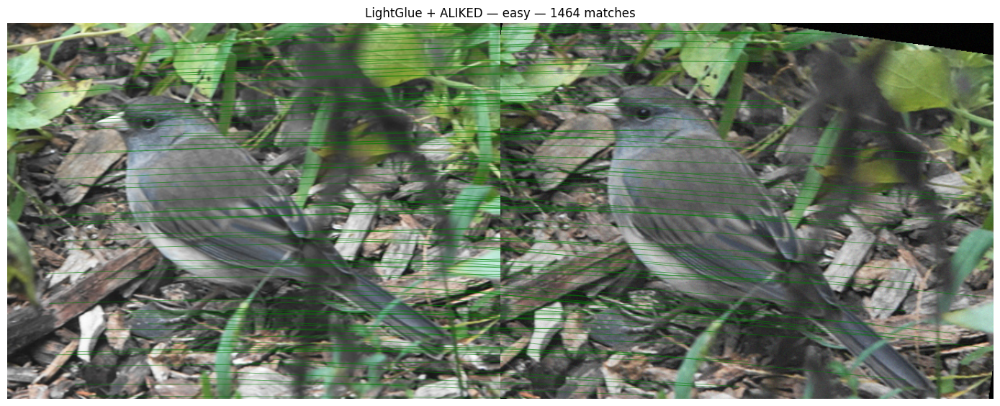

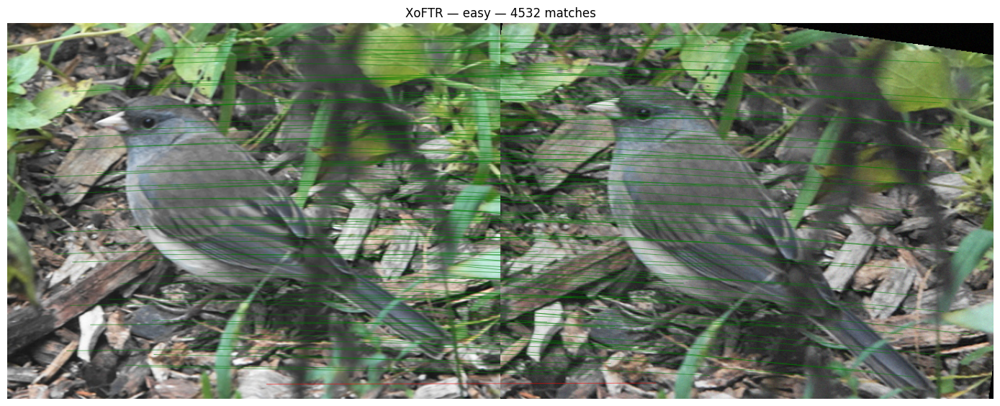

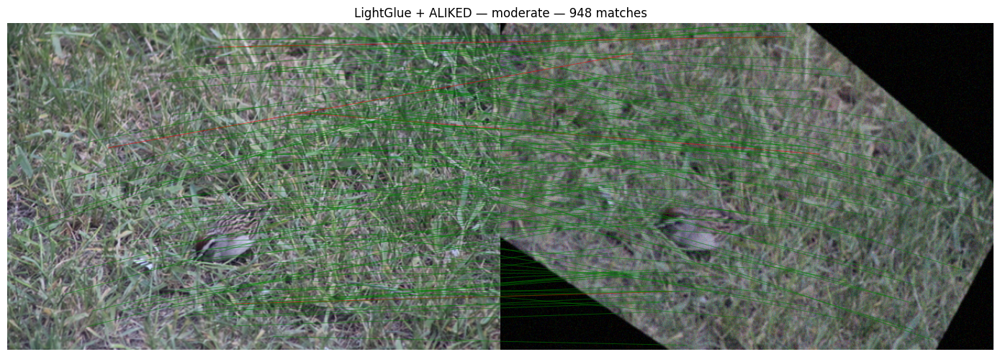

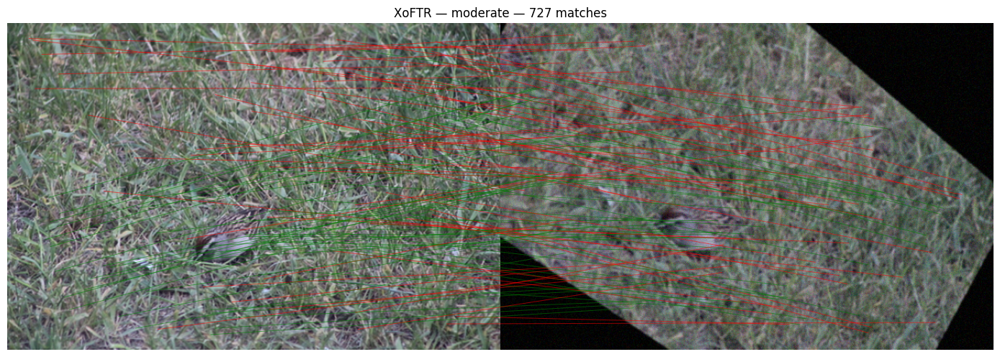

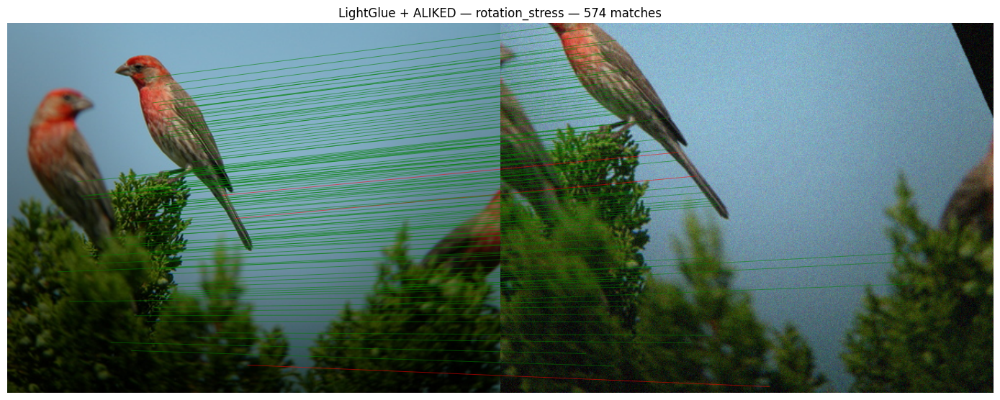

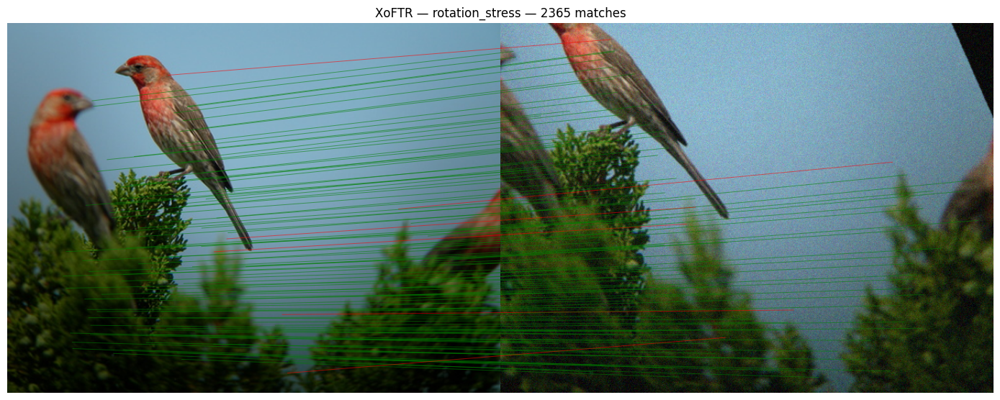

Discordant pair test-011 (rotation_stress): only LightGlue + ALIKED gave a homography within 3 px.


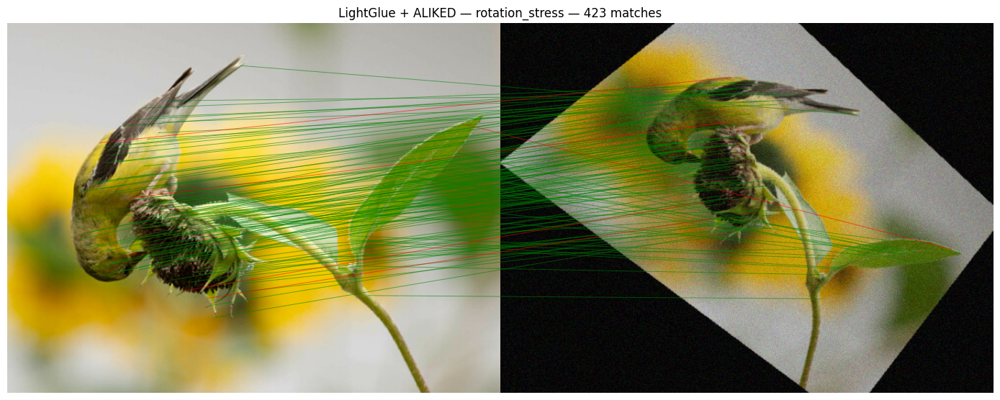

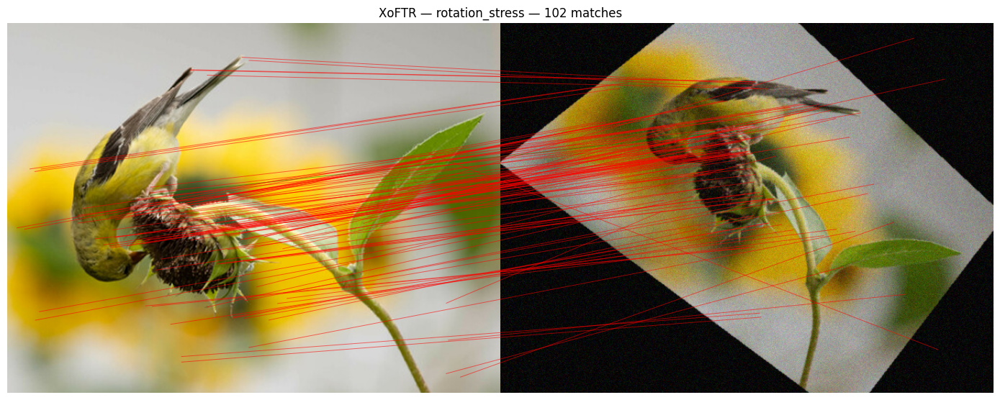

Discordant pair test-019 (moderate): only XoFTR gave a homography within 3 px.


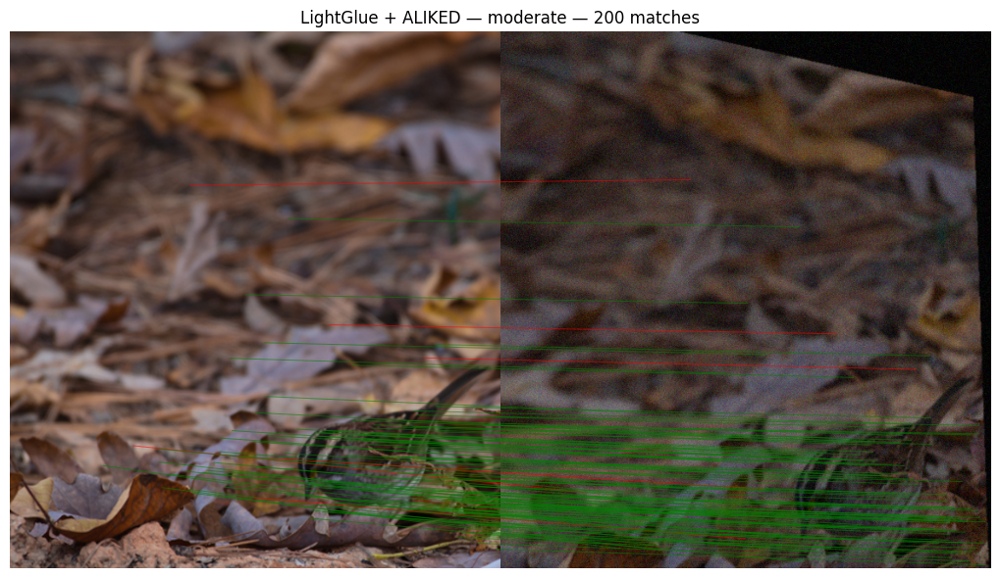

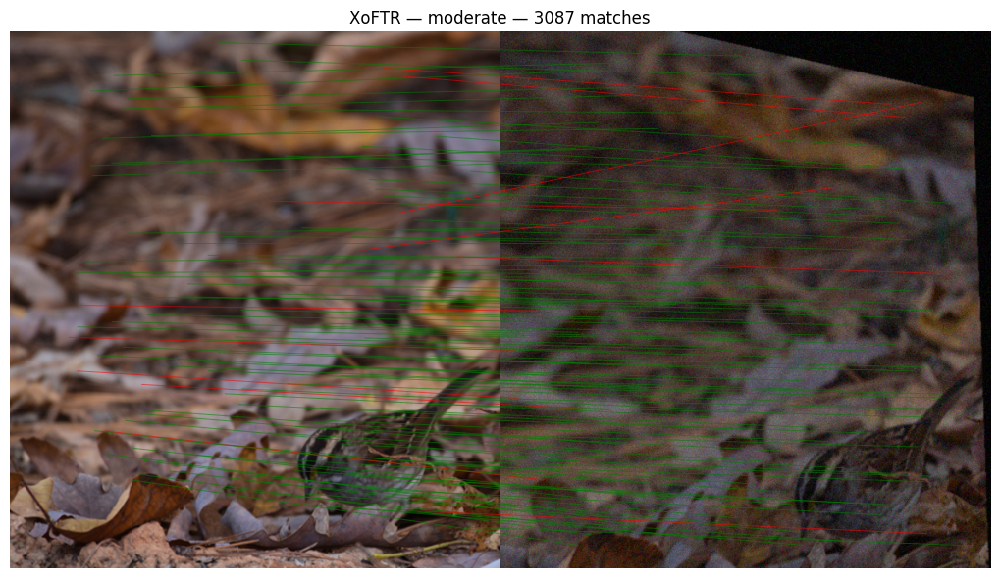

In [ ]:
# @title Visualize first test pair from each tier for both models, then discordant pairs
def draw_matches(row,key,max_lines=120):
    match=load_model_match(OUTPUT_ROOT/"test"/"matches"/key,row["pair_id"]);k0=np.asarray(match["kpts0"]);k1=np.asarray(match["kpts1"]);errors=reprojection_errors(k0,k1,np.asarray(row["homography"]))
    with Image.open(row["image0"]) as a, Image.open(row["image1"]) as b:
        a=a.convert("RGB");b=b.convert("RGB");canvas=Image.new("RGB",(a.width+b.width,max(a.height,b.height)));canvas.paste(a,(0,0));canvas.paste(b,(a.width,0))
    fig,ax=plt.subplots(figsize=(14,6));ax.imshow(canvas)
    if len(k0):
        idx=np.linspace(0,len(k0)-1,min(max_lines,len(k0))).astype(int)
        for i in idx:
            ax.plot([k0[i,0],a.width+k1[i,0]],[k0[i,1],k1[i,1]],linewidth=.7,alpha=.55,color="green" if errors[i]<3 else "red")
    ax.set_title(f"{MODEL_SPECS[key]['display_name']} — {row['tier']} — {len(k0)} matches");ax.axis("off");plt.tight_layout();return fig
for tier in TIERS:
    row=next((r for r in test_pair_rows if r["tier"]==tier),None)
    if row is None:
        print(f"No test pair in tier {tier!r} in this run; its correspondence plot is skipped.")
        continue
    for key in MODEL_KEYS:
        fig=draw_matches(row,key);fig.savefig(OUTPUT_ROOT/"figures"/f"{tier}_{key}_matches.png",dpi=150,bbox_inches="tight");plt.show()
# The disagreements of section 16: one pair where only LightGlue + ALIKED, and one where only XoFTR, gave a homography within 3 px.
discordant_rows=[r for r in compare.to_dict("records") if bool(r["lightglue_h_success"])!=bool(r["xoftr_h_success"])]
pair_by_id={r["pair_id"]:r for r in test_pair_rows}
if not discordant_rows: print("No discordant test pair (one matcher's homography within 3 px and the other's not), so no extra plot.")
for chosen in [next((r for r in discordant_rows if r[flag]),None) for flag in ("lightglue_h_success","xoftr_h_success")]:
    if chosen is None: continue
    winner="LightGlue + ALIKED" if chosen["lightglue_h_success"] else "XoFTR"
    print(f"Discordant pair {chosen['pair_id']} ({chosen['tier']}): only {winner} gave a homography within 3 px.")
    for key in MODEL_KEYS:
        fig=draw_matches(pair_by_id[chosen["pair_id"]],key);fig.savefig(OUTPUT_ROOT/"figures"/f"discordant_{chosen['pair_id']}_{key}_matches.png",dpi=150,bbox_inches="tight");plt.show()

## 18. Match density and runtime

Compute cost is part of the central question. The scatter plot puts each test pair at its match count (x) and precision@3px (y), one colour per matcher. The runtime table separates `load_seconds` (checkpoint verification and model construction) from `inference_seconds` (for all test pairs: image loading, matching, result checks and writing the compressed match files, which grows with match density), and reports the accelerator and peak GPU memory; geometric evaluation runs in the notebook and is not included. These are single runs without a warm-up pass. The last table lists, per checkpoint, whether the file the backend used was located and matched the DIMER pin (full detail is in `provenance/experiment_manifest.json`).

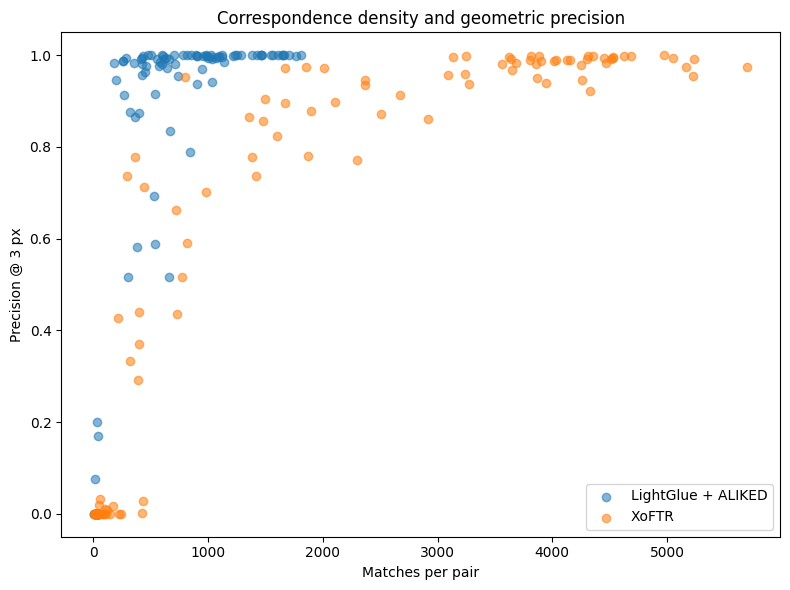

,model,execution_backend,device,accelerator,load_seconds,inference_seconds,seconds_per_pair,raw_matches_per_pair,peak_vram_MiB
0,LightGlue + ALIKED,vismatch,cuda,Tesla T4,1.208839,15.917097,0.165803,726.65625,1669.412109
1,XoFTR,vismatch,cuda,Tesla T4,2.986299,28.147237,0.293200,2225.15625,2969.676270


Checkpoint parity observations (full detail in provenance/experiment_manifest.json):


,model,asset,status,matches_dimer_pin
0,LightGlue + ALIKED,aliked_lightglue.pth,located,True
1,LightGlue + ALIKED,aliked-n16.pth,located,True
2,LightGlue + ALIKED,aliked_lightglue.safetensors,not-located,None
3,LightGlue + ALIKED,aliked-n16.safetensors,not-located,None
4,XoFTR,xoftr_640.safetensors,located,True


In [ ]:
# @title Density versus precision and runtime table
fig,ax=plt.subplots(figsize=(8,6))
for key in MODEL_KEYS:
    x=compare["lightglue_matches"].to_numpy() if key=="lightglue" else compare["xoftr_matches"].to_numpy();y=compare["lightglue_precision_3px"].to_numpy() if key=="lightglue" else compare["xoftr_precision_3px"].to_numpy();ax.scatter(x,y,alpha=.55,label=MODEL_SPECS[key]["display_name"])
ax.set_xlabel("Matches per pair");ax.set_ylabel("Precision @ 3 px");ax.set_title("Correspondence density and geometric precision");ax.legend();plt.tight_layout();plt.savefig(OUTPUT_ROOT/"figures"/"density_vs_precision.png",dpi=150,bbox_inches="tight");plt.show()
runtime_table=pd.DataFrame([{"model":MODEL_SPECS[k]["display_name"],"execution_backend":test_runtime[k]["execution_backend"],"device":test_runtime[k]["device"],"accelerator":test_runtime[k].get("accelerator"),"load_seconds":test_runtime[k]["load_seconds"],"inference_seconds":test_runtime[k]["inference_seconds"],"seconds_per_pair":test_runtime[k]["seconds_per_pair"],"raw_matches_per_pair":test_runtime[k]["matches_per_pair_raw"],"peak_vram_MiB":test_runtime[k]["peak_cuda_bytes"]/2**20 if test_runtime[k]["peak_cuda_bytes"] is not None else None} for k in MODEL_KEYS]);display(runtime_table);runtime_table.to_csv(OUTPUT_ROOT/"test"/"runtime.csv",index=False)
parity_rows=[]
for key in MODEL_KEYS:
    for asset,obs in test_runtime[key]["dimer_asset_parity_observations"].items():
        candidates=obs.get("candidates",[])
        parity_rows.append({"model":MODEL_SPECS[key]["display_name"],"asset":asset,"status":obs.get("status"),
                            "matches_dimer_pin":any(c.get("matches_dimer_pin") for c in candidates) if candidates else None})
print("Checkpoint parity observations (full detail in provenance/experiment_manifest.json):")
display(pd.DataFrame(parity_rows))

> **What to notice.** In the scatter plot, does one matcher sit to the right (more matches) but lower (less precise)? In the runtime table, compare `seconds_per_pair` and `peak_vram_MiB`: a denser matcher usually costs more. Times depend on the GPU (the `accelerator` column) and include image loading and writing the match files, which grows with density; they are single runs without a warm-up, so treat small differences as noise, and compare the two matchers on the same run rather than with numbers from another runtime. The baselines' `seconds` include scoring and are measured differently, so do not set them against the matchers' times. In the parity table, `not-located` for an unused `.safetensors` variant is expected; a checkpoint the backend actually used should show `matches_dimer_pin = True`.

## 19. New-pair inference without ground truth

The next pair has no independent reference homography, so correspondence counts are valid inference output but geometric precision is **not measurable**.

In [ ]:
# @title Draw an unlabelled pair and run both matchers
from PIL import ImageDraw
future_dir=OUTPUT_ROOT/"future";future_dir.mkdir(parents=True,exist_ok=True)
a=Image.new("RGB",(640,480),"white");d=ImageDraw.Draw(a);d.rectangle((80,80,260,260),outline="black",width=8);d.ellipse((350,120,520,290),outline="black",width=8);d.line((100,400,540,350),fill="black",width=10)
b=Image.new("RGB",(640,480),"white");d=ImageDraw.Draw(b);d.rectangle((120,105,300,285),outline="black",width=8);d.ellipse((385,145,555,315),outline="black",width=8);d.line((140,425,580,375),fill="black",width=10)
p0=future_dir/"drawn_0.png";p1=future_dir/"drawn_1.png";a.save(p0);b.save(p1)
unlabelled=[{"pair_id":"drawn-unlabelled","image0":str(p0.resolve()),"image1":str(p1.resolve())}];manifest=future_dir/"unlabelled_pairs.json";manifest.write_text(json.dumps(unlabelled,indent=2),encoding="utf-8")
for key in MODEL_KEYS:
    out=future_dir/key;out.mkdir(exist_ok=True);meta=future_dir/f"{key}_runtime.json";run_checked([ENV_PYTHON,runner_path,"--model",key,"--pairs",manifest,"--out-dir",out,"--metadata",meta],f"{key} unlabelled-pair matching");match=load_model_match(out,"drawn-unlabelled");print(MODEL_SPECS[key]["display_name"],"matches:",len(match["kpts0"]))
print("Evaluation status: not-measurable — no independent reference geometry.")

LightGlue + ALIKED matches: 226


XoFTR matches: 880
Evaluation status: not-measurable — no independent reference geometry.


## 20. BYOD

First-release BYOD accepts a directory or ZIP of photographs and creates deterministic synthetic homography pairs locally. This keeps the evaluation measurable without inventing real-pair ground truth.

User-supplied imagery remains inside the selected notebook runtime and is not sent to a DIMER worker/API. A hosted notebook remains an external compute environment; do not upload confidential, biometric, surveillance, restricted, regulated, security-sensitive, or proprietary imagery unless authorized.

To use it, set `USE_BYOD=True` and `BYOD_PATH` (a folder or a `.zip`) in section 1, or in Colab leave `BYOD_PATH` empty to get an upload dialog for one `.zip`, then **Run all**. You can do this in the same runtime after the default run: the matcher environment and the verified checkpoints are reused. Supply 4–360 JPEG/PNG photographs, 16–4096 pixels per side; duplicate decoded images are rejected even when their file bytes differ. Nothing is trained, so there is no development split: every accepted photograph yields one pair, about 40% in validation and 60% in test. Pair tiers are assigned in turn (easy, moderate, rotation_stress) within each split, so with fewer than 7 photos some tiers have no validation or test pair: their rows show `n = 0` with empty metrics, their figures are skipped, and section 14 warns when a tier has no test pair. A handful of test pairs makes every rate move in large steps; treat a small BYOD run as a demonstration, not a comparison. If any file breaks a rule, one message lists every refused file and its rule, and nothing is written under `outputs/byod/`.

The BYOD split is a random split by photo, which assumes your photographs are independent of each other. Near-duplicates (burst shots, crops of one scene) are not detected and can land in both validation and test; nothing is trained here, so this only makes the test less independent. The same split → synthetic pair generation → validation → freeze → held-out model inference → geometric evaluation → report export runs for BYOD. Every BYOD run gets an isolated `OUTPUT_DIR/byod/run-*` output folder (and its own work folder) and its own report ZIP next to that folder; the canonical report ZIP leaves the `byod/` folder out, so your photographs' pairs, matches and figures never enter it. ZIP extraction uses a unique directory and rejects duplicate members, traversal and symlinks. BYOD establishes synthetic-warp behavior on supplied photographs, not accuracy on genuine scene pairs.


## 21. Why this notebook does not adapt either model

There is no adaptation step to run here: the canonical comparison is frozen-model inference. The existing DIMER E2E tutorials expose materially different adaptation contracts: LightGlue trains final matcher layers + assignment head while ALIKED remains frozen; XoFTR trains final coarse layers + projection while the backbone/fine stage remain frozen. Those adapted results should stay separate from this common frozen comparison.

## 22. Interpretation and limitations

- Synthetic homographies provide exact reference geometry but do not reproduce parallax, non-planar depth, occlusion/disocclusion, or independent object motion.
- ±150° rotation is a deliberate stress tier, not an assumption about normal workloads.
- Match scores are not calibrated probabilities and are not comparable across model families on a common probability scale.
- High precision can still fail geometric estimation if correspondences are too few, clustered, or nearly collinear.
- Both systems may return plausible-looking correspondences on unrelated/weak-overlap image pairs; downstream geometric verification remains necessary.
- **Two configured systems, not two families.** Each family is represented by one model, compared as a whole pipeline at the `vismatch 1.3.2` default settings (section 12) and not tuned for this task. XoFTR was designed for visible–thermal-infrared matching (arXiv 2404.09692) and is used here on visible-light pairs only. A gap between the two columns is a gap between these two configured pipelines under this protocol; it is not evidence about sparse versus detector-free matching in general.
- This **candidate** executes both methods through `vismatch==1.3.2`; exact DIMER checkpoint parity must be demonstrated during release qualification before claiming execution parity with the live DIMER profiles.

## 23. Exercises

1. **Density:** Which of the two configured matchers returned more correspondences, and which of its settings or design choices could explain that?
2. **Precision vs density:** Is 40 matches at 99% precision better than 2,000 matches at 95%? What downstream task changes the answer?
3. **Rotation:** Which matcher degrades more under ±150° rotation stress? Use measured data rather than architecture assumptions.
4. **Homography:** Why can high match precision still yield a bad homography?
5. **Transfer:** How might this experiment change for drone frames, satellite registration, thermal/visible pairs, or historical photographs?

<details>
<summary><b>Guidance for the exercises (read after answering)</b></summary>

1. Check `matches_per_pair` in section 14 against the backend settings printed in section 12. XoFTR, as configured here, scores a dense coarse grid and keeps every match above its coarse and fine thresholds; LightGlue + ALIKED can match at most `max_num_keypoints` detected keypoints per image and drops matches below its filter threshold. The gap you measured belongs to these two configured systems: a different detector-free model, a higher keypoint cap or other thresholds could narrow or reverse it, so it does not tell you how the two families compare in general.
2. It depends on the task and on the numbers. 2,000 matches at 95% contain about 1,900 correct ones, far more than 40 at 99%, and may cover the image better; 40 precise matches can still be enough for a homography if they are well spread. Dense 3-D reconstruction or flow benefits from density. Check `inliers_per_pair`, `precision_3px` and `homography_acc_3px` together in your run before deciding.
3. Use the `rotation_stress` rows of the section 15 table and the per-tier test table; the answer is whatever your run measured.
4. RANSAC needs enough correct matches spread across the image; a few precise matches clustered in one corner or along a line give an unstable homography. Look for pairs with high `precision_3px` but `h_success = False` in section 16.
5. Real pairs add parallax, occlusion and appearance change that a planar synthetic warp cannot show, and many lack an exact reference homography, so accuracy may become not-measurable as in section 19.

</details>

## 24. Export provenance and report bundle

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Final provenance
import datetime, shutil
experiment_manifest={
 "notebook_spec":"2.5","notebook_profile":"TASK-INFERENCE","notebook_mode":"WORKSHOP","workshop_revision":"0.1.0-candidate","timestamp_utc":datetime.datetime.now(datetime.timezone.utc).isoformat(),
 "dataset_source":dataset_source,"corpus_manifest":photo_manifest_out,
 "pair_generator":{"version":"dimer-comparative-homography-v1","working_long_side":WORKING_LONG_SIDE,"tiers":TIER_PARAMS,"split_seed":SPLIT_SEED,"validation_pairs":len(validation_pair_rows),"test_pairs":len(test_pair_rows),"validation_digest":pairs_digest(validation_pair_rows),"test_digest":pairs_digest(test_pair_rows)},
 "models":MODEL_SPECS,
 "execution_backend":{"package":"vismatch==1.3.2","environment":{"python":MODEL_ENV_PYTHON,"uv":UV_VERSION,"lock_sha256":MATCH_ENV_LOCK_SHA256,"versions":ENV_VERSIONS},"runner_sha256":hashlib.sha256(MATCH_RUNNER.encode()).hexdigest(),"runtime":test_runtime,"dimer_checkpoint_parity_status":"qualification-required","backend_settings":backend_settings},
 "evaluation":{"precision_thresholds_px":list(THRESHOLDS),"inlier_threshold_px":INLIER_PX,"ransac_threshold_px":RANSAC_INLIER_PX,"ransac_iterations":RANSAC_ITERATIONS,"ransac_seed":RANSAC_SEED,"aggregate":aggregate_table.to_dict("records"),"per_tier":tier_table.to_dict("records")},
 "standalone_contract":{"repository_clone_required":False,"dimer_source_runtime_fetch_required":False,"external_dimer_worker_required":False,"credentials_required":False,"default_upload_required":False},
 "undefined_metric_policy":"Nonfinite metrics are exported as null: no measurable homography/inlier statistic; never interpreted as zero error.",
 "evidence_scope":("Synthetic homography evaluation on user-supplied photographs" if USE_BYOD else "Synthetic homography evaluation on a pinned tutorial corpus")+"; sample-sanity evidence, not benchmark evidence."
}
(OUTPUT_ROOT/"provenance"/"experiment_manifest.json").write_text(strict_json_dumps(experiment_manifest,indent=2,default=str),encoding="utf-8")
(OUTPUT_ROOT/"workshop_summary.json").write_text(strict_json_dumps({"models":[MODEL_SPECS[k]["display_name"] for k in MODEL_KEYS],"validation_pairs":len(validation_pair_rows),"test_pairs":len(test_pair_rows),"aggregate_metrics":aggregate_table.to_dict("records"),"per_tier_metrics":tier_table.to_dict("records")},indent=2,default=str),encoding="utf-8")
def write_report_bundle(root,target,exclude_top=()):
    """Zip one run's output folder; the canonical bundle leaves earlier BYOD runs (byod/) out."""
    root=Path(root).resolve()
    with zipfile.ZipFile(target,"w",zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(root.rglob("*")):
            rel=path.relative_to(root)
            if rel.parts[0] in exclude_top: continue
            archive.write(path,rel.as_posix())
    return str(target)
excluded=() if USE_BYOD else ("byod",)
bundle=write_report_bundle(OUTPUT_DIR,str(Path(OUTPUT_DIR).resolve())+"_DIMER_Image_Matching_Workshop_Report.zip",excluded)
if excluded and (Path(OUTPUT_DIR)/"byod").exists():
    print("Earlier BYOD runs under", Path(OUTPUT_DIR)/"byod", "were left out of this canonical report; each has its own report ZIP.")
print({"report_bundle":bundle,"sha256":sha256_file(bundle)})

{'report_bundle': '/content/outputs_DIMER_Image_Matching_Workshop_Report.zip', 'sha256': '04840a3ae925c171e4933c84f2d3e063a65f51c5893562fe6adaed8b7b9f4e3a'}


## Try it yourself — one controlled change

**Predict → change one variable → run → observe → explain.** The one variable is the correctness tolerance: how close to the reference a match must be to count as correct (3 px in every table so far).

1. **Predict.** When the tolerance tightens from 3 px to `ACTIVITY_STRICT_TOLERANCE_PX` (1 px by default), which matcher keeps the larger *share* of its correct matches, and is the answer the same on every tier? Write your prediction down, with a reason.
2. **Change.** Either tick `RUN_TOLERANCE_ACTIVITY` in section 1 before **Run all**, or, after a completed run, type `RUN_TOLERANCE_ACTIVITY = True` in a new code cell (add `ACTIVITY_STRICT_TOLERANCE_PX = 0.5` there to try another tolerance between 0 and 3 px), run it, then run the next cell. Do not re-run section 1 for this after a BYOD run: that starts a new BYOD run, and this cell would no longer find your saved matches.
3. **Observe.** The table shows, per matcher and tier, precision at 3 px, precision at the strict tolerance, `macro_precision_ratio` (precision at the strict tolerance ÷ precision at 3 px, each first averaged over pairs) and `pooled_retained_fraction` (of all matches within 3 px in that tier, the share that is also within the strict tolerance; pairs with many matches weigh more). The second is the direct answer to the prediction.
4. **Explain.** Connect what you see to the `median_error_px` column of the validation table.

The cell re-scores the saved **validation** correspondences only. It loads no model and writes no files, and the frozen settings and test results are unchanged.


In [ ]:
# @title Try it yourself: tighten the correctness tolerance (optional)
if not RUN_TOLERANCE_ACTIVITY:
    print("Activity not run: switch RUN_TOLERANCE_ACTIVITY on as described above, then run this cell. It loads no model and writes no files.")
else:
    if not 0 < float(ACTIVITY_STRICT_TOLERANCE_PX) < 3:
        raise ValueError(f"ACTIVITY_STRICT_TOLERANCE_PX must be greater than 0 and smaller than 3 px; got {ACTIVITY_STRICT_TOLERANCE_PX}")
    if not all((OUTPUT_ROOT/"validation"/"matches"/key).is_dir() for key in MODEL_KEYS):
        raise RuntimeError(f"No saved validation matches under {OUTPUT_ROOT/'validation'/'matches'}: complete a Run all first, and do not re-run section 1 before this cell.")
    activity_tolerances=(3.0,float(ACTIVITY_STRICT_TOLERANCE_PX))
    activity_rows=[]
    for key in MODEL_KEYS:
        matches_root=OUTPUT_ROOT/"validation"/"matches"/key
        for tier in TIERS:
            tier_rows_=[r for r in validation_pair_rows if r["tier"]==tier]
            if not tier_rows_: continue
            errors=[]
            for r in tier_rows_:
                saved=load_model_match(matches_root,r["pair_id"])
                errors.append(reprojection_errors(saved["kpts0"],saved["kpts1"],np.asarray(r["homography"])))
            row={"model":MODEL_SPECS[key]["display_name"],"tier":tier,"pairs":len(tier_rows_)}
            for tol in activity_tolerances:
                row[f"precision_{tol:g}px"]=float(np.mean([float((e<tol).mean()) if len(e) else 0. for e in errors]))
            strict=row[f"precision_{activity_tolerances[1]:g}px"]; loose=row["precision_3px"]
            row["macro_precision_ratio"]=strict/loose if loose>0 else math.nan
            correct_3px=sum(int((e<3.0).sum()) for e in errors); correct_strict=sum(int((e<activity_tolerances[1]).sum()) for e in errors)
            row["pooled_retained_fraction"]=correct_strict/correct_3px if correct_3px else math.nan
            activity_rows.append(row)
    print(f"Validation precision at 3 px and at {activity_tolerances[1]:g} px (saved correspondences re-scored; nothing written):")
    print(pd.DataFrame(activity_rows).to_string(index=False))

Activity not run: switch RUN_TOLERANCE_ACTIVITY on as described above, then run this cell. It loads no model and writes no files.


<details>
<summary><b>Sample interpretation (read after you have run and explained)</b></summary>

Precision can only stay the same or fall when the tolerance tightens, so compare the retained shares, not the raw drop. `pooled_retained_fraction` answers "of this matcher's matches within 3 px, how many are also within the strict tolerance"; `macro_precision_ratio` divides two averages over pairs and can differ from it when pairs have very different match counts. If one matcher keeps a clearly larger share in your run, its correct matches are localised more tightly on these pairs. `median_error_px` in the validation table points at the same property but is computed differently (the median over all within-3-px matches pooled across pairs), so do not expect the numbers to correspond exactly. If the ordering changes between tiers, harder warps may be degrading localisation, but each tier also holds different photographs and a different set of surviving matches, so treat it as a lead to check rather than a conclusion. With 16 validation pairs per tier on the built-in corpus (fewer for BYOD), small differences are not meaningful.

</details>

## Self-paced checkpoint

Before reading the sample interpretation, answer in your own words:

1. What was the model or system asked to do?
2. Which baseline/reference tells you whether the model added useful capability?
3. What is the most important failure mode or tradeoff visible in this notebook?
4. What would you need to test before applying the result to a different dataset or operational setting?

<details>
<summary><b>Show a sample interpretation</b></summary>

1. **Task.** Return point correspondences between two images of the same scene; here every pair is a known synthetic warp of one photograph, so each correspondence and each fitted homography can be scored exactly (sections 6–8).
2. **Reference.** The identity guess is the floor and the patch-neighbour search is the simple reference (section 9; per tier in sections 12 and 14). Say on which measures the learned matchers beat it in your run (homography accuracy, precision, correct-match count or cost) and on which they do not; which measure matters depends on the task.
3. **Failure mode or tradeoff.** Use your own tables: for each matcher, find the tier where homography accuracy is lowest (per-tier test table, section 15), and check whether the denser matcher is also the less precise one (section 18 scatter plot). If your run shows no clear failure tier or tradeoff, say so.
4. **Before applying it elsewhere.** Test on real image pairs with parallax and appearance change (section 22), check both matchers at settings chosen for that task rather than the backend defaults, and remember that one model per family supports no claim about sparse versus detector-free matching in general.

More raw matches do not automatically mean better matching. Give more weight to geometrically consistent correspondences and failure patterns across difficulty tiers than to match count alone.

A complete answer should cite the outputs from **your run**, because small numerical differences can occur across supported runtimes.

</details>


## Write an evidence-based conclusion

Use the outputs from your run rather than declaring a universal winner.

1. **State the question.** What capability or comparison did this notebook test?
2. **Report the primary result.** Compare the relevant model/system with its baseline or reference on the held-out or otherwise designated evaluation data.
3. **Add supporting evidence.** Include the most informative secondary metric, error pattern, qualitative diagnostic, or disagreement.
4. **Account for cost or complexity.** Mention runtime, model footprint, extra stages, or adaptation when they materially affect the comparison.
5. **State the limits.** Say what this dataset, split, model revision, and configuration do—and do not—support.

Compare the selected matchers on held-out geometric quality and runtime, identify at least one pair type where their behavior differs, and avoid generalizing the result beyond these two configured systems (`vismatch 1.3.2` defaults, one model per family), the controlled image corpus and the evaluator: the result does not rank sparse against detector-free matching in general.


## Glossary

| Term | Meaning |
|---|---|
| Keypoint | Distinctive image coordinate used by sparse feature methods |
| Descriptor | Vector describing local image appearance |
| Correspondence | Matched coordinates across two images |
| Sparse matcher | Matches detected local features, e.g. ALIKED + LightGlue |
| Detector-free matcher | Predicts matches from image feature grids without a separate detector |
| Homography | 3×3 projective mapping between planar image coordinates |
| Reprojection error | Pixel distance from a predicted correspondence to the exact reference warp |
| Inlier | Match within the chosen geometric threshold |
| RANSAC | Robust estimator using repeated minimal correspondence samples |
| DLT | Direct Linear Transform homography estimator |
| Precision@3px | Fraction of returned matches within 3 px of reference geometry |
| Homography accuracy@3px | Fraction of pairs whose RANSAC-DLT homography puts the image corners within 3 px of the reference on average |
| Mean corner error | Average distance between the four image corners mapped by the estimated and by the reference homography |
| Match density | Number of correspondences returned per pair |
| Sample-sanity evidence | Bounded tutorial measurement, not a benchmark claim |

In [ ]:
# @title Run-all completion summary
completion={"notebook_spec":"2.5","profile":"TASK-INFERENCE","mode":"WORKSHOP","models":[MODEL_SPECS[k]["display_name"] for k in MODEL_KEYS],"execution_backend":"vismatch==1.3.2","dataset_source":dataset_source,"photos":len(photo_records),"validation_pairs":len(validation_pair_rows),"test_pairs":len(test_pair_rows),"tiers":list(TIERS),"output_directory":str(OUTPUT_ROOT.resolve()),"dimer_checkpoint_parity":"qualification-required"}
display(pd.Series(completion,name="value").to_frame())
print("Canonical comparative workflow complete. Release still requires clean-runtime execution and exact DIMER asset-parity qualification.")

,value
notebook_spec,2.5
profile,TASK-INFERENCE
mode,WORKSHOP
models,"[LightGlue + ALIKED, XoFTR]"
execution_backend,vismatch==1.3.2
dataset_source,pinned iNaturalist CC0 matching corpus
photos,360
validation_pairs,48
test_pairs,96
tiers,"[easy, moderate, rotation_stress]"


Canonical comparative workflow complete. Release still requires clean-runtime execution and exact DIMER asset-parity qualification.


## Troubleshooting

| Symptom | Likely cause | Corrective action |
|---|---|---|
| Photo digest mismatch | changed/interrupted source object | delete the cached file and retry; never bypass the pin |
| Kernel Python is older than 3.10 | unsupported notebook kernel | use a current hosted runtime; the matcher environment uses Python 3.12 regardless |
| Environment creation fails in section 10 | the kernel is not Linux x86_64, the pinned `uv` wheel or CPython 3.12.12 could not be downloaded, or a downloaded wheel did not match its SHA-256 in the lock | use Colab, Kaggle or a Linux x86_64 Jupyter server and check network access, then rerun section 10; the error shows the tail of the installer output; never remove the hash check |
| A matching step fails with a `RuntimeError` naming the step | the matcher process exited with an error | read the stderr tail in the message; it is the matcher's own error |
| CUDA unavailable | CPU runtime selected | use T4 or equivalent for practical execution |
| Matcher returns zero matches | severe warp, low texture, or model failure mode | treat it as a real zero-match observation |
| Rotation-stress result collapses | model is not robust to that regime | interpret it as measured stress behaviour |
| Patch baseline is slow | CPU NCC is intentionally simple | keep it for qualified release evidence; disable only during exploratory edits |
| BYOD ZIP refused | unsafe path, symlink, or size | correct the archive rather than bypassing validation |
| A BYOD photo is refused | one message lists every refused file with its rule (count, size, unreadable, duplicate pixels, not a ZIP) and no traceback; a refused input writes nothing under `outputs/byod/` | fix or remove every listed file and run again from section 1 (Run all); tables further down are from the earlier run until then |
| BYOD tables show `n = 0` for a tier | fewer than 7 photos, so that tier has no validation or test pair | add photographs; the other tiers are still valid |
| Package/version or stale-module error after installation | the kernel imported incompatible libraries before the run | start a fresh runtime and choose **Run all** before importing extra packages |
| Out-of-memory or session restart | the GPU or RAM is too small for the matcher | use a T4 or larger; each matcher runs in its own process, one at a time |
| Your numbers differ slightly from a recorded run | GPU kernels and library builds introduce small numerical differences | compare the pattern, metric definitions, split and model revision before treating a difference as meaningful |
| RANSAC homography fails | fewer than four usable matches / degenerate geometry | count the pair as geometric-estimation failure |
| DIMER parity remains qualification-required | backend asset parity not proven | verify exact model asset identities during release qualification |